# MD6329 final experiment notebook

**Research question.** Can higher resolution and acquisition-style consistency training improve external pneumonia classification and make spatial evidence align better with annotated opacity regions?

**Experiment flow.** B28 reproduction → RRR and CutMix trials → B64 resolution ablation → Aug1 / CE3 / AC-JSD comparison → RSNA classification and explanation tests → source-only $\lambda$ selection → CheXpert evaluation.

**Main conclusion.** Native 64-pixel input gives the largest accuracy gain. Augmentation and JSD improve external ranking and robustness. AC-JSD improves average Grad-CAM box energy over plain training, while Aug1 gives the strongest absolute box alignment. On CheXpert, AC-JSD reaches 83.92% accuracy and 0.9310 AUROC, compared with 62.24% and 0.7212 for plain training.

All original code cells are retained below in execution order. Expensive stages are controlled by the `RUN_*` switches in the first code cell.

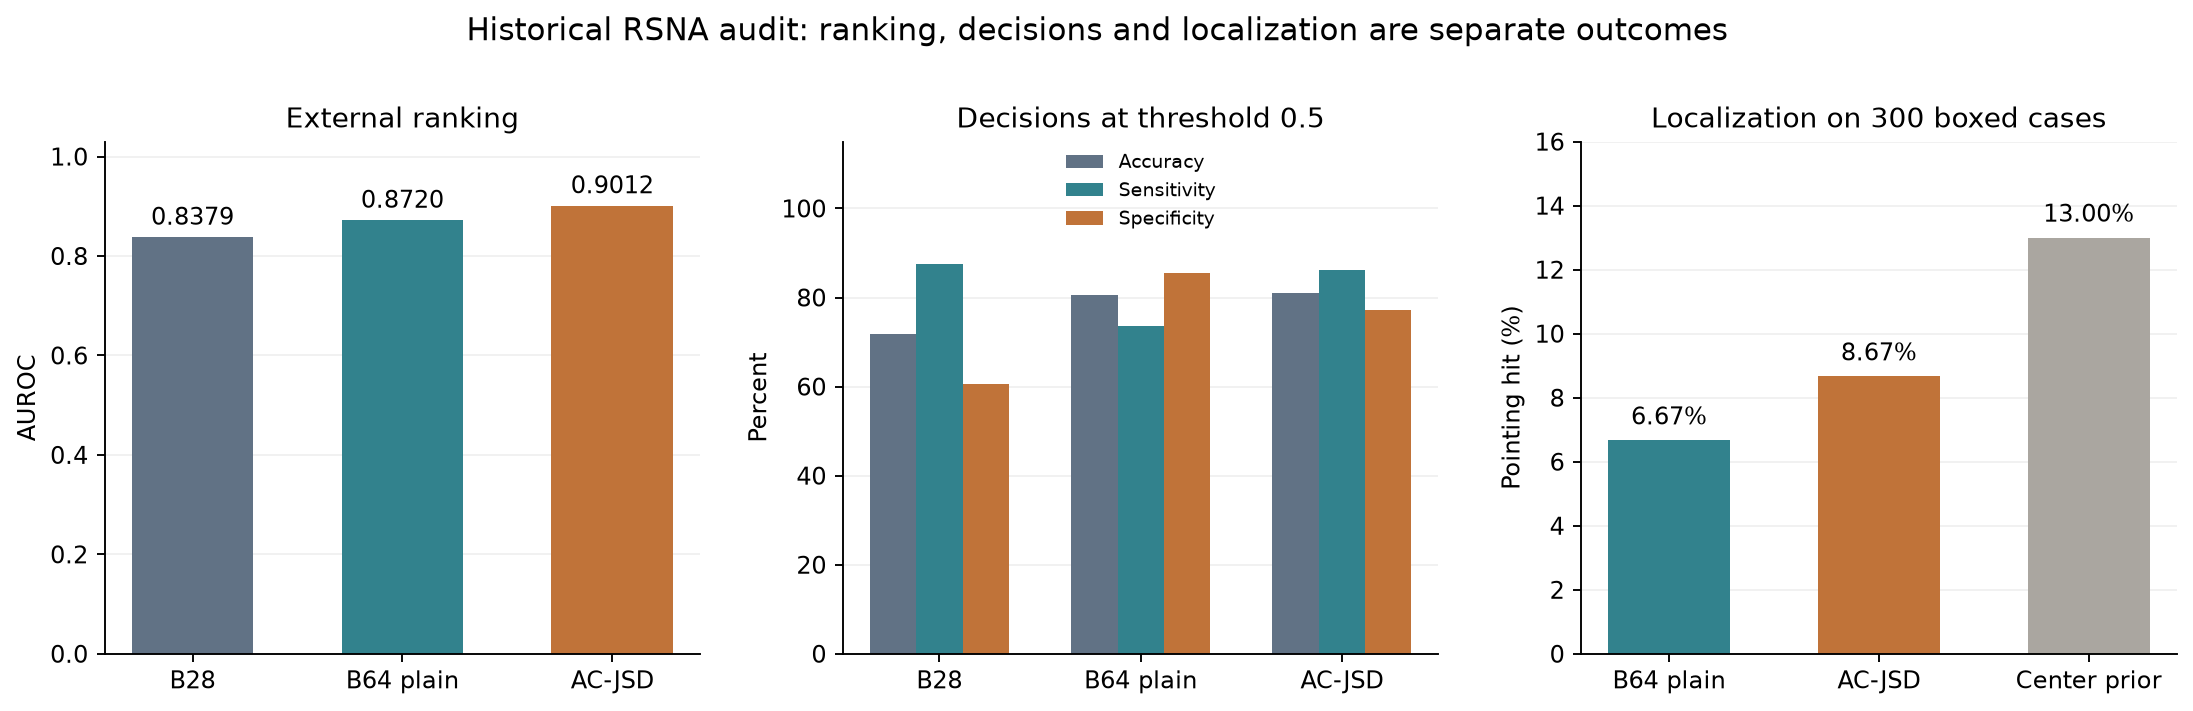

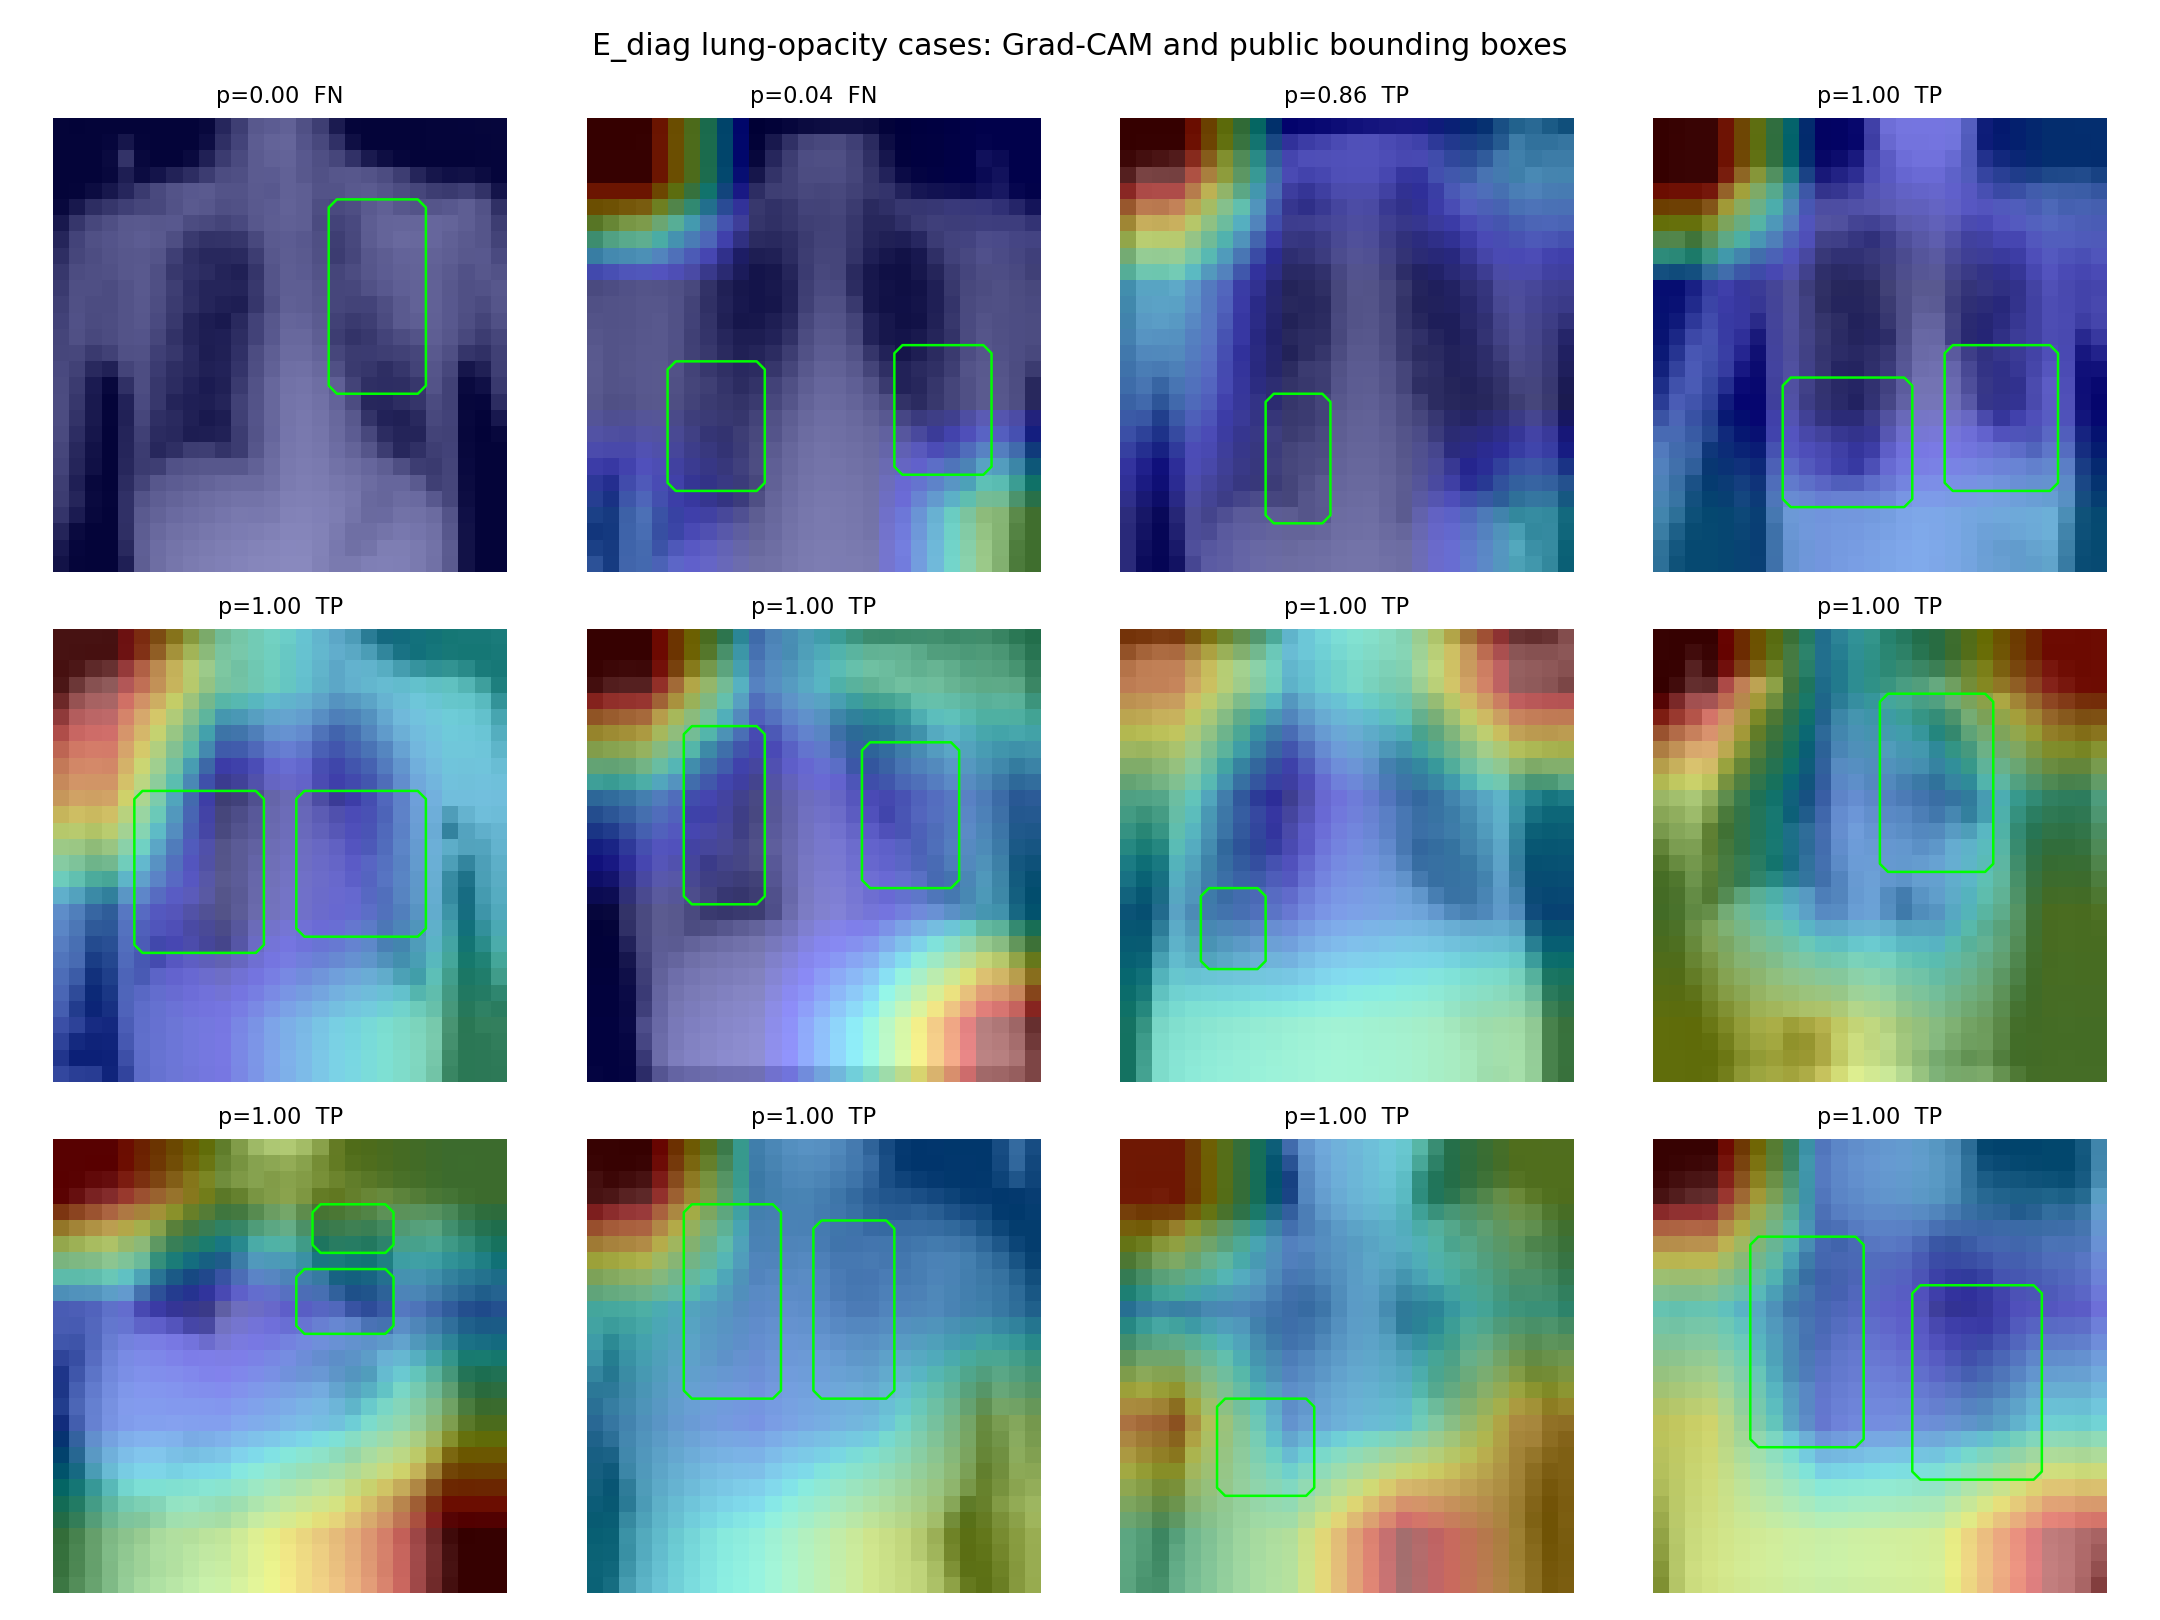

## 1. Setup and complete source modules

In [1]:
from pathlib import Path
import hashlib, importlib.util, json, platform, sys

PROJECT_ROOT = Path('/content/md6329_project')
SRC = PROJECT_ROOT / 'src'
SRC.mkdir(parents=True, exist_ok=True)
SEED = 632901

RUN_BASELINE_TRAINING = False
RUN_E_DIAG = False
RUN_RRR_SOURCE = False
RUN_RRR_E_FINAL = False
RUN_CUTMIX_SOURCE = False
RUN_CUTMIX_E_FINAL = False
RUN_B64_PLAIN = False
RUN_B64_AUGMIX = False
RUN_STEP15_INTERNAL_TEST = False
RUN_STEP16_HISTORICAL_EXTERNAL = False
RUN_STEP17 = False
RUN_STEP18_MATCHED = False
RESTORE_FROZEN_ARTIFACTS = False
ALLOW_REOPEN_E_FINAL = False

if (RUN_RRR_E_FINAL or RUN_CUTMIX_E_FINAL or RUN_STEP16_HISTORICAL_EXTERNAL) and not ALLOW_REOPEN_E_FINAL:
    raise RuntimeError('E_final is locked. Do not reopen it for tuning or selection.')

enabled = [name for name, value in globals().copy().items() if name.startswith('RUN_') and value]
print({'mode': 'audit-only' if not enabled else enabled, 'project_root': str(PROJECT_ROOT)})


{'mode': 'audit-only', 'project_root': '/content/md6329_project'}


In [2]:
# Pinned dependency for RSNA DICOM decoding.
%pip -q install pydicom==2.4.4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pydicom

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print({'python': platform.python_version(), 'torch': torch.__version__,
       'pydicom': pydicom.__version__, 'device': str(DEVICE)})


Note: you may need to restart the kernel to use updated packages.


{'python': '3.10.12', 'torch': '2.11.0+cpu', 'pydicom': '2.4.4', 'device': 'cpu'}


In [3]:
%%writefile /content/md6329_project/src/baseline.py
from __future__ import annotations

import csv
import hashlib
import json
import os
import platform
import random
import sys
import time
import urllib.request
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader, TensorDataset


SEED = 632901
EXPLANATION_SEED = 632902
MEDMNIST_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist.npz?download=1"
MEDMNIST_MD5 = "28209eda62fecd6e6a2d98b1501bb15f"
OFFICIAL_COMMIT = "70b6b3a7ad7afddff1df2a3b735235830fbdb142"
OFFICIAL_REFERENCE = {"auroc": 0.944, "accuracy": 0.854}


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def md5(path: Path) -> str:
    h = hashlib.md5()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def save_csv(path: Path, rows: list[dict]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        raise ValueError("Refusing to save an empty CSV")
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def seed_all(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except TypeError:
        torch.use_deterministic_algorithms(True)


def download(url: str, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and path.stat().st_size > 0:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    urllib.request.urlretrieve(url, temporary)
    temporary.replace(path)
    return path


def obtain_source_data(root: Path) -> Path:
    path = root / "data" / "pneumoniamnist.npz"
    download(MEDMNIST_URL, path)
    actual = md5(path)
    if actual != MEDMNIST_MD5:
        raise RuntimeError(f"PneumoniaMNIST MD5 mismatch: {actual}")
    return path


def load_arrays(path: Path) -> dict[str, np.ndarray]:
    with np.load(path) as z:
        arrays = {key: z[key].copy() for key in z.files}
    expected = {"train": 4708, "val": 524, "test": 624}
    for split, n in expected.items():
        images = arrays[f"{split}_images"]
        labels = arrays[f"{split}_labels"].reshape(-1).astype(np.int64)
        if len(images) != n or len(labels) != n or images.shape[1:3] != (28, 28):
            raise AssertionError((split, images.shape, labels.shape))
        if set(np.unique(labels)) != {0, 1}:
            raise AssertionError((split, np.unique(labels)))
        arrays[f"{split}_labels"] = labels
    return arrays


def normalized_tensor(images: np.ndarray) -> torch.Tensor:
    x = torch.from_numpy(images).float()
    if x.ndim == 3:
        x = x.unsqueeze(1)
    elif x.ndim == 4 and x.shape[-1] == 1:
        x = x.permute(0, 3, 1, 2)
    if x.ndim != 4 or x.shape[1] != 1:
        raise AssertionError(x.shape)
    return (x / 255.0 - 0.5) / 0.5


def loader(images: np.ndarray, labels: np.ndarray, batch_size: int, shuffle: bool, seed: int) -> DataLoader:
    dataset = TensorDataset(normalized_tensor(images), torch.from_numpy(labels).long())
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator if shuffle else None,
    )


def conv3x3(in_planes: int, out_planes: int, stride: int = 1) -> nn.Conv2d:
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = conv3x3(in_planes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes),
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return F.relu(out)


class ResNet(nn.Module):
    def __init__(self, block=BasicBlock, num_blocks=(2, 2, 2, 2), in_channels: int = 1, num_classes: int = 2):
        super().__init__()
        self.in_planes = 64
        self.conv1 = conv3x3(in_channels, 64)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)
        self.linear = nn.Linear(512 * block.expansion, num_classes)

    def _make_layer(self, block, planes: int, num_blocks: int, stride: int) -> nn.Sequential:
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for value in strides:
            layers.append(block(self.in_planes, planes, value))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.adaptive_avg_pool2d(out, 1).flatten(1)
        return self.linear(out)


def resnet18() -> ResNet:
    return ResNet(BasicBlock, (2, 2, 2, 2), in_channels=1, num_classes=2)


def predict(model: nn.Module, data_loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for x, y in data_loader:
            logits.append(model(x.to(device)).cpu())
            labels.append(y)
    logits_np = torch.cat(logits).numpy()
    labels_np = torch.cat(labels).numpy()
    probabilities = torch.softmax(torch.from_numpy(logits_np), dim=1).numpy()[:, 1]
    return logits_np, probabilities, labels_np


def threshold_youden(labels: np.ndarray, scores: np.ndarray) -> float:
    fpr, tpr, thresholds = roc_curve(labels, scores)
    finite = np.isfinite(thresholds)
    index = np.argmax((tpr - fpr)[finite])
    return float(thresholds[finite][index])


def metrics(labels: np.ndarray, scores: np.ndarray, threshold: float = 0.5) -> dict:
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
    return {
        "n": int(len(labels)),
        "normal": int((labels == 0).sum()),
        "pneumonia": int((labels == 1).sum()),
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, pred)),
        "auroc": float(roc_auc_score(labels, scores)),
        "average_precision": float(average_precision_score(labels, scores)),
        "sensitivity": float(tp / (tp + fn)),
        "specificity": float(tn / (tn + fp)),
        "brier": float(brier_score_loss(labels, scores)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


@dataclass(frozen=True)
class TrainingConfig:
    seed: int = SEED
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    selection_metric: str = "validation_auroc"
    augmentation: str = "none"


def prepare(root: Path, source_path: Path, arrays: dict[str, np.ndarray]) -> Path:
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = root / "runs" / run_id
    out.mkdir(parents=True)
    config = TrainingConfig()
    protocol = {
        "status": "protocol_frozen_before_training",
        "created_utc": utcnow(),
        "paper": "MedMNIST v2, Scientific Data 2023",
        "official_experiments_commit": OFFICIAL_COMMIT,
        "dataset": "PneumoniaMNIST 28",
        "source_sha256": sha256(source_path),
        "source_md5": md5(source_path),
        "splits": {s: int(len(arrays[f"{s}_labels"])) for s in ("train", "val", "test")},
        "config": asdict(config),
        "test_policy": "test is not evaluated per epoch; it is used once after checkpoint selection",
        "explanation_policy": "validation explanations are computed after AUROC checkpoint selection and do not alter checkpoint selection",
        "official_reference": OFFICIAL_REFERENCE,
        "stop_boundary": "stop after external E_diag zero-shot diagnosis; do not train improvement",
    }
    save_json(out / "plan_before_training.json", protocol)
    return out


def train(root: Path, out: Path, arrays: dict[str, np.ndarray]) -> dict:
    config = TrainingConfig()
    seed_all(config.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = resnet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(config.milestones), gamma=config.gamma)
    criterion = nn.CrossEntropyLoss()
    train_loader = loader(arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed)
    val_loader = loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    rows, best_auc, best_epoch = [], -np.inf, None
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train()
        running_loss, count, correct = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += float(loss) * len(y)
            count += len(y)
            correct += int((logits.argmax(1) == y).sum())
        val_logits, val_scores, val_labels = predict(model, val_loader, device)
        val_metrics = metrics(val_labels, val_scores, 0.5)
        row = {
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_loss": running_loss / count,
            "train_accuracy": correct / count,
            "val_auroc": val_metrics["auroc"],
            "val_accuracy": val_metrics["accuracy"],
            "elapsed_seconds": time.time() - started,
        }
        rows.append(row)
        if val_metrics["auroc"] > best_auc:
            best_auc, best_epoch = val_metrics["auroc"], epoch
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_auroc": best_auc, "config": asdict(config)}, out / "best_weights.pt")
            np.savez_compressed(out / "best_validation_predictions.npz", logits=val_logits, scores=val_scores, labels=val_labels)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(f"epoch={epoch:03d} loss={row['train_loss']:.4f} val_auc={row['val_auroc']:.4f} val_acc={row['val_accuracy']:.4f}", flush=True)
    torch.save({"model_state": model.state_dict(), "epoch": config.epochs, "config": asdict(config)}, out / "last_weights.pt")
    save_csv(out / "learning_curve.csv", rows)
    selected = torch.load(out / "best_weights.pt", map_location="cpu", weights_only=False)
    validation = np.load(out / "best_validation_predictions.npz")
    source_threshold = threshold_youden(validation["labels"], validation["scores"])
    summary = {
        "status": "baseline_training_completed_checkpoint_frozen",
        "device": str(device),
        "best_epoch": int(best_epoch),
        "best_validation_auroc": float(best_auc),
        "source_youden_threshold": source_threshold,
        "parameter_count": int(sum(p.numel() for p in model.parameters())),
        "training_seconds": time.time() - started,
        "best_weights_sha256": sha256(out / "best_weights.pt"),
        "last_weights_sha256": sha256(out / "last_weights.pt"),
    }
    save_json(out / "training_summary.json", summary)
    save_json(root / "latest_run.json", {"run_id": out.name, "relative_path": f"runs/{out.name}", "status": summary["status"], "best_weights_sha256": summary["best_weights_sha256"]})
    return summary


def load_selected_model(out: Path, device: torch.device) -> nn.Module:
    checkpoint = torch.load(out / "best_weights.pt", map_location=device, weights_only=False)
    model = resnet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def gradcam(model: nn.Module, images: torch.Tensor, device: torch.device, target_class: int = 1) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    storage = {}

    def forward_hook(_module, _inputs, output):
        output.retain_grad()
        storage["activation"] = output

    handle = model.layer4.register_forward_hook(forward_hook)
    try:
        x = images.to(device).requires_grad_(True)
        model.zero_grad(set_to_none=True)
        logits = model(x)
        logits[:, target_class].sum().backward()
        activation = storage["activation"]
        weights = activation.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=images.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        maxima = cam.flatten(1).amax(1).view(-1, 1, 1)
        cam = torch.where(maxima > 1e-12, cam / maxima, torch.zeros_like(cam))
        return cam.detach().cpu().numpy(), torch.softmax(logits.detach(), 1)[:, 1].cpu().numpy()
    finally:
        handle.remove()


def stratified_indices(labels: np.ndarray, maximum: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    groups = []
    for label in (0, 1):
        idx = np.flatnonzero(labels == label)
        n = min(len(idx), maximum // 2)
        groups.append(np.sort(rng.choice(idx, n, replace=False)))
    return np.sort(np.concatenate(groups))


def cosine_rows(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a = a.reshape(len(a), -1)
    b = b.reshape(len(b), -1)
    denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return np.divide((a * b).sum(1), denominator, out=np.zeros(len(a)), where=denominator > 1e-12)


def adjust_brightness(x: torch.Tensor, factor: float) -> torch.Tensor:
    raw = (x * 0.5 + 0.5).clamp(0, 1)
    return ((raw * factor).clamp(0, 1) - 0.5) / 0.5


def adjust_contrast(x: torch.Tensor, factor: float) -> torch.Tensor:
    raw = (x * 0.5 + 0.5).clamp(0, 1)
    mean = raw.mean(dim=(2, 3), keepdim=True)
    return ((mean + factor * (raw - mean)).clamp(0, 1) - 0.5) / 0.5


def border_occlusion(x: torch.Tensor, pixels: int = 2) -> torch.Tensor:
    y = x.clone()
    y[:, :, :pixels, :] = 0
    y[:, :, -pixels:, :] = 0
    y[:, :, :, :pixels] = 0
    y[:, :, :, -pixels:] = 0
    return y


def source_explainability(model: nn.Module, arrays: dict[str, np.ndarray], split: str, out: Path, device: torch.device, maximum: int = 200) -> dict:
    labels = arrays[f"{split}_labels"]
    indices = stratified_indices(labels, maximum, EXPLANATION_SEED + (0 if split == "val" else 1))
    x = normalized_tensor(arrays[f"{split}_images"][indices])
    cams, clean_scores = gradcam(model, x, device)
    bright_cams, bright_scores = gradcam(model, adjust_brightness(x, 1.10), device)
    contrast_cams, contrast_scores = gradcam(model, adjust_contrast(x, 1.10), device)
    with torch.no_grad():
        edge_scores = torch.softmax(model(border_occlusion(x).to(device)), 1)[:, 1].cpu().numpy()
    zero_rate = float((cams.reshape(len(cams), -1).max(1) <= 1e-12).mean())
    result = {
        "split": split,
        "n": int(len(indices)),
        "indices": indices.tolist(),
        "target_class": "pneumonia logit",
        "gradcam_layer": "layer4",
        "zero_cam_rate": zero_rate,
        "brightness_1.10_cam_cosine_mean": float(cosine_rows(cams, bright_cams).mean()),
        "contrast_1.10_cam_cosine_mean": float(cosine_rows(cams, contrast_cams).mean()),
        "brightness_probability_abs_change_mean": float(np.abs(bright_scores - clean_scores).mean()),
        "contrast_probability_abs_change_mean": float(np.abs(contrast_scores - clean_scores).mean()),
        "border_occlusion_probability_abs_change_mean": float(np.abs(edge_scores - clean_scores).mean()),
        "interpretation": "source has no lesion boxes; these are explanation stability and region-dependence proxies, not lesion-localization accuracy",
    }
    np.savez_compressed(out / f"source_{split}_explanations.npz", indices=indices, labels=labels[indices], cams=cams, scores=clean_scores, bright_cams=bright_cams, contrast_cams=contrast_cams, border_scores=edge_scores)
    save_json(out / f"source_{split}_explainability.json", result)
    return result


def plot_learning(out: Path) -> None:
    rows = list(csv.DictReader((out / "learning_curve.csv").open(encoding="utf-8-sig")))
    epochs = np.array([int(r["epoch"]) for r in rows])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(epochs, [float(r["train_loss"]) for r in rows])
    axes[0].set(title="Training loss", xlabel="Epoch")
    axes[1].plot(epochs, [float(r["val_auroc"]) for r in rows], label="AUROC")
    axes[1].plot(epochs, [float(r["val_accuracy"]) for r in rows], label="Accuracy")
    axes[1].axhline(OFFICIAL_REFERENCE["auroc"], color="gray", linestyle="--", linewidth=1, label="Official AUROC")
    axes[1].set(title="Validation metrics", xlabel="Epoch")
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(out / "learning_curve.png", dpi=180)
    plt.close(fig)


def evaluate_frozen(root: Path, out: Path, arrays: dict[str, np.ndarray]) -> dict:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_selected_model(out, device)
    training = json.loads((out / "training_summary.json").read_text(encoding="utf-8"))
    test_loader = loader(arrays["test_images"], arrays["test_labels"], 256, False, SEED)
    logits, scores, labels = predict(model, test_loader, device)
    official = metrics(labels, scores, 0.5)
    source_threshold = metrics(labels, scores, training["source_youden_threshold"])
    np.savez_compressed(out / "internal_test_predictions.npz", logits=logits, scores=scores, labels=labels)
    validation_xai = source_explainability(model, arrays, "val", out, device)
    test_xai = source_explainability(model, arrays, "test", out, device)
    result = {
        "status": "internal_test_completed_baseline_frozen",
        "evaluated_utc": utcnow(),
        "official_argmax_metrics": official,
        "fixed_source_youden_metrics": source_threshold,
        "official_reference": OFFICIAL_REFERENCE,
        "difference_from_official": {"auroc": official["auroc"] - OFFICIAL_REFERENCE["auroc"], "accuracy": official["accuracy"] - OFFICIAL_REFERENCE["accuracy"]},
        "validation_explainability": validation_xai,
        "test_explainability": test_xai,
        "test_predictions_sha256": sha256(out / "internal_test_predictions.npz"),
    }
    save_json(out / "internal_evaluation.json", result)
    plot_learning(out)
    latest = json.loads((root / "latest_run.json").read_text(encoding="utf-8"))
    latest.update(status=result["status"], internal_evaluation_sha256=sha256(out / "internal_evaluation.json"))
    save_json(root / "latest_run.json", latest)
    print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)
    return result


def environment_record() -> dict:
    return {
        "created_utc": utcnow(),
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "numpy": np.__version__,
    }


def smoke_test() -> dict:
    seed_all(SEED)
    model = resnet18()
    x = torch.zeros(2, 1, 28, 28)
    logits = model(x)
    assert logits.shape == (2, 2)
    assert sum(p.numel() for p in model.parameters()) == 11168706
    return {"logits_shape": list(logits.shape), "parameter_count": sum(p.numel() for p in model.parameters())}


if __name__ == "__main__":
    project_root = Path(os.environ.get("MD6329_PROJECT_ROOT", Path.cwd()))
    root = project_root / "md6329_step10_resnet_reproduction"
    root.mkdir(parents=True, exist_ok=True)
    source = obtain_source_data(root)
    data = load_arrays(source)
    output = prepare(root, source, data)
    save_json(output / "environment.json", environment_record())
    print(smoke_test())
    train(root, output, data)
    evaluate_frozen(root, output, data)


Writing /content/md6329_project/src/baseline.py


In [4]:
%%writefile /content/md6329_project/src/external_diagnosis.py
from __future__ import annotations

import copy
import csv
import hashlib
import io
import json
import math
import os
import random
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

import baseline


SPLIT_SEED = 632910
EXTERNAL_EXPLANATION_SEED = 632911
RSNA_IMAGE_URL = "https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip"
RSNA_ANNOTATION_URL = "https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
RSNA_MAPPING_URL = "https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/pneumonia-challenge-dataset-mappings_2018.json"
EXPECTED = {
    "images": {"bytes": 3978753654, "etag": "c7d488b2781c73a21c486e8d64f98635-380"},
    "annotations": {"bytes": 52003071, "sha256": "f8f5c54bae158fc0e2f019af979471803151a5922463ff3a378d7734e01b18fb"},
    "mapping": {"bytes": 17587143, "sha256": "803ce79e3bc9c66d3631738e91e62e1175730e98ad1415e8dc4d6292ba10bf27"},
}


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def download_resume(url: str, path: Path, expected_bytes: int) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and path.stat().st_size == expected_bytes:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    offset = temporary.stat().st_size if temporary.exists() else 0
    headers = {"Range": f"bytes={offset}-"} if offset else {}
    with requests.get(url, headers=headers, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        if offset and response.status_code != 206:
            temporary.unlink(missing_ok=True)
            offset = 0
        mode = "ab" if offset else "wb"
        received = offset
        started = time.time()
        with temporary.open(mode) as f:
            for block in response.iter_content(8 * 1024 * 1024):
                if not block:
                    continue
                f.write(block)
                received += len(block)
                if received % (256 * 1024 * 1024) < len(block):
                    print(f"downloaded {received / 2**30:.2f} / {expected_bytes / 2**30:.2f} GiB", flush=True)
        print(f"download finished in {(time.time() - started) / 60:.1f} min", flush=True)
    if temporary.stat().st_size != expected_bytes:
        raise RuntimeError(f"Download size mismatch for {path.name}: {temporary.stat().st_size} != {expected_bytes}")
    temporary.replace(path)
    return path


def obtain_rsna(root: Path) -> dict[str, Path]:
    data = root / "data"
    files = {
        "images": download_resume(RSNA_IMAGE_URL, data / "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip", EXPECTED["images"]["bytes"]),
        "annotations": download_resume(RSNA_ANNOTATION_URL, data / "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json", EXPECTED["annotations"]["bytes"]),
        "mapping": download_resume(RSNA_MAPPING_URL, data / "pneumonia-challenge-dataset-mappings_2018.json", EXPECTED["mapping"]["bytes"]),
    }
    for name in ("annotations", "mapping"):
        actual = baseline.sha256(files[name])
        if actual != EXPECTED[name]["sha256"]:
            raise RuntimeError(f"{name} SHA256 mismatch: {actual}")
    return files


def calculated_label_ids(annotation_export: dict) -> dict[str, str]:
    groups = [g for g in annotation_export["labelGroups"] if g["name"] == "Calculated"]
    if len(groups) != 1:
        raise AssertionError(f"Expected one Calculated group, found {len(groups)}")
    labels = {item["name"].strip(): item["id"] for item in groups[0]["labels"]}
    required = {"Normal", "No Lung Opacity / Not Normal", "Lung Opacity"}
    if set(labels) != required:
        raise AssertionError(labels)
    return labels


def build_records(annotation_path: Path, mapping_path: Path) -> list[dict]:
    annotations = json.loads(annotation_path.read_text(encoding="utf-8"))
    mappings = json.loads(mapping_path.read_text(encoding="utf-8"))
    label_ids = calculated_label_ids(annotations)
    id_to_name = {value: key for key, value in label_ids.items()}
    by_uid: dict[str, dict] = {}
    for item in annotations["datasets"][0]["annotations"]:
        if item["labelId"] not in id_to_name:
            continue
        uid = item["StudyInstanceUID"]
        label = id_to_name[item["labelId"]]
        record = by_uid.setdefault(uid, {"class_name": label, "boxes": []})
        if record["class_name"] != label:
            raise AssertionError((uid, record["class_name"], label))
        if label == "Lung Opacity":
            box = dict(item["data"])
            box["image_height"] = int(item["height"])
            box["image_width"] = int(item["width"])
            record["boxes"].append(box)
    mapping_by_uid = {item["StudyInstanceUID"]: item for item in mappings}
    records = []
    for uid, value in by_uid.items():
        mapping = mapping_by_uid[uid]
        patient_id = mapping["img_id"].split("_", 1)[0]
        records.append({
            "study_uid": uid,
            "sop_instance_uid": mapping["SOPInstanceUID"],
            "subset_img_id": mapping["subset_img_id"],
            "nih_image_id": mapping["img_id"],
            "patient_id": patient_id,
            "class_name": value["class_name"],
            "target": 1 if value["class_name"] == "Lung Opacity" else 0,
            "primary_eligible": value["class_name"] != "No Lung Opacity / Not Normal",
            "boxes": value["boxes"],
        })
    counts = {name: sum(r["class_name"] == name for r in records) for name in ("Normal", "No Lung Opacity / Not Normal", "Lung Opacity")}
    if len(records) != 29684 or counts != {"Normal": 9790, "No Lung Opacity / Not Normal": 12788, "Lung Opacity": 7106}:
        raise AssertionError((len(records), counts))
    return sorted(records, key=lambda r: (r["patient_id"], r["subset_img_id"]))


def patient_split(records: list[dict]) -> tuple[list[dict], list[dict], dict]:
    patients = sorted({r["patient_id"] for r in records})
    ranked = sorted(patients, key=lambda p: hashlib.sha256(f"{SPLIT_SEED}|{p}".encode()).hexdigest())
    n_diag = int(math.ceil(0.10 * len(ranked)))
    diag_patients = set(ranked[:n_diag])
    diag = [r for r in records if r["patient_id"] in diag_patients]
    final = [r for r in records if r["patient_id"] not in diag_patients]
    if {r["patient_id"] for r in diag} & {r["patient_id"] for r in final}:
        raise AssertionError("patient leakage")
    summary = {
        "split_seed": SPLIT_SEED,
        "method": "rank unique NIH patient IDs by SHA256(seed|patient_id); first ceil(10%) are E_diag",
        "patients_total": len(patients),
        "patients_diag": len(diag_patients),
        "patients_final_sealed": len(patients) - len(diag_patients),
        "images_diag": len(diag),
        "images_final_sealed": len(final),
        "diag_class_counts": {name: sum(r["class_name"] == name for r in diag) for name in ("Normal", "No Lung Opacity / Not Normal", "Lung Opacity")},
        "final_class_counts_only_for_split_audit": {name: sum(r["class_name"] == name for r in final) for name in ("Normal", "No Lung Opacity / Not Normal", "Lung Opacity")},
        "final_policy": "IDs and class-count audit are frozen before diagnosis; E_final pixels and predictions are not read in this stage",
    }
    return diag, final, summary


def save_split(out: Path, records: list[dict]) -> tuple[list[dict], list[dict], dict]:
    diag, final, summary = patient_split(records)
    manifest = {
        "created_utc": utcnow(),
        "summary": summary,
        "E_diag": [{k: r[k] for k in ("patient_id", "subset_img_id", "study_uid", "sop_instance_uid", "class_name")} for r in diag],
        "E_final_sealed": [{k: r[k] for k in ("patient_id", "subset_img_id", "study_uid", "sop_instance_uid", "class_name")} for r in final],
    }
    baseline.save_json(out / "external_split_manifest.json", manifest)
    summary["manifest_sha256"] = baseline.sha256(out / "external_split_manifest.json")
    baseline.save_json(out / "external_split_summary.json", summary)
    return diag, final, summary


def zip_members(zip_path: Path) -> dict[str, str]:
    with zipfile.ZipFile(zip_path) as archive:
        members = [name for name in archive.namelist() if name.lower().endswith(".dcm")]
    index = {Path(name).stem: name for name in members}
    if len(index) < 29684:
        raise AssertionError(f"Only {len(index)} DICOM members found")
    return index


def read_dicom(archive: zipfile.ZipFile, member: str) -> tuple[np.ndarray, dict]:
    import pydicom

    ds = pydicom.dcmread(io.BytesIO(archive.read(member)))
    image = ds.pixel_array.astype(np.float32)
    image = image * float(getattr(ds, "RescaleSlope", 1.0)) + float(getattr(ds, "RescaleIntercept", 0.0))
    photometric = str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
    if photometric == "MONOCHROME1":
        image = image.max() + image.min() - image
    lo, hi = float(image.min()), float(image.max())
    if hi <= lo:
        raise ValueError(f"constant DICOM image: {member}")
    image = (image - lo) / (hi - lo)
    height, width = image.shape
    side = min(height, width)
    top = (height - side) // 2
    left = (width - side) // 2
    crop = image[top:top + side, left:left + side]
    resized = np.asarray(Image.fromarray(np.uint8(np.round(crop * 255))).resize((28, 28), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    return resized, {"height": height, "width": width, "side": side, "top": top, "left": left, "photometric": photometric}


def normalized(images: np.ndarray) -> torch.Tensor:
    return (torch.from_numpy(images).float().unsqueeze(1) - 0.5) / 0.5


def mask_for_boxes(boxes: list[dict], geometry: dict) -> np.ndarray:
    mask = np.zeros((28, 28), dtype=bool)
    for box in boxes:
        x0 = (float(box["x"]) - geometry["left"]) / geometry["side"] * 28
        y0 = (float(box["y"]) - geometry["top"]) / geometry["side"] * 28
        x1 = (float(box["x"]) + float(box["width"]) - geometry["left"]) / geometry["side"] * 28
        y1 = (float(box["y"]) + float(box["height"]) - geometry["top"]) / geometry["side"] * 28
        xa, xb = max(0, int(np.floor(x0))), min(28, int(np.ceil(x1)))
        ya, yb = max(0, int(np.floor(y0))), min(28, int(np.ceil(y1)))
        if xb > xa and yb > ya:
            mask[ya:yb, xa:xb] = True
    return mask


def load_batch(archive: zipfile.ZipFile, members: dict[str, str], records: list[dict]) -> tuple[torch.Tensor, list[np.ndarray], list[dict]]:
    images, masks, geometries = [], [], []
    for record in records:
        image, geometry = read_dicom(archive, members[record["sop_instance_uid"]])
        images.append(image)
        masks.append(mask_for_boxes(record["boxes"], geometry) if record["boxes"] else np.zeros((28, 28), dtype=bool))
        geometries.append(geometry)
    return normalized(np.stack(images)), masks, geometries


def predict_diag(model: nn.Module, zip_path: Path, members: dict[str, str], records: list[dict], device: torch.device, batch_size: int = 256) -> tuple[np.ndarray, np.ndarray, list[dict]]:
    logits, geometries = [], []
    with zipfile.ZipFile(zip_path) as archive, torch.no_grad():
        for start in range(0, len(records), batch_size):
            batch = records[start:start + batch_size]
            x, _masks, geo = load_batch(archive, members, batch)
            logits.append(model(x.to(device)).cpu())
            geometries.extend(geo)
            if start == 0 or (start // batch_size + 1) % 10 == 0:
                print(f"external predictions: {min(start + batch_size, len(records))}/{len(records)}", flush=True)
    logits_np = torch.cat(logits).numpy()
    scores = torch.softmax(torch.from_numpy(logits_np), 1).numpy()[:, 1]
    return logits_np, scores, geometries


def prediction_metrics(records: list[dict], scores: np.ndarray, source_threshold: float) -> dict:
    labels = np.array([r["target"] for r in records])
    primary = np.array([r["primary_eligible"] for r in records], dtype=bool)
    hard = np.array([r["class_name"] == "No Lung Opacity / Not Normal" for r in records])
    result = {
        "primary_normal_vs_lung_opacity_argmax": baseline.metrics(labels[primary], scores[primary], 0.5),
        "primary_normal_vs_lung_opacity_source_youden": baseline.metrics(labels[primary], scores[primary], source_threshold),
        "all_with_abnormal_nonopacity_as_negative_argmax": baseline.metrics(labels, scores, 0.5),
        "all_with_abnormal_nonopacity_as_negative_source_youden": baseline.metrics(labels, scores, source_threshold),
        "abnormal_nonopacity_n": int(hard.sum()),
        "abnormal_nonopacity_false_positive_rate_argmax": float((scores[hard] >= 0.5).mean()),
        "abnormal_nonopacity_false_positive_rate_source_youden": float((scores[hard] >= source_threshold).mean()),
        "abnormal_nonopacity_mean_pneumonia_probability": float(scores[hard].mean()),
    }
    return result


def energy_and_pointing(cam: np.ndarray, mask: np.ndarray) -> tuple[float, int, int]:
    total = float(cam.sum())
    zero = int(total <= 1e-12)
    energy = float(cam[mask].sum() / total) if total > 1e-12 else 0.0
    corrected = energy - float(mask.mean())
    if total > 1e-12:
        y, x = np.unravel_index(int(cam.argmax()), cam.shape)
        pointing = int(mask[y, x])
    else:
        pointing = 0
    return corrected, pointing, zero


def center_prior() -> np.ndarray:
    y, x = np.mgrid[0:28, 0:28]
    prior = np.exp(-((x - 13.5) ** 2 + (y - 13.5) ** 2) / (2 * 6.0 ** 2))
    return prior / prior.sum()


def translated_masks(mask: np.ndarray, count: int, rng: np.random.Generator) -> list[np.ndarray]:
    ys, xs = np.where(mask)
    if not len(xs):
        return []
    output, seen = [], set()
    for _ in range(2000):
        dy = int(rng.integers(-int(ys.min()), 28 - int(ys.max())))
        dx = int(rng.integers(-int(xs.min()), 28 - int(xs.max())))
        if (dy, dx) == (0, 0) or (dy, dx) in seen:
            continue
        shifted = np.zeros_like(mask)
        shifted[ys + dy, xs + dx] = True
        if (shifted & mask).any():
            continue
        seen.add((dy, dx))
        output.append(shifted)
        if len(output) == count:
            break
    return output


def occluded(x: torch.Tensor, mask: np.ndarray, mode: str) -> torch.Tensor:
    y = x.clone()
    m = torch.from_numpy(mask).to(dtype=torch.bool)
    if mode == "mean":
        replacement = torch.tensor(0.0, dtype=y.dtype)
        y[0, m] = replacement
    elif mode == "blur":
        blurred = F.avg_pool2d(y.unsqueeze(0), kernel_size=5, stride=1, padding=2)[0]
        y[0, m] = blurred[0, m]
    else:
        raise ValueError(mode)
    return y


def occlusion_case(model: nn.Module, x: torch.Tensor, mask: np.ndarray, device: torch.device, rng: np.random.Generator) -> dict:
    outside = translated_masks(mask, 20, rng)
    if not outside:
        return {
            "outside_locations": 0,
            "mean_inside_drop": None,
            "mean_outside_drop": None,
            "mean_inside_minus_outside": None,
            "blur_inside_drop": None,
            "blur_outside_drop": None,
            "blur_inside_minus_outside": None,
        }
    with torch.no_grad():
        clean = float(torch.softmax(model(x.unsqueeze(0).to(device)), 1)[0, 1])
        result = {"outside_locations": len(outside)}
        for mode in ("mean", "blur"):
            variants = [occluded(x, mask, mode)] + [occluded(x, m, mode) for m in outside]
            scores = torch.softmax(model(torch.stack(variants).to(device)), 1)[:, 1].cpu().numpy()
            result[f"{mode}_inside_drop"] = clean - float(scores[0])
            result[f"{mode}_outside_drop"] = clean - float(scores[1:].mean())
            result[f"{mode}_inside_minus_outside"] = result[f"{mode}_inside_drop"] - result[f"{mode}_outside_drop"]
        return result


def reset_parameters(module: nn.Module) -> None:
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()


def explain_external(model: nn.Module, zip_path: Path, members: dict[str, str], records: list[dict], scores: np.ndarray, out: Path, device: torch.device, maximum: int = 300) -> dict:
    positives = [i for i, r in enumerate(records) if r["class_name"] == "Lung Opacity"]
    selected = sorted(positives, key=lambda i: hashlib.sha256(f"{EXTERNAL_EXPLANATION_SEED}|{records[i]['subset_img_id']}".encode()).hexdigest())[:maximum]
    selected_records = [records[i] for i in selected]
    cams_all, images_all, masks_all = [], [], []
    with zipfile.ZipFile(zip_path) as archive:
        for start in range(0, len(selected_records), 32):
            batch = selected_records[start:start + 32]
            x, masks, _ = load_batch(archive, members, batch)
            cams, _ = baseline.gradcam(model, x, device)
            cams_all.append(cams)
            images_all.append((x[:, 0].numpy() * 0.5 + 0.5).clip(0, 1))
            masks_all.extend(masks)
    cams = np.concatenate(cams_all)
    images = np.concatenate(images_all)
    center = center_prior()
    localization_rows = []
    for local_i, global_i in enumerate(selected):
        corrected, pointing, zero = energy_and_pointing(cams[local_i], masks_all[local_i])
        center_corrected, center_pointing, _ = energy_and_pointing(center, masks_all[local_i])
        localization_rows.append({
            "subset_img_id": records[global_i]["subset_img_id"],
            "patient_id": records[global_i]["patient_id"],
            "model_score": float(scores[global_i]),
            "prediction_correct_argmax": int(scores[global_i] >= 0.5),
            "area_corrected_energy": corrected,
            "pointing_hit": pointing,
            "zero_cam": zero,
            "center_prior_area_corrected_energy": center_corrected,
            "center_prior_pointing_hit": center_pointing,
            "box_area_fraction": float(masks_all[local_i].mean()),
        })
    baseline.save_csv(out / "external_localization_cases.csv", localization_rows)

    rng = np.random.default_rng(EXTERNAL_EXPLANATION_SEED)
    occlusion_rows = []
    with zipfile.ZipFile(zip_path) as archive:
        for local_i, global_i in enumerate(selected[: min(120, len(selected))]):
            x, masks, _ = load_batch(archive, members, [records[global_i]])
            row = {"subset_img_id": records[global_i]["subset_img_id"], "patient_id": records[global_i]["patient_id"]}
            row.update(occlusion_case(model, x[0], masks[0], device, rng))
            occlusion_rows.append(row)
            if (local_i + 1) % 20 == 0:
                print(f"occlusion analysis: {local_i + 1}/{min(120, len(selected))}", flush=True)
    baseline.save_csv(out / "external_occlusion_cases.csv", occlusion_rows)

    baseline.seed_all(EXTERNAL_EXPLANATION_SEED)
    randomized = copy.deepcopy(model).cpu()
    randomized.apply(reset_parameters)
    randomized.to(device).eval()
    with zipfile.ZipFile(zip_path) as archive:
        x, _, _ = load_batch(archive, members, selected_records[: min(50, len(selected_records))])
    randomized_cams, _ = baseline.gradcam(randomized, x, device)
    trained_subset = cams[:len(randomized_cams)]
    randomization_similarity = baseline.cosine_rows(trained_subset, randomized_cams)

    localization = {
        "n": len(localization_rows),
        "area_corrected_energy_mean": float(np.mean([r["area_corrected_energy"] for r in localization_rows])),
        "area_corrected_energy_median": float(np.median([r["area_corrected_energy"] for r in localization_rows])),
        "pointing_hit_rate": float(np.mean([r["pointing_hit"] for r in localization_rows])),
        "zero_cam_rate": float(np.mean([r["zero_cam"] for r in localization_rows])),
        "center_prior_area_corrected_energy_mean": float(np.mean([r["center_prior_area_corrected_energy"] for r in localization_rows])),
        "center_prior_pointing_hit_rate": float(np.mean([r["center_prior_pointing_hit"] for r in localization_rows])),
    }
    valid_occlusion = [r for r in occlusion_rows if r["outside_locations"]]
    occlusion = {
        "n": len(valid_occlusion),
        "mean_inside_minus_outside": float(np.mean([r["mean_inside_minus_outside"] for r in valid_occlusion])),
        "blur_inside_minus_outside": float(np.mean([r["blur_inside_minus_outside"] for r in valid_occlusion])),
        "both_positive_fraction": float(np.mean([(r["mean_inside_minus_outside"] > 0 and r["blur_inside_minus_outside"] > 0) for r in valid_occlusion])),
    }
    sanity = {
        "n": int(len(randomization_similarity)),
        "trained_vs_fully_randomized_cam_cosine_mean": float(randomization_similarity.mean()),
        "trained_vs_fully_randomized_cam_cosine_median": float(np.median(randomization_similarity)),
        "interpretation": "lower similarity supports model dependence; passing this check is necessary but does not prove correctness",
    }
    summary = {
        "localization": localization,
        "matched_occlusion": occlusion,
        "randomization_sanity": sanity,
        "limits": ["bounding boxes are coarse, not pixel masks", "B28 Grad-CAM is spatially coarse", "occlusion can introduce artifacts", "these results do not establish medical causality"],
    }
    baseline.save_json(out / "external_explainability_summary.json", summary)
    np.savez_compressed(out / "external_explanations.npz", selected_indices=np.array(selected), cams=cams, images=images, masks=np.stack(masks_all), randomized_similarity=randomization_similarity)
    plot_examples(out, records, selected, images, cams, masks_all, scores)
    return summary


def plot_examples(out: Path, records: list[dict], selected: list[int], images: np.ndarray, cams: np.ndarray, masks: list[np.ndarray], scores: np.ndarray) -> None:
    order = np.argsort([scores[i] for i in selected])
    chosen = np.unique(np.linspace(0, len(order) - 1, min(12, len(order)), dtype=int))
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for ax, position in zip(axes.ravel(), chosen):
        local = order[position]
        global_i = selected[local]
        ax.imshow(images[local], cmap="gray", vmin=0, vmax=1)
        ax.imshow(cams[local], cmap="jet", alpha=0.42, vmin=0, vmax=1)
        ax.contour(masks[local].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
        ax.set_title(f"p={scores[global_i]:.2f}  {'TP' if scores[global_i] >= .5 else 'FN'}", fontsize=9)
        ax.axis("off")
    for ax in axes.ravel()[len(chosen):]:
        ax.axis("off")
    fig.suptitle("E_diag lung-opacity cases: Grad-CAM and public bounding boxes")
    fig.tight_layout()
    fig.savefig(out / "external_gradcam_examples.png", dpi=180)
    plt.close(fig)


def problem_report(out: Path, internal: dict, external_metrics: dict, explanations: dict, split_summary: dict) -> str:
    source = internal["official_argmax_metrics"]
    external = external_metrics["primary_normal_vs_lung_opacity_argmax"]
    drop_auc = external["auroc"] - source["auroc"]
    drop_ba = external["balanced_accuracy"] - source["balanced_accuracy"]
    loc = explanations["localization"]
    occ = explanations["matched_occlusion"]
    sanity = explanations["randomization_sanity"]
    issues = []
    if drop_auc < -0.05:
        issues.append(f"外部 AUROC 比内部低 {abs(drop_auc):.3f}，存在明显排序迁移问题。")
    else:
        issues.append(f"外部与内部 AUROC 差为 {drop_auc:+.3f}；需结合阈值指标判断迁移问题。")
    if drop_ba < -0.05:
        issues.append(f"外部 balanced accuracy 比内部低 {abs(drop_ba):.3f}，固定决策规则迁移较差。")
    threshold_gap = external_metrics["primary_normal_vs_lung_opacity_source_youden"]["balanced_accuracy"] - external["balanced_accuracy"]
    issues.append(f"源域 Youden 阈值与 0.5 在外部 balanced accuracy 上相差 {threshold_gap:+.3f}；这是固定源域阈值比较，不在外部重估阈值。")
    if loc["area_corrected_energy_mean"] <= loc["center_prior_area_corrected_energy_mean"]:
        issues.append("模型框内热量未超过中心先验对照，Grad-CAM 的病灶区域一致性不足。")
    else:
        issues.append("模型框内热量超过中心先验，但仍需匹配遮挡支持其忠实度。")
    if occ["mean_inside_minus_outside"] <= 0 or occ["blur_inside_minus_outside"] <= 0:
        issues.append("至少一种遮挡替换未显示框内区域比匹配框外区域更重要，病灶依赖证据不足。")
    else:
        issues.append("两种遮挡替换的平均方向均支持框内区域更重要，但个案一致性与伪影限制仍需报告。")
    if sanity["trained_vs_fully_randomized_cam_cosine_mean"] > 0.5:
        issues.append("训练模型与完全随机化模型的热图相似度偏高，可视化可能较多反映图像结构而非学习权重。")
    hard_fpr = external_metrics["abnormal_nonopacity_false_positive_rate_argmax"]
    if hard_fpr > 0.5:
        issues.append(f"异常但无肺部阴影病例的假阳性率为 {hard_fpr:.3f}，模型可能学习了非特异异常线索。")
    lines = [
        "# B28 复现与外部 E_diag 诊断报告",
        "",
        f"生成时间：{utcnow()}。训练随机种子：{baseline.SEED}。外部诊断患者：{split_summary['patients_diag']}；封存 E_final 患者：{split_summary['patients_final_sealed']}。",
        "",
        "## 预测结果",
        "",
        f"- 内部 test：AUROC {source['auroc']:.4f}，accuracy {source['accuracy']:.4f}，balanced accuracy {source['balanced_accuracy']:.4f}。",
        f"- 外部 E_diag Normal vs Lung Opacity：AUROC {external['auroc']:.4f}，accuracy {external['accuracy']:.4f}，balanced accuracy {external['balanced_accuracy']:.4f}。",
        f"- 外部异常但无阴影病例：argmax 假阳性率 {hard_fpr:.4f}。",
        "",
        "## 可解释性结果",
        "",
        f"- 面积校正框内热量均值 {loc['area_corrected_energy_mean']:.4f}；中心先验对照 {loc['center_prior_area_corrected_energy_mean']:.4f}。",
        f"- Grad-CAM 最大响应点命中率 {loc['pointing_hit_rate']:.4f}；零热图比例 {loc['zero_cam_rate']:.4f}。",
        f"- 框内减匹配框外遮挡的分数下降差：均值替换 {occ['mean_inside_minus_outside']:.4f}，模糊替换 {occ['blur_inside_minus_outside']:.4f}。",
        f"- 训练模型与完全随机化模型 CAM 余弦相似度均值 {sanity['trained_vs_fully_randomized_cam_cosine_mean']:.4f}。",
        "",
        "## 已发现的问题",
        "",
    ] + [f"- {item}" for item in issues] + [
        "",
        "## 停点",
        "",
        "已完成复现、内部测试和首次外部诊断。按照预先约定，本阶段到此停止；尚未选择或训练任何改进方法，也未读取 E_final 图像或预测结果。下一阶段应先根据以上问题与原始个案表确定一个主要改进方向。",
    ]
    report = "\n".join(lines) + "\n"
    (out / "问题诊断报告.md").write_text(report, encoding="utf-8")
    baseline.save_json(out / "stop_marker.json", {"status": "stopped_after_reproduction_testing_and_problem_diagnosis", "created_utc": utcnow(), "improvement_training_started": False, "E_final_evaluated": False})
    return report


def run(project_root: Path) -> dict:
    base_root = project_root / "md6329_step10_resnet_reproduction"
    latest = json.loads((base_root / "latest_run.json").read_text(encoding="utf-8"))
    out = base_root / latest["relative_path"]
    internal = json.loads((out / "internal_evaluation.json").read_text(encoding="utf-8"))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = baseline.load_selected_model(out, device)
    files = obtain_rsna(base_root)
    records = build_records(files["annotations"], files["mapping"])
    diag, final, split_summary = save_split(out, records)
    members = zip_members(files["images"])
    missing = [r["sop_instance_uid"] for r in diag if r["sop_instance_uid"] not in members]
    if missing:
        raise AssertionError(f"Missing DICOMs, first: {missing[:5]}")
    logits, scores, geometries = predict_diag(model, files["images"], members, diag, device)
    source_threshold = json.loads((out / "training_summary.json").read_text(encoding="utf-8"))["source_youden_threshold"]
    prediction_summary = prediction_metrics(diag, scores, source_threshold)
    np.savez_compressed(out / "external_diag_predictions.npz", logits=logits, scores=scores, targets=np.array([r["target"] for r in diag]), subset_img_ids=np.array([r["subset_img_id"] for r in diag]), patient_ids=np.array([r["patient_id"] for r in diag]))
    rows = []
    for record, score in zip(diag, scores):
        rows.append({"patient_id": record["patient_id"], "subset_img_id": record["subset_img_id"], "class_name": record["class_name"], "target": record["target"], "primary_eligible": record["primary_eligible"], "pneumonia_probability": float(score), "pred_argmax": int(score >= 0.5), "pred_source_youden": int(score >= source_threshold)})
    baseline.save_csv(out / "external_diag_predictions.csv", rows)
    baseline.save_json(out / "external_prediction_summary.json", prediction_summary)
    explanations = explain_external(model, files["images"], members, diag, scores, out, device)
    report = problem_report(out, internal, prediction_summary, explanations, split_summary)
    summary = {
        "status": "stopped_after_reproduction_testing_and_problem_diagnosis",
        "run_id": out.name,
        "external_prediction_summary": prediction_summary,
        "external_explainability_summary": explanations,
        "E_final_evaluated": False,
        "improvement_training_started": False,
        "report_sha256": hashlib.sha256(report.encode()).hexdigest(),
    }
    baseline.save_json(out / "diagnosis_summary.json", summary)
    latest.update(status=summary["status"], diagnosis_summary_sha256=baseline.sha256(out / "diagnosis_summary.json"))
    baseline.save_json(base_root / "latest_run.json", latest)
    return summary


if __name__ == "__main__":
    root = Path(os.environ.get("MD6329_PROJECT_ROOT", Path.cwd()))
    print(json.dumps(run(root), ensure_ascii=False, indent=2))


Writing /content/md6329_project/src/external_diagnosis.py


In [5]:
%%writefile /content/md6329_project/src/rrr_improvement.py
from __future__ import annotations

import csv
import json
import math
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

import baseline


@dataclass(frozen=True)
class RRRConfig:
    seed: int = baseline.SEED
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    border_fraction: float = 0.03
    lambda_rrr: float = 0.1
    selection_checkpoint: str = "maximum validation AUROC"


CANDIDATE_LAMBDAS = (0.1, 1.0)
AUROC_TOLERANCE = 0.01
BOOTSTRAP_REPLICATES = 5000


def border_mask(height: int = 28, width: int = 28, fraction: float = 0.03, device=None) -> torch.Tensor:
    pixels = max(1, int(math.ceil(min(height, width) * fraction)))
    mask = torch.zeros((1, 1, height, width), dtype=torch.float32, device=device)
    mask[:, :, :pixels, :] = 1
    mask[:, :, -pixels:, :] = 1
    mask[:, :, :, :pixels] = 1
    mask[:, :, :, -pixels:] = 1
    return mask


def random_same_area_mask(height: int = 28, width: int = 28, fraction: float = 0.03, seed: int = baseline.EXPLANATION_SEED, device=None) -> torch.Tensor:
    edge = border_mask(height, width, fraction).cpu().numpy()[0, 0].astype(bool)
    count = int(edge.sum())
    available = np.flatnonzero(~edge.reshape(-1))
    rng = np.random.default_rng(seed)
    chosen = rng.choice(available, count, replace=False)
    random_mask = np.zeros(height * width, dtype=np.float32)
    random_mask[chosen] = 1
    return torch.from_numpy(random_mask.reshape(1, 1, height, width)).to(device=device)


def rrr_penalty(logits: torch.Tensor, inputs: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    margin = logits[:, 1] - logits[:, 0]
    gradient = torch.autograd.grad(margin.sum(), inputs, create_graph=True, retain_graph=True)[0]
    denominator = inputs.shape[0] * mask.sum().clamp_min(1.0)
    return (gradient.square() * mask).sum() / denominator


def _prediction_metrics_from_npz(path: Path, threshold: float) -> dict:
    values = np.load(path)
    return baseline.metrics(values["labels"], values["scores"], threshold)


def load_baseline_context(baseline_out: Path, arrays: dict[str, np.ndarray], device: torch.device) -> dict:
    training = json.loads((baseline_out / "training_summary.json").read_text(encoding="utf-8"))
    threshold = float(training["source_youden_threshold"])
    val_metrics = _prediction_metrics_from_npz(baseline_out / "best_validation_predictions.npz", threshold)
    model = baseline.load_selected_model(baseline_out, device)
    mechanism = gradient_mechanism(model, arrays, "val", device)
    explain_path = baseline_out / "source_val_explainability.json"
    if explain_path.exists():
        explainability = json.loads(explain_path.read_text(encoding="utf-8"))
    else:
        explainability = baseline.source_explainability(model, arrays, "val", baseline_out, device)
    return {
        "threshold": threshold,
        "validation_metrics": val_metrics,
        "validation_mechanism": mechanism,
        "validation_explainability": explainability,
        "weights_sha256": baseline.sha256(baseline_out / "best_weights.pt"),
        "run_dir": str(baseline_out),
    }


def prepare_protocol(stage_root: Path, baseline_out: Path, source_path: Path, arrays: dict[str, np.ndarray]) -> Path:
    run_id = baseline.utcnow().replace(":", "").replace("-", "").replace("+0000", "Z").replace(".", "_")
    out = stage_root / "runs" / run_id
    out.mkdir(parents=True, exist_ok=False)
    protocol = {
        "status": "source_improvement_protocol_frozen_before_training",
        "created_utc": baseline.utcnow(),
        "method": "RRR-inspired input-gradient penalty on the outer 3% image band",
        "rationale": "external E_diag diagnosis found weak lesion localization and edge/corner attention",
        "candidate_lambdas": list(CANDIDATE_LAMBDAS),
        "shared_seed": baseline.SEED,
        "shared_initialization_order_budget": True,
        "dataset": "PneumoniaMNIST 28 source domain only",
        "source_sha256": baseline.sha256(source_path),
        "splits": {split: int(len(arrays[f"{split}_labels"])) for split in ("train", "val", "test")},
        "selection_rule": {
            "checkpoint_within_candidate": "maximum validation AUROC",
            "candidate_acceptance": [
                "validation balanced accuracy strictly exceeds baseline",
                "validation AUROC is no more than 0.01 below baseline",
                "validation border-occlusion probability change is lower than baseline",
            ],
            "tie_break": "higher validation balanced accuracy, then smaller lambda",
            "threshold": "Youden threshold estimated separately on each model's source validation predictions",
        },
        "mechanism_control": "fixed equal-area random interior mask; gradient statistics are supportive only",
        "test_policy": "source test is evaluated once only after a candidate is selected and frozen",
        "external_policy": "E_diag and E_final are not loaded or evaluated in this stage",
        "baseline_run_dir": str(baseline_out),
        "baseline_weights_sha256": baseline.sha256(baseline_out / "best_weights.pt"),
        "implementation": {
            "target": "pneumonia logit minus normal logit",
            "penalty": "mean squared input gradient inside the fixed outer band",
            "border_pixels_at_28": int(border_mask().sum().item()),
            "training": asdict(RRRConfig()),
        },
    }
    baseline.save_json(out / "plan_before_training.json", protocol)
    baseline.save_json(out / "environment.json", baseline.environment_record())
    return out


def train_candidate(arrays: dict[str, np.ndarray], out: Path, lambda_rrr: float) -> dict:
    config = RRRConfig(lambda_rrr=lambda_rrr)
    baseline.seed_all(config.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = baseline.resnet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(config.milestones), gamma=config.gamma)
    criterion = nn.CrossEntropyLoss()
    train_loader = baseline.loader(arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed)
    val_loader = baseline.loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    mask = border_mask(28, 28, config.border_fraction, device)
    rows: list[dict] = []
    best_auc = -np.inf
    best_epoch = None
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train()
        sums = {"total": 0.0, "ce": 0.0, "rrr": 0.0, "correct": 0, "count": 0}
        for x, y in train_loader:
            x = x.to(device).requires_grad_(True)
            y = y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            ce = criterion(logits, y)
            penalty = rrr_penalty(logits, x, mask)
            loss = ce + config.lambda_rrr * penalty
            loss.backward()
            optimizer.step()
            n = len(y)
            sums["total"] += float(loss.detach()) * n
            sums["ce"] += float(ce.detach()) * n
            sums["rrr"] += float(penalty.detach()) * n
            sums["correct"] += int((logits.argmax(1) == y).sum())
            sums["count"] += n
        val_logits, val_scores, val_labels = baseline.predict(model, val_loader, device)
        val_metrics = baseline.metrics(val_labels, val_scores, 0.5)
        row = {
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_loss": sums["total"] / sums["count"],
            "train_ce": sums["ce"] / sums["count"],
            "train_rrr_penalty": sums["rrr"] / sums["count"],
            "train_accuracy": sums["correct"] / sums["count"],
            "val_auroc": val_metrics["auroc"],
            "val_accuracy_0_5": val_metrics["accuracy"],
            "elapsed_seconds": time.time() - started,
        }
        rows.append(row)
        if val_metrics["auroc"] > best_auc:
            best_auc = val_metrics["auroc"]
            best_epoch = epoch
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_auroc": best_auc, "config": asdict(config)}, out / "best_weights.pt")
            np.savez_compressed(out / "best_validation_predictions.npz", logits=val_logits, scores=val_scores, labels=val_labels)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(f"lambda={lambda_rrr:g} epoch={epoch:03d} loss={row['train_loss']:.4f} rrr={row['train_rrr_penalty']:.6f} val_auc={row['val_auroc']:.4f}", flush=True)
    baseline.save_csv(out / "learning_curve.csv", rows)
    validation = np.load(out / "best_validation_predictions.npz")
    threshold = baseline.threshold_youden(validation["labels"], validation["scores"])
    summary = {
        "lambda_rrr": lambda_rrr,
        "device": str(device),
        "best_epoch": int(best_epoch),
        "best_validation_auroc": float(best_auc),
        "source_youden_threshold": float(threshold),
        "training_seconds": time.time() - started,
        "best_weights_sha256": baseline.sha256(out / "best_weights.pt"),
        "config": asdict(config),
    }
    baseline.save_json(out / "training_summary.json", summary)
    return summary


def load_candidate(path: Path, device: torch.device) -> nn.Module:
    checkpoint = torch.load(path / "best_weights.pt", map_location=device, weights_only=False)
    model = baseline.resnet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def gradient_mechanism(model: nn.Module, arrays: dict[str, np.ndarray], split: str, device: torch.device, maximum: int = 200) -> dict:
    labels = arrays[f"{split}_labels"]
    indices = baseline.stratified_indices(labels, maximum, baseline.EXPLANATION_SEED + (0 if split == "val" else 1))
    x_all = baseline.normalized_tensor(arrays[f"{split}_images"][indices])
    edge = border_mask(device=device)
    random_mask = random_same_area_mask(device=device)
    edge_sum = float(edge.sum())
    random_sum = float(random_mask.sum())
    total_edge_energy = total_random_energy = total_all_energy = 0.0
    count = 0
    for start in range(0, len(x_all), 64):
        x = x_all[start:start + 64].to(device).requires_grad_(True)
        model.zero_grad(set_to_none=True)
        logits = model(x)
        margin = logits[:, 1] - logits[:, 0]
        gradient = torch.autograd.grad(margin.sum(), x, create_graph=False)[0].square()
        total_edge_energy += float((gradient * edge).sum())
        total_random_energy += float((gradient * random_mask).sum())
        total_all_energy += float(gradient.sum())
        count += len(x)
    edge_mean = total_edge_energy / (count * edge_sum)
    random_mean = total_random_energy / (count * random_sum)
    return {
        "split": split,
        "n": int(count),
        "border_fraction": 0.03,
        "border_pixels": int(edge_sum),
        "random_control_pixels": int(random_sum),
        "border_gradient_squared_mean": edge_mean,
        "random_control_gradient_squared_mean": random_mean,
        "border_to_random_ratio": float(edge_mean / random_mean) if random_mean > 0 else None,
        "border_energy_fraction_of_total": float(total_edge_energy / total_all_energy) if total_all_energy > 0 else None,
        "interpretation": "supportive mechanism measure only; candidate selection uses independent border occlusion",
    }


def evaluate_candidate_validation(candidate_dir: Path, arrays: dict[str, np.ndarray], device: torch.device) -> dict:
    training = json.loads((candidate_dir / "training_summary.json").read_text(encoding="utf-8"))
    threshold = float(training["source_youden_threshold"])
    model = load_candidate(candidate_dir, device)
    validation_metrics = _prediction_metrics_from_npz(candidate_dir / "best_validation_predictions.npz", threshold)
    explainability = baseline.source_explainability(model, arrays, "val", candidate_dir, device)
    mechanism = gradient_mechanism(model, arrays, "val", device)
    result = {
        "lambda_rrr": float(training["lambda_rrr"]),
        "threshold": threshold,
        "validation_metrics": validation_metrics,
        "validation_explainability": explainability,
        "validation_mechanism": mechanism,
    }
    baseline.save_json(candidate_dir / "validation_evaluation.json", result)
    return result


def select_candidate(baseline_context: dict, candidates: list[dict]) -> dict:
    b_metrics = baseline_context["validation_metrics"]
    b_border = baseline_context["validation_explainability"]["border_occlusion_probability_abs_change_mean"]
    rows = []
    for candidate in candidates:
        c_metrics = candidate["validation_metrics"]
        c_border = candidate["validation_explainability"]["border_occlusion_probability_abs_change_mean"]
        checks = {
            "balanced_accuracy_strictly_higher": c_metrics["balanced_accuracy"] > b_metrics["balanced_accuracy"],
            "auroc_within_tolerance": c_metrics["auroc"] >= b_metrics["auroc"] - AUROC_TOLERANCE,
            "border_occlusion_dependency_lower": c_border < b_border,
        }
        rows.append({**candidate, "acceptance_checks": checks, "accepted": all(checks.values())})
    accepted = [r for r in rows if r["accepted"]]
    selected = None
    if accepted:
        accepted.sort(key=lambda r: (-r["validation_metrics"]["balanced_accuracy"], r["lambda_rrr"]))
        selected = accepted[0]
    return {
        "status": "candidate_selected_and_frozen" if selected else "no_candidate_met_pre_registered_rule",
        "baseline": baseline_context,
        "candidates": rows,
        "selected_lambda": None if selected is None else selected["lambda_rrr"],
        "selected_candidate_directory": None if selected is None else selected["candidate_directory"],
        "selection_used_external_data": False,
    }


def _balanced_accuracy(labels: np.ndarray, predictions: np.ndarray) -> float:
    positive = labels == 1
    negative = ~positive
    return 0.5 * (float(predictions[positive].mean()) + float((~predictions[negative]).mean()))


def paired_bootstrap(labels: np.ndarray, baseline_predictions: np.ndarray, candidate_predictions: np.ndarray, replicates: int = BOOTSTRAP_REPLICATES) -> dict:
    rng = np.random.default_rng(baseline.SEED + 99)
    n = len(labels)
    ba_diff = np.empty(replicates, dtype=np.float64)
    accuracy_diff = np.empty(replicates, dtype=np.float64)
    for i in range(replicates):
        idx = rng.integers(0, n, n)
        y = labels[idx]
        if len(np.unique(y)) < 2:
            ba_diff[i] = np.nan
        else:
            ba_diff[i] = _balanced_accuracy(y, candidate_predictions[idx]) - _balanced_accuracy(y, baseline_predictions[idx])
        accuracy_diff[i] = (candidate_predictions[idx] == y).mean() - (baseline_predictions[idx] == y).mean()
    return {
        "replicates": replicates,
        "sampling_unit": "image; patient IDs are unavailable in PneumoniaMNIST",
        "balanced_accuracy_difference": {
            "point": _balanced_accuracy(labels, candidate_predictions) - _balanced_accuracy(labels, baseline_predictions),
            "ci95": [float(x) for x in np.nanpercentile(ba_diff, [2.5, 97.5])],
        },
        "accuracy_difference": {
            "point": float((candidate_predictions == labels).mean() - (baseline_predictions == labels).mean()),
            "ci95": [float(x) for x in np.percentile(accuracy_diff, [2.5, 97.5])],
        },
    }


def evaluate_frozen_internal(selected_dir: Path, baseline_out: Path, arrays: dict[str, np.ndarray], run_out: Path, device: torch.device) -> dict:
    candidate_training = json.loads((selected_dir / "training_summary.json").read_text(encoding="utf-8"))
    candidate_threshold = float(candidate_training["source_youden_threshold"])
    candidate_model = load_candidate(selected_dir, device)
    test_loader = baseline.loader(arrays["test_images"], arrays["test_labels"], 256, False, baseline.SEED)
    candidate_logits, candidate_scores, labels = baseline.predict(candidate_model, test_loader, device)
    candidate_metrics = baseline.metrics(labels, candidate_scores, candidate_threshold)
    np.savez_compressed(run_out / "selected_internal_test_predictions.npz", logits=candidate_logits, scores=candidate_scores, labels=labels)
    candidate_xai = baseline.source_explainability(candidate_model, arrays, "test", selected_dir, device)
    candidate_mechanism = gradient_mechanism(candidate_model, arrays, "test", device)

    base_training = json.loads((baseline_out / "training_summary.json").read_text(encoding="utf-8"))
    base_threshold = float(base_training["source_youden_threshold"])
    base_npz = np.load(baseline_out / "internal_test_predictions.npz")
    if not np.array_equal(labels, base_npz["labels"]):
        raise AssertionError("Baseline and candidate test labels are not aligned")
    base_scores = base_npz["scores"]
    base_metrics = baseline.metrics(labels, base_scores, base_threshold)
    bootstrap = paired_bootstrap(labels, base_scores >= base_threshold, candidate_scores >= candidate_threshold)
    result = {
        "status": "selected_candidate_internal_test_completed",
        "selected_lambda": float(candidate_training["lambda_rrr"]),
        "baseline_threshold": base_threshold,
        "candidate_threshold": candidate_threshold,
        "baseline_metrics": base_metrics,
        "candidate_metrics": candidate_metrics,
        "metric_differences_candidate_minus_baseline": {key: candidate_metrics[key] - base_metrics[key] for key in ("accuracy", "balanced_accuracy", "auroc", "average_precision", "sensitivity", "specificity", "brier")},
        "paired_bootstrap": bootstrap,
        "candidate_test_explainability": candidate_xai,
        "candidate_test_mechanism": candidate_mechanism,
        "external_data_evaluated": False,
    }
    baseline.save_json(run_out / "internal_comparison.json", result)
    return result


def plot_candidates(run_out: Path, selection: dict) -> None:
    labels = ["Baseline"] + [f"RRR {x['lambda_rrr']:g}" for x in selection["candidates"]]
    ba = [selection["baseline"]["validation_metrics"]["balanced_accuracy"]] + [x["validation_metrics"]["balanced_accuracy"] for x in selection["candidates"]]
    auc = [selection["baseline"]["validation_metrics"]["auroc"]] + [x["validation_metrics"]["auroc"] for x in selection["candidates"]]
    border = [selection["baseline"]["validation_explainability"]["border_occlusion_probability_abs_change_mean"]] + [x["validation_explainability"]["border_occlusion_probability_abs_change_mean"] for x in selection["candidates"]]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
    for ax, values, title in zip(axes, (ba, auc, border), ("Validation balanced accuracy", "Validation AUROC", "Border occlusion |Δp|")):
        ax.bar(labels, values, color=["#777777", "#4C78A8", "#F58518"])
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=25)
        ax.grid(axis="y", alpha=0.25)
        for i, value in enumerate(values):
            ax.text(i, value, f"{value:.4f}", ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    fig.savefig(run_out / "validation_candidate_comparison.png", dpi=180)
    plt.close(fig)


def write_report(run_out: Path, selection: dict, internal: dict | None) -> None:
    lines = [
        "# RRR 源域改进阶段报告",
        "",
        "## 预注册边界",
        "",
        "本阶段只使用 PneumoniaMNIST train/validation 训练和选择候选。E_diag 与 E_final 均未读取、未评价。候选固定为 λ=0.1 与 λ=1.0，种子均为 632901。",
        "",
        "## Validation 选择结果",
        "",
        "| 模型 | BA | AUROC | 边缘遮挡 | 接受 |",
        "|---|---:|---:|---:|:---:|",
    ]
    b = selection["baseline"]
    lines.append(f"| Baseline | {b['validation_metrics']['balanced_accuracy']:.6f} | {b['validation_metrics']['auroc']:.6f} | {b['validation_explainability']['border_occlusion_probability_abs_change_mean']:.6f} | 参考 |")
    for c in selection["candidates"]:
        lines.append(f"| RRR λ={c['lambda_rrr']:g} | {c['validation_metrics']['balanced_accuracy']:.6f} | {c['validation_metrics']['auroc']:.6f} | {c['validation_explainability']['border_occlusion_probability_abs_change_mean']:.6f} | {'是' if c['accepted'] else '否'} |")
    lines.extend(["", f"选择状态：`{selection['status']}`。", ""])
    if internal is None:
        lines.extend(["没有候选满足预注册规则，因此没有打开源域 test，也没有继续外部验证。该负结果必须保留在最终报告中。", ""])
    else:
        lines.extend([
            "## 冻结后的内部 test",
            "",
            f"选中 λ={internal['selected_lambda']:g}。Baseline BA={internal['baseline_metrics']['balanced_accuracy']:.6f}，候选 BA={internal['candidate_metrics']['balanced_accuracy']:.6f}，差值={internal['metric_differences_candidate_minus_baseline']['balanced_accuracy']:+.6f}。",
            f"配对 bootstrap 95% 区间：{internal['paired_bootstrap']['balanced_accuracy_difference']['ci95']}。内部 test 不用于继续调参。",
            "",
            "下一步只有在方法、权重、阈值和主要终点全部冻结后，才运行一次 E_final 配对评价。",
            "",
        ])
    (run_out / "RRR源域改进阶段报告.md").write_text("\n".join(lines), encoding="utf-8")


def run(stage_root: Path, baseline_out: Path) -> dict:
    stage_root.mkdir(parents=True, exist_ok=True)
    source_path = baseline.obtain_source_data(stage_root)
    arrays = baseline.load_arrays(source_path)
    run_out = prepare_protocol(stage_root, baseline_out, source_path, arrays)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    baseline_context = load_baseline_context(baseline_out, arrays, device)
    baseline.save_json(run_out / "baseline_validation_context.json", baseline_context)

    candidate_results = []
    for value in CANDIDATE_LAMBDAS:
        candidate_dir = run_out / f"candidate_lambda_{value:g}".replace(".", "p")
        candidate_dir.mkdir()
        train_candidate(arrays, candidate_dir, value)
        evaluated = evaluate_candidate_validation(candidate_dir, arrays, device)
        evaluated["candidate_directory"] = str(candidate_dir)
        candidate_results.append(evaluated)

    selection = select_candidate(baseline_context, candidate_results)
    baseline.save_json(run_out / "candidate_selection.json", selection)
    plot_candidates(run_out, selection)
    internal = None
    if selection["selected_candidate_directory"] is not None:
        selected_dir = Path(selection["selected_candidate_directory"])
        freeze = {
            "status": "candidate_frozen_before_source_test",
            "frozen_utc": baseline.utcnow(),
            "lambda_rrr": selection["selected_lambda"],
            "weights_sha256": baseline.sha256(selected_dir / "best_weights.pt"),
            "threshold": json.loads((selected_dir / "training_summary.json").read_text(encoding="utf-8"))["source_youden_threshold"],
            "selection_file_sha256": baseline.sha256(run_out / "candidate_selection.json"),
            "external_final_opened": False,
        }
        baseline.save_json(run_out / "freeze_before_test.json", freeze)
        internal = evaluate_frozen_internal(selected_dir, baseline_out, arrays, run_out, device)
    final = {
        "status": selection["status"],
        "run_directory": str(run_out),
        "selection": selection,
        "internal_comparison": internal,
        "E_diag_evaluated": False,
        "E_final_evaluated": False,
        "next_step": "paired E_final evaluation once" if internal is not None else "report negative source-validation result and stop improvement search",
    }
    baseline.save_json(run_out / "stage_summary.json", final)
    write_report(run_out, selection, internal)
    baseline.save_json(stage_root / "latest_run.json", {"run_id": run_out.name, "relative_path": str(run_out.relative_to(stage_root)), "status": final["status"], "stage_summary_sha256": baseline.sha256(run_out / "stage_summary.json")})
    print(json.dumps(final, ensure_ascii=False, indent=2), flush=True)
    return final


def smoke_test() -> dict:
    edge = border_mask()
    control = random_same_area_mask()
    assert edge.shape == (1, 1, 28, 28)
    assert int(edge.sum()) == 108
    assert int(control.sum()) == 108
    assert float((edge * control).sum()) == 0.0
    model = baseline.resnet18()
    x = torch.zeros(2, 1, 28, 28, requires_grad=True)
    logits = model(x)
    penalty = rrr_penalty(logits, x, edge)
    assert penalty.ndim == 0 and torch.isfinite(penalty)
    return {"border_pixels": 108, "random_control_pixels": 108, "penalty_finite": True}


if __name__ == "__main__":
    raise SystemExit("Import this module from the stage notebook so the baseline run directory is explicit.")


Writing /content/md6329_project/src/rrr_improvement.py


In [6]:
%%writefile /content/md6329_project/src/final_evaluation.py
from __future__ import annotations

import copy
import hashlib
import json
import math
import platform
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import baseline
import external_diagnosis as ext
import rrr_improvement


FINAL_EXPLANATION_SEED = 632912
BOOTSTRAP_SEED = 632913
BOOTSTRAP_REPLICATES = 5000
EXPECTED_SEALED_MANIFEST_SHA256 = "4d484f337c8315eb7a767f3eed2c2fbd94a42fb86f34afebd851742283d22020"
EXPECTED_BASELINE_WEIGHTS_SHA256 = "1e1753581d25a760068ec6215f485df93cbc947eab6f64a6bea2966a7d6cd564"
EXPECTED_CANDIDATE_WEIGHTS_SHA256 = "3273ac246accc9460a0b889223efac2e44547ad86b885885e7636333412ecc30"
BASELINE_THRESHOLD = 0.9871550798416138
CANDIDATE_THRESHOLD = 0.46137702465057373


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def stable_hash_rows(rows: list[dict]) -> str:
    payload = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def load_frozen_models(project_root: Path, device: torch.device):
    stage10 = project_root / "md6329_step10_resnet_reproduction"
    stage11 = project_root / "md6329_step11_rrr_source_improvement"
    baseline_latest = json.loads((stage10 / "latest_run.json").read_text(encoding="utf-8"))
    candidate_latest = json.loads((stage11 / "latest_run.json").read_text(encoding="utf-8"))
    baseline_out = stage10 / baseline_latest["relative_path"]
    candidate_run = stage11 / candidate_latest["relative_path"]
    candidate_out = candidate_run / "candidate_lambda_1"
    baseline_weights = baseline_out / "best_weights.pt"
    candidate_weights = candidate_out / "best_weights.pt"
    if baseline.sha256(baseline_weights) != EXPECTED_BASELINE_WEIGHTS_SHA256:
        raise RuntimeError("Frozen baseline weight hash mismatch")
    if baseline.sha256(candidate_weights) != EXPECTED_CANDIDATE_WEIGHTS_SHA256:
        raise RuntimeError("Frozen candidate weight hash mismatch")
    freeze = json.loads((candidate_run / "freeze_before_test.json").read_text(encoding="utf-8"))
    if freeze["weights_sha256"] != EXPECTED_CANDIDATE_WEIGHTS_SHA256 or float(freeze["threshold"]) != CANDIDATE_THRESHOLD:
        raise RuntimeError("Candidate freeze record mismatch")
    baseline_model = baseline.load_selected_model(baseline_out, device)
    candidate_model = rrr_improvement.load_candidate(candidate_out, device)
    return baseline_model, candidate_model, baseline_out, candidate_run


def verify_and_open_final(baseline_out: Path, files: dict[str, Path]):
    manifest_path = baseline_out / "external_split_manifest.json"
    summary_path = baseline_out / "external_split_summary.json"
    if baseline.sha256(manifest_path) != EXPECTED_SEALED_MANIFEST_SHA256:
        raise RuntimeError("Sealed external manifest hash mismatch")
    sealed_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    sealed_summary = json.loads(summary_path.read_text(encoding="utf-8"))
    records = ext.build_records(files["annotations"], files["mapping"])
    diag, final, recomputed = ext.patient_split(records)
    keys = ("patient_id", "subset_img_id", "study_uid", "sop_instance_uid", "class_name")
    final_rows = [{k: r[k] for k in keys} for r in final]
    sealed_rows = sealed_manifest["E_final_sealed"]
    if final_rows != sealed_rows:
        raise AssertionError("Recomputed E_final does not exactly match the sealed manifest")
    if {r["patient_id"] for r in diag} & {r["patient_id"] for r in final}:
        raise AssertionError("Patient leakage between E_diag and E_final")
    if len(final) != 26774 or len({r["patient_id"] for r in final}) != 11009:
        raise AssertionError((len(final), len({r["patient_id"] for r in final})))
    return final, {
        "sealed_manifest_sha256": EXPECTED_SEALED_MANIFEST_SHA256,
        "sealed_rows_sha256": stable_hash_rows(sealed_rows),
        "recomputed_rows_sha256": stable_hash_rows(final_rows),
        "manifest_exact_match": True,
        "patient_overlap_with_E_diag": 0,
        "patients_final": len({r["patient_id"] for r in final}),
        "images_final": len(final),
        "class_counts": sealed_summary["final_class_counts_only_for_split_audit"],
        "opened_utc": utcnow(),
    }


def paired_predict(models: dict[str, torch.nn.Module], zip_path: Path, members: dict[str, str], records: list[dict], device: torch.device, batch_size: int = 256):
    logits = {name: [] for name in models}
    with zipfile.ZipFile(zip_path) as archive, torch.no_grad():
        for start in range(0, len(records), batch_size):
            batch = records[start:start + batch_size]
            x, _masks, _geo = ext.load_batch(archive, members, batch)
            x = x.to(device)
            for name, model in models.items():
                logits[name].append(model(x).cpu())
            if start == 0 or (start // batch_size + 1) % 10 == 0:
                print(f"paired E_final predictions: {min(start + batch_size, len(records))}/{len(records)}", flush=True)
    result = {}
    for name, parts in logits.items():
        logit = torch.cat(parts).numpy()
        score = torch.softmax(torch.from_numpy(logit), 1).numpy()[:, 1]
        result[name] = {"logits": logit, "scores": score}
    return result


def prepare_weighted_auc(labels: np.ndarray, scores: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    order = np.argsort(scores, kind="mergesort")
    y = labels[order]
    s = scores[order]
    starts = np.r_[0, np.flatnonzero(np.diff(s)) + 1]
    return order, y, starts


def weighted_auc_prepared(prepared: tuple[np.ndarray, np.ndarray, np.ndarray], weights: np.ndarray) -> float:
    order, y, starts = prepared
    w = weights[order]
    pos = np.add.reduceat(w * (y == 1), starts)
    neg = np.add.reduceat(w * (y == 0), starts)
    total_pos, total_neg = pos.sum(), neg.sum()
    if total_pos <= 0 or total_neg <= 0:
        return np.nan
    before_neg = np.cumsum(neg) - neg
    return float(np.sum(pos * (before_neg + 0.5 * neg)) / (total_pos * total_neg))


def weighted_binary(labels: np.ndarray, scores: np.ndarray, threshold: float, weights: np.ndarray) -> dict:
    pred = scores >= threshold
    pos, neg = labels == 1, labels == 0
    tp = weights[pos & pred].sum(); fn = weights[pos & ~pred].sum()
    tn = weights[neg & ~pred].sum(); fp = weights[neg & pred].sum()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return {
        "balanced_accuracy": float((sensitivity + specificity) / 2),
        "accuracy": float((tp + tn) / weights.sum()),
        "brier": float(np.average((scores - labels) ** 2, weights=weights)),
    }


def patient_bootstrap_predictions(records: list[dict], base_scores: np.ndarray, cand_scores: np.ndarray, replicates: int = BOOTSTRAP_REPLICATES) -> dict:
    primary = np.array([r["primary_eligible"] for r in records], dtype=bool)
    labels = np.array([r["target"] for r in records], dtype=np.int64)[primary]
    bscore = base_scores[primary]
    cscore = cand_scores[primary]
    patient_ids = np.array([r["patient_id"] for r in records], dtype=object)[primary]
    patients, inv = np.unique(patient_ids, return_inverse=True)
    n_patients = len(patients)
    base_auc_prepared = prepare_weighted_auc(labels, bscore)
    cand_auc_prepared = prepare_weighted_auc(labels, cscore)
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    differences = {k: np.empty(replicates, dtype=np.float64) for k in ("auroc", "balanced_accuracy", "accuracy", "brier")}
    for i in range(replicates):
        counts = rng.multinomial(n_patients, np.full(n_patients, 1 / n_patients))
        weights = counts[inv].astype(np.float64)
        differences["auroc"][i] = weighted_auc_prepared(cand_auc_prepared, weights) - weighted_auc_prepared(base_auc_prepared, weights)
        bm = weighted_binary(labels, bscore, BASELINE_THRESHOLD, weights)
        cm = weighted_binary(labels, cscore, CANDIDATE_THRESHOLD, weights)
        for key in ("balanced_accuracy", "accuracy", "brier"):
            differences[key][i] = cm[key] - bm[key]
    output = {"replicates": replicates, "sampling_unit": "patient", "patients": n_patients}
    for key, values in differences.items():
        output[key + "_difference"] = {"ci95": [float(x) for x in np.quantile(values[np.isfinite(values)], [0.025, 0.975])]}
    return output


def mean_bootstrap(rows: list[dict], keys: list[str], seed: int, replicates: int = BOOTSTRAP_REPLICATES) -> dict:
    patients, inv = np.unique(np.array([r["patient_id"] for r in rows], dtype=object), return_inverse=True)
    matrix = np.array([[float(r[k]) for k in keys] for r in rows], dtype=np.float64)
    rng = np.random.default_rng(seed)
    sims = np.empty((replicates, len(keys)), dtype=np.float64)
    for i in range(replicates):
        counts = rng.multinomial(len(patients), np.full(len(patients), 1 / len(patients)))
        weights = counts[inv].astype(np.float64)
        sims[i] = np.average(matrix, axis=0, weights=weights)
    return {key: {"ci95": [float(x) for x in np.quantile(sims[:, j], [0.025, 0.975])]} for j, key in enumerate(keys)}


def model_occlusion(model: torch.nn.Module, x: torch.Tensor, mask: np.ndarray, outside: list[np.ndarray], device: torch.device) -> dict:
    with torch.no_grad():
        clean = float(torch.softmax(model(x.unsqueeze(0).to(device)), 1)[0, 1])
        result = {"outside_locations": len(outside)}
        for mode in ("mean", "blur"):
            variants = [ext.occluded(x, mask, mode)] + [ext.occluded(x, m, mode) for m in outside]
            scores = torch.softmax(model(torch.stack(variants).to(device)), 1)[:, 1].cpu().numpy()
            inside = clean - float(scores[0])
            outside_drop = clean - float(scores[1:].mean())
            result[f"{mode}_inside_drop"] = inside
            result[f"{mode}_outside_drop"] = outside_drop
            result[f"{mode}_inside_minus_outside"] = inside - outside_drop
    return result


def summarize_localization(rows: list[dict], prefix: str) -> dict:
    return {
        "n": len(rows),
        "area_corrected_energy_mean": float(np.mean([r[f"{prefix}_area_corrected_energy"] for r in rows])),
        "area_corrected_energy_median": float(np.median([r[f"{prefix}_area_corrected_energy"] for r in rows])),
        "pointing_hit_rate": float(np.mean([r[f"{prefix}_pointing_hit"] for r in rows])),
        "zero_cam_rate": float(np.mean([r[f"{prefix}_zero_cam"] for r in rows])),
    }


def paired_explain(models: dict[str, torch.nn.Module], zip_path: Path, members: dict[str, str], records: list[dict], prediction: dict, out: Path, device: torch.device) -> dict:
    positives = [i for i, r in enumerate(records) if r["class_name"] == "Lung Opacity"]
    selected = sorted(positives, key=lambda i: hashlib.sha256(f"{FINAL_EXPLANATION_SEED}|{records[i]['subset_img_id']}".encode()).hexdigest())[:300]
    selected_records = [records[i] for i in selected]
    cams_parts = {name: [] for name in models}
    images_parts, masks_all = [], []
    with zipfile.ZipFile(zip_path) as archive:
        for start in range(0, len(selected_records), 32):
            batch = selected_records[start:start + 32]
            x, masks, _ = ext.load_batch(archive, members, batch)
            for name, model in models.items():
                cams, _ = baseline.gradcam(model, x, device)
                cams_parts[name].append(cams)
            images_parts.append((x[:, 0].numpy() * 0.5 + 0.5).clip(0, 1))
            masks_all.extend(masks)
    cams = {name: np.concatenate(parts) for name, parts in cams_parts.items()}
    images = np.concatenate(images_parts)
    center = ext.center_prior()
    localization_rows = []
    for local_i, global_i in enumerate(selected):
        row = {"subset_img_id": records[global_i]["subset_img_id"], "patient_id": records[global_i]["patient_id"], "box_area_fraction": float(masks_all[local_i].mean())}
        for name in models:
            corrected, pointing, zero = ext.energy_and_pointing(cams[name][local_i], masks_all[local_i])
            row.update({f"{name}_score": float(prediction[name]["scores"][global_i]), f"{name}_area_corrected_energy": corrected, f"{name}_pointing_hit": pointing, f"{name}_zero_cam": zero})
        center_corrected, center_pointing, _ = ext.energy_and_pointing(center, masks_all[local_i])
        row.update({"center_prior_area_corrected_energy": center_corrected, "center_prior_pointing_hit": center_pointing})
        row.update({
            "difference_area_corrected_energy": row["candidate_area_corrected_energy"] - row["baseline_area_corrected_energy"],
            "difference_pointing_hit": row["candidate_pointing_hit"] - row["baseline_pointing_hit"],
            "difference_zero_cam": row["candidate_zero_cam"] - row["baseline_zero_cam"],
        })
        localization_rows.append(row)
    baseline.save_csv(out / "final_localization_cases.csv", localization_rows)

    rng = np.random.default_rng(FINAL_EXPLANATION_SEED)
    occlusion_rows = []
    with zipfile.ZipFile(zip_path) as archive:
        for local_i, global_i in enumerate(selected[:120]):
            x, masks, _ = ext.load_batch(archive, members, [records[global_i]])
            outside = ext.translated_masks(masks[0], 20, rng)
            if not outside:
                continue
            row = {"subset_img_id": records[global_i]["subset_img_id"], "patient_id": records[global_i]["patient_id"], "outside_locations": len(outside)}
            for name, model in models.items():
                values = model_occlusion(model, x[0], masks[0], outside, device)
                for key, value in values.items():
                    if key != "outside_locations":
                        row[f"{name}_{key}"] = value
            for mode in ("mean", "blur"):
                key = f"{mode}_inside_minus_outside"
                row[f"difference_{key}"] = row[f"candidate_{key}"] - row[f"baseline_{key}"]
            occlusion_rows.append(row)
            if (local_i + 1) % 20 == 0:
                print(f"paired E_final occlusion: {local_i + 1}/120", flush=True)
    baseline.save_csv(out / "final_occlusion_cases.csv", occlusion_rows)

    with zipfile.ZipFile(zip_path) as archive:
        x50, _, _ = ext.load_batch(archive, members, selected_records[:50])
    sanity = {}
    for name, model in models.items():
        baseline.seed_all(FINAL_EXPLANATION_SEED + 1)
        randomized = copy.deepcopy(model).cpu()
        randomized.apply(ext.reset_parameters)
        randomized.to(device).eval()
        random_cams, _ = baseline.gradcam(randomized, x50, device)
        similarity = baseline.cosine_rows(cams[name][:50], random_cams)
        sanity[name] = {"n": 50, "trained_vs_fully_randomized_cam_cosine_mean": float(similarity.mean()), "trained_vs_fully_randomized_cam_cosine_median": float(np.median(similarity))}

    loc_base = summarize_localization(localization_rows, "baseline")
    loc_cand = summarize_localization(localization_rows, "candidate")
    loc_diff = {key: loc_cand[key] - loc_base[key] for key in ("area_corrected_energy_mean", "area_corrected_energy_median", "pointing_hit_rate", "zero_cam_rate")}
    center_summary = {"area_corrected_energy_mean": float(np.mean([r["center_prior_area_corrected_energy"] for r in localization_rows])), "pointing_hit_rate": float(np.mean([r["center_prior_pointing_hit"] for r in localization_rows]))}
    occ_summary = {}
    for name in models:
        occ_summary[name] = {"n": len(occlusion_rows)}
        for mode in ("mean", "blur"):
            key = f"{name}_{mode}_inside_minus_outside"
            occ_summary[name][f"{mode}_inside_minus_outside"] = float(np.mean([r[key] for r in occlusion_rows]))
        occ_summary[name]["both_positive_fraction"] = float(np.mean([(r[f"{name}_mean_inside_minus_outside"] > 0 and r[f"{name}_blur_inside_minus_outside"] > 0) for r in occlusion_rows]))
    occ_diff = {key: occ_summary["candidate"][key] - occ_summary["baseline"][key] for key in ("mean_inside_minus_outside", "blur_inside_minus_outside", "both_positive_fraction")}
    loc_boot = mean_bootstrap(localization_rows, ["difference_area_corrected_energy", "difference_pointing_hit", "difference_zero_cam"], BOOTSTRAP_SEED + 1)
    occ_boot = mean_bootstrap(occlusion_rows, ["difference_mean_inside_minus_outside", "difference_blur_inside_minus_outside"], BOOTSTRAP_SEED + 2)

    np.savez_compressed(out / "final_explanations.npz", selected_indices=np.array(selected), images=images, masks=np.stack(masks_all), baseline_cams=cams["baseline"], candidate_cams=cams["candidate"])
    plot_explanation_examples(out, selected, records, images, masks_all, cams, prediction)
    summary = {
        "selection": {"seed": FINAL_EXPLANATION_SEED, "n_localization": len(localization_rows), "n_occlusion": len(occlusion_rows), "n_randomization": 50, "same_cases_for_both_models": True},
        "baseline_localization": loc_base,
        "candidate_localization": loc_cand,
        "candidate_minus_baseline_localization": loc_diff,
        "center_prior": center_summary,
        "localization_patient_bootstrap": loc_boot,
        "matched_occlusion": occ_summary,
        "candidate_minus_baseline_occlusion": occ_diff,
        "occlusion_patient_bootstrap": occ_boot,
        "randomization_sanity": sanity,
        "limits": ["bounding boxes are coarse rather than pixel masks", "28x28 Grad-CAM is spatially coarse", "occlusion can introduce artifacts", "paired interventions strengthen mechanism evidence but do not establish medical causality"],
    }
    baseline.save_json(out / "final_explainability_summary.json", summary)
    return summary


def plot_explanation_examples(out: Path, selected: list[int], records: list[dict], images: np.ndarray, masks: list[np.ndarray], cams: dict, prediction: dict):
    improvement = []
    for local_i, global_i in enumerate(selected):
        b, _, _ = ext.energy_and_pointing(cams["baseline"][local_i], masks[local_i])
        c, _, _ = ext.energy_and_pointing(cams["candidate"][local_i], masks[local_i])
        improvement.append(c - b)
    order = np.argsort(improvement)
    chosen = np.unique(np.linspace(0, len(order) - 1, 8, dtype=int))
    fig, axes = plt.subplots(len(chosen), 3, figsize=(9, 2.2 * len(chosen)))
    for row_i, position in enumerate(chosen):
        local_i = order[position]
        global_i = selected[local_i]
        axes[row_i, 0].imshow(images[local_i], cmap="gray", vmin=0, vmax=1)
        axes[row_i, 0].contour(masks[local_i].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
        axes[row_i, 0].set_title(f"Image / box | delta={improvement[local_i]:+.3f}", fontsize=8)
        for col, name in ((1, "baseline"), (2, "candidate")):
            axes[row_i, col].imshow(images[local_i], cmap="gray", vmin=0, vmax=1)
            axes[row_i, col].imshow(cams[name][local_i], cmap="jet", alpha=.42, vmin=0, vmax=1)
            axes[row_i, col].contour(masks[local_i].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
            axes[row_i, col].set_title(f"{name} p={prediction[name]['scores'][global_i]:.2f}", fontsize=8)
        for ax in axes[row_i]:
            ax.axis("off")
    fig.suptitle("E_final paired Grad-CAM: public boxes in green")
    fig.tight_layout()
    fig.savefig(out / "final_paired_gradcam_examples.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def plot_summary(out: Path, metrics: dict, xai: dict):
    b = metrics["baseline"]["primary_normal_vs_lung_opacity_source_youden"]
    c = metrics["candidate"]["primary_normal_vs_lung_opacity_source_youden"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    entries = [
        ("E_final AUROC", [b["auroc"], c["auroc"]]),
        ("E_final balanced accuracy", [b["balanced_accuracy"], c["balanced_accuracy"]]),
        ("Area-corrected CAM energy", [xai["baseline_localization"]["area_corrected_energy_mean"], xai["candidate_localization"]["area_corrected_energy_mean"]]),
    ]
    for ax, (title, values) in zip(axes, entries):
        bars = ax.bar(["Baseline", "RRR 1"], values, color=["#7F7F7F", "#F58518"])
        ax.set_title(title)
        ax.axhline(0, color="black", linewidth=.8)
        ax.grid(axis="y", alpha=.25)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, value, f"{value:.4f}", ha="center", va="bottom" if value >= 0 else "top", fontsize=9)
    fig.tight_layout()
    fig.savefig(out / "final_summary_comparison.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def write_markdown(out: Path, summary: dict):
    pm = summary["prediction_metrics"]
    b = pm["baseline"]["primary_normal_vs_lung_opacity_source_youden"]
    c = pm["candidate"]["primary_normal_vs_lung_opacity_source_youden"]
    pd = summary["prediction_differences_candidate_minus_baseline"]
    x = summary["explainability"]
    locd = x["candidate_minus_baseline_localization"]
    occd = x["candidate_minus_baseline_occlusion"]
    lines = [
        "# E_final 配对外部最终评价",
        "",
        f"运行时间：{summary['completed_utc']}。封存清单 SHA256：`{summary['opening_audit']['sealed_manifest_sha256']}`。",
        "",
        "## 预测迁移",
        "",
        "| 模型 | AUROC | Balanced accuracy | Accuracy | Brier |",
        "|---|---:|---:|---:|---:|",
        f"| Baseline | {b['auroc']:.6f} | {b['balanced_accuracy']:.6f} | {b['accuracy']:.6f} | {b['brier']:.6f} |",
        f"| RRR λ=1 | {c['auroc']:.6f} | {c['balanced_accuracy']:.6f} | {c['accuracy']:.6f} | {c['brier']:.6f} |",
        f"| 差值 | {pd['auroc']:+.6f} | {pd['balanced_accuracy']:+.6f} | {pd['accuracy']:+.6f} | {pd['brier']:+.6f} |",
        "",
        "## 病灶区域一致性与干预",
        "",
        f"- 面积校正框内热量差值：{locd['area_corrected_energy_mean']:+.6f}。",
        f"- pointing hit rate 差值：{locd['pointing_hit_rate']:+.6f}。",
        f"- 匹配框内减框外遮挡差值（均值替换）：{occd['mean_inside_minus_outside']:+.6f}。",
        f"- 匹配框内减框外遮挡差值（模糊替换）：{occd['blur_inside_minus_outside']:+.6f}。",
        "",
        "## 解释边界",
        "",
        "同一 E_final 病例、同一公开框和同一遮挡位置用于两个模型，提供配对机制证据。公开框较粗、28×28 Grad-CAM 分辨率低、遮挡会引入伪影，因此不能据此宣称医学因果。E_final 已经打开，本项目不得再根据结果调参。",
    ]
    (out / "E_final最终评价报告.md").write_text("\n".join(lines), encoding="utf-8")


def run(project_root: Path) -> dict:
    project_root = Path(project_root)
    stage12 = project_root / "md6329_step12_external_final"
    stage12.mkdir(parents=True, exist_ok=True)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = stage12 / "runs" / run_id
    out.mkdir(parents=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    baseline.seed_all(baseline.SEED)
    baseline_model, candidate_model, baseline_out, candidate_run = load_frozen_models(project_root, device)
    plan = {
        "status": "frozen_before_E_final_opening",
        "created_utc": utcnow(),
        "baseline_weights_sha256": EXPECTED_BASELINE_WEIGHTS_SHA256,
        "candidate_weights_sha256": EXPECTED_CANDIDATE_WEIGHTS_SHA256,
        "baseline_threshold": BASELINE_THRESHOLD,
        "candidate_threshold": CANDIDATE_THRESHOLD,
        "sealed_manifest_sha256": EXPECTED_SEALED_MANIFEST_SHA256,
        "primary_prediction_endpoint": "Normal vs Lung Opacity AUROC difference, candidate minus baseline",
        "fixed_threshold_endpoint": "Normal vs Lung Opacity balanced accuracy at each frozen source-validation threshold",
        "primary_explanation_endpoint": "paired difference in area-corrected Grad-CAM energy within public boxes",
        "intervention_endpoint": "paired difference in matched inside-minus-outside occlusion effect",
        "bootstrap": {"replicates": BOOTSTRAP_REPLICATES, "sampling_unit": "patient"},
        "no_further_tuning_after_opening": True,
    }
    baseline.save_json(out / "final_evaluation_plan.json", plan)
    files = ext.obtain_rsna(project_root / "md6329_step10_resnet_reproduction")
    members = ext.zip_members(files["images"])
    final_records, opening = verify_and_open_final(baseline_out, files)
    missing = [r["sop_instance_uid"] for r in final_records if r["sop_instance_uid"] not in members]
    if missing:
        raise AssertionError(f"Missing {len(missing)} E_final DICOMs")
    baseline.save_json(out / "E_final_opening_audit.json", opening)
    models = {"baseline": baseline_model, "candidate": candidate_model}
    started = time.time()
    prediction = paired_predict(models, files["images"], members, final_records, device)
    prediction_seconds = time.time() - started
    labels = np.array([r["target"] for r in final_records], dtype=np.int64)
    np.savez_compressed(out / "E_final_paired_predictions.npz", labels=labels, patient_ids=np.array([r["patient_id"] for r in final_records]), subset_img_ids=np.array([r["subset_img_id"] for r in final_records]), baseline_logits=prediction["baseline"]["logits"], baseline_scores=prediction["baseline"]["scores"], candidate_logits=prediction["candidate"]["logits"], candidate_scores=prediction["candidate"]["scores"])
    rows = []
    for i, r in enumerate(final_records):
        rows.append({"patient_id": r["patient_id"], "subset_img_id": r["subset_img_id"], "class_name": r["class_name"], "target": r["target"], "primary_eligible": r["primary_eligible"], "baseline_probability": float(prediction["baseline"]["scores"][i]), "candidate_probability": float(prediction["candidate"]["scores"][i]), "baseline_prediction": int(prediction["baseline"]["scores"][i] >= BASELINE_THRESHOLD), "candidate_prediction": int(prediction["candidate"]["scores"][i] >= CANDIDATE_THRESHOLD)})
    baseline.save_csv(out / "E_final_paired_predictions.csv", rows)
    metrics = {
        "baseline": ext.prediction_metrics(final_records, prediction["baseline"]["scores"], BASELINE_THRESHOLD),
        "candidate": ext.prediction_metrics(final_records, prediction["candidate"]["scores"], CANDIDATE_THRESHOLD),
    }
    bprimary = metrics["baseline"]["primary_normal_vs_lung_opacity_source_youden"]
    cprimary = metrics["candidate"]["primary_normal_vs_lung_opacity_source_youden"]
    differences = {key: cprimary[key] - bprimary[key] for key in ("accuracy", "balanced_accuracy", "auroc", "average_precision", "sensitivity", "specificity", "brier")}
    prediction_bootstrap = patient_bootstrap_predictions(final_records, prediction["baseline"]["scores"], prediction["candidate"]["scores"])
    baseline.save_json(out / "final_prediction_metrics.json", {"metrics": metrics, "candidate_minus_baseline_primary": differences, "patient_bootstrap": prediction_bootstrap})
    xai = paired_explain(models, files["images"], members, final_records, prediction, out, device)
    plot_summary(out, metrics, xai)
    summary = {
        "status": "E_final_paired_evaluation_completed_no_further_tuning",
        "completed_utc": utcnow(),
        "run_id": run_id,
        "run_directory": str(out),
        "device": str(device),
        "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else platform.processor(),
        "opening_audit": opening,
        "prediction_seconds": prediction_seconds,
        "prediction_metrics": metrics,
        "prediction_differences_candidate_minus_baseline": differences,
        "prediction_patient_bootstrap": prediction_bootstrap,
        "explainability": xai,
        "baseline_weights_sha256": EXPECTED_BASELINE_WEIGHTS_SHA256,
        "candidate_weights_sha256": EXPECTED_CANDIDATE_WEIGHTS_SHA256,
        "E_diag_reused_for_final_selection": False,
        "E_final_evaluated_once": True,
        "further_tuning_permitted": False,
    }
    baseline.save_json(out / "final_summary.json", summary)
    write_markdown(out, summary)
    latest = {"run_id": run_id, "relative_path": str(out.relative_to(stage12)).replace("\\", "/"), "status": summary["status"], "final_summary_sha256": baseline.sha256(out / "final_summary.json")}
    baseline.save_json(stage12 / "latest_run.json", latest)
    return summary


def smoke_test() -> dict:
    labels = np.array([0, 0, 1, 1])
    scores = np.array([0.1, 0.2, 0.8, 0.9])
    weights = np.ones(4)
    auc = weighted_auc_prepared(prepare_weighted_auc(labels, scores), weights)
    if abs(auc - 1.0) > 1e-12:
        raise AssertionError(auc)
    return {"weighted_auc_perfect": auc, "bootstrap_replicates": BOOTSTRAP_REPLICATES, "sealed_manifest_sha256": EXPECTED_SEALED_MANIFEST_SHA256}


if __name__ == "__main__":
    root = Path(__file__).resolve().parent.parent
    print(json.dumps(run(root), ensure_ascii=False, indent=2))


Writing /content/md6329_project/src/final_evaluation.py


In [7]:
%%writefile /content/md6329_project/src/cutmix_experiment.py
from __future__ import annotations

import csv
import json
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

import baseline


@dataclass(frozen=True)
class CutMixConfig:
    seed: int = baseline.SEED
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    beta: float = 1.0
    cutmix_probability: float = 0.5
    checkpoint_selection: str = "maximum validation AUROC"


# The official repository uses beta=1.0 and demonstrates probabilities 0.5
# (CIFAR) and 1.0 (ImageNet).  These two settings are fixed before training.
CANDIDATE_PROBABILITIES = (0.5, 1.0)
AUROC_TOLERANCE = 0.01
BOOTSTRAP_REPLICATES = 5000


def rand_bbox(size: torch.Size, lam: float, rng: np.random.Generator) -> tuple[int, int, int, int]:
    """Official CutMix rectangle rule, adapted to NCHW tensors."""
    height, width = int(size[-2]), int(size[-1])
    cut_ratio = float(np.sqrt(1.0 - lam))
    cut_h, cut_w = int(height * cut_ratio), int(width * cut_ratio)
    center_y = int(rng.integers(0, height))
    center_x = int(rng.integers(0, width))
    y1 = int(np.clip(center_y - cut_h // 2, 0, height))
    y2 = int(np.clip(center_y + cut_h // 2, 0, height))
    x1 = int(np.clip(center_x - cut_w // 2, 0, width))
    x2 = int(np.clip(center_x + cut_w // 2, 0, width))
    return x1, y1, x2, y2


def apply_cutmix(
    images: torch.Tensor,
    labels: torch.Tensor,
    beta: float,
    probability: float,
    rng: np.random.Generator,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, float, bool]:
    """Return mixed images, paired labels and the area-corrected lambda."""
    if beta <= 0 or float(rng.random()) >= probability:
        return images, labels, labels, 1.0, False
    lam = float(rng.beta(beta, beta))
    permutation = torch.randperm(images.size(0), device=images.device)
    target_a, target_b = labels, labels[permutation]
    x1, y1, x2, y2 = rand_bbox(images.size(), lam, rng)
    mixed = images.clone()
    mixed[:, :, y1:y2, x1:x2] = images[permutation, :, y1:y2, x1:x2]
    replaced_fraction = ((x2 - x1) * (y2 - y1)) / float(images.size(-1) * images.size(-2))
    corrected_lam = 1.0 - replaced_fraction
    return mixed, target_a, target_b, float(corrected_lam), True


def mixed_loss(criterion: nn.Module, logits: torch.Tensor, a: torch.Tensor, b: torch.Tensor, lam: float) -> torch.Tensor:
    return lam * criterion(logits, a) + (1.0 - lam) * criterion(logits, b)


def _metrics_from_npz(path: Path, threshold: float) -> dict:
    values = np.load(path)
    return baseline.metrics(values["labels"], values["scores"], threshold)


def load_baseline_context(baseline_out: Path, arrays: dict[str, np.ndarray], device: torch.device) -> dict:
    training = json.loads((baseline_out / "training_summary.json").read_text(encoding="utf-8"))
    threshold = float(training["source_youden_threshold"])
    val_path = baseline_out / "best_validation_predictions.npz"
    model = baseline.load_selected_model(baseline_out, device)
    explain_path = baseline_out / "source_val_explainability.json"
    if explain_path.exists():
        explanations = json.loads(explain_path.read_text(encoding="utf-8"))
    else:
        explanations = baseline.source_explainability(model, arrays, "val", baseline_out, device)
    return {
        "threshold": threshold,
        "validation_metrics_source_threshold": _metrics_from_npz(val_path, threshold),
        "validation_metrics_argmax": _metrics_from_npz(val_path, 0.5),
        "validation_explainability": explanations,
        "weights_sha256": baseline.sha256(baseline_out / "best_weights.pt"),
        "run_dir": str(baseline_out),
    }


def prepare_protocol(stage_root: Path, baseline_out: Path, source_path: Path, arrays: dict[str, np.ndarray]) -> Path:
    run_id = baseline.utcnow().replace(":", "").replace("-", "").replace("+0000", "Z").replace(".", "_")
    out = stage_root / "runs" / run_id
    out.mkdir(parents=True, exist_ok=False)
    protocol = {
        "status": "post_final_cutmix_protocol_frozen_before_training",
        "created_utc": baseline.utcnow(),
        "classification": "post-E_final exploratory follow-up; cannot create a new independent external final test",
        "method": "CutMix following clovaai/CutMix-PyTorch: beta sampled patch replacement and area-weighted labels",
        "reference": {
            "repository": "https://github.com/clovaai/CutMix-PyTorch",
            "paper": "https://arxiv.org/abs/1905.04899",
        },
        "candidate_probabilities": list(CANDIDATE_PROBABILITIES),
        "fixed_beta": 1.0,
        "shared_seed": baseline.SEED,
        "dataset": "PneumoniaMNIST 28 source domain",
        "source_sha256": baseline.sha256(source_path),
        "splits": {s: int(len(arrays[f"{s}_labels"])) for s in ("train", "val", "test")},
        "selection_rule": {
            "checkpoint_within_candidate": "maximum validation AUROC",
            "hard_accuracy_gate": [
                "candidate validation accuracy at its own source-validation Youden threshold >= baseline",
                "candidate validation argmax accuracy >= baseline",
            ],
            "safety_gate": "candidate validation AUROC >= baseline AUROC - 0.01",
            "ranking_among_eligible": "higher validation source-threshold accuracy, then balanced accuracy, AUROC, then lower probability",
            "explainability": "reported separately; dual-objective success requires improvement in a majority of five source proxies",
        },
        "test_policy": "source test opened once only for the selected, frozen validation-eligible candidate",
        "external_policy": "E_final is not reopened and no target-domain result is used for candidate selection",
        "baseline_run_dir": str(baseline_out),
        "baseline_weights_sha256": baseline.sha256(baseline_out / "best_weights.pt"),
        "training": asdict(CutMixConfig()),
    }
    baseline.save_json(out / "plan_before_training.json", protocol)
    baseline.save_json(out / "environment.json", baseline.environment_record())
    return out


def train_candidate(arrays: dict[str, np.ndarray], out: Path, probability: float) -> dict:
    config = CutMixConfig(cutmix_probability=probability)
    baseline.seed_all(config.seed)
    rng = np.random.default_rng(config.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = baseline.resnet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(config.milestones), gamma=config.gamma)
    criterion = nn.CrossEntropyLoss()
    train_loader = baseline.loader(arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed)
    val_loader = baseline.loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    rows: list[dict] = []
    best_auc, best_epoch = -np.inf, None
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train()
        total_loss = total_correct = total_count = mixed_batches = 0
        lambda_sum = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            x_mix, a, b, lam, was_mixed = apply_cutmix(x, y, config.beta, config.cutmix_probability, rng)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x_mix)
            loss = mixed_loss(criterion, logits, a, b, lam)
            loss.backward()
            optimizer.step()
            n = len(y)
            total_loss += float(loss.detach()) * n
            # Weighted label agreement is a diagnostic only, not ordinary accuracy.
            pred = logits.argmax(1)
            total_correct += float((lam * (pred == a).float() + (1.0 - lam) * (pred == b).float()).sum())
            total_count += n
            mixed_batches += int(was_mixed)
            lambda_sum += lam
        val_logits, val_scores, val_labels = baseline.predict(model, val_loader, device)
        val_metrics = baseline.metrics(val_labels, val_scores, 0.5)
        row = {
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_cutmix_loss": total_loss / total_count,
            "train_weighted_label_agreement": total_correct / total_count,
            "mixed_batches": mixed_batches,
            "mean_batch_lambda": lambda_sum / len(train_loader),
            "val_auroc": val_metrics["auroc"],
            "val_accuracy_argmax": val_metrics["accuracy"],
            "elapsed_seconds": time.time() - started,
        }
        rows.append(row)
        if val_metrics["auroc"] > best_auc:
            best_auc, best_epoch = val_metrics["auroc"], epoch
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_auroc": best_auc, "config": asdict(config)}, out / "best_weights.pt")
            np.savez_compressed(out / "best_validation_predictions.npz", logits=val_logits, scores=val_scores, labels=val_labels)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(f"p={probability:g} epoch={epoch:03d} loss={row['train_cutmix_loss']:.4f} val_auc={row['val_auroc']:.4f} val_acc={row['val_accuracy_argmax']:.4f}", flush=True)
    baseline.save_csv(out / "learning_curve.csv", rows)
    values = np.load(out / "best_validation_predictions.npz")
    threshold = baseline.threshold_youden(values["labels"], values["scores"])
    summary = {
        "cutmix_probability": probability,
        "beta": config.beta,
        "device": str(device),
        "best_epoch": int(best_epoch),
        "best_validation_auroc": float(best_auc),
        "source_youden_threshold": float(threshold),
        "training_seconds": time.time() - started,
        "best_weights_sha256": baseline.sha256(out / "best_weights.pt"),
        "config": asdict(config),
    }
    baseline.save_json(out / "training_summary.json", summary)
    return summary


def load_candidate(path: Path, device: torch.device) -> nn.Module:
    checkpoint = torch.load(path / "best_weights.pt", map_location=device, weights_only=False)
    model = baseline.resnet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def proxy_improvements(candidate: dict, reference: dict) -> dict:
    c, b = candidate, reference
    checks = {
        "zero_cam_rate_lower": c["zero_cam_rate"] < b["zero_cam_rate"],
        "brightness_cam_cosine_higher": c["brightness_1.10_cam_cosine_mean"] > b["brightness_1.10_cam_cosine_mean"],
        "contrast_cam_cosine_higher": c["contrast_1.10_cam_cosine_mean"] > b["contrast_1.10_cam_cosine_mean"],
        "brightness_probability_change_lower": c["brightness_probability_abs_change_mean"] < b["brightness_probability_abs_change_mean"],
        "contrast_probability_change_lower": c["contrast_probability_abs_change_mean"] < b["contrast_probability_abs_change_mean"],
    }
    return {"checks": checks, "improved_count": int(sum(checks.values())), "total": len(checks), "majority_improved": sum(checks.values()) >= 3}


def evaluate_candidate_validation(candidate_dir: Path, arrays: dict[str, np.ndarray], device: torch.device, baseline_context: dict) -> dict:
    training = json.loads((candidate_dir / "training_summary.json").read_text(encoding="utf-8"))
    threshold = float(training["source_youden_threshold"])
    model = load_candidate(candidate_dir, device)
    xai = baseline.source_explainability(model, arrays, "val", candidate_dir, device)
    result = {
        "cutmix_probability": float(training["cutmix_probability"]),
        "threshold": threshold,
        "validation_metrics_source_threshold": _metrics_from_npz(candidate_dir / "best_validation_predictions.npz", threshold),
        "validation_metrics_argmax": _metrics_from_npz(candidate_dir / "best_validation_predictions.npz", 0.5),
        "validation_explainability": xai,
        "explainability_proxy_comparison": proxy_improvements(xai, baseline_context["validation_explainability"]),
    }
    baseline.save_json(candidate_dir / "validation_evaluation.json", result)
    return result


def select_candidate(baseline_context: dict, candidates: list[dict]) -> dict:
    b_y = baseline_context["validation_metrics_source_threshold"]
    b_a = baseline_context["validation_metrics_argmax"]
    rows = []
    for candidate in candidates:
        c_y = candidate["validation_metrics_source_threshold"]
        c_a = candidate["validation_metrics_argmax"]
        checks = {
            "source_threshold_accuracy_not_lower": c_y["accuracy"] >= b_y["accuracy"],
            "argmax_accuracy_not_lower": c_a["accuracy"] >= b_a["accuracy"],
            "auroc_within_tolerance": c_y["auroc"] >= b_y["auroc"] - AUROC_TOLERANCE,
        }
        rows.append({**candidate, "acceptance_checks": checks, "validation_eligible": all(checks.values())})
    eligible = [r for r in rows if r["validation_eligible"]]
    selected = None
    if eligible:
        eligible.sort(key=lambda r: (
            -r["validation_metrics_source_threshold"]["accuracy"],
            -r["validation_metrics_source_threshold"]["balanced_accuracy"],
            -r["validation_metrics_source_threshold"]["auroc"],
            r["cutmix_probability"],
        ))
        selected = eligible[0]
    return {
        "status": "candidate_selected_and_frozen" if selected else "no_cutmix_candidate_met_accuracy_gate",
        "baseline": baseline_context,
        "candidates": rows,
        "selected_probability": None if selected is None else selected["cutmix_probability"],
        "selected_candidate_directory": None if selected is None else selected["candidate_directory"],
        "selection_used_test_or_external_data": False,
    }


def _balanced_accuracy(labels: np.ndarray, predictions: np.ndarray) -> float:
    return 0.5 * (float(predictions[labels == 1].mean()) + float((~predictions[labels == 0]).mean()))


def paired_bootstrap(labels: np.ndarray, baseline_predictions: np.ndarray, candidate_predictions: np.ndarray) -> dict:
    rng = np.random.default_rng(baseline.SEED + 130)
    n = len(labels)
    accuracy_delta = np.empty(BOOTSTRAP_REPLICATES)
    ba_delta = np.empty(BOOTSTRAP_REPLICATES)
    for i in range(BOOTSTRAP_REPLICATES):
        idx = rng.integers(0, n, n)
        y = labels[idx]
        accuracy_delta[i] = (candidate_predictions[idx] == y).mean() - (baseline_predictions[idx] == y).mean()
        ba_delta[i] = np.nan if len(np.unique(y)) < 2 else _balanced_accuracy(y, candidate_predictions[idx]) - _balanced_accuracy(y, baseline_predictions[idx])
    return {
        "replicates": BOOTSTRAP_REPLICATES,
        "sampling_unit": "image; patient identifiers unavailable in source data",
        "accuracy_difference_ci95": [float(v) for v in np.percentile(accuracy_delta, [2.5, 97.5])],
        "balanced_accuracy_difference_ci95": [float(v) for v in np.nanpercentile(ba_delta, [2.5, 97.5])],
        "fixed_model_sampling_uncertainty_only": True,
    }


def evaluate_internal(selected_dir: Path, baseline_out: Path, arrays: dict[str, np.ndarray], run_out: Path, device: torch.device) -> dict:
    candidate_training = json.loads((selected_dir / "training_summary.json").read_text(encoding="utf-8"))
    candidate_threshold = float(candidate_training["source_youden_threshold"])
    model = load_candidate(selected_dir, device)
    test_loader = baseline.loader(arrays["test_images"], arrays["test_labels"], 256, False, baseline.SEED)
    logits, scores, labels = baseline.predict(model, test_loader, device)
    np.savez_compressed(run_out / "selected_internal_test_predictions.npz", logits=logits, scores=scores, labels=labels)
    candidate_youden = baseline.metrics(labels, scores, candidate_threshold)
    candidate_argmax = baseline.metrics(labels, scores, 0.5)
    candidate_xai = baseline.source_explainability(model, arrays, "test", selected_dir, device)

    base_train = json.loads((baseline_out / "training_summary.json").read_text(encoding="utf-8"))
    base_threshold = float(base_train["source_youden_threshold"])
    base_npz = np.load(baseline_out / "internal_test_predictions.npz")
    if not np.array_equal(labels, base_npz["labels"]):
        raise AssertionError("Baseline and CutMix source-test labels differ")
    base_scores = base_npz["scores"]
    base_youden = baseline.metrics(labels, base_scores, base_threshold)
    base_argmax = baseline.metrics(labels, base_scores, 0.5)
    base_xai_path = baseline_out / "source_test_explainability.json"
    base_xai = json.loads(base_xai_path.read_text(encoding="utf-8"))
    test_proxy = proxy_improvements(candidate_xai, base_xai)
    accuracy_guardrail = {
        "source_threshold_accuracy_not_lower": candidate_youden["accuracy"] >= base_youden["accuracy"],
        "argmax_accuracy_not_lower": candidate_argmax["accuracy"] >= base_argmax["accuracy"],
    }
    final_adoption = all(accuracy_guardrail.values())
    result = {
        "status": "cutmix_adoptable_on_internal_accuracy_guardrail" if final_adoption else "cutmix_rejected_internal_accuracy_below_baseline",
        "selected_probability": float(candidate_training["cutmix_probability"]),
        "baseline_source_threshold_metrics": base_youden,
        "candidate_source_threshold_metrics": candidate_youden,
        "baseline_argmax_metrics": base_argmax,
        "candidate_argmax_metrics": candidate_argmax,
        "source_threshold_differences_candidate_minus_baseline": {k: candidate_youden[k] - base_youden[k] for k in ("accuracy", "balanced_accuracy", "auroc", "average_precision", "sensitivity", "specificity", "brier")},
        "argmax_accuracy_difference": candidate_argmax["accuracy"] - base_argmax["accuracy"],
        "accuracy_guardrail": accuracy_guardrail,
        "candidate_test_explainability": candidate_xai,
        "test_explainability_proxy_comparison": test_proxy,
        "dual_objective_success_on_source_test": bool(final_adoption and test_proxy["majority_improved"]),
        "paired_bootstrap": paired_bootstrap(labels, base_scores >= base_threshold, scores >= candidate_threshold),
        "external_final_reopened": False,
    }
    baseline.save_json(run_out / "internal_comparison.json", result)
    return result


def plot_results(run_out: Path, selection: dict, internal: dict | None) -> None:
    labels = ["Baseline"] + [f"CutMix p={x['cutmix_probability']:g}" for x in selection["candidates"]]
    val_acc = [selection["baseline"]["validation_metrics_source_threshold"]["accuracy"]] + [x["validation_metrics_source_threshold"]["accuracy"] for x in selection["candidates"]]
    val_auc = [selection["baseline"]["validation_metrics_source_threshold"]["auroc"]] + [x["validation_metrics_source_threshold"]["auroc"] for x in selection["candidates"]]
    proxy_count = [0] + [x["explainability_proxy_comparison"]["improved_count"] for x in selection["candidates"]]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, values, title, fmt in zip(axes, (val_acc, val_auc, proxy_count), ("Validation accuracy", "Validation AUROC", "Improved XAI proxies (of 5)"), (".4f", ".4f", ".0f")):
        ax.bar(labels, values, color=["#777777", "#4C78A8", "#F58518"])
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=22)
        ax.grid(axis="y", alpha=0.25)
        for i, value in enumerate(values):
            ax.text(i, value, format(value, fmt), ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    fig.savefig(run_out / "cutmix_validation_comparison.png", dpi=180)
    plt.close(fig)
    if internal is not None:
        measures = ["Accuracy", "Balanced accuracy", "AUROC"]
        b = internal["baseline_source_threshold_metrics"]
        c = internal["candidate_source_threshold_metrics"]
        x = np.arange(len(measures))
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(x - 0.18, [b["accuracy"], b["balanced_accuracy"], b["auroc"]], width=0.36, label="Baseline")
        ax.bar(x + 0.18, [c["accuracy"], c["balanced_accuracy"], c["auroc"]], width=0.36, label="CutMix")
        ax.set_xticks(x, measures)
        ax.set_ylim(0.75, 1.0)
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        fig.savefig(run_out / "cutmix_internal_test_comparison.png", dpi=180)
        plt.close(fig)


def write_report(run_out: Path, selection: dict, internal: dict | None) -> None:
    b = selection["baseline"]
    lines = [
        "# CutMix 探索性实验记录",
        "",
        "本实验在 E_final 已经打开之后提出，因此只能作为 post-hoc 探索。候选训练与选择只使用源域 train/validation；E_final 不会重新打开，也不能把本实验称为新的独立外部验证。",
        "",
        "## Validation 选择",
        "",
        "| 模型 | 源阈值 accuracy | argmax accuracy | AUROC | 改善的解释代理/5 | 通过 accuracy gate |",
        "|---|---:|---:|---:|---:|:---:|",
        f"| Baseline | {b['validation_metrics_source_threshold']['accuracy']:.6f} | {b['validation_metrics_argmax']['accuracy']:.6f} | {b['validation_metrics_source_threshold']['auroc']:.6f} | — | 参考 |",
    ]
    for c in selection["candidates"]:
        lines.append(f"| CutMix p={c['cutmix_probability']:g} | {c['validation_metrics_source_threshold']['accuracy']:.6f} | {c['validation_metrics_argmax']['accuracy']:.6f} | {c['validation_metrics_source_threshold']['auroc']:.6f} | {c['explainability_proxy_comparison']['improved_count']} | {'是' if c['validation_eligible'] else '否'} |")
    lines.extend(["", f"选择状态：`{selection['status']}`。", ""])
    if internal is None:
        lines.append("没有候选达到预注册的 validation accuracy gate，源域 test 未打开，CutMix 不进入采用名单。")
    else:
        bm, cm = internal["baseline_source_threshold_metrics"], internal["candidate_source_threshold_metrics"]
        lines.extend([
            "## 冻结候选的内部 test",
            "",
            f"Baseline/CutMix 源阈值 accuracy：{bm['accuracy']:.6f}/{cm['accuracy']:.6f}；balanced accuracy：{bm['balanced_accuracy']:.6f}/{cm['balanced_accuracy']:.6f}；AUROC：{bm['auroc']:.6f}/{cm['auroc']:.6f}。",
            f"argmax accuracy 差值：{internal['argmax_accuracy_difference']:+.6f}。解释性代理改善 {internal['test_explainability_proxy_comparison']['improved_count']}/5。",
            f"最终判定：`{internal['status']}`；源域双目标是否同时满足：`{internal['dual_objective_success_on_source_test']}`。",
            "",
            "解释性结论仅涉及 Grad-CAM 稳定性与预测对轻微扰动的响应。PneumoniaMNIST 无病灶框，因此不能由本阶段证明模型更关注病灶，更不能声称医学因果。",
        ])
    (run_out / "CutMix探索性实验报告.md").write_text("\n".join(lines), encoding="utf-8")


def run(stage_root: Path, baseline_out: Path) -> dict:
    stage_root.mkdir(parents=True, exist_ok=True)
    source_path = baseline.obtain_source_data(stage_root)
    arrays = baseline.load_arrays(source_path)
    run_out = prepare_protocol(stage_root, baseline_out, source_path, arrays)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    baseline_context = load_baseline_context(baseline_out, arrays, device)
    baseline.save_json(run_out / "baseline_validation_context.json", baseline_context)
    candidates = []
    for probability in CANDIDATE_PROBABILITIES:
        candidate_dir = run_out / f"candidate_p_{probability:g}".replace(".", "p")
        candidate_dir.mkdir()
        train_candidate(arrays, candidate_dir, probability)
        evaluated = evaluate_candidate_validation(candidate_dir, arrays, device, baseline_context)
        evaluated["candidate_directory"] = str(candidate_dir)
        candidates.append(evaluated)
    selection = select_candidate(baseline_context, candidates)
    baseline.save_json(run_out / "candidate_selection.json", selection)
    internal = None
    if selection["selected_candidate_directory"] is not None:
        selected_dir = Path(selection["selected_candidate_directory"])
        freeze = {
            "status": "cutmix_candidate_frozen_before_source_test",
            "frozen_utc": baseline.utcnow(),
            "probability": selection["selected_probability"],
            "weights_sha256": baseline.sha256(selected_dir / "best_weights.pt"),
            "threshold": json.loads((selected_dir / "training_summary.json").read_text(encoding="utf-8"))["source_youden_threshold"],
            "E_final_reopen_permitted": False,
        }
        baseline.save_json(run_out / "freeze_before_test.json", freeze)
        internal = evaluate_internal(selected_dir, baseline_out, arrays, run_out, device)
    plot_results(run_out, selection, internal)
    final = {
        "status": selection["status"] if internal is None else internal["status"],
        "run_directory": str(run_out),
        "selection": selection,
        "internal_comparison": internal,
        "E_diag_evaluated": False,
        "E_final_reopened": False,
        "study_classification": "post-final exploratory",
    }
    baseline.save_json(run_out / "stage_summary.json", final)
    write_report(run_out, selection, internal)
    baseline.save_json(stage_root / "latest_run.json", {"run_id": run_out.name, "relative_path": str(run_out.relative_to(stage_root)), "status": final["status"], "stage_summary_sha256": baseline.sha256(run_out / "stage_summary.json")})
    print(json.dumps(final, ensure_ascii=False, indent=2), flush=True)
    return final


def smoke_test() -> dict:
    rng = np.random.default_rng(7)
    x = torch.stack([torch.zeros(1, 28, 28), torch.ones(1, 28, 28)])
    y = torch.tensor([0, 1])
    mixed, a, b, lam, used = apply_cutmix(x, y, 1.0, 1.0, rng)
    assert mixed.shape == x.shape and a.shape == b.shape == y.shape
    assert used and 0.0 <= lam <= 1.0
    replaced = float((mixed[0] != x[0]).float().mean())
    assert abs((1.0 - lam) - replaced) < 1e-8
    return {"shape": list(mixed.shape), "lambda": lam, "replaced_fraction": replaced, "area_correction_exact": True}


if __name__ == "__main__":
    raise SystemExit("Import this module from the stage notebook so the frozen baseline directory is explicit.")


Writing /content/md6329_project/src/cutmix_experiment.py


In [8]:
%%writefile /content/md6329_project/src/cutmix_dual_objective_external.py
"""Post-hoc CutMix comparison against the immutable reproduced-paper model.

This script mirrors Colab cells 152-154 in the canonical MD6329 notebook.
It does not retrain either model. It verifies the frozen weights and the sealed
RSNA E_final manifest, evaluates both models on identical cases, and saves
paired prediction, bootstrap, Grad-CAM, and occlusion evidence.

Required Colab uploads under /content:
  stage10_minimal_restore.zip
  MD6329_Step13_CutMix_Exploration_Results.zip
  stage14_dependencies_20261020.zip
  final_evaluation.py
  external_split_manifest.json
  external_split_summary.json

Install requirements first with: pip install -r requirements_step14.txt
"""

from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import importlib.util
import json
import sys
import time
import zipfile

import numpy as np
import torch


SEED = 632901
BASELINE_WEIGHT_SHA256 = "1e1753581d25a760068ec6215f485df93cbc947eab6f64a6bea2966a7d6cd564"
CUTMIX_P05_WEIGHT_SHA256 = "c72cc23468da8a1bc6140ef165a622b172ff8250a0e402dfa1698dece4ada939"
SEALED_MANIFEST_SHA256 = "4d484f337c8315eb7a767f3eed2c2fbd94a42fb86f34afebd851742283d22020"
EXTERNAL_DIAGNOSIS_SHA256 = "8735240a01fc3eae31dbf8eb044aa38508dfdf366ad5fc846db9bf827ef5b587"
RRR_IMPROVEMENT_SHA256 = "3c341afbacfca34e13aeef204b8b8777313f8a9a44b91de13f703110a2ff16fa"
BASELINE_SOURCE_THRESHOLD = 0.9871550798416138


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def import_path(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    if spec is None or spec.loader is None:
        raise ImportError(f"Cannot import {name} from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


def extract_required_inputs(project_root: Path) -> tuple[Path, Path, Path, Path]:
    stage10_root = project_root / "md6329_step10_resnet_reproduction"
    stage12_root = project_root / "md6329_step12_external_final"
    stage13_root = project_root / "md6329_step13_cutmix_exploration"
    stage14_root = project_root / "md6329_step14_cutmix_dual_objective"
    for path in (stage10_root, stage12_root, stage13_root, stage14_root):
        path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile("/content/stage10_minimal_restore.zip") as archive:
        archive.extractall(stage10_root)
    with zipfile.ZipFile("/content/MD6329_Step13_CutMix_Exploration_Results.zip") as archive:
        archive.extractall(stage13_root)
    with zipfile.ZipFile("/content/stage14_dependencies_20261020.zip") as archive:
        (stage10_root / "external_diagnosis.py").write_bytes(archive.read("external_diagnosis.py"))
        rrr_root = project_root / "md6329_step11_rrr_source_improvement"
        rrr_root.mkdir(parents=True, exist_ok=True)
        (rrr_root / "rrr_improvement.py").write_bytes(archive.read("rrr_improvement.py"))

    (stage12_root / "final_evaluation.py").write_bytes(Path("/content/final_evaluation.py").read_bytes())
    latest10 = json.loads((stage10_root / "latest_run.json").read_text(encoding="utf-8"))
    baseline_out = stage10_root / latest10["relative_path"]
    (baseline_out / "external_split_manifest.json").write_bytes(
        Path("/content/external_split_manifest.json").read_bytes()
    )
    (baseline_out / "external_split_summary.json").write_bytes(
        Path("/content/external_split_summary.json").read_bytes()
    )
    return stage10_root, stage12_root, stage13_root, stage14_root


def verify_frozen_inputs(
    project_root: Path, stage10_root: Path, stage13_root: Path
) -> tuple[Path, Path]:
    latest10 = json.loads((stage10_root / "latest_run.json").read_text(encoding="utf-8"))
    baseline_out = stage10_root / latest10["relative_path"]
    latest13 = json.loads((stage13_root / "latest_run.json").read_text(encoding="utf-8"))
    cutmix_out = stage13_root / latest13["relative_path"]
    p05_dir = cutmix_out / "candidate_p_0p5"
    rrr_root = project_root / "md6329_step11_rrr_source_improvement"

    checks = {
        baseline_out / "best_weights.pt": BASELINE_WEIGHT_SHA256,
        p05_dir / "best_weights.pt": CUTMIX_P05_WEIGHT_SHA256,
        baseline_out / "external_split_manifest.json": SEALED_MANIFEST_SHA256,
        stage10_root / "external_diagnosis.py": EXTERNAL_DIAGNOSIS_SHA256,
        rrr_root / "rrr_improvement.py": RRR_IMPROVEMENT_SHA256,
    }
    for path, expected in checks.items():
        actual = sha256(path)
        if actual != expected:
            raise RuntimeError(f"Frozen-input hash mismatch: {path}\n{actual}\n!=\n{expected}")
    return baseline_out, p05_dir


def run(project_root: Path = Path("/content/md6329_project")) -> dict:
    stage10_root, stage12_root, stage13_root, stage14_root = extract_required_inputs(project_root)
    baseline_out, p05_dir = verify_frozen_inputs(project_root, stage10_root, stage13_root)

    baseline = import_path("baseline", stage10_root / "baseline.py")
    external_diagnosis = import_path("external_diagnosis", stage10_root / "external_diagnosis.py")
    import_path(
        "rrr_improvement",
        project_root / "md6329_step11_rrr_source_improvement" / "rrr_improvement.py",
    )
    cutmix_experiment = import_path("cutmix_experiment", stage13_root / "cutmix_experiment.py")
    final_evaluation = import_path("final_evaluation", stage12_root / "final_evaluation.py")

    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    run_dir = stage14_root / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    p05_training = json.loads((p05_dir / "training_summary.json").read_text(encoding="utf-8"))
    p05_threshold = float(p05_training["source_youden_threshold"])
    p05_sha = sha256(p05_dir / "best_weights.pt")
    freeze_record = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "baseline_role": "immutable reproduced-paper control",
        "candidate": "ResNet18 B28 trained with CutMix beta=1.0 probability=0.5",
        "seed": SEED,
        "candidate_weights_sha256": p05_sha,
        "candidate_source_youden_threshold": p05_threshold,
        "primary_prediction_endpoint": (
            "RSNA Normal vs Lung Opacity accuracy at paper-comparable threshold 0.5"
        ),
        "secondary_prediction_endpoints": [
            "AUROC",
            "balanced accuracy",
            "Brier",
            "source-Youden metrics",
        ],
        "primary_xai_endpoint": (
            "paired area-corrected Grad-CAM energy inside public lesion boxes"
        ),
        "xai_success_rule": (
            "area-corrected energy and pointing-hit do not worsen; matched mean and blur "
            "occlusion differences do not worsen"
        ),
        "source_evidence": {
            "argmax_accuracy_baseline": 0.8621794871794872,
            "argmax_accuracy_candidate": 0.8701923076923077,
            "auroc_baseline": 0.9444115713346481,
            "auroc_candidate": 0.950597194827964,
            "xai_proxies_improved": 3,
        },
        "source_youden_warning": (
            "candidate own-Youden accuracy was lower; threshold calibration/transport weakness"
        ),
        "study_status": (
            "post-hoc exploratory because E_final was opened earlier; no further tuning after this run"
        ),
    }
    baseline.save_json(run_dir / "freeze_before_cutmix_external_evaluation.json", freeze_record)

    baseline_model = baseline.load_selected_model(baseline_out, device)
    candidate_model = cutmix_experiment.load_candidate(p05_dir, device)
    files = external_diagnosis.obtain_rsna(stage10_root)
    members = external_diagnosis.zip_members(files["images"])
    records, opening_audit = final_evaluation.verify_and_open_final(baseline_out, files)
    labels = np.array([row["target"] for row in records], dtype=np.int64)

    started = time.time()
    prediction = final_evaluation.paired_predict(
        {"baseline": baseline_model, "cutmix_p05": candidate_model},
        files["images"],
        members,
        records,
        device,
    )
    prediction_seconds = time.time() - started
    np.savez_compressed(
        run_dir / "cutmix_external_paired_predictions.npz",
        labels=labels,
        patient_ids=np.array([row["patient_id"] for row in records]),
        subset_img_ids=np.array([row["subset_img_id"] for row in records]),
        baseline_logits=prediction["baseline"]["logits"],
        baseline_scores=prediction["baseline"]["scores"],
        candidate_logits=prediction["cutmix_p05"]["logits"],
        candidate_scores=prediction["cutmix_p05"]["scores"],
    )

    metrics = {
        "baseline": external_diagnosis.prediction_metrics(
            records, prediction["baseline"]["scores"], 0.5
        ),
        "cutmix_p05": external_diagnosis.prediction_metrics(
            records, prediction["cutmix_p05"]["scores"], 0.5
        ),
        "baseline_source_threshold": external_diagnosis.prediction_metrics(
            records, prediction["baseline"]["scores"], BASELINE_SOURCE_THRESHOLD
        ),
        "cutmix_source_threshold": external_diagnosis.prediction_metrics(
            records, prediction["cutmix_p05"]["scores"], p05_threshold
        ),
    }
    base_argmax = metrics["baseline"]["primary_normal_vs_lung_opacity_argmax"]
    cutmix_argmax = metrics["cutmix_p05"]["primary_normal_vs_lung_opacity_argmax"]
    base_source = metrics["baseline_source_threshold"][
        "primary_normal_vs_lung_opacity_source_youden"
    ]
    cutmix_source = metrics["cutmix_source_threshold"][
        "primary_normal_vs_lung_opacity_source_youden"
    ]
    metric_keys = (
        "accuracy",
        "balanced_accuracy",
        "auroc",
        "average_precision",
        "sensitivity",
        "specificity",
        "brier",
    )
    argmax_difference = {key: cutmix_argmax[key] - base_argmax[key] for key in metric_keys}
    source_difference = {key: cutmix_source[key] - base_source[key] for key in metric_keys}

    old_base_threshold = final_evaluation.BASELINE_THRESHOLD
    old_candidate_threshold = final_evaluation.CANDIDATE_THRESHOLD
    final_evaluation.BASELINE_THRESHOLD = 0.5
    final_evaluation.CANDIDATE_THRESHOLD = 0.5
    bootstrap_argmax = final_evaluation.patient_bootstrap_predictions(
        records, prediction["baseline"]["scores"], prediction["cutmix_p05"]["scores"]
    )
    final_evaluation.BASELINE_THRESHOLD = BASELINE_SOURCE_THRESHOLD
    final_evaluation.CANDIDATE_THRESHOLD = p05_threshold
    bootstrap_source = final_evaluation.patient_bootstrap_predictions(
        records, prediction["baseline"]["scores"], prediction["cutmix_p05"]["scores"]
    )
    final_evaluation.BASELINE_THRESHOLD = old_base_threshold
    final_evaluation.CANDIDATE_THRESHOLD = old_candidate_threshold

    explainability = final_evaluation.paired_explain(
        {"baseline": baseline_model, "candidate": candidate_model},
        files["images"],
        members,
        records,
        {"baseline": prediction["baseline"], "candidate": prediction["cutmix_p05"]},
        run_dir,
        device,
    )
    localization_difference = explainability["candidate_minus_baseline_localization"]
    occlusion_difference = explainability["candidate_minus_baseline_occlusion"]
    prediction_success = bool(
        cutmix_argmax["accuracy"] > base_argmax["accuracy"]
        and cutmix_argmax["auroc"] >= base_argmax["auroc"]
    )
    explainability_success = bool(
        localization_difference["area_corrected_energy_mean"] >= 0
        and localization_difference["pointing_hit_rate"] >= 0
        and occlusion_difference["mean_inside_minus_outside"] >= 0
        and occlusion_difference["blur_inside_minus_outside"] >= 0
    )
    summary = {
        "status": "cutmix_external_exploratory_complete_no_further_tuning",
        "completed_utc": datetime.now(timezone.utc).isoformat(),
        "run_id": run_id,
        "device": str(device),
        "candidate_weights_sha256": p05_sha,
        "opening_audit": opening_audit,
        "prediction_seconds": prediction_seconds,
        "prediction_metrics": metrics,
        "argmax_differences_candidate_minus_baseline": argmax_difference,
        "source_threshold_differences_candidate_minus_baseline": source_difference,
        "argmax_patient_bootstrap": bootstrap_argmax,
        "source_threshold_patient_bootstrap": bootstrap_source,
        "explainability": explainability,
        "external_prediction_success": prediction_success,
        "external_explainability_success": explainability_success,
        "external_dual_objective_success": bool(prediction_success and explainability_success),
        "E_final_status": (
            "reused post-hoc for frozen CutMix comparison; not independent and not used for tuning"
        ),
        "further_tuning_permitted_from_E_final": False,
    }
    baseline.save_json(run_dir / "cutmix_external_summary.json", summary)
    baseline.save_json(
        stage14_root / "latest_run.json",
        {
            "run_id": run_id,
            "relative_path": str(run_dir.relative_to(stage14_root)),
            "status": summary["status"],
        },
    )

    bundle = stage14_root / "MD6329_Step14_CutMix_Dual_Objective_p05.zip"
    with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
        for path in sorted(run_dir.rglob("*")):
            if path.is_file():
                archive.write(path, path.relative_to(stage14_root))
        archive.write(stage14_root / "latest_run.json", "latest_run.json")
        for name in ("cutmix_dual_objective_external.py", "requirements_step14.txt"):
            path = stage14_root / name
            if path.exists():
                archive.write(path, name)
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print("RESULT_BUNDLE", bundle, bundle.stat().st_size, sha256(bundle))
    return summary


if __name__ == "__main__":
    run()


Writing /content/md6329_project/src/cutmix_dual_objective_external.py


In [9]:
COMPLETED = json.loads(r'''{
  "study": {
    "seed": 632901,
    "source": "PneumoniaMNIST v2 28x28",
    "external": "RSNA Pneumonia Detection Challenge",
    "status": "completed; RRR and CutMix failed the external dual-objective gate"
  },
  "baseline": {
    "run_id": "20261018T085842_866516Z",
    "best_epoch": 41,
    "best_validation_auroc": 0.996134437779682,
    "source_threshold": 0.9871550798416138,
    "weights_sha256": "1e1753581d25a760068ec6215f485df93cbc947eab6f64a6bea2966a7d6cd564",
    "source_argmax": {
      "n": 624,
      "normal": 234,
      "pneumonia": 390,
      "threshold": 0.5,
      "accuracy": 0.8621794871794872,
      "balanced_accuracy": 0.8170940170940171,
      "auroc": 0.9444115713346481,
      "average_precision": 0.9436205962645688,
      "sensitivity": 0.9974358974358974,
      "specificity": 0.6367521367521367,
      "brier": 0.1275953340642247,
      "tn": 149,
      "fp": 85,
      "fn": 1,
      "tp": 389
    },
    "source_youden": {
      "n": 624,
      "normal": 234,
      "pneumonia": 390,
      "threshold": 0.9871550798416138,
      "accuracy": 0.8990384615384616,
      "balanced_accuracy": 0.8688034188034188,
      "auroc": 0.9444115713346481,
      "average_precision": 0.9436205962645688,
      "sensitivity": 0.9897435897435898,
      "specificity": 0.7478632478632479,
      "brier": 0.1275953340642247,
      "tn": 175,
      "fp": 59,
      "fn": 4,
      "tp": 386
    },
    "source_xai": {
      "split": "test",
      "n": 200,
      "indices": [
        0,
        8,
        14,
        15,
        19,
        21,
        23,
        27,
        30,
        36,
        37,
        41,
        42,
        43,
        45,
        46,
        49,
        50,
        52,
        54,
        56,
        57,
        63,
        65,
        68,
        69,
        72,
        73,
        74,
        77,
        81,
        83,
        84,
        86,
        88,
        90,
        91,
        93,
        94,
        97,
        101,
        103,
        106,
        112,
        113,
        118,
        119,
        120,
        125,
        126,
        131,
        134,
        135,
        136,
        139,
        140,
        142,
        144,
        145,
        147,
        150,
        153,
        160,
        161,
        166,
        168,
        169,
        173,
        177,
        178,
        180,
        181,
        184,
        185,
        186,
        193,
        199,
        200,
        205,
        209,
        212,
        213,
        214,
        215,
        219,
        222,
        229,
        230,
        231,
        235,
        237,
        239,
        240,
        243,
        245,
        246,
        249,
        256,
        258,
        261,
        264,
        265,
        267,
        276,
        280,
        282,
        293,
        299,
        303,
        306,
        310,
        312,
        314,
        315,
        319,
        328,
        330,
        335,
        340,
        345,
        350,
        353,
        356,
        358,
        359,
        367,
        368,
        370,
        374,
        375,
        378,
        380,
        385,
        387,
        389,
        393,
        398,
        406,
        407,
        408,
        413,
        414,
        418,
        419,
        422,
        424,
        426,
        429,
        430,
        432,
        436,
        439,
        441,
        446,
        447,
        449,
        461,
        463,
        470,
        476,
        483,
        496,
        500,
        501,
        502,
        506,
        508,
        511,
        512,
        514,
        521,
        522,
        525,
        526,
        527,
        532,
        533,
        534,
        537,
        542,
        545,
        553,
        557,
        561,
        568,
        570,
        572,
        574,
        587,
        589,
        593,
        595,
        605,
        606,
        607,
        609,
        611,
        613,
        615,
        616
      ],
      "target_class": "pneumonia logit",
      "gradcam_layer": "layer4",
      "zero_cam_rate": 0.1,
      "brightness_1.10_cam_cosine_mean": 0.8778719425201416,
      "contrast_1.10_cam_cosine_mean": 0.8934946373105049,
      "brightness_probability_abs_change_mean": 0.023400144651532173,
      "contrast_probability_abs_change_mean": 0.02074459381401539,
      "border_occlusion_probability_abs_change_mean": 0.06501227617263794,
      "interpretation": "source has no lesion boxes; these are explanation stability and region-dependence proxies, not lesion-localization accuracy"
    },
    "E_diag": {
      "n": 1703,
      "normal": 999,
      "pneumonia": 704,
      "threshold": 0.5,
      "accuracy": 0.7134468584850264,
      "balanced_accuracy": 0.7375095265720266,
      "auroc": 0.8386227136227136,
      "average_precision": 0.7765954297803909,
      "sensitivity": 0.8764204545454546,
      "specificity": 0.5985985985985987,
      "brier": 0.26574688881992914,
      "tn": 598,
      "fp": 401,
      "fn": 87,
      "tp": 617
    },
    "E_diag_xai": {
      "localization": {
        "n": 300,
        "area_corrected_energy_mean": -0.042425499467866584,
        "area_corrected_energy_median": -0.03716165496378529,
        "pointing_hit_rate": 0.0033333333333333335,
        "zero_cam_rate": 0.013333333333333334,
        "center_prior_area_corrected_energy_mean": 0.10398632850773924,
        "center_prior_pointing_hit_rate": 0.16666666666666666
      },
      "matched_occlusion": {
        "n": 92,
        "mean_inside_minus_outside": 0.04733722122991896,
        "blur_inside_minus_outside": 0.013917190842473405,
        "both_positive_fraction": 0.1956521739130435
      },
      "randomization_sanity": {
        "n": 50,
        "trained_vs_fully_randomized_cam_cosine_mean": 0.2191568964580074,
        "trained_vs_fully_randomized_cam_cosine_median": 0.2164912298321724,
        "interpretation": "lower similarity supports model dependence; passing this check is necessary but does not prove correctness"
      },
      "limits": [
        "bounding boxes are coarse, not pixel masks",
        "B28 Grad-CAM is spatially coarse",
        "occlusion can introduce artifacts",
        "these results do not establish medical causality"
      ]
    }
  },
  "rrr": {
    "run_id": "20261018T101032_507694Z",
    "selected_lambda": 1.0,
    "source_baseline": {
      "n": 624,
      "normal": 234,
      "pneumonia": 390,
      "threshold": 0.9871550798416138,
      "accuracy": 0.8990384615384616,
      "balanced_accuracy": 0.8688034188034188,
      "auroc": 0.9444115713346481,
      "average_precision": 0.9436205962645688,
      "sensitivity": 0.9897435897435898,
      "specificity": 0.7478632478632479,
      "brier": 0.1275953340642247,
      "tn": 175,
      "fp": 59,
      "fn": 4,
      "tp": 386
    },
    "source_candidate": {
      "n": 624,
      "normal": 234,
      "pneumonia": 390,
      "threshold": 0.46137702465057373,
      "accuracy": 0.8798076923076923,
      "balanced_accuracy": 0.844017094017094,
      "auroc": 0.9629739206662282,
      "average_precision": 0.975189980772214,
      "sensitivity": 0.9871794871794872,
      "specificity": 0.7008547008547008,
      "brier": 0.09203360267022123,
      "tn": 164,
      "fp": 70,
      "fn": 5,
      "tp": 385
    },
    "source_difference": {
      "accuracy": -0.019230769230769273,
      "balanced_accuracy": -0.02478632478632481,
      "auroc": 0.018562349331580075,
      "average_precision": 0.031569384507645126,
      "sensitivity": -0.002564102564102555,
      "specificity": -0.047008547008547064,
      "brier": -0.03556173139400348
    },
    "E_final_baseline": {
      "n": 15193,
      "normal": 8791,
      "pneumonia": 6402,
      "threshold": 0.5,
      "accuracy": 0.7188836964391496,
      "balanced_accuracy": 0.7401017114753163,
      "auroc": 0.8379146603138572,
      "average_precision": 0.7754291522238987,
      "sensitivity": 0.8750390502967823,
      "specificity": 0.6051643726538505,
      "brier": 0.2558032959401595,
      "tn": 5320,
      "fp": 3471,
      "fn": 800,
      "tp": 5602
    },
    "E_final_candidate": {
      "n": 15193,
      "normal": 8791,
      "pneumonia": 6402,
      "threshold": 0.5,
      "accuracy": 0.7206608306456921,
      "balanced_accuracy": 0.7391329123026372,
      "auroc": 0.8333950160111991,
      "average_precision": 0.7903477691159418,
      "sensitivity": 0.8566073102155577,
      "specificity": 0.6216585143897168,
      "brier": 0.2186179310353581,
      "tn": 5465,
      "fp": 3326,
      "fn": 918,
      "tp": 5484
    },
    "E_final_source_threshold_difference": {
      "accuracy": -0.03982097018363717,
      "balanced_accuracy": -0.021739319319611594,
      "auroc": -0.004519644302658055,
      "average_precision": 0.014918616892043102,
      "sensitivity": 0.0932521087160263,
      "specificity": -0.1367307473552497,
      "brier": -0.0371853649048014
    },
    "E_final_bootstrap": {
      "replicates": 5000,
      "sampling_unit": "patient",
      "patients": 8265,
      "auroc_difference": {
        "ci95": [
          -0.009009273631139514,
          -7.713591604944161e-05
        ]
      },
      "balanced_accuracy_difference": {
        "ci95": [
          -0.02864896822659811,
          -0.01498734764188669
        ]
      },
      "accuracy_difference": {
        "ci95": [
          -0.04750197475940932,
          -0.03219629832371247
        ]
      },
      "brier_difference": {
        "ci95": [
          -0.04172768032308691,
          -0.03269664749296779
        ]
      }
    },
    "E_final_xai": {
      "selection": {
        "seed": 632912,
        "n_localization": 300,
        "n_occlusion": 81,
        "n_randomization": 50,
        "same_cases_for_both_models": true
      },
      "baseline_localization": {
        "n": 300,
        "area_corrected_energy_mean": -0.04864350277631947,
        "area_corrected_energy_median": -0.04313848440402321,
        "pointing_hit_rate": 0.016666666666666666,
        "zero_cam_rate": 0.01
      },
      "candidate_localization": {
        "n": 300,
        "area_corrected_energy_mean": -0.0713005293822126,
        "area_corrected_energy_median": -0.0628839268833779,
        "pointing_hit_rate": 0.0033333333333333335,
        "zero_cam_rate": 0.0
      },
      "candidate_minus_baseline_localization": {
        "area_corrected_energy_mean": -0.022657026605893124,
        "area_corrected_energy_median": -0.019745442479354697,
        "pointing_hit_rate": -0.013333333333333332,
        "zero_cam_rate": -0.01
      },
      "center_prior": {
        "area_corrected_energy_mean": 0.1191625909055017,
        "pointing_hit_rate": 0.18666666666666668
      },
      "localization_patient_bootstrap": {
        "difference_area_corrected_energy": {
          "ci95": [
            -0.02616709047888643,
            -0.01923949176243084
          ]
        },
        "difference_pointing_hit": {
          "ci95": [
            -0.027492197105835618,
            -0.0032258064516129032
          ]
        },
        "difference_zero_cam": {
          "ci95": [
            -0.02318073309718158,
            0.0
          ]
        }
      },
      "matched_occlusion": {
        "baseline": {
          "n": 81,
          "mean_inside_minus_outside": 0.08189462056480402,
          "blur_inside_minus_outside": -0.006579089879610196,
          "both_positive_fraction": 0.19753086419753085
        },
        "candidate": {
          "n": 81,
          "mean_inside_minus_outside": 0.08048913732492997,
          "blur_inside_minus_outside": -0.009921203286927423,
          "both_positive_fraction": 0.32098765432098764
        }
      },
      "candidate_minus_baseline_occlusion": {
        "mean_inside_minus_outside": -0.0014054832398740502,
        "blur_inside_minus_outside": -0.0033421134073172267,
        "both_positive_fraction": 0.12345679012345678
      },
      "occlusion_patient_bootstrap": {
        "difference_mean_inside_minus_outside": {
          "ci95": [
            -0.0637324670822798,
            0.05811017962632739
          ]
        },
        "difference_blur_inside_minus_outside": {
          "ci95": [
            -0.022326363460213144,
            0.01379398135989002
          ]
        }
      },
      "randomization_sanity": {
        "baseline": {
          "n": 50,
          "trained_vs_fully_randomized_cam_cosine_mean": 0.21722509171813725,
          "trained_vs_fully_randomized_cam_cosine_median": 0.13184985518455505
        },
        "candidate": {
          "n": 50,
          "trained_vs_fully_randomized_cam_cosine_mean": 0.18283196806907653,
          "trained_vs_fully_randomized_cam_cosine_median": 0.13885995745658875
        }
      },
      "limits": [
        "bounding boxes are coarse rather than pixel masks",
        "28x28 Grad-CAM is spatially coarse",
        "occlusion can introduce artifacts",
        "paired interventions strengthen mechanism evidence but do not establish medical causality"
      ]
    },
    "accepted": false
  },
  "cutmix": {
    "source_run_id": "20261019T145321_684895Z",
    "external_run_id": "20261020T045218_791686Z",
    "original_selected_probability": 1.0,
    "original_status": "cutmix_rejected_internal_accuracy_below_baseline",
    "p05_weights_sha256": "c72cc23468da8a1bc6140ef165a622b172ff8250a0e402dfa1698dece4ada939",
    "source_argmax_baseline": 0.8621794871794872,
    "source_argmax_candidate": 0.8701923076923077,
    "source_auroc_baseline": 0.9444115713346481,
    "source_auroc_candidate": 0.950597194827964,
    "E_final_baseline": {
      "n": 15193,
      "normal": 8791,
      "pneumonia": 6402,
      "threshold": 0.5,
      "accuracy": 0.7188836964391496,
      "balanced_accuracy": 0.7401017114753163,
      "auroc": 0.8379146603138572,
      "average_precision": 0.7754291522238987,
      "sensitivity": 0.8750390502967823,
      "specificity": 0.6051643726538505,
      "brier": 0.2558032959401595,
      "tn": 5320,
      "fp": 3471,
      "fn": 800,
      "tp": 5602
    },
    "E_final_candidate": {
      "n": 15193,
      "normal": 8791,
      "pneumonia": 6402,
      "threshold": 0.5,
      "accuracy": 0.6409530704929902,
      "balanced_accuracy": 0.6828840759046441,
      "auroc": 0.817367398944797,
      "average_precision": 0.7129936352035604,
      "sensitivity": 0.9495470165573259,
      "specificity": 0.41622113525196225,
      "brier": 0.3073110836366764,
      "tn": 3659,
      "fp": 5132,
      "fn": 323,
      "tp": 6079
    },
    "E_final_difference": {
      "accuracy": -0.0779306259461594,
      "balanced_accuracy": -0.057217635570672276,
      "auroc": -0.020547261369060155,
      "average_precision": -0.06243551702033834,
      "sensitivity": 0.07450796626054357,
      "specificity": -0.18894323740188823,
      "brier": 0.05150778769651693
    },
    "E_final_bootstrap": {
      "replicates": 5000,
      "sampling_unit": "patient",
      "patients": 8265,
      "auroc_difference": {
        "ci95": [
          -0.025960843983735764,
          -0.015263377049449703
        ]
      },
      "balanced_accuracy_difference": {
        "ci95": [
          -0.06341623673124193,
          -0.051081039453419304
        ]
      },
      "accuracy_difference": {
        "ci95": [
          -0.08562248628515585,
          -0.07066471460280511
        ]
      },
      "brier_difference": {
        "ci95": [
          0.04586149203955555,
          0.05767727143026276
        ]
      }
    },
    "E_final_xai": {
      "selection": {
        "seed": 632912,
        "n_localization": 300,
        "n_occlusion": 81,
        "n_randomization": 50,
        "same_cases_for_both_models": true
      },
      "baseline_localization": {
        "n": 300,
        "area_corrected_energy_mean": -0.04864350327224874,
        "area_corrected_energy_median": -0.043138484869684496,
        "pointing_hit_rate": 0.016666666666666666,
        "zero_cam_rate": 0.01
      },
      "candidate_localization": {
        "n": 300,
        "area_corrected_energy_mean": -0.03752814070182238,
        "area_corrected_energy_median": -0.03515411274773734,
        "pointing_hit_rate": 0.023333333333333334,
        "zero_cam_rate": 0.0
      },
      "candidate_minus_baseline_localization": {
        "area_corrected_energy_mean": 0.011115362570426363,
        "area_corrected_energy_median": 0.007984372121947157,
        "pointing_hit_rate": 0.006666666666666668,
        "zero_cam_rate": -0.01
      },
      "center_prior": {
        "area_corrected_energy_mean": 0.1191625909055017,
        "pointing_hit_rate": 0.18666666666666668
      },
      "localization_patient_bootstrap": {
        "difference_area_corrected_energy": {
          "ci95": [
            0.006807022731419657,
            0.015910695184200182
          ]
        },
        "difference_pointing_hit": {
          "ci95": [
            -0.009804725168756027,
            0.023026315789473683
          ]
        },
        "difference_zero_cam": {
          "ci95": [
            -0.02318073309718158,
            0.0
          ]
        }
      },
      "matched_occlusion": {
        "baseline": {
          "n": 81,
          "mean_inside_minus_outside": 0.08189462056480402,
          "blur_inside_minus_outside": -0.006579089879610196,
          "both_positive_fraction": 0.19753086419753085
        },
        "candidate": {
          "n": 81,
          "mean_inside_minus_outside": 0.020131663591773423,
          "blur_inside_minus_outside": -0.0006534583222718886,
          "both_positive_fraction": 0.2962962962962963
        }
      },
      "candidate_minus_baseline_occlusion": {
        "mean_inside_minus_outside": -0.0617629569730306,
        "blur_inside_minus_outside": 0.005925631557338307,
        "both_positive_fraction": 0.09876543209876543
      },
      "occlusion_patient_bootstrap": {
        "difference_mean_inside_minus_outside": {
          "ci95": [
            -0.11784438152049805,
            -0.010990809953964538
          ]
        },
        "difference_blur_inside_minus_outside": {
          "ci95": [
            -0.012781205179461573,
            0.024390277709553623
          ]
        }
      },
      "randomization_sanity": {
        "baseline": {
          "n": 50,
          "trained_vs_fully_randomized_cam_cosine_mean": 0.21722509261220693,
          "trained_vs_fully_randomized_cam_cosine_median": 0.13184985518455505
        },
        "candidate": {
          "n": 50,
          "trained_vs_fully_randomized_cam_cosine_mean": 0.22461166441440583,
          "trained_vs_fully_randomized_cam_cosine_median": 0.2162265181541443
        }
      },
      "limits": [
        "bounding boxes are coarse rather than pixel masks",
        "28x28 Grad-CAM is spatially coarse",
        "occlusion can introduce artifacts",
        "paired interventions strengthen mechanism evidence but do not establish medical causality"
      ]
    },
    "prediction_success": false,
    "explainability_success": false,
    "dual_success": false,
    "accepted": false
  },
  "audit": {
    "manifest_sha256": "4d484f337c8315eb7a767f3eed2c2fbd94a42fb86f34afebd851742283d22020",
    "manifest_exact_match": true,
    "patient_overlap": 0,
    "E_final_images": 26774,
    "E_final_patients": 11009,
    "further_tuning_permitted": false
  },
  "source_files": {
    "baseline.py": "27a0bc37398a3f980dc6b88aadbc9ecf223333853beb9b6e5f615e1abb83641e",
    "external_diagnosis.py": "8735240a01fc3eae31dbf8eb044aa38508dfdf366ad5fc846db9bf827ef5b587",
    "rrr_improvement.py": "3c341afbacfca34e13aeef204b8b8777313f8a9a44b91de13f703110a2ff16fa",
    "final_evaluation.py": "ad59a12910b42d808948838079a2995b6977135805e1cec79d391fc121c8a308",
    "cutmix_experiment.py": "397f228719e3fb85d3305d5d5c400e97f889eda920ef9b3fab1ef7a5dc140454",
    "cutmix_dual_objective_external.py": "cdd53aa5cb02204c09f9ff0397455a590f65ef17e3909af9f7f2bced80c243f8"
  }
}''')

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

for name, expected in COMPLETED['source_files'].items():
    actual = sha256(SRC / name)
    assert actual == expected, f'Hash mismatch for {name}: {actual} != {expected}'

print('Verified source modules:', len(COMPLETED['source_files']))
print('Baseline checkpoint:', COMPLETED['baseline']['weights_sha256'])
print('CutMix p=0.5 checkpoint:', COMPLETED['cutmix']['p05_weights_sha256'])


Verified source modules: 6
Baseline checkpoint: 1e1753581d25a760068ec6215f485df93cbc947eab6f64a6bea2966a7d6cd564
CutMix p=0.5 checkpoint: c72cc23468da8a1bc6140ef165a622b172ff8250a0e402dfa1698dece4ada939


## 2. Data and preprocessing

In [10]:
audit = COMPLETED['audit']
display(pd.DataFrame([
    {'domain': 'Source', 'dataset': 'PneumoniaMNIST v2', 'role': 'train/validation/internal test', 'unit': 'image; patient IDs unavailable'},
    {'domain': 'External diagnosis', 'dataset': 'RSNA E_diag', 'role': 'one-time zero-shot diagnosis', 'unit': 'patient-disjoint'},
    {'domain': 'External final', 'dataset': 'RSNA E_final', 'role': 'frozen paired evaluation', 'unit': f"{audit['E_final_patients']} patients / {audit['E_final_images']} images"},
]))
assert audit['manifest_exact_match'] and audit['patient_overlap'] == 0
assert audit['further_tuning_permitted'] is False
print('Frozen manifest SHA-256:', audit['manifest_sha256'])


,domain,dataset,role,unit
0,Source,PneumoniaMNIST v2,train/validation/internal test,image; patient IDs unavailable
1,External diagnosis,RSNA E_diag,one-time zero-shot diagnosis,patient-disjoint
2,External final,RSNA E_final,frozen paired evaluation,11009 patients / 26774 images


Frozen manifest SHA-256: 4d484f337c8315eb7a767f3eed2c2fbd94a42fb86f34afebd851742283d22020


In [11]:
def inspect_source_data():
    sys.path.insert(0, str(SRC))
    import baseline
    stage = PROJECT_ROOT / 'md6329_step10_resnet_reproduction'
    source_path = baseline.obtain_source_data(stage)
    arrays = baseline.load_arrays(source_path)
    rows = []
    for split in ('train', 'val', 'test'):
        images, labels = arrays[f'{split}_images'], arrays[f'{split}_labels']
        rows.append({'split': split, 'n': len(labels), 'shape': str(images.shape),
                     'normal': int((labels == 0).sum()), 'pneumonia': int((labels == 1).sum())})
    return source_path, arrays, pd.DataFrame(rows)

if RUN_BASELINE_TRAINING:
    SOURCE_PATH, SOURCE_ARRAYS, source_audit = inspect_source_data()
    display(source_audit)
else:
    print('Audit-only mode: source download is skipped.')


Audit-only mode: source download is skipped.


In [12]:
display(pd.DataFrame([
    {'model': 'B28 baseline', 'training': 'cross-entropy; no augmentation', 'selection': 'maximum validation AUROC'},
    {'model': 'RRR λ∈{0.1,1.0}', 'training': 'CE + λ·border-gradient penalty', 'selection': 'source validation dual gate'},
    {'model': 'CutMix p∈{0.5,1.0}', 'training': 'mixed images + λ-weighted CE', 'selection': 'source validation; p=0.5 follow-up disclosed post-hoc'},
]))


,model,training,selection
0,B28 baseline,cross-entropy; no augmentation,maximum validation AUROC
1,"RRR λ∈{0.1,1.0}",CE + λ·border-gradient penalty,source validation dual gate
2,"CutMix p∈{0.5,1.0}",mixed images + λ-weighted CE,source validation; p=0.5 follow-up disclosed p...


## 3. B28 reproduction and initial model changes

In [13]:
def import_from_path(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

if RUN_BASELINE_TRAINING:
    baseline = import_from_path('baseline', SRC / 'baseline.py')
    stage10 = PROJECT_ROOT / 'md6329_step10_resnet_reproduction'
    BASELINE_OUT = baseline.prepare(stage10, SOURCE_PATH, SOURCE_ARRAYS)
    BASELINE_TRAINING = baseline.train(stage10, BASELINE_OUT, SOURCE_ARRAYS)
    BASELINE_INTERNAL = baseline.evaluate_frozen(stage10, BASELINE_OUT, SOURCE_ARRAYS)
    print(json.dumps(BASELINE_INTERNAL, indent=2, ensure_ascii=False))
else:
    print('Baseline training disabled. Recorded run:', COMPLETED['baseline']['run_id'])


Baseline training disabled. Recorded run: 20261018T085842_866516Z


In [14]:
if RUN_E_DIAG:
    if 'baseline' not in globals():
        baseline = import_from_path('baseline', SRC / 'baseline.py')
    external_diagnosis = import_from_path('external_diagnosis', SRC / 'external_diagnosis.py')
    E_DIAG_RESULT = external_diagnosis.run(stage10, BASELINE_OUT)
    print(json.dumps(E_DIAG_RESULT, indent=2, ensure_ascii=False))
else:
    print('E_diag disabled; recorded one-time diagnostic evidence is used below.')


E_diag disabled; recorded one-time diagnostic evidence is used below.


In [15]:
if RUN_RRR_SOURCE:
    rrr_improvement = import_from_path('rrr_improvement', SRC / 'rrr_improvement.py')
    RRR_RESULT = rrr_improvement.run(PROJECT_ROOT / 'md6329_step11_rrr_source_improvement', BASELINE_OUT)
    print(json.dumps(RRR_RESULT, indent=2, ensure_ascii=False))
else:
    print('RRR source training disabled. Recorded run:', COMPLETED['rrr']['run_id'])


RRR source training disabled. Recorded run: 20261018T101032_507694Z


In [16]:
if RUN_CUTMIX_SOURCE:
    cutmix_experiment = import_from_path('cutmix_experiment', SRC / 'cutmix_experiment.py')
    CUTMIX_RESULT = cutmix_experiment.run(PROJECT_ROOT / 'md6329_step13_cutmix_exploration', BASELINE_OUT)
    print(json.dumps(CUTMIX_RESULT, indent=2, ensure_ascii=False))
else:
    print('CutMix source training disabled. Recorded run:', COMPLETED['cutmix']['source_run_id'])


CutMix source training disabled. Recorded run: 20261019T145321_684895Z


In [17]:
b = COMPLETED['baseline']
display(pd.DataFrame([
    {'evaluation': 'Official reference', 'threshold': 'paper', 'accuracy': 0.854, 'balanced_accuracy': np.nan, 'auroc': 0.944},
    {'evaluation': 'Reproduction source test', 'threshold': 0.5,
     **{k: b['source_argmax'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
    {'evaluation': 'Reproduction source test', 'threshold': b['source_threshold'],
     **{k: b['source_youden'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
]))


,evaluation,threshold,accuracy,balanced_accuracy,auroc
0,Official reference,paper,0.854000,NaN,0.944000
1,Reproduction source test,0.5,0.862179,0.817094,0.944412
2,Reproduction source test,0.987155,0.899038,0.868803,0.944412


In [18]:
d, x = b['E_diag'], b['E_diag_xai']
display(pd.DataFrame([
    {'endpoint': 'Accuracy', 'value': d['accuracy']},
    {'endpoint': 'Balanced accuracy', 'value': d['balanced_accuracy']},
    {'endpoint': 'AUROC', 'value': d['auroc']},
    {'endpoint': 'Area-corrected Grad-CAM energy', 'value': x['localization']['area_corrected_energy_mean']},
    {'endpoint': 'Pointing-hit rate', 'value': x['localization']['pointing_hit_rate']},
    {'endpoint': 'Matched occlusion: inside − outside', 'value': x['matched_occlusion']['mean_inside_minus_outside']},
]))


,endpoint,value
0,Accuracy,0.713447
1,Balanced accuracy,0.737510
2,AUROC,0.838623
3,Area-corrected Grad-CAM energy,-0.042425
4,Pointing-hit rate,0.003333
5,Matched occlusion: inside − outside,0.047337


In [19]:
r = COMPLETED['rrr']
display(pd.DataFrame([
    {'domain': 'Source test', 'model': 'Baseline', **{k:r['source_baseline'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
    {'domain': 'Source test', 'model': 'RRR', **{k:r['source_candidate'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
    {'domain': 'E_final, threshold 0.5', 'model': 'Baseline', **{k:r['E_final_baseline'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
    {'domain': 'E_final, threshold 0.5', 'model': 'RRR', **{k:r['E_final_candidate'][k] for k in ('accuracy','balanced_accuracy','auroc')}},
]))


,domain,model,accuracy,balanced_accuracy,auroc
0,Source test,Baseline,0.899038,0.868803,0.944412
1,Source test,RRR,0.879808,0.844017,0.962974
2,"E_final, threshold 0.5",Baseline,0.718884,0.740102,0.837915
3,"E_final, threshold 0.5",RRR,0.720661,0.739133,0.833395


In [20]:
c = COMPLETED['cutmix']
display(pd.DataFrame([
    {'domain': 'Source test', 'model': 'Baseline', 'accuracy': c['source_argmax_baseline'], 'auroc': c['source_auroc_baseline']},
    {'domain': 'Source test', 'model': 'CutMix p=0.5', 'accuracy': c['source_argmax_candidate'], 'auroc': c['source_auroc_candidate']},
    {'domain': 'E_final', 'model': 'Baseline', **{k:c['E_final_baseline'][k] for k in ('accuracy','balanced_accuracy','auroc','sensitivity','specificity')}},
    {'domain': 'E_final', 'model': 'CutMix p=0.5', **{k:c['E_final_candidate'][k] for k in ('accuracy','balanced_accuracy','auroc','sensitivity','specificity')}},
]))


,domain,model,accuracy,auroc,balanced_accuracy,sensitivity,specificity
0,Source test,Baseline,0.862179,0.944412,NaN,NaN,NaN
1,Source test,CutMix p=0.5,0.870192,0.950597,NaN,NaN,NaN
2,E_final,Baseline,0.718884,0.837915,0.740102,0.875039,0.605164
3,E_final,CutMix p=0.5,0.640953,0.817367,0.682884,0.949547,0.416221


In [21]:
ci = c['E_final_bootstrap']
display(pd.DataFrame([
    {'difference': 'CutMix − baseline accuracy', 'point': c['E_final_difference']['accuracy'], 'ci95': ci['accuracy_difference']['ci95']},
    {'difference': 'CutMix − baseline AUROC', 'point': c['E_final_difference']['auroc'], 'ci95': ci['auroc_difference']['ci95']},
    {'difference': 'CutMix − baseline balanced accuracy', 'point': c['E_final_difference']['balanced_accuracy'], 'ci95': ci['balanced_accuracy_difference']['ci95']},
]))


,difference,point,ci95
0,CutMix − baseline accuracy,-0.077931,"[-0.08562248628515585, -0.07066471460280511]"
1,CutMix − baseline AUROC,-0.020547,"[-0.025960843983735764, -0.015263377049449703]"
2,CutMix − baseline balanced accuracy,-0.057218,"[-0.06341623673124193, -0.051081039453419304]"


In [22]:
cx, rx = c['E_final_xai'], r['E_final_xai']
display(pd.DataFrame([
    {'candidate': 'RRR',
     'area-corrected energy Δ': rx['candidate_minus_baseline_localization']['area_corrected_energy_mean'],
     'pointing-hit Δ': rx['candidate_minus_baseline_localization']['pointing_hit_rate'],
     'mean occlusion Δ': rx['candidate_minus_baseline_occlusion']['mean_inside_minus_outside']},
    {'candidate': 'CutMix p=0.5',
     'area-corrected energy Δ': cx['candidate_minus_baseline_localization']['area_corrected_energy_mean'],
     'pointing-hit Δ': cx['candidate_minus_baseline_localization']['pointing_hit_rate'],
     'mean occlusion Δ': cx['candidate_minus_baseline_occlusion']['mean_inside_minus_outside']},
]))


,candidate,area-corrected energy Δ,pointing-hit Δ,mean occlusion Δ
0,RRR,-0.022657,-0.013333,-0.001405
1,CutMix p=0.5,0.011115,0.006667,-0.061763


In [23]:
if RESTORE_FROZEN_ARTIFACTS:
    from google.colab import files
    print('Upload the frozen archives and manifests listed in the stage reports.')
    uploaded = files.upload()
    print('Uploaded:', sorted(uploaded))
else:
    print('Frozen artifact upload disabled.')


Frozen artifact upload disabled.


In [24]:
if RUN_RRR_E_FINAL:
    final_evaluation = import_from_path('final_evaluation', SRC / 'final_evaluation.py')
    RRR_EFINAL_RESULT = final_evaluation.run(PROJECT_ROOT)
    print(json.dumps(RRR_EFINAL_RESULT, indent=2, ensure_ascii=False))

if RUN_CUTMIX_E_FINAL:
    cutmix_external = import_from_path('cutmix_dual_objective_external', SRC / 'cutmix_dual_objective_external.py')
    CUTMIX_EFINAL_RESULT = cutmix_external.run(PROJECT_ROOT)
    print(json.dumps(CUTMIX_EFINAL_RESULT, indent=2, ensure_ascii=False))

if not RUN_RRR_E_FINAL and not RUN_CUTMIX_E_FINAL:
    print('E_final remains locked; no external rerun performed.')


E_final remains locked; no external rerun performed.


In [25]:
decision = pd.DataFrame([
    {'model': 'B28 reproduced baseline', 'role': 'immutable control', 'internal': 'reproduced', 'external dual gate': 'reference'},
    {'model': 'RRR candidate', 'role': 'source-only improvement', 'internal': 'selected and frozen', 'external dual gate': 'FAIL'},
    {'model': 'CutMix p=1.0', 'role': 'source-selected candidate', 'internal': 'FAIL accuracy guardrail', 'external dual gate': 'not opened'},
    {'model': 'CutMix p=0.5', 'role': 'post-hoc exploratory follow-up', 'internal': 'small argmax gain', 'external dual gate': 'FAIL'},
])
display(decision)
assert c['dual_success'] is False


,model,role,internal,external dual gate
0,B28 reproduced baseline,immutable control,reproduced,reference
1,RRR candidate,source-only improvement,selected and frozen,FAIL
2,CutMix p=1.0,source-selected candidate,FAIL accuracy guardrail,not opened
3,CutMix p=0.5,post-hoc exploratory follow-up,small argmax gain,FAIL


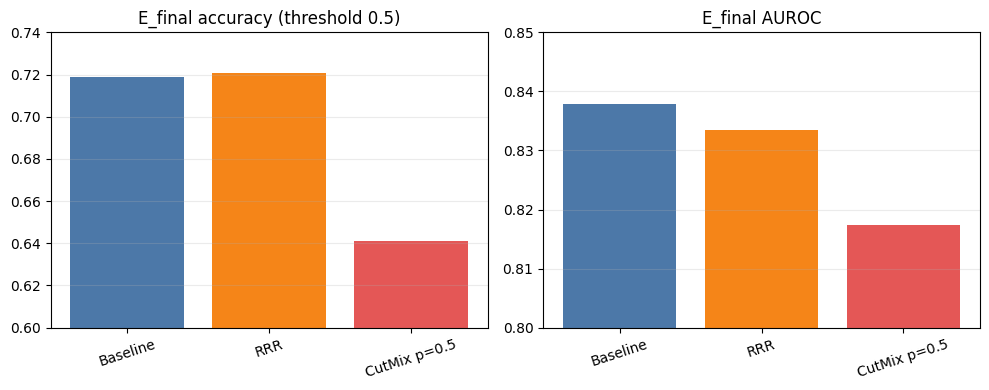

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ['Baseline', 'RRR', 'CutMix p=0.5']
acc = [r['E_final_baseline']['accuracy'], r['E_final_candidate']['accuracy'], c['E_final_candidate']['accuracy']]
auc = [r['E_final_baseline']['auroc'], r['E_final_candidate']['auroc'], c['E_final_candidate']['auroc']]
axes[0].bar(labels, acc, color=['#4C78A8','#F58518','#E45756']); axes[0].set_title('E_final accuracy (threshold 0.5)'); axes[0].set_ylim(0.60, 0.74)
axes[1].bar(labels, auc, color=['#4C78A8','#F58518','#E45756']); axes[1].set_title('E_final AUROC'); axes[1].set_ylim(0.80, 0.85)
for ax in axes:
    ax.tick_params(axis='x', rotation=18); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()


In [27]:
import zipfile

EXPORT = PROJECT_ROOT / 'MD6329_rewritten_notebook_audit_bundle.zip'
(PROJECT_ROOT / 'completed_results_registry.json').write_text(
    json.dumps(COMPLETED, ensure_ascii=False, indent=2), encoding='utf-8'
)
with zipfile.ZipFile(EXPORT, 'w', zipfile.ZIP_DEFLATED) as archive:
    archive.write(PROJECT_ROOT / 'completed_results_registry.json', 'completed_results_registry.json')
    for path in sorted(SRC.glob('*.py')):
        archive.write(path, f'src/{path.name}')
print({'export': str(EXPORT), 'bytes': EXPORT.stat().st_size, 'sha256': sha256(EXPORT)})


{'export': '/content/md6329_project/MD6329_rewritten_notebook_audit_bundle.zip', 'bytes': 49940, 'sha256': '90d3986cb6bceba4a06e54c593b86225f2fbbf9e6a988f55254e66b80e041a10'}


## 4. B64 resolution and AC-JSD

In [28]:
# RUN_B64_PLAIN, RUN_B64_AUGMIX and RUN_STEP15_INTERNAL_TEST are configured in Section 00.

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def import_from_path(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

STEP15_ROOT = PROJECT_ROOT / 'md6329_step15_b64_augmix'
STEP15_ROOT.mkdir(parents=True, exist_ok=True)
print({'step15_root': str(STEP15_ROOT), 'run_b64_plain': RUN_B64_PLAIN,
       'run_b64_augmix': RUN_B64_AUGMIX,
       'run_internal_test': RUN_STEP15_INTERNAL_TEST})


{'step15_root': '/content/md6329_project/md6329_step15_b64_augmix', 'run_b64_plain': False, 'run_b64_augmix': False, 'run_internal_test': False}


In [29]:
%%writefile /content/md6329_project/md6329_step15_b64_augmix/b64_augmix.py
from __future__ import annotations

import csv
import hashlib
import json
import math
import random
import time
import urllib.request
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, balanced_accuracy_score, brier_score_loss, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader, TensorDataset


SEED = 632901
DATA_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
DATA_MD5 = "8f4eceb4ccffa70c672198ea285246c6"
EXPECTED_SPLITS = {"train": 4708, "val": 524, "test": 624}
B28_VALIDATION_REFERENCE = {"accuracy": 0.9732824427480916, "auroc": 0.996134437779682}
B28_TEST_REFERENCE = {"accuracy": 0.8621794871794872, "auroc": 0.9444115713346481}
CUTMIX_TEST_REFERENCE = {"accuracy": 0.8701923076923077, "auroc": 0.950597194827964}


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def md5(path: Path) -> str:
    h = hashlib.md5()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def save_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        raise ValueError("Refusing to save an empty table")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def seed_all(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def obtain_data(root: Path) -> Path:
    path = root / "data" / "pneumoniamnist_64.npz"
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        temporary = path.with_suffix(".npz.part")
        urllib.request.urlretrieve(DATA_URL, temporary)
        temporary.replace(path)
    actual = md5(path)
    if actual != DATA_MD5:
        raise RuntimeError(f"Dataset MD5 mismatch: {actual} != {DATA_MD5}")
    return path


def load_arrays(path: Path, include_test: bool = False) -> dict[str, np.ndarray]:
    allowed = ("train", "val", "test") if include_test else ("train", "val")
    arrays: dict[str, np.ndarray] = {}
    with np.load(path) as archive:
        for split in allowed:
            images = archive[f"{split}_images"].copy()
            labels = archive[f"{split}_labels"].reshape(-1).astype(np.int64)
            if len(images) != EXPECTED_SPLITS[split] or images.shape[1:3] != (64, 64):
                raise AssertionError((split, images.shape, labels.shape))
            if set(np.unique(labels)) != {0, 1}:
                raise AssertionError((split, np.unique(labels)))
            arrays[f"{split}_images"] = images
            arrays[f"{split}_labels"] = labels
    return arrays


def normalized_tensor(images: np.ndarray) -> torch.Tensor:
    value = torch.from_numpy(images).float()
    if value.ndim == 3:
        value = value.unsqueeze(1)
    elif value.ndim == 4 and value.shape[-1] == 1:
        value = value.permute(0, 3, 1, 2)
    if value.ndim != 4 or value.shape[1] != 1:
        raise AssertionError(value.shape)
    return value.div(255.0).sub(0.5).div(0.5)


def make_loader(images: np.ndarray, labels: np.ndarray, batch_size: int, shuffle: bool, seed: int) -> DataLoader:
    dataset = TensorDataset(normalized_tensor(images), torch.from_numpy(labels).long())
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      pin_memory=torch.cuda.is_available(), generator=generator if shuffle else None)


def conv3x3(in_planes: int, out_planes: int, stride: int = 1) -> nn.Conv2d:
    return nn.Conv2d(in_planes, out_planes, 3, stride=stride, padding=1, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = conv3x3(in_planes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False),
                                          nn.BatchNorm2d(planes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        value = F.relu(self.bn1(self.conv1(x)))
        value = self.bn2(self.conv2(value)) + self.shortcut(x)
        return F.relu(value)


class ResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.in_planes = 64
        self.conv1 = conv3x3(1, 64)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._layer(64, 2, 1)
        self.layer2 = self._layer(128, 2, 2)
        self.layer3 = self._layer(256, 2, 2)
        self.layer4 = self._layer(512, 2, 2)
        self.linear = nn.Linear(512, 2)

    def _layer(self, planes: int, blocks: int, stride: int) -> nn.Sequential:
        layers = []
        for step in [stride] + [1] * (blocks - 1):
            layers.append(BasicBlock(self.in_planes, planes, step))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        value = F.relu(self.bn1(self.conv1(x)))
        value = self.layer4(self.layer3(self.layer2(self.layer1(value))))
        return self.linear(F.adaptive_avg_pool2d(value, 1).flatten(1))


def _unit(x: torch.Tensor) -> torch.Tensor:
    return x.mul(0.5).add(0.5).clamp(0, 1)


def _normalized(x: torch.Tensor) -> torch.Tensor:
    return x.clamp(0, 1).sub(0.5).div(0.5)


def adjust_gamma(x: torch.Tensor, gamma: float) -> torch.Tensor:
    return _normalized(_unit(x).pow(gamma))


def adjust_brightness(x: torch.Tensor, factor: float) -> torch.Tensor:
    return _normalized(_unit(x).mul(factor))


def adjust_contrast(x: torch.Tensor, factor: float) -> torch.Tensor:
    value = _unit(x)
    mean = value.mean(dim=(-2, -1), keepdim=True)
    return _normalized((value - mean).mul(factor).add(mean))


def affine(x: torch.Tensor, degrees: float = 0.0, translate_fraction: float = 0.0) -> torch.Tensor:
    angle = math.radians(degrees)
    batch = len(x)
    theta = x.new_zeros((batch, 2, 3))
    theta[:, 0, 0], theta[:, 0, 1] = math.cos(angle), -math.sin(angle)
    theta[:, 1, 0], theta[:, 1, 1] = math.sin(angle), math.cos(angle)
    # Historical parameter is in normalized grid units, not image-width fractions.
    # With align_corners=False, 0.03 shifts each axis by 1.5% of its image dimension.
    theta[:, 0, 2] = translate_fraction
    theta[:, 1, 2] = -translate_fraction
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)


def blur(x: torch.Tensor, strength: int = 3) -> torch.Tensor:
    return F.avg_pool2d(x, kernel_size=strength, stride=1, padding=strength // 2)


def noise(x: torch.Tensor, sigma: float, generator: torch.Generator | None = None) -> torch.Tensor:
    usable_generator = generator if generator is not None and str(generator.device).startswith(x.device.type) else None
    draw = torch.randn(x.shape, device=x.device, dtype=x.dtype, generator=usable_generator)
    return (x + draw.mul(sigma / 0.5)).clamp(-1, 1)


def acquisition_view(x: torch.Tensor, generator: torch.Generator) -> torch.Tensor:
    value = x
    operations = int(torch.randint(1, 4, (1,), generator=generator).item())
    order = torch.randperm(7, generator=generator)[:operations].tolist()
    scalar = lambda low, high: low + (high - low) * float(torch.rand(1, generator=generator))
    for operation in order:
        if operation == 0:
            value = adjust_gamma(value, scalar(0.85, 1.15))
        elif operation == 1:
            value = adjust_brightness(value, scalar(0.90, 1.10))
        elif operation == 2:
            value = adjust_contrast(value, scalar(0.85, 1.15))
        elif operation == 3:
            value = affine(value, degrees=scalar(-7.0, 7.0))
        elif operation == 4:
            value = affine(value, translate_fraction=scalar(-0.03, 0.03))
        elif operation == 5:
            value = blur(value, 3)
        else:
            value = noise(value, scalar(0.005, 0.025), generator)
    return value


def jsd_loss(logits: list[torch.Tensor]) -> torch.Tensor:
    probabilities = [F.softmax(item, dim=1) for item in logits]
    mixture = torch.stack(probabilities).mean(0).clamp(1e-7, 1.0)
    return torch.stack([F.kl_div(mixture.log(), item, reduction="batchmean") for item in probabilities]).mean()


def expected_calibration_error(labels: np.ndarray, scores: np.ndarray, bins: int = 10) -> float:
    confidence = np.maximum(scores, 1 - scores)
    prediction = (scores >= 0.5).astype(np.int64)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for index in range(bins):
        selected = (confidence > edges[index]) & (confidence <= edges[index + 1])
        if selected.any():
            total += selected.mean() * abs((prediction[selected] == labels[selected]).mean() - confidence[selected].mean())
    return float(total)


def metrics(labels: np.ndarray, scores: np.ndarray, threshold: float = 0.5) -> dict:
    prediction = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(labels, prediction, labels=[0, 1]).ravel()
    return {"n": int(len(labels)), "threshold": float(threshold),
            "accuracy": float(accuracy_score(labels, prediction)),
            "balanced_accuracy": float(balanced_accuracy_score(labels, prediction)),
            "auroc": float(roc_auc_score(labels, scores)),
            "brier": float(brier_score_loss(labels, scores)),
            "ece10": expected_calibration_error(labels, scores),
            "sensitivity": float(tp / (tp + fn)), "specificity": float(tn / (tn + fp)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def predict(model: nn.Module, loader: DataLoader, device: torch.device,
            transform=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            if transform is not None:
                x = transform(x)
            logits.append(model(x).cpu())
            labels.append(y)
    logits_np = torch.cat(logits).numpy()
    labels_np = torch.cat(labels).numpy()
    scores = torch.softmax(torch.from_numpy(logits_np), 1).numpy()[:, 1]
    return logits_np, scores, labels_np


def gradcam(model: nn.Module, x: torch.Tensor, device: torch.device) -> np.ndarray:
    model.eval()
    saved = {}

    def hook(_module, _inputs, output):
        output.retain_grad()
        saved["activation"] = output

    handle = model.layer4.register_forward_hook(hook)
    try:
        value = x.to(device).requires_grad_(True)
        model.zero_grad(set_to_none=True)
        logits = model(value)
        logits[:, 1].sum().backward()
        activation = saved["activation"]
        weights = activation.grad.mean((2, 3), keepdim=True)
        cam = F.relu((weights * activation).sum(1, keepdim=True))
        cam = F.interpolate(cam, x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = cam / cam.flatten(1).amax(1).clamp_min(1e-12).view(-1, 1, 1)
        return cam.detach().cpu().numpy()
    finally:
        handle.remove()


def explanation_proxies(model: nn.Module, images: np.ndarray, labels: np.ndarray,
                        device: torch.device, maximum: int = 64) -> dict:
    rng = np.random.default_rng(SEED + 17)
    chosen = np.concatenate([rng.choice(np.flatnonzero(labels == label), min(maximum // 2, int((labels == label).sum())), replace=False)
                             for label in (0, 1)])
    x = normalized_tensor(images[chosen])
    clean = gradcam(model, x, device)
    transforms = {
        "brightness_0p90": lambda value: adjust_brightness(value, 0.90),
        "contrast_0p85": lambda value: adjust_contrast(value, 0.85),
        "gamma_1p15": lambda value: adjust_gamma(value, 1.15),
        "blur_3": lambda value: blur(value, 3),
    }
    stability = {}
    flat_clean = clean.reshape(len(clean), -1)
    for name, transform in transforms.items():
        changed = gradcam(model, transform(x), device).reshape(len(clean), -1)
        cosine = (flat_clean * changed).sum(1) / (np.linalg.norm(flat_clean, axis=1) * np.linalg.norm(changed, axis=1) + 1e-12)
        stability[name] = {"mean_cam_cosine": float(cosine.mean()), "median_cam_cosine": float(np.median(cosine))}

    model.eval()
    with torch.no_grad():
        base = torch.softmax(model(x.to(device)), 1)[:, 1]
        height, width_image = x.shape[-2:]
        width = 6
        border_mask = torch.zeros((height, width_image), dtype=torch.bool)
        border_mask[:width, :] = True; border_mask[-width:, :] = True
        border_mask[:, :width] = True; border_mask[:, -width:] = True
        border_pixels = int(border_mask.sum())
        side = int(round(math.sqrt(border_pixels)))
        row0, col0 = (height - side) // 2, (width_image - side) // 2
        center_mask = torch.zeros_like(border_mask)
        center_mask[row0:row0 + side, col0:col0 + side] = True
        border = x.clone(); border[:, :, border_mask] = 0
        center = x.clone(); center[:, :, center_mask] = 0
        border_drop = base - torch.softmax(model(border.to(device)), 1)[:, 1]
        center_drop = base - torch.softmax(model(center.to(device)), 1)[:, 1]
    return {"n": int(len(chosen)), "target_class": 1, "cam_stability": stability,
            "mean_border_occlusion_drop": float(border_drop.mean().cpu()),
            "mean_center_occlusion_drop": float(center_drop.mean().cpu()),
            "center_minus_border_drop": float((center_drop - border_drop).mean().cpu()),
            "border_occluded_pixels": border_pixels,
            "center_occluded_pixels": int(center_mask.sum()),
            "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}


CORRUPTIONS = {
    "clean": None,
    "brightness_0p90": lambda x: adjust_brightness(x, 0.90),
    "brightness_1p10": lambda x: adjust_brightness(x, 1.10),
    "contrast_0p85": lambda x: adjust_contrast(x, 0.85),
    "contrast_1p15": lambda x: adjust_contrast(x, 1.15),
    "gamma_0p85": lambda x: adjust_gamma(x, 0.85),
    "gamma_1p15": lambda x: adjust_gamma(x, 1.15),
    "rotation_minus7": lambda x: affine(x, degrees=-7.0),
    "rotation_plus7": lambda x: affine(x, degrees=7.0),
    # Legacy result key retained for archived tables; actual per-axis translation is 1.5%.
    "translation_3pct": lambda x: affine(x, translate_fraction=0.03),
    "blur_3": lambda x: blur(x, 3),
    "noise_0p02": lambda x: noise(x, 0.02, torch.Generator(device=x.device).manual_seed(SEED + 99)),
}


@dataclass(frozen=True)
class TrainingConfig:
    seed: int = SEED
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    mode: str = "b64_plain"
    jsd_weight: float = 12.0


def prepare(root: Path, mode: str) -> Path:
    if mode not in {"b64_plain", "b64_augmix"}:
        raise ValueError(mode)
    dataset = obtain_data(root)
    arrays = load_arrays(dataset, include_test=False)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = root / "runs" / run_id / mode
    out.mkdir(parents=True)
    protocol = {"status": "protocol_frozen_before_training", "created_utc": datetime.now(timezone.utc).isoformat(),
                "dataset": "PneumoniaMNIST v2 64x64", "dataset_md5": md5(dataset), "dataset_sha256": sha256(dataset),
                "splits_loaded": {split: EXPECTED_SPLITS[split] for split in ("train", "val")},
                "test_loaded": False, "config": asdict(TrainingConfig(mode=mode)),
                "selection": "best clean validation AUROC within each mode; model comparison uses the frozen validation dual gate",
                "xai": "Grad-CAM stability plus matched border/center occlusion on source validation",
                "external_policy": "E_final was previously opened; it is unavailable for selection. A new untouched external holdout is required for unbiased final confirmation."}
    save_json(out / "protocol_before_training.json", protocol)
    return out


def train(root: Path, out: Path, mode: str) -> dict:
    config = TrainingConfig(mode=mode)
    seed_all(config.seed)
    arrays = load_arrays(obtain_data(root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ResNet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, list(config.milestones), gamma=config.gamma)
    train_loader = make_loader(arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed)
    val_loader = make_loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    augmentation_generator = torch.Generator().manual_seed(config.seed + 1)
    best_auc, best_epoch, rows = -np.inf, None, []
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train(); total_loss = total_ce = total_jsd = 0.0; count = correct = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            if mode == "b64_augmix":
                view1 = acquisition_view(x, augmentation_generator)
                view2 = acquisition_view(x, augmentation_generator)
                outputs = [model(x), model(view1), model(view2)]
                ce = sum(F.cross_entropy(output, y) for output in outputs) / len(outputs)
                consistency = jsd_loss(outputs)
                loss = ce + config.jsd_weight * consistency
                logits = outputs[0]
            else:
                logits = model(x); ce = F.cross_entropy(logits, y); consistency = logits.new_tensor(0.0); loss = ce
            loss.backward(); optimizer.step()
            total_loss += float(loss) * len(y); total_ce += float(ce) * len(y); total_jsd += float(consistency) * len(y)
            count += len(y); correct += int((logits.argmax(1) == y).sum())
        val_logits, val_scores, val_labels = predict(model, val_loader, device)
        val = metrics(val_labels, val_scores)
        row = {"epoch": epoch, "learning_rate": float(optimizer.param_groups[0]["lr"]),
               "train_loss": total_loss / count, "train_ce": total_ce / count, "train_jsd": total_jsd / count,
               "train_accuracy": correct / count, "val_accuracy": val["accuracy"], "val_auroc": val["auroc"],
               "elapsed_seconds": time.time() - started}
        rows.append(row)
        if val["auroc"] > best_auc:
            best_auc, best_epoch = val["auroc"], epoch
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "validation_auroc": best_auc,
                        "config": asdict(config)}, out / "best_weights.pt")
            np.savez_compressed(out / "best_validation_predictions.npz", logits=val_logits, scores=val_scores, labels=val_labels)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(f"{mode} epoch={epoch:03d} val_auc={val['auroc']:.6f} val_acc={val['accuracy']:.6f}", flush=True)
    save_csv(out / "learning_curve.csv", rows)
    summary = {"status": "training_complete_validation_checkpoint_frozen", "mode": mode, "device": str(device),
               "best_epoch": int(best_epoch), "best_validation_auroc": float(best_auc),
               "weights_sha256": sha256(out / "best_weights.pt"), "training_seconds": time.time() - started}
    save_json(out / "training_summary.json", summary)
    return summary


def load_model(out: Path, device: torch.device) -> nn.Module:
    checkpoint = torch.load(out / "best_weights.pt", map_location=device, weights_only=False)
    model = ResNet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def validate(root: Path, out: Path) -> dict:
    arrays = load_arrays(obtain_data(root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(out, device)
    loader = make_loader(arrays["val_images"], arrays["val_labels"], 128, False, SEED)
    conditions = {}
    for name, transform in CORRUPTIONS.items():
        _, scores, labels = predict(model, loader, device, transform)
        conditions[name] = metrics(labels, scores)
    xai = explanation_proxies(model, arrays["val_images"], arrays["val_labels"], device)
    clean = conditions["clean"]
    perturbed = [value for key, value in conditions.items() if key != "clean"]
    summary = {"status": "validation_complete_test_unopened", "mode": json.loads((out / "protocol_before_training.json").read_text())["config"]["mode"],
               "weights_sha256": sha256(out / "best_weights.pt"), "conditions": conditions,
               "aggregate": {"clean_accuracy": clean["accuracy"], "clean_auroc": clean["auroc"],
                             "mean_perturbed_accuracy": float(np.mean([x["accuracy"] for x in perturbed])),
                             "mean_perturbed_auroc": float(np.mean([x["auroc"] for x in perturbed])),
                             "worst_perturbed_accuracy": float(np.min([x["accuracy"] for x in perturbed])),
                             "worst_perturbed_auroc": float(np.min([x["auroc"] for x in perturbed])),
                             "mean_perturbed_brier": float(np.mean([x["brier"] for x in perturbed])),
                             "mean_perturbed_ece10": float(np.mean([x["ece10"] for x in perturbed]))},
               "explainability": xai}
    save_json(out / "validation_robustness_and_xai.json", summary)
    return summary


def compare_validation(plain: dict, augmix: dict) -> dict:
    pa, aa = plain["aggregate"], augmix["aggregate"]
    px, ax = plain["explainability"], augmix["explainability"]
    p_cam = float(np.mean([x["mean_cam_cosine"] for x in px["cam_stability"].values()]))
    a_cam = float(np.mean([x["mean_cam_cosine"] for x in ax["cam_stability"].values()]))
    guardrails = {"clean_accuracy_not_lower_than_plain": aa["clean_accuracy"] >= pa["clean_accuracy"],
                  "clean_auroc_drop_le_0p005": aa["clean_auroc"] >= pa["clean_auroc"] - 0.005}
    benefits = {"mean_perturbed_auroc_higher": aa["mean_perturbed_auroc"] > pa["mean_perturbed_auroc"],
                "worst_perturbed_accuracy_higher": aa["worst_perturbed_accuracy"] > pa["worst_perturbed_accuracy"],
                "mean_cam_stability_higher": a_cam > p_cam,
                "center_minus_border_not_lower": ax["center_minus_border_drop"] >= px["center_minus_border_drop"]}
    accepted = all(guardrails.values()) and sum(benefits.values()) >= 2
    result = {"status": "candidate_selected_on_source_validation_only" if accepted else "candidate_rejected_on_source_validation",
              "guardrails": guardrails, "benefits": benefits, "accepted_for_internal_test": accepted,
              "differences_augmix_minus_plain": {key: float(aa[key] - pa[key]) for key in pa},
              "mean_cam_stability": {"b64_plain": float(p_cam), "b64_augmix": float(a_cam)},
              "test_access": "permitted once" if accepted else "forbidden"}
    return result


def evaluate_internal_test(root: Path, out: Path, selection: dict) -> dict:
    if not selection.get("accepted_for_internal_test", False):
        raise RuntimeError("Validation dual gate did not pass; internal test remains unopened for this candidate.")
    arrays = load_arrays(obtain_data(root), include_test=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(out, device)
    loader = make_loader(arrays["test_images"], arrays["test_labels"], 128, False, SEED)
    _, scores, labels = predict(model, loader, device)
    result = {"status": "one_time_internal_test_complete", "metrics": metrics(labels, scores),
              "explainability": explanation_proxies(model, arrays["test_images"], arrays["test_labels"], device),
              "comparators": {"B28": B28_TEST_REFERENCE, "CutMix_p0p5": CUTMIX_TEST_REFERENCE},
              "external_policy": "Do not reuse the previously opened E_final for selection; evaluate once on a newly sealed patient-disjoint external holdout after final freeze."}
    np.savez_compressed(out / "internal_test_predictions.npz", scores=scores, labels=labels)
    save_json(out / "internal_test_and_xai.json", result)
    return result


Writing /content/md6329_project/md6329_step15_b64_augmix/b64_augmix.py


In [30]:
STEP15_HISTORICAL_SHA256 = '7a3d61e27cf7c0c309c09e5c610d068b5d22518d876b11b21c57e62e88f4bab6'
# The expected hash below identifies the submission revision, not the historical training source.
STEP15_SOURCE = STEP15_ROOT / 'b64_augmix.py'
STEP15_EXPECTED_SHA256 = 'c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a'
actual_step15_sha256 = sha256(STEP15_SOURCE)
assert actual_step15_sha256 == STEP15_EXPECTED_SHA256
step15 = import_from_path('b64_augmix', STEP15_SOURCE)
print('Verified Step 15 source:', actual_step15_sha256)


Verified Step 15 source: c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a


In [31]:
if RUN_B64_PLAIN:
    B64_PLAIN_OUT = step15.prepare(STEP15_ROOT, 'b64_plain')
    B64_PLAIN_TRAINING = step15.train(STEP15_ROOT, B64_PLAIN_OUT, 'b64_plain')
    B64_PLAIN_VALIDATION = step15.validate(STEP15_ROOT, B64_PLAIN_OUT)
    print(json.dumps(B64_PLAIN_VALIDATION, indent=2, ensure_ascii=False))
else:
    print('B64 plain retraining is disabled in this execution. Its completed historical results are recorded below.')


B64 plain retraining is disabled in this execution. Its completed historical results are recorded below.


In [32]:
if RUN_B64_AUGMIX:
    B64_AUGMIX_OUT = step15.prepare(STEP15_ROOT, 'b64_augmix')
    B64_AUGMIX_TRAINING = step15.train(STEP15_ROOT, B64_AUGMIX_OUT, 'b64_augmix')
    B64_AUGMIX_VALIDATION = step15.validate(STEP15_ROOT, B64_AUGMIX_OUT)
    print(json.dumps(B64_AUGMIX_VALIDATION, indent=2, ensure_ascii=False))
else:
    print('AC-JSD retraining is disabled in this execution. Historical results are recorded; the exact original weight binary is not restored locally.')


AC-JSD retraining is disabled in this execution. Historical results are recorded; the exact original weight binary is not restored locally.


In [33]:
if RUN_B64_PLAIN and RUN_B64_AUGMIX:
    STEP15_SELECTION = step15.compare_validation(B64_PLAIN_VALIDATION, B64_AUGMIX_VALIDATION)
    (STEP15_ROOT / 'validation_selection.json').write_text(
        json.dumps(STEP15_SELECTION, ensure_ascii=False, indent=2), encoding='utf-8')
    display(pd.DataFrame([
        {'model': 'B64 plain', **B64_PLAIN_VALIDATION['aggregate']},
        {'model': 'B64 AugMix/JSD', **B64_AUGMIX_VALIDATION['aggregate']},
    ]))
    print(json.dumps(STEP15_SELECTION, indent=2, ensure_ascii=False))
else:
    STEP15_SELECTION = {'accepted_for_internal_test': False, 'status': 'not_run'}
    print('Validation-gate recomputation is disabled. The historical candidate passed the recorded source gate; no new inference is performed here.')


Validation-gate recomputation is disabled. The historical candidate passed the recorded source gate; no new inference is performed here.


In [34]:
if RUN_STEP15_INTERNAL_TEST:
    if not (RUN_B64_PLAIN and RUN_B64_AUGMIX):
        raise RuntimeError('Both source-validation experiments must finish first.')
    STEP15_INTERNAL = step15.evaluate_internal_test(STEP15_ROOT, B64_AUGMIX_OUT, STEP15_SELECTION)
    print(json.dumps(STEP15_INTERNAL, indent=2, ensure_ascii=False))
else:
    print('Internal-test inference is disabled in this execution. The completed frozen-model historical result is displayed in the B64 registry below.')


Internal-test inference is disabled in this execution. The completed frozen-model historical result is displayed in the B64 registry below.


In [35]:
STEP15_STATUS = {
    'stage': 'B64 resolution ablation and acquisition-style AugMix/JSD',
    'status': 'historical_training_and_evaluation_complete; exact_AC_JSD_binary_unavailable_locally',
    'current_execution': 'recorded_result_display_only' if not (RUN_B64_PLAIN or RUN_B64_AUGMIX) else 'opt_in_execution_requested',
    'seed': 632901,
    'source_sha256': STEP15_EXPECTED_SHA256,
    'historical_cells_preserved': 42,
    'internal_test_evaluated_historically': True,
    'internal_test_requested_this_execution': bool(RUN_STEP15_INTERNAL_TEST),
    'E_final_reused_for_selection': False,
    'new_external_holdout_required': True,
}
(STEP15_ROOT / 'stage_status.json').write_text(
    json.dumps(STEP15_STATUS, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(STEP15_STATUS, indent=2, ensure_ascii=False))


{
  "stage": "B64 resolution ablation and acquisition-style AugMix/JSD",
  "status": "historical_training_and_evaluation_complete; exact_AC_JSD_binary_unavailable_locally",
  "current_execution": "recorded_result_display_only",
  "seed": 632901,
  "source_sha256": "c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a",
  "historical_cells_preserved": 42,
  "internal_test_evaluated_historically": true,
  "internal_test_requested_this_execution": false,
  "E_final_reused_for_selection": false,
  "new_external_holdout_required": true
}


In [36]:
# RUN_STEP16_HISTORICAL_EXTERNAL is configured in Section 00.
STEP16_ROOT = PROJECT_ROOT / 'md6329_step16_b64_external_audit'
STEP16_ROOT.mkdir(parents=True, exist_ok=True)
if RUN_STEP16_HISTORICAL_EXTERNAL:
    if not ALLOW_REOPEN_E_FINAL:
        raise RuntimeError('Historical E_final reruns are locked in Section 00.')
    if not RUN_STEP15_INTERNAL_TEST or not STEP15_SELECTION.get('accepted_for_internal_test', False):
        raise RuntimeError('Freeze the source-selected method and finish its one-time internal test before external audit.')
print({'run_historical_external': RUN_STEP16_HISTORICAL_EXTERNAL,
       'role': 'post-hoc transfer audit; never selection or tuning'})


{'run_historical_external': False, 'role': 'post-hoc transfer audit; never selection or tuning'}


In [37]:
%%writefile /content/md6329_project/md6329_step16_b64_external_audit/b64_external_audit.py
from __future__ import annotations

import copy
import csv
import hashlib
import io
import json
import platform
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

import baseline
import b64_augmix as step15
import external_diagnosis as ext


IMAGE_SIZE = 64
EXPLANATION_SEED = 632916
EXPECTED_EFINAL_ROWS_SHA256 = "9995be2754f605e45bc908a83101445aa1539ddadbd7ddbf2048da775146d086"
HISTORICAL_EFINAL_MANIFEST_SHA256 = "4d484f337c8315eb7a767f3eed2c2fbd94a42fb86f34afebd851742283d22020"
HISTORICAL_B28_ARGMAX = {
    "accuracy": 0.7188836964391496,
    "balanced_accuracy": 0.7401017114753163,
    "auroc": 0.8379146603138572,
    "average_precision": 0.7754291522238987,
    "sensitivity": 0.8750390502967823,
    "specificity": 0.6051643726538505,
    "brier": 0.2558032959401595,
}


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def save_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        raise ValueError("Refusing to save an empty table")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def stable_hash_rows(rows: list[dict]) -> str:
    payload = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def read_dicom64(archive: zipfile.ZipFile, member: str) -> tuple[np.ndarray, dict]:
    import pydicom

    ds = pydicom.dcmread(io.BytesIO(archive.read(member)))
    image = ds.pixel_array.astype(np.float32)
    image = image * float(getattr(ds, "RescaleSlope", 1.0)) + float(getattr(ds, "RescaleIntercept", 0.0))
    photometric = str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2"))
    if photometric == "MONOCHROME1":
        image = image.max() + image.min() - image
    lo, hi = float(image.min()), float(image.max())
    if hi <= lo:
        raise ValueError(f"constant DICOM image: {member}")
    image = (image - lo) / (hi - lo)
    height, width = image.shape
    side = min(height, width)
    top, left = (height - side) // 2, (width - side) // 2
    crop = image[top:top + side, left:left + side]
    resized = np.asarray(
        Image.fromarray(np.uint8(np.round(crop * 255))).resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
        ), dtype=np.float32
    ) / 255.0
    return resized, {
        "height": height, "width": width, "side": side,
        "top": top, "left": left, "photometric": photometric,
    }


def mask_for_boxes64(boxes: list[dict], geometry: dict) -> np.ndarray:
    mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=bool)
    for box in boxes:
        x0 = (float(box["x"]) - geometry["left"]) / geometry["side"] * IMAGE_SIZE
        y0 = (float(box["y"]) - geometry["top"]) / geometry["side"] * IMAGE_SIZE
        x1 = (float(box["x"]) + float(box["width"]) - geometry["left"]) / geometry["side"] * IMAGE_SIZE
        y1 = (float(box["y"]) + float(box["height"]) - geometry["top"]) / geometry["side"] * IMAGE_SIZE
        xa, xb = max(0, int(np.floor(x0))), min(IMAGE_SIZE, int(np.ceil(x1)))
        ya, yb = max(0, int(np.floor(y0))), min(IMAGE_SIZE, int(np.ceil(y1)))
        if xb > xa and yb > ya:
            mask[ya:yb, xa:xb] = True
    return mask


def load_batch64(archive: zipfile.ZipFile, members: dict[str, str], records: list[dict]):
    images, masks, geometries = [], [], []
    for record in records:
        image, geometry = read_dicom64(archive, members[record["sop_instance_uid"]])
        images.append(image)
        masks.append(mask_for_boxes64(record["boxes"], geometry) if record["boxes"] else np.zeros((IMAGE_SIZE, IMAGE_SIZE), bool))
        geometries.append(geometry)
    x = (torch.from_numpy(np.stack(images)).float().unsqueeze(1) - 0.5) / 0.5
    return x, masks, geometries


def center_prior64() -> np.ndarray:
    center = (IMAGE_SIZE - 1) / 2
    sigma = IMAGE_SIZE * 6.0 / 28.0
    y, x = np.mgrid[0:IMAGE_SIZE, 0:IMAGE_SIZE]
    prior = np.exp(-((x - center) ** 2 + (y - center) ** 2) / (2 * sigma ** 2))
    return prior / prior.sum()


def translated_masks64(mask: np.ndarray, count: int, rng: np.random.Generator) -> list[np.ndarray]:
    ys, xs = np.where(mask)
    if not len(xs):
        return []
    output, seen = [], set()
    for _ in range(5000):
        dy = int(rng.integers(-int(ys.min()), IMAGE_SIZE - int(ys.max())))
        dx = int(rng.integers(-int(xs.min()), IMAGE_SIZE - int(xs.max())))
        if (dy, dx) == (0, 0) or (dy, dx) in seen:
            continue
        shifted = np.zeros_like(mask)
        shifted[ys + dy, xs + dx] = True
        if (shifted & mask).any():
            continue
        seen.add((dy, dx))
        output.append(shifted)
        if len(output) == count:
            break
    return output


def verify_final_records(files: dict[str, Path]) -> tuple[list[dict], dict]:
    records = ext.build_records(files["annotations"], files["mapping"])
    diag, final, summary = ext.patient_split(records)
    keys = ("patient_id", "subset_img_id", "study_uid", "sop_instance_uid", "class_name")
    final_rows = [{key: row[key] for key in keys} for row in final]
    rows_hash = stable_hash_rows(final_rows)
    if rows_hash != EXPECTED_EFINAL_ROWS_SHA256:
        raise RuntimeError(f"Historical E_final rows changed: {rows_hash}")
    overlap = {r["patient_id"] for r in diag} & {r["patient_id"] for r in final}
    if overlap or len(final) != 26774 or len({r["patient_id"] for r in final}) != 11009:
        raise AssertionError((len(overlap), len(final), len({r["patient_id"] for r in final})))
    return final, {
        "status": "historical_E_final_reopened_for_post_hoc_transfer_audit",
        "historical_manifest_sha256": HISTORICAL_EFINAL_MANIFEST_SHA256,
        "recomputed_rows_sha256": rows_hash,
        "patient_overlap_with_E_diag": 0,
        "patients": 11009,
        "images": 26774,
        "class_counts": summary["final_class_counts_only_for_split_audit"],
        "selection_or_tuning_permitted": False,
        "opened_utc": utcnow(),
    }


def paired_predict(models: dict[str, torch.nn.Module], zip_path: Path, members: dict[str, str], records: list[dict], device: torch.device, batch_size: int = 128):
    logits = {name: [] for name in models}
    with zipfile.ZipFile(zip_path) as archive, torch.no_grad():
        for start in range(0, len(records), batch_size):
            x, _, _ = load_batch64(archive, members, records[start:start + batch_size])
            x = x.to(device)
            for name, model in models.items():
                logits[name].append(model(x).cpu())
            if start == 0 or (start // batch_size + 1) % 20 == 0:
                print(f"B64 E_final predictions: {min(start + batch_size, len(records))}/{len(records)}", flush=True)
    output = {}
    for name, parts in logits.items():
        logit = torch.cat(parts).numpy()
        output[name] = {"logits": logit, "scores": torch.softmax(torch.from_numpy(logit), 1).numpy()[:, 1]}
    return output


def model_occlusion(model: torch.nn.Module, x: torch.Tensor, mask: np.ndarray, outside: list[np.ndarray], device: torch.device) -> dict:
    with torch.no_grad():
        clean = float(torch.softmax(model(x.unsqueeze(0).to(device)), 1)[0, 1])
        result = {"outside_locations": len(outside)}
        for mode in ("mean", "blur"):
            variants = [ext.occluded(x, mask, mode)] + [ext.occluded(x, item, mode) for item in outside]
            scores = torch.softmax(model(torch.stack(variants).to(device)), 1)[:, 1].cpu().numpy()
            inside = clean - float(scores[0])
            outside_drop = clean - float(scores[1:].mean())
            result[f"{mode}_inside_drop"] = inside
            result[f"{mode}_outside_drop"] = outside_drop
            result[f"{mode}_inside_minus_outside"] = inside - outside_drop
    return result


def summarize_localization(rows: list[dict], name: str) -> dict:
    return {
        "n": len(rows),
        "area_corrected_energy_mean": float(np.mean([r[f"{name}_area_corrected_energy"] for r in rows])),
        "area_corrected_energy_median": float(np.median([r[f"{name}_area_corrected_energy"] for r in rows])),
        "pointing_hit_rate": float(np.mean([r[f"{name}_pointing_hit"] for r in rows])),
        "zero_cam_rate": float(np.mean([r[f"{name}_zero_cam"] for r in rows])),
    }


def paired_explain(models: dict[str, torch.nn.Module], zip_path: Path, members: dict[str, str], records: list[dict], prediction: dict, out: Path, device: torch.device) -> dict:
    positives = [i for i, row in enumerate(records) if row["class_name"] == "Lung Opacity"]
    selected = sorted(positives, key=lambda i: hashlib.sha256(f"{EXPLANATION_SEED}|{records[i]['subset_img_id']}".encode()).hexdigest())[:300]
    selected_records = [records[i] for i in selected]
    cams_parts = {name: [] for name in models}
    images_parts, masks_all = [], []
    with zipfile.ZipFile(zip_path) as archive:
        for start in range(0, len(selected_records), 24):
            x, masks, _ = load_batch64(archive, members, selected_records[start:start + 24])
            for name, model in models.items():
                cams, _ = baseline.gradcam(model, x, device)
                cams_parts[name].append(cams)
            images_parts.append((x[:, 0].numpy() * 0.5 + 0.5).clip(0, 1))
            masks_all.extend(masks)
    cams = {name: np.concatenate(parts) for name, parts in cams_parts.items()}
    images = np.concatenate(images_parts)
    center = center_prior64()
    localization_rows = []
    for local_i, global_i in enumerate(selected):
        row = {
            "subset_img_id": records[global_i]["subset_img_id"],
            "patient_id": records[global_i]["patient_id"],
            "box_area_fraction": float(masks_all[local_i].mean()),
        }
        for name in models:
            corrected, pointing, zero = ext.energy_and_pointing(cams[name][local_i], masks_all[local_i])
            row.update({
                f"{name}_score": float(prediction[name]["scores"][global_i]),
                f"{name}_area_corrected_energy": corrected,
                f"{name}_pointing_hit": pointing,
                f"{name}_zero_cam": zero,
            })
        center_corrected, center_pointing, _ = ext.energy_and_pointing(center, masks_all[local_i])
        row["center_prior_area_corrected_energy"] = center_corrected
        row["center_prior_pointing_hit"] = center_pointing
        row["difference_area_corrected_energy"] = row["augmix_area_corrected_energy"] - row["plain_area_corrected_energy"]
        row["difference_pointing_hit"] = row["augmix_pointing_hit"] - row["plain_pointing_hit"]
        localization_rows.append(row)
    save_csv(out / "E_final_B64_localization_cases.csv", localization_rows)

    rng = np.random.default_rng(EXPLANATION_SEED)
    occlusion_rows = []
    with zipfile.ZipFile(zip_path) as archive:
        for local_i, global_i in enumerate(selected[:120]):
            x, masks, _ = load_batch64(archive, members, [records[global_i]])
            outside = translated_masks64(masks[0], 20, rng)
            if not outside:
                continue
            row = {"subset_img_id": records[global_i]["subset_img_id"], "patient_id": records[global_i]["patient_id"]}
            for name, model in models.items():
                values = model_occlusion(model, x[0], masks[0], outside, device)
                for key, value in values.items():
                    row[f"{name}_{key}"] = value
            for mode in ("mean", "blur"):
                key = f"{mode}_inside_minus_outside"
                row[f"difference_{key}"] = row[f"augmix_{key}"] - row[f"plain_{key}"]
            occlusion_rows.append(row)
            if (local_i + 1) % 20 == 0:
                print(f"B64 E_final occlusion: {local_i + 1}/120", flush=True)
    save_csv(out / "E_final_B64_occlusion_cases.csv", occlusion_rows)

    localization = {name: summarize_localization(localization_rows, name) for name in models}
    localization["augmix_minus_plain"] = {
        key: localization["augmix"][key] - localization["plain"][key]
        for key in ("area_corrected_energy_mean", "area_corrected_energy_median", "pointing_hit_rate", "zero_cam_rate")
    }
    occlusion = {}
    for name in models:
        occlusion[name] = {
            "n": len(occlusion_rows),
            "mean_inside_minus_outside": float(np.mean([r[f"{name}_mean_inside_minus_outside"] for r in occlusion_rows])),
            "blur_inside_minus_outside": float(np.mean([r[f"{name}_blur_inside_minus_outside"] for r in occlusion_rows])),
            "both_positive_fraction": float(np.mean([
                r[f"{name}_mean_inside_minus_outside"] > 0 and r[f"{name}_blur_inside_minus_outside"] > 0
                for r in occlusion_rows
            ])),
        }
    occlusion["augmix_minus_plain"] = {
        key: occlusion["augmix"][key] - occlusion["plain"][key]
        for key in ("mean_inside_minus_outside", "blur_inside_minus_outside", "both_positive_fraction")
    }
    sanity = {}
    with zipfile.ZipFile(zip_path) as archive:
        x50, _, _ = load_batch64(archive, members, selected_records[:50])
    for offset, (name, model) in enumerate(models.items()):
        baseline.seed_all(EXPLANATION_SEED + 10 + offset)
        randomized = copy.deepcopy(model).cpu()
        randomized.apply(ext.reset_parameters)
        randomized.to(device).eval()
        random_cams, _ = baseline.gradcam(randomized, x50, device)
        similarity = baseline.cosine_rows(cams[name][:50], random_cams)
        sanity[name] = {
            "n": 50,
            "trained_vs_fully_randomized_cam_cosine_mean": float(similarity.mean()),
            "trained_vs_fully_randomized_cam_cosine_median": float(np.median(similarity)),
        }
    np.savez_compressed(
        out / "E_final_B64_explanations.npz",
        selected_indices=np.array(selected), images=images, masks=np.stack(masks_all),
        plain_cams=cams["plain"], augmix_cams=cams["augmix"],
    )
    plot_examples(out, selected, records, images, masks_all, cams, prediction)
    summary = {
        "selection": {"seed": EXPLANATION_SEED, "n_localization": 300, "n_occlusion": len(occlusion_rows), "same_cases_and_settings": True},
        "localization": localization,
        "matched_occlusion": occlusion,
        "center_prior": {
            "area_corrected_energy_mean": float(np.mean([r["center_prior_area_corrected_energy"] for r in localization_rows])),
            "pointing_hit_rate": float(np.mean([r["center_prior_pointing_hit"] for r in localization_rows])),
        },
        "randomization_sanity": sanity,
        "limits": [
            "public bounding boxes are coarse rather than pixel masks",
            "Grad-CAM and occlusion provide region-dependence evidence, not medical causality",
            "the historical E_final was previously opened and cannot support candidate selection",
        ],
    }
    save_json(out / "E_final_B64_explainability_summary.json", summary)
    return summary


def plot_examples(out: Path, selected: list[int], records: list[dict], images: np.ndarray, masks: list[np.ndarray], cams: dict, prediction: dict) -> None:
    difference = []
    for local_i in range(len(selected)):
        plain, _, _ = ext.energy_and_pointing(cams["plain"][local_i], masks[local_i])
        augmix, _, _ = ext.energy_and_pointing(cams["augmix"][local_i], masks[local_i])
        difference.append(augmix - plain)
    order = np.argsort(difference)
    chosen = np.unique(np.linspace(0, len(order) - 1, 8, dtype=int))
    fig, axes = plt.subplots(len(chosen), 3, figsize=(9, 2.3 * len(chosen)))
    for row_i, position in enumerate(chosen):
        local_i = order[position]
        global_i = selected[local_i]
        axes[row_i, 0].imshow(images[local_i], cmap="gray", vmin=0, vmax=1)
        axes[row_i, 0].contour(masks[local_i].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
        axes[row_i, 0].set_title(f"Image / box | XAI delta={difference[local_i]:+.3f}", fontsize=8)
        for column, name in ((1, "plain"), (2, "augmix")):
            axes[row_i, column].imshow(images[local_i], cmap="gray", vmin=0, vmax=1)
            axes[row_i, column].imshow(cams[name][local_i], cmap="jet", alpha=.42, vmin=0, vmax=1)
            axes[row_i, column].contour(masks[local_i].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
            axes[row_i, column].set_title(f"{name} p={prediction[name]['scores'][global_i]:.2f}", fontsize=8)
        for axis in axes[row_i]:
            axis.axis("off")
    fig.suptitle("Historical E_final: paired B64 Grad-CAM with public boxes")
    fig.tight_layout()
    fig.savefig(out / "E_final_B64_gradcam_examples.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def run(project_root: Path, plain_out: Path, augmix_out: Path) -> dict:
    project_root, plain_out, augmix_out = Path(project_root), Path(plain_out), Path(augmix_out)
    stage = project_root / "md6329_step16_b64_external_audit"
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = stage / "runs" / run_id
    out.mkdir(parents=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    models = {"plain": step15.load_model(plain_out, device), "augmix": step15.load_model(augmix_out, device)}
    frozen = {name: step15.sha256(path / "best_weights.pt") for name, path in (("plain", plain_out), ("augmix", augmix_out))}
    plan = {
        "status": "frozen_B64_models_before_historical_external_audit",
        "created_utc": utcnow(), "image_size": IMAGE_SIZE, "threshold": 0.5,
        "weights_sha256": frozen,
        "prediction_primary": "Normal vs Lung Opacity AUROC and accuracy at frozen argmax threshold 0.5",
        "explanation_primary": "paired area-corrected Grad-CAM energy within public lesion boxes",
        "intervention": "paired lesion-box minus matched non-overlapping box occlusion effect",
        "E_final_role": "post-hoc transfer audit only; no selection or tuning",
    }
    save_json(out / "audit_plan_before_opening.json", plan)
    files = ext.obtain_rsna(project_root / "md6329_step10_resnet_reproduction")
    members = ext.zip_members(files["images"])
    records, opening = verify_final_records(files)
    missing = [r["sop_instance_uid"] for r in records if r["sop_instance_uid"] not in members]
    if missing:
        raise AssertionError(f"Missing {len(missing)} E_final DICOMs")
    save_json(out / "E_final_B64_opening_audit.json", opening)
    started = time.time()
    prediction = paired_predict(models, files["images"], members, records, device)
    prediction_seconds = time.time() - started
    labels = np.array([r["target"] for r in records], dtype=np.int64)
    np.savez_compressed(
        out / "E_final_B64_paired_predictions.npz", labels=labels,
        patient_ids=np.array([r["patient_id"] for r in records]),
        subset_img_ids=np.array([r["subset_img_id"] for r in records]),
        plain_logits=prediction["plain"]["logits"], plain_scores=prediction["plain"]["scores"],
        augmix_logits=prediction["augmix"]["logits"], augmix_scores=prediction["augmix"]["scores"],
    )
    metrics = {name: ext.prediction_metrics(records, prediction[name]["scores"], 0.5) for name in models}
    plain_primary = metrics["plain"]["primary_normal_vs_lung_opacity_argmax"]
    augmix_primary = metrics["augmix"]["primary_normal_vs_lung_opacity_argmax"]
    differences = {key: augmix_primary[key] - plain_primary[key] for key in (
        "accuracy", "balanced_accuracy", "auroc", "average_precision", "sensitivity", "specificity", "brier"
    )}
    save_json(out / "E_final_B64_prediction_metrics.json", {
        "metrics": metrics, "augmix_minus_plain": differences,
        "historical_B28_argmax_reference": HISTORICAL_B28_ARGMAX,
    })
    xai = paired_explain(models, files["images"], members, records, prediction, out, device)
    summary = {
        "status": "historical_E_final_B64_audit_complete_no_further_tuning",
        "completed_utc": utcnow(), "run_id": run_id, "run_directory": str(out),
        "device": str(device), "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else platform.processor(),
        "opening_audit": opening, "weights_sha256": frozen, "prediction_seconds": prediction_seconds,
        "prediction_metrics": metrics, "prediction_augmix_minus_plain": differences,
        "historical_B28_argmax_reference": HISTORICAL_B28_ARGMAX,
        "explainability": xai,
        "E_final_reused_for_selection": False, "further_tuning_permitted_from_this_result": False,
    }
    save_json(out / "E_final_B64_summary.json", summary)
    save_json(stage / "latest_run.json", {
        "run_id": run_id, "relative_path": str(out.relative_to(stage)).replace("\\", "/"),
        "status": summary["status"], "summary_sha256": step15.sha256(out / "E_final_B64_summary.json"),
    })
    return summary


def smoke_test() -> dict:
    geometry = {"left": 0, "top": 0, "side": 100}
    mask = mask_for_boxes64([{"x": 25, "y": 25, "width": 50, "height": 50}], geometry)
    if mask.shape != (64, 64) or not (900 <= int(mask.sum()) <= 1156):
        raise AssertionError((mask.shape, int(mask.sum())))
    prior = center_prior64()
    if not np.isclose(prior.sum(), 1.0):
        raise AssertionError(prior.sum())
    return {"image_size": IMAGE_SIZE, "mask_pixels": int(mask.sum()), "center_prior_sum": float(prior.sum())}


if __name__ == "__main__":
    print(json.dumps(smoke_test(), ensure_ascii=False, indent=2))


Writing /content/md6329_project/md6329_step16_b64_external_audit/b64_external_audit.py


In [38]:
baseline = import_from_path('baseline', SRC / 'baseline.py')
external_diagnosis = import_from_path('external_diagnosis', SRC / 'external_diagnosis.py')
STEP16_ROOT = PROJECT_ROOT / 'md6329_step16_b64_external_audit'
STEP16_SOURCE_PATH = STEP16_ROOT / 'b64_external_audit.py'
STEP16_EXPECTED_SHA256 = '41351bb774546eac214541ab387747f96e3d5f3583c558c2f94e35435fb5e28d'
assert sha256(STEP16_SOURCE_PATH) == STEP16_EXPECTED_SHA256
step16 = import_from_path('b64_external_audit', STEP16_SOURCE_PATH)
print(step16.smoke_test())
print('Verified Step 16 source:', STEP16_EXPECTED_SHA256)


{'image_size': 64, 'mask_pixels': 1024, 'center_prior_sum': 1.0}
Verified Step 16 source: 41351bb774546eac214541ab387747f96e3d5f3583c558c2f94e35435fb5e28d


In [39]:
if RUN_STEP16_HISTORICAL_EXTERNAL:
    if not ALLOW_REOPEN_E_FINAL:
        raise RuntimeError('Historical E_final reruns are locked in Section 00.')
    if not RUN_STEP15_INTERNAL_TEST or not STEP15_SELECTION.get('accepted_for_internal_test', False):
        raise RuntimeError('Complete the frozen source-validation selection and internal evaluation first.')
    if 'B64_PLAIN_OUT' not in globals() or 'B64_AUGMIX_OUT' not in globals():
        raise RuntimeError('The frozen B64 checkpoint directories must be available before an external rerun.')
    for checkpoint_dir in (B64_PLAIN_OUT, B64_AUGMIX_OUT):
        if not (Path(checkpoint_dir) / 'best_weights.pt').is_file():
            raise FileNotFoundError(f'Missing frozen checkpoint: {checkpoint_dir}')
    STEP16_EXTERNAL = step16.run(PROJECT_ROOT, B64_PLAIN_OUT, B64_AUGMIX_OUT)
    print(json.dumps(STEP16_EXTERNAL, indent=2, ensure_ascii=False))
else:
    print('Historical external audit is disabled in the clean source notebook.')


Historical external audit is disabled in the clean source notebook.


In [40]:
STEP16_RECORDED = {
  "status": "historical_E_final_B64_audit_complete_no_further_tuning",
  "completed_utc": "2026-10-20T10:36:24.390793+00:00",
  "seed": 632901,
  "executed_notebook_sha256": "8ebf776e45f8419fa4a707136da7f59e15327be5b944f54ba61105721a09883c",
  "weights_sha256": {
    "plain": "c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f",
    "augmix": "cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873"
  },
  "internal_fixed_method": {
    "accuracy": 0.8862179487179487,
    "balanced_accuracy": 0.8491452991452991,
    "auroc": 0.9780024106947183,
    "sensitivity": 0.9974358974358974,
    "specificity": 0.7008547008547008,
    "center_minus_border_drop": 0.21136775612831116
  },
  "external_primary_normal_vs_lung_opacity": {
    "n": 15193,
    "plain": {
      "accuracy": 0.8056999934180215,
      "balanced_accuracy": 0.7963593876060586,
      "auroc": 0.8720383652574729,
      "average_precision": 0.8273005962405511,
      "sensitivity": 0.7369572008747266,
      "specificity": 0.8557615743373905,
      "brier": 0.17237954636188949
    },
    "augmix": {
      "accuracy": 0.8093200816165339,
      "balanced_accuracy": 0.8164033083734816,
      "auroc": 0.9011850963278558,
      "average_precision": 0.8701954149136358,
      "sensitivity": 0.8614495470165573,
      "specificity": 0.7713570697304061,
      "brier": 0.16624484740944465
    },
    "augmix_minus_plain": {
      "accuracy": 0.00362008819851245,
      "balanced_accuracy": 0.020043920767423007,
      "auroc": 0.029146731070382903,
      "average_precision": 0.042894818673084756,
      "sensitivity": 0.12449234614183069,
      "specificity": -0.08440450460698445,
      "brier": -0.006134698952444839
    }
  },
  "external_explainability": {
    "localization_plain": {
      "n": 300,
      "area_corrected_energy_mean": -0.03360300222248043,
      "area_corrected_energy_median": -0.032801538705825806,
      "pointing_hit_rate": 0.06666666666666667,
      "zero_cam_rate": 0.0
    },
    "localization_augmix": {
      "n": 300,
      "area_corrected_energy_mean": -0.016158570475580517,
      "area_corrected_energy_median": -0.014167309505864978,
      "pointing_hit_rate": 0.08666666666666667,
      "zero_cam_rate": 0.0
    },
    "localization_augmix_minus_plain": {
      "area_corrected_energy_mean": 0.017444431746899913,
      "area_corrected_energy_median": 0.018634229199960828,
      "pointing_hit_rate": 0.020000000000000004,
      "zero_cam_rate": 0.0
    },
    "occlusion_plain": {
      "n": 89,
      "mean_inside_minus_outside": 0.03685295915398089,
      "blur_inside_minus_outside": 0.0074901350489521,
      "both_positive_fraction": 0.21348314606741572
    },
    "occlusion_augmix": {
      "n": 89,
      "mean_inside_minus_outside": 0.09126694306869058,
      "blur_inside_minus_outside": 0.008184563389742957,
      "both_positive_fraction": 0.14606741573033707
    },
    "occlusion_augmix_minus_plain": {
      "mean_inside_minus_outside": 0.054413983914709696,
      "blur_inside_minus_outside": 0.0006944283407908569,
      "both_positive_fraction": -0.06741573033707865
    },
    "center_prior": {
      "area_corrected_energy_mean": 0.10111346822308083,
      "pointing_hit_rate": 0.13
    },
    "randomization_sanity": {
      "plain": {
        "n": 50,
        "trained_vs_fully_randomized_cam_cosine_mean": 0.5500256706774235,
        "trained_vs_fully_randomized_cam_cosine_median": 0.5838892161846161
      },
      "augmix": {
        "n": 50,
        "trained_vs_fully_randomized_cam_cosine_mean": 0.42787534698843954,
        "trained_vs_fully_randomized_cam_cosine_median": 0.4372885227203369
      }
    }
  },
  "interpretation": {
    "relative_dual_objective": "passed on the historical external primary task",
    "absolute_localization": "weak; AugMix remains below the center prior on both area-corrected energy and pointing hit",
    "selection_or_tuning_from_E_final": False,
    "confirmatory_external_holdout_still_required": True
  }
}
display(pd.DataFrame([
    {'domain': 'Internal test', 'model': 'B64 AugMix/JSD', **STEP16_RECORDED['internal_fixed_method']},
    {'domain': 'Historical E_final primary', 'model': 'B64 plain', **STEP16_RECORDED['external_primary_normal_vs_lung_opacity']['plain']},
    {'domain': 'Historical E_final primary', 'model': 'B64 AugMix/JSD', **STEP16_RECORDED['external_primary_normal_vs_lung_opacity']['augmix']},
]))


,domain,model,accuracy,balanced_accuracy,auroc,sensitivity,specificity,center_minus_border_drop,average_precision,brier
0,Internal test,B64 AugMix/JSD,0.886218,0.849145,0.978002,0.997436,0.700855,0.211368,NaN,NaN
1,Historical E_final primary,B64 plain,0.805700,0.796359,0.872038,0.736957,0.855762,NaN,0.827301,0.172380
2,Historical E_final primary,B64 AugMix/JSD,0.809320,0.816403,0.901185,0.861450,0.771357,NaN,0.870195,0.166245


In [41]:
# Read-only historical result display. The optional evaluation entry point is Section 08 above.
# The former duplicate execution/upload-path cell has been removed.
print('Historical Step 16 results are recorded below; this cell performs no external evaluation.')
display(pd.DataFrame([
    {'model': name, **values}
    for name, values in STEP16_RECORDED['external_primary_normal_vs_lung_opacity'].items()
    if name in ('plain', 'augmix')
]))


Historical Step 16 results are recorded below; this cell performs no external evaluation.


,model,accuracy,balanced_accuracy,auroc,average_precision,sensitivity,specificity,brier
0,plain,0.80570,0.796359,0.872038,0.827301,0.736957,0.855762,0.172380
1,augmix,0.80932,0.816403,0.901185,0.870195,0.861450,0.771357,0.166245


## 5. Matched component comparison

In [42]:
from pathlib import Path
import hashlib, importlib.util, json, shutil, sys, zipfile

PROJECT_ROOT = Path('/content/md6329_project')
STEP15_ROOT = PROJECT_ROOT / 'md6329_step15_b64_augmix'
STEP17_ROOT = PROJECT_ROOT / 'md6329_step17_b64_component_ablation'
STEP15_ROOT.mkdir(parents=True, exist_ok=True)
STEP17_ROOT.mkdir(parents=True, exist_ok=True)
# RUN_STEP17 is configured in Section 00 and defaults to False.

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def import_from_path(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

print({'run_step17': RUN_STEP17, 'root': str(STEP17_ROOT)})


{'run_step17': False, 'root': '/content/md6329_project/md6329_step17_b64_component_ablation'}


In [43]:
%%writefile /content/md6329_project/md6329_step15_b64_augmix/b64_augmix.py
from __future__ import annotations

import csv
import hashlib
import json
import math
import random
import time
import urllib.request
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, balanced_accuracy_score, brier_score_loss, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader, TensorDataset


SEED = 632901
DATA_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
DATA_MD5 = "8f4eceb4ccffa70c672198ea285246c6"
EXPECTED_SPLITS = {"train": 4708, "val": 524, "test": 624}
B28_VALIDATION_REFERENCE = {"accuracy": 0.9732824427480916, "auroc": 0.996134437779682}
B28_TEST_REFERENCE = {"accuracy": 0.8621794871794872, "auroc": 0.9444115713346481}
CUTMIX_TEST_REFERENCE = {"accuracy": 0.8701923076923077, "auroc": 0.950597194827964}


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def md5(path: Path) -> str:
    h = hashlib.md5()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def save_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        raise ValueError("Refusing to save an empty table")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def seed_all(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def obtain_data(root: Path) -> Path:
    path = root / "data" / "pneumoniamnist_64.npz"
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        temporary = path.with_suffix(".npz.part")
        urllib.request.urlretrieve(DATA_URL, temporary)
        temporary.replace(path)
    actual = md5(path)
    if actual != DATA_MD5:
        raise RuntimeError(f"Dataset MD5 mismatch: {actual} != {DATA_MD5}")
    return path


def load_arrays(path: Path, include_test: bool = False) -> dict[str, np.ndarray]:
    allowed = ("train", "val", "test") if include_test else ("train", "val")
    arrays: dict[str, np.ndarray] = {}
    with np.load(path) as archive:
        for split in allowed:
            images = archive[f"{split}_images"].copy()
            labels = archive[f"{split}_labels"].reshape(-1).astype(np.int64)
            if len(images) != EXPECTED_SPLITS[split] or images.shape[1:3] != (64, 64):
                raise AssertionError((split, images.shape, labels.shape))
            if set(np.unique(labels)) != {0, 1}:
                raise AssertionError((split, np.unique(labels)))
            arrays[f"{split}_images"] = images
            arrays[f"{split}_labels"] = labels
    return arrays


def normalized_tensor(images: np.ndarray) -> torch.Tensor:
    value = torch.from_numpy(images).float()
    if value.ndim == 3:
        value = value.unsqueeze(1)
    elif value.ndim == 4 and value.shape[-1] == 1:
        value = value.permute(0, 3, 1, 2)
    if value.ndim != 4 or value.shape[1] != 1:
        raise AssertionError(value.shape)
    return value.div(255.0).sub(0.5).div(0.5)


def make_loader(images: np.ndarray, labels: np.ndarray, batch_size: int, shuffle: bool, seed: int) -> DataLoader:
    dataset = TensorDataset(normalized_tensor(images), torch.from_numpy(labels).long())
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      pin_memory=torch.cuda.is_available(), generator=generator if shuffle else None)


def conv3x3(in_planes: int, out_planes: int, stride: int = 1) -> nn.Conv2d:
    return nn.Conv2d(in_planes, out_planes, 3, stride=stride, padding=1, bias=False)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = conv3x3(in_planes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False),
                                          nn.BatchNorm2d(planes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        value = F.relu(self.bn1(self.conv1(x)))
        value = self.bn2(self.conv2(value)) + self.shortcut(x)
        return F.relu(value)


class ResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.in_planes = 64
        self.conv1 = conv3x3(1, 64)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._layer(64, 2, 1)
        self.layer2 = self._layer(128, 2, 2)
        self.layer3 = self._layer(256, 2, 2)
        self.layer4 = self._layer(512, 2, 2)
        self.linear = nn.Linear(512, 2)

    def _layer(self, planes: int, blocks: int, stride: int) -> nn.Sequential:
        layers = []
        for step in [stride] + [1] * (blocks - 1):
            layers.append(BasicBlock(self.in_planes, planes, step))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        value = F.relu(self.bn1(self.conv1(x)))
        value = self.layer4(self.layer3(self.layer2(self.layer1(value))))
        return self.linear(F.adaptive_avg_pool2d(value, 1).flatten(1))


def _unit(x: torch.Tensor) -> torch.Tensor:
    return x.mul(0.5).add(0.5).clamp(0, 1)


def _normalized(x: torch.Tensor) -> torch.Tensor:
    return x.clamp(0, 1).sub(0.5).div(0.5)


def adjust_gamma(x: torch.Tensor, gamma: float) -> torch.Tensor:
    return _normalized(_unit(x).pow(gamma))


def adjust_brightness(x: torch.Tensor, factor: float) -> torch.Tensor:
    return _normalized(_unit(x).mul(factor))


def adjust_contrast(x: torch.Tensor, factor: float) -> torch.Tensor:
    value = _unit(x)
    mean = value.mean(dim=(-2, -1), keepdim=True)
    return _normalized((value - mean).mul(factor).add(mean))


def affine(x: torch.Tensor, degrees: float = 0.0, translate_fraction: float = 0.0) -> torch.Tensor:
    angle = math.radians(degrees)
    batch = len(x)
    theta = x.new_zeros((batch, 2, 3))
    theta[:, 0, 0], theta[:, 0, 1] = math.cos(angle), -math.sin(angle)
    theta[:, 1, 0], theta[:, 1, 1] = math.sin(angle), math.cos(angle)
    # Historical parameter is in normalized grid units, not image-width fractions.
    # With align_corners=False, 0.03 shifts each axis by 1.5% of its image dimension.
    theta[:, 0, 2] = translate_fraction
    theta[:, 1, 2] = -translate_fraction
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)


def blur(x: torch.Tensor, strength: int = 3) -> torch.Tensor:
    return F.avg_pool2d(x, kernel_size=strength, stride=1, padding=strength // 2)


def noise(x: torch.Tensor, sigma: float, generator: torch.Generator | None = None) -> torch.Tensor:
    usable_generator = generator if generator is not None and str(generator.device).startswith(x.device.type) else None
    draw = torch.randn(x.shape, device=x.device, dtype=x.dtype, generator=usable_generator)
    return (x + draw.mul(sigma / 0.5)).clamp(-1, 1)


def acquisition_view(x: torch.Tensor, generator: torch.Generator) -> torch.Tensor:
    value = x
    operations = int(torch.randint(1, 4, (1,), generator=generator).item())
    order = torch.randperm(7, generator=generator)[:operations].tolist()
    scalar = lambda low, high: low + (high - low) * float(torch.rand(1, generator=generator))
    for operation in order:
        if operation == 0:
            value = adjust_gamma(value, scalar(0.85, 1.15))
        elif operation == 1:
            value = adjust_brightness(value, scalar(0.90, 1.10))
        elif operation == 2:
            value = adjust_contrast(value, scalar(0.85, 1.15))
        elif operation == 3:
            value = affine(value, degrees=scalar(-7.0, 7.0))
        elif operation == 4:
            value = affine(value, translate_fraction=scalar(-0.03, 0.03))
        elif operation == 5:
            value = blur(value, 3)
        else:
            value = noise(value, scalar(0.005, 0.025), generator)
    return value


def jsd_loss(logits: list[torch.Tensor]) -> torch.Tensor:
    probabilities = [F.softmax(item, dim=1) for item in logits]
    mixture = torch.stack(probabilities).mean(0).clamp(1e-7, 1.0)
    return torch.stack([F.kl_div(mixture.log(), item, reduction="batchmean") for item in probabilities]).mean()


def expected_calibration_error(labels: np.ndarray, scores: np.ndarray, bins: int = 10) -> float:
    confidence = np.maximum(scores, 1 - scores)
    prediction = (scores >= 0.5).astype(np.int64)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for index in range(bins):
        selected = (confidence > edges[index]) & (confidence <= edges[index + 1])
        if selected.any():
            total += selected.mean() * abs((prediction[selected] == labels[selected]).mean() - confidence[selected].mean())
    return float(total)


def metrics(labels: np.ndarray, scores: np.ndarray, threshold: float = 0.5) -> dict:
    prediction = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(labels, prediction, labels=[0, 1]).ravel()
    return {"n": int(len(labels)), "threshold": float(threshold),
            "accuracy": float(accuracy_score(labels, prediction)),
            "balanced_accuracy": float(balanced_accuracy_score(labels, prediction)),
            "auroc": float(roc_auc_score(labels, scores)),
            "brier": float(brier_score_loss(labels, scores)),
            "ece10": expected_calibration_error(labels, scores),
            "sensitivity": float(tp / (tp + fn)), "specificity": float(tn / (tn + fp)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def predict(model: nn.Module, loader: DataLoader, device: torch.device,
            transform=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            if transform is not None:
                x = transform(x)
            logits.append(model(x).cpu())
            labels.append(y)
    logits_np = torch.cat(logits).numpy()
    labels_np = torch.cat(labels).numpy()
    scores = torch.softmax(torch.from_numpy(logits_np), 1).numpy()[:, 1]
    return logits_np, scores, labels_np


def gradcam(model: nn.Module, x: torch.Tensor, device: torch.device) -> np.ndarray:
    model.eval()
    saved = {}

    def hook(_module, _inputs, output):
        output.retain_grad()
        saved["activation"] = output

    handle = model.layer4.register_forward_hook(hook)
    try:
        value = x.to(device).requires_grad_(True)
        model.zero_grad(set_to_none=True)
        logits = model(value)
        logits[:, 1].sum().backward()
        activation = saved["activation"]
        weights = activation.grad.mean((2, 3), keepdim=True)
        cam = F.relu((weights * activation).sum(1, keepdim=True))
        cam = F.interpolate(cam, x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = cam / cam.flatten(1).amax(1).clamp_min(1e-12).view(-1, 1, 1)
        return cam.detach().cpu().numpy()
    finally:
        handle.remove()


def explanation_proxies(model: nn.Module, images: np.ndarray, labels: np.ndarray,
                        device: torch.device, maximum: int = 64) -> dict:
    rng = np.random.default_rng(SEED + 17)
    chosen = np.concatenate([rng.choice(np.flatnonzero(labels == label), min(maximum // 2, int((labels == label).sum())), replace=False)
                             for label in (0, 1)])
    x = normalized_tensor(images[chosen])
    clean = gradcam(model, x, device)
    transforms = {
        "brightness_0p90": lambda value: adjust_brightness(value, 0.90),
        "contrast_0p85": lambda value: adjust_contrast(value, 0.85),
        "gamma_1p15": lambda value: adjust_gamma(value, 1.15),
        "blur_3": lambda value: blur(value, 3),
    }
    stability = {}
    flat_clean = clean.reshape(len(clean), -1)
    for name, transform in transforms.items():
        changed = gradcam(model, transform(x), device).reshape(len(clean), -1)
        cosine = (flat_clean * changed).sum(1) / (np.linalg.norm(flat_clean, axis=1) * np.linalg.norm(changed, axis=1) + 1e-12)
        stability[name] = {"mean_cam_cosine": float(cosine.mean()), "median_cam_cosine": float(np.median(cosine))}

    model.eval()
    with torch.no_grad():
        base = torch.softmax(model(x.to(device)), 1)[:, 1]
        height, width_image = x.shape[-2:]
        width = 6
        border_mask = torch.zeros((height, width_image), dtype=torch.bool)
        border_mask[:width, :] = True; border_mask[-width:, :] = True
        border_mask[:, :width] = True; border_mask[:, -width:] = True
        border_pixels = int(border_mask.sum())
        side = int(round(math.sqrt(border_pixels)))
        row0, col0 = (height - side) // 2, (width_image - side) // 2
        center_mask = torch.zeros_like(border_mask)
        center_mask[row0:row0 + side, col0:col0 + side] = True
        border = x.clone(); border[:, :, border_mask] = 0
        center = x.clone(); center[:, :, center_mask] = 0
        border_drop = base - torch.softmax(model(border.to(device)), 1)[:, 1]
        center_drop = base - torch.softmax(model(center.to(device)), 1)[:, 1]
    return {"n": int(len(chosen)), "target_class": 1, "cam_stability": stability,
            "mean_border_occlusion_drop": float(border_drop.mean().cpu()),
            "mean_center_occlusion_drop": float(center_drop.mean().cpu()),
            "center_minus_border_drop": float((center_drop - border_drop).mean().cpu()),
            "border_occluded_pixels": border_pixels,
            "center_occluded_pixels": int(center_mask.sum()),
            "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}


CORRUPTIONS = {
    "clean": None,
    "brightness_0p90": lambda x: adjust_brightness(x, 0.90),
    "brightness_1p10": lambda x: adjust_brightness(x, 1.10),
    "contrast_0p85": lambda x: adjust_contrast(x, 0.85),
    "contrast_1p15": lambda x: adjust_contrast(x, 1.15),
    "gamma_0p85": lambda x: adjust_gamma(x, 0.85),
    "gamma_1p15": lambda x: adjust_gamma(x, 1.15),
    "rotation_minus7": lambda x: affine(x, degrees=-7.0),
    "rotation_plus7": lambda x: affine(x, degrees=7.0),
    # Legacy result key retained for archived tables; actual per-axis translation is 1.5%.
    "translation_3pct": lambda x: affine(x, translate_fraction=0.03),
    "blur_3": lambda x: blur(x, 3),
    "noise_0p02": lambda x: noise(x, 0.02, torch.Generator(device=x.device).manual_seed(SEED + 99)),
}


@dataclass(frozen=True)
class TrainingConfig:
    seed: int = SEED
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    mode: str = "b64_plain"
    jsd_weight: float = 12.0


def prepare(root: Path, mode: str) -> Path:
    if mode not in {"b64_plain", "b64_augmix"}:
        raise ValueError(mode)
    dataset = obtain_data(root)
    arrays = load_arrays(dataset, include_test=False)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = root / "runs" / run_id / mode
    out.mkdir(parents=True)
    protocol = {"status": "protocol_frozen_before_training", "created_utc": datetime.now(timezone.utc).isoformat(),
                "dataset": "PneumoniaMNIST v2 64x64", "dataset_md5": md5(dataset), "dataset_sha256": sha256(dataset),
                "splits_loaded": {split: EXPECTED_SPLITS[split] for split in ("train", "val")},
                "test_loaded": False, "config": asdict(TrainingConfig(mode=mode)),
                "selection": "best clean validation AUROC within each mode; model comparison uses the frozen validation dual gate",
                "xai": "Grad-CAM stability plus matched border/center occlusion on source validation",
                "external_policy": "E_final was previously opened; it is unavailable for selection. A new untouched external holdout is required for unbiased final confirmation."}
    save_json(out / "protocol_before_training.json", protocol)
    return out


def train(root: Path, out: Path, mode: str) -> dict:
    config = TrainingConfig(mode=mode)
    seed_all(config.seed)
    arrays = load_arrays(obtain_data(root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ResNet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, list(config.milestones), gamma=config.gamma)
    train_loader = make_loader(arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed)
    val_loader = make_loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    augmentation_generator = torch.Generator().manual_seed(config.seed + 1)
    best_auc, best_epoch, rows = -np.inf, None, []
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train(); total_loss = total_ce = total_jsd = 0.0; count = correct = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            if mode == "b64_augmix":
                view1 = acquisition_view(x, augmentation_generator)
                view2 = acquisition_view(x, augmentation_generator)
                outputs = [model(x), model(view1), model(view2)]
                ce = sum(F.cross_entropy(output, y) for output in outputs) / len(outputs)
                consistency = jsd_loss(outputs)
                loss = ce + config.jsd_weight * consistency
                logits = outputs[0]
            else:
                logits = model(x); ce = F.cross_entropy(logits, y); consistency = logits.new_tensor(0.0); loss = ce
            loss.backward(); optimizer.step()
            total_loss += float(loss) * len(y); total_ce += float(ce) * len(y); total_jsd += float(consistency) * len(y)
            count += len(y); correct += int((logits.argmax(1) == y).sum())
        val_logits, val_scores, val_labels = predict(model, val_loader, device)
        val = metrics(val_labels, val_scores)
        row = {"epoch": epoch, "learning_rate": float(optimizer.param_groups[0]["lr"]),
               "train_loss": total_loss / count, "train_ce": total_ce / count, "train_jsd": total_jsd / count,
               "train_accuracy": correct / count, "val_accuracy": val["accuracy"], "val_auroc": val["auroc"],
               "elapsed_seconds": time.time() - started}
        rows.append(row)
        if val["auroc"] > best_auc:
            best_auc, best_epoch = val["auroc"], epoch
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "validation_auroc": best_auc,
                        "config": asdict(config)}, out / "best_weights.pt")
            np.savez_compressed(out / "best_validation_predictions.npz", logits=val_logits, scores=val_scores, labels=val_labels)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(f"{mode} epoch={epoch:03d} val_auc={val['auroc']:.6f} val_acc={val['accuracy']:.6f}", flush=True)
    save_csv(out / "learning_curve.csv", rows)
    summary = {"status": "training_complete_validation_checkpoint_frozen", "mode": mode, "device": str(device),
               "best_epoch": int(best_epoch), "best_validation_auroc": float(best_auc),
               "weights_sha256": sha256(out / "best_weights.pt"), "training_seconds": time.time() - started}
    save_json(out / "training_summary.json", summary)
    return summary


def load_model(out: Path, device: torch.device) -> nn.Module:
    checkpoint = torch.load(out / "best_weights.pt", map_location=device, weights_only=False)
    model = ResNet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def validate(root: Path, out: Path) -> dict:
    arrays = load_arrays(obtain_data(root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(out, device)
    loader = make_loader(arrays["val_images"], arrays["val_labels"], 128, False, SEED)
    conditions = {}
    for name, transform in CORRUPTIONS.items():
        _, scores, labels = predict(model, loader, device, transform)
        conditions[name] = metrics(labels, scores)
    xai = explanation_proxies(model, arrays["val_images"], arrays["val_labels"], device)
    clean = conditions["clean"]
    perturbed = [value for key, value in conditions.items() if key != "clean"]
    summary = {"status": "validation_complete_test_unopened", "mode": json.loads((out / "protocol_before_training.json").read_text())["config"]["mode"],
               "weights_sha256": sha256(out / "best_weights.pt"), "conditions": conditions,
               "aggregate": {"clean_accuracy": clean["accuracy"], "clean_auroc": clean["auroc"],
                             "mean_perturbed_accuracy": float(np.mean([x["accuracy"] for x in perturbed])),
                             "mean_perturbed_auroc": float(np.mean([x["auroc"] for x in perturbed])),
                             "worst_perturbed_accuracy": float(np.min([x["accuracy"] for x in perturbed])),
                             "worst_perturbed_auroc": float(np.min([x["auroc"] for x in perturbed])),
                             "mean_perturbed_brier": float(np.mean([x["brier"] for x in perturbed])),
                             "mean_perturbed_ece10": float(np.mean([x["ece10"] for x in perturbed]))},
               "explainability": xai}
    save_json(out / "validation_robustness_and_xai.json", summary)
    return summary


def compare_validation(plain: dict, augmix: dict) -> dict:
    pa, aa = plain["aggregate"], augmix["aggregate"]
    px, ax = plain["explainability"], augmix["explainability"]
    p_cam = float(np.mean([x["mean_cam_cosine"] for x in px["cam_stability"].values()]))
    a_cam = float(np.mean([x["mean_cam_cosine"] for x in ax["cam_stability"].values()]))
    guardrails = {"clean_accuracy_not_lower_than_plain": aa["clean_accuracy"] >= pa["clean_accuracy"],
                  "clean_auroc_drop_le_0p005": aa["clean_auroc"] >= pa["clean_auroc"] - 0.005}
    benefits = {"mean_perturbed_auroc_higher": aa["mean_perturbed_auroc"] > pa["mean_perturbed_auroc"],
                "worst_perturbed_accuracy_higher": aa["worst_perturbed_accuracy"] > pa["worst_perturbed_accuracy"],
                "mean_cam_stability_higher": a_cam > p_cam,
                "center_minus_border_not_lower": ax["center_minus_border_drop"] >= px["center_minus_border_drop"]}
    accepted = all(guardrails.values()) and sum(benefits.values()) >= 2
    result = {"status": "candidate_selected_on_source_validation_only" if accepted else "candidate_rejected_on_source_validation",
              "guardrails": guardrails, "benefits": benefits, "accepted_for_internal_test": accepted,
              "differences_augmix_minus_plain": {key: float(aa[key] - pa[key]) for key in pa},
              "mean_cam_stability": {"b64_plain": float(p_cam), "b64_augmix": float(a_cam)},
              "test_access": "permitted once" if accepted else "forbidden"}
    return result


def evaluate_internal_test(root: Path, out: Path, selection: dict) -> dict:
    if not selection.get("accepted_for_internal_test", False):
        raise RuntimeError("Validation dual gate did not pass; internal test remains unopened for this candidate.")
    arrays = load_arrays(obtain_data(root), include_test=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(out, device)
    loader = make_loader(arrays["test_images"], arrays["test_labels"], 128, False, SEED)
    _, scores, labels = predict(model, loader, device)
    result = {"status": "one_time_internal_test_complete", "metrics": metrics(labels, scores),
              "explainability": explanation_proxies(model, arrays["test_images"], arrays["test_labels"], device),
              "comparators": {"B28": B28_TEST_REFERENCE, "CutMix_p0p5": CUTMIX_TEST_REFERENCE},
              "external_policy": "Do not reuse the previously opened E_final for selection; evaluate once on a newly sealed patient-disjoint external holdout after final freeze."}
    np.savez_compressed(out / "internal_test_predictions.npz", scores=scores, labels=labels)
    save_json(out / "internal_test_and_xai.json", result)
    return result


Overwriting /content/md6329_project/md6329_step15_b64_augmix/b64_augmix.py


In [44]:
%%writefile /content/md6329_project/md6329_step17_b64_component_ablation/b64_component_ablation.py
from __future__ import annotations

import csv
import hashlib
import json
import time
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

import b64_augmix as step15


MODE = "b64_aug_ce3_jsd0"
SEED = step15.SEED


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def save_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        raise ValueError("Refusing to save an empty table")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def prepare(root: Path) -> Path:
    root = Path(root)
    dataset = step15.obtain_data(root)
    step15.load_arrays(dataset, include_test=False)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    out = root / "runs" / run_id / MODE
    out.mkdir(parents=True)
    config = step15.TrainingConfig(mode=MODE, jsd_weight=0.0)
    protocol = {
        "status": "protocol_frozen_before_training",
        "created_utc": utcnow(),
        "purpose": "separate the contribution of JSD from the otherwise identical three-view acquisition augmentation",
        "dataset": "PneumoniaMNIST v2 64x64",
        "dataset_md5": step15.md5(dataset),
        "dataset_sha256": step15.sha256(dataset),
        "splits_loaded_before_training": {split: step15.EXPECTED_SPLITS[split] for split in ("train", "val")},
        "test_loaded_before_training": False,
        "config": asdict(config),
        "objective": "mean cross-entropy over clean image and two independently augmented views; JSD is logged but multiplied by zero",
        "augmentation_identity": "same acquisition_view implementation, ranges, generator seed, and number of views as completed B64 AC-JSD",
        "checkpoint_selection": "best clean source-validation AUROC",
        "internal_test_policy": "one evaluation after the checkpoint is frozen; this is a retrospective component ablation because prior test results are already known",
        "external_policy": "no external data are used for fitting or checkpoint selection; this first run stops after source validation and internal test",
    }
    save_json(out / "protocol_before_training.json", protocol)
    return out


def train(root: Path, out: Path) -> dict:
    root, out = Path(root), Path(out)
    config = step15.TrainingConfig(mode=MODE, jsd_weight=0.0)
    step15.seed_all(config.seed)
    arrays = step15.load_arrays(step15.obtain_data(root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = step15.ResNet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer, list(config.milestones), gamma=config.gamma
    )
    train_loader = step15.make_loader(
        arrays["train_images"], arrays["train_labels"], config.batch_size, True, config.seed
    )
    val_loader = step15.make_loader(
        arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed
    )
    augmentation_generator = torch.Generator().manual_seed(config.seed + 1)
    best_auc, best_epoch, rows = -np.inf, None, []
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train()
        total_loss = total_ce = total_jsd = 0.0
        count = correct = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            view1 = step15.acquisition_view(x, augmentation_generator)
            view2 = step15.acquisition_view(x, augmentation_generator)
            outputs = [model(x), model(view1), model(view2)]
            ce = sum(F.cross_entropy(output, y) for output in outputs) / 3.0
            diagnostic_jsd = step15.jsd_loss(outputs)
            loss = ce
            loss.backward()
            optimizer.step()
            batch = len(y)
            total_loss += float(loss.detach()) * batch
            total_ce += float(ce.detach()) * batch
            total_jsd += float(diagnostic_jsd.detach()) * batch
            count += batch
            correct += int((outputs[0].argmax(1) == y).sum())
        val_logits, val_scores, val_labels = step15.predict(model, val_loader, device)
        val = step15.metrics(val_labels, val_scores)
        row = {
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_loss": total_loss / count,
            "train_ce": total_ce / count,
            "train_jsd_diagnostic_not_optimized": total_jsd / count,
            "train_accuracy_clean_view": correct / count,
            "val_accuracy": val["accuracy"],
            "val_auroc": val["auroc"],
            "elapsed_seconds": time.time() - started,
        }
        rows.append(row)
        if val["auroc"] > best_auc:
            best_auc, best_epoch = val["auroc"], epoch
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "epoch": epoch,
                    "validation_auroc": best_auc,
                    "config": asdict(config),
                    "objective": "three_view_mean_cross_entropy_jsd_weight_zero",
                },
                out / "best_weights.pt",
            )
            np.savez_compressed(
                out / "best_validation_predictions.npz",
                logits=val_logits,
                scores=val_scores,
                labels=val_labels,
            )
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0 or epoch == config.epochs:
            print(
                f"{MODE} epoch={epoch:03d} val_auc={val['auroc']:.6f} "
                f"val_acc={val['accuracy']:.6f}",
                flush=True,
            )
    save_csv(out / "learning_curve.csv", rows)
    summary = {
        "status": "training_complete_validation_checkpoint_frozen",
        "mode": MODE,
        "device": str(device),
        "device_name": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
        "best_epoch": int(best_epoch),
        "best_validation_auroc": float(best_auc),
        "weights_sha256": step15.sha256(out / "best_weights.pt"),
        "training_seconds": time.time() - started,
        "jsd_weight": 0.0,
    }
    save_json(out / "training_summary.json", summary)
    return summary


def load_model(out: Path, device: torch.device) -> torch.nn.Module:
    return step15.load_model(Path(out), device)


def validate(root: Path, out: Path) -> dict:
    result = step15.validate(Path(root), Path(out))
    result["status"] = "validation_complete_checkpoint_frozen"
    result["mode"] = MODE
    result["objective"] = "three-view mean cross-entropy; JSD weight zero"
    save_json(Path(out) / "validation_robustness_and_xai.json", result)
    return result


def evaluate_internal(root: Path, out: Path, label: str) -> dict:
    root, out = Path(root), Path(out)
    arrays = step15.load_arrays(step15.obtain_data(root), include_test=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(out, device)
    loader = step15.make_loader(
        arrays["test_images"], arrays["test_labels"], 128, False, SEED
    )
    logits, scores, labels = step15.predict(model, loader, device)
    result = {
        "status": "retrospective_internal_test_ablation_complete",
        "model": label,
        "weights_sha256": step15.sha256(out / "best_weights.pt"),
        "metrics": step15.metrics(labels, scores),
        "explainability": step15.explanation_proxies(
            model, arrays["test_images"], arrays["test_labels"], device
        ),
        "interpretation": "the source test was already known before this ablation; use for attribution, not confirmatory model selection",
    }
    np.savez_compressed(
        out / "internal_test_predictions_step17.npz",
        logits=logits,
        scores=scores,
        labels=labels,
    )
    save_json(out / "internal_test_and_xai_step17.json", result)
    return result


def mean_cam_stability(xai: dict) -> float:
    return float(np.mean([item["mean_cam_cosine"] for item in xai["cam_stability"].values()]))


def compact_row(label: str, validation: dict, internal: dict) -> dict:
    va, vx = validation["aggregate"], validation["explainability"]
    im, ix = internal["metrics"], internal["explainability"]
    return {
        "model": label,
        "val_clean_accuracy": va["clean_accuracy"],
        "val_clean_auroc": va["clean_auroc"],
        "val_mean_perturbed_auroc": va["mean_perturbed_auroc"],
        "val_worst_perturbed_accuracy": va["worst_perturbed_accuracy"],
        "val_mean_cam_stability": mean_cam_stability(vx),
        "val_center_minus_border_drop": vx["center_minus_border_drop"],
        "test_accuracy": im["accuracy"],
        "test_balanced_accuracy": im["balanced_accuracy"],
        "test_auroc": im["auroc"],
        "test_brier": im["brier"],
        "test_sensitivity": im["sensitivity"],
        "test_specificity": im["specificity"],
        "test_mean_cam_stability": mean_cam_stability(ix),
        "test_center_minus_border_drop": ix["center_minus_border_drop"],
    }


def compare(
    plain_validation: dict,
    plain_internal: dict,
    ce3_validation: dict,
    ce3_internal: dict,
    full_validation: dict,
    full_internal: dict,
) -> dict:
    rows = [
        compact_row("B64 plain", plain_validation, plain_internal),
        compact_row("B64 CE3 / JSD=0", ce3_validation, ce3_internal),
        compact_row("B64 CE3 + JSD=12 (AC-JSD)", full_validation, full_internal),
    ]
    by_name = {row["model"]: row for row in rows}
    plain = by_name["B64 plain"]
    ce3 = by_name["B64 CE3 / JSD=0"]
    full = by_name["B64 CE3 + JSD=12 (AC-JSD)"]
    keys = [key for key in plain if key != "model"]
    result = {
        "status": "source_component_ablation_complete",
        "created_utc": utcnow(),
        "seed": SEED,
        "models": rows,
        "deltas": {
            "ce3_minus_plain": {key: ce3[key] - plain[key] for key in keys},
            "full_minus_ce3_estimated_jsd_increment": {key: full[key] - ce3[key] for key in keys},
            "full_minus_plain_total": {key: full[key] - plain[key] for key in keys},
        },
        "attribution_boundary": [
            "CE3 minus plain estimates the combined effect of acquisition augmentation plus three-view supervised cross-entropy.",
            "Full minus CE3 estimates the incremental effect of adding JSD weight 12 with the same view construction.",
            "A separate one-view augmentation control would be required to isolate multi-view supervision from augmentation itself.",
            "All comparisons use one seed and previously known source test data; they do not estimate retraining uncertainty or confirmatory significance.",
        ],
    }
    return result


def smoke_test() -> dict:
    step15.seed_all(SEED)
    x = torch.linspace(-1, 1, 2 * 64 * 64).reshape(2, 1, 64, 64)
    generator = torch.Generator().manual_seed(SEED + 1)
    a = step15.acquisition_view(x, generator)
    generator = torch.Generator().manual_seed(SEED + 1)
    b = step15.acquisition_view(x, generator)
    if not torch.equal(a, b) or a.shape != x.shape:
        raise AssertionError("augmentation reproducibility check failed")
    return {
        "mode": MODE,
        "seed": SEED,
        "augmentation_reproducible": True,
        "shape": list(a.shape),
        "jsd_weight": 0.0,
    }


if __name__ == "__main__":
    print(json.dumps(smoke_test(), ensure_ascii=False, indent=2))


Writing /content/md6329_project/md6329_step17_b64_component_ablation/b64_component_ablation.py


In [45]:
expected_sources = {
    'b64_augmix.py': 'c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a',
    'b64_component_ablation.py': 'ad5ab4df1049576ffee1b0e81385c959d1855a0a8ce788e0390eb942767e7df2',
}
assert sha256(STEP15_ROOT / 'b64_augmix.py') == expected_sources['b64_augmix.py']
assert sha256(STEP17_ROOT / 'b64_component_ablation.py') == expected_sources['b64_component_ablation.py']
step15 = import_from_path('b64_augmix', STEP15_ROOT / 'b64_augmix.py')
step17 = import_from_path('b64_component_ablation', STEP17_ROOT / 'b64_component_ablation.py')
print(step17.smoke_test())


{'mode': 'b64_aug_ce3_jsd0', 'seed': 632901, 'augmentation_reproducible': True, 'shape': [2, 1, 64, 64], 'jsd_weight': 0.0}


In [46]:
PLAIN_OUT = STEP17_ROOT / 'frozen_b64_plain'
PLAIN_OUT.mkdir(parents=True, exist_ok=True)
PLAIN_EXPECTED_SHA256 = 'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f'

if RUN_STEP17 and not (PLAIN_OUT / 'best_weights.pt').exists():
    from google.colab import files
    print('Upload the archived B64 plain best_weights.pt now.')
    uploaded = files.upload()
    matches = [Path(name) for name in uploaded if name.endswith('.pt')]
    if len(matches) != 1:
        raise RuntimeError(f'Expected exactly one .pt upload, received: {list(uploaded)}')
    shutil.move(str(matches[0]), PLAIN_OUT / 'best_weights.pt')

if RUN_STEP17:
    assert sha256(PLAIN_OUT / 'best_weights.pt') == PLAIN_EXPECTED_SHA256
    (PLAIN_OUT / 'protocol_before_training.json').write_text(
        json.dumps({'status': 'protocol_frozen_before_training', 'created_utc': '2026-10-20T08:22:51.545566+00:00', 'dataset': 'PneumoniaMNIST v2 64x64', 'dataset_md5': '8f4eceb4ccffa70c672198ea285246c6', 'dataset_sha256': '97c5a52c65a74f6c5b77a3d8b3bb8aba58276d5a1aaa3b0340d079e54f8e9756', 'splits_loaded': {'train': 4708, 'val': 524}, 'test_loaded': False, 'config': {'seed': 632901, 'epochs': 100, 'batch_size': 128, 'learning_rate': 0.001, 'milestones': [50, 75], 'gamma': 0.1, 'mode': 'b64_plain', 'jsd_weight': 12.0}, 'selection': 'best clean validation AUROC within each mode; model comparison uses the frozen validation dual gate', 'xai': 'Grad-CAM stability plus matched border/center occlusion on source validation', 'external_policy': 'E_final was previously opened; it is unavailable for selection. A new untouched external holdout is required for unbiased final confirmation.'}, ensure_ascii=False, indent=2), encoding='utf-8')
    (PLAIN_OUT / 'training_summary.json').write_text(
        json.dumps({'status': 'training_complete_validation_checkpoint_frozen', 'mode': 'b64_plain', 'device': 'cuda', 'best_epoch': 18, 'best_validation_auroc': 0.9979244025516519, 'weights_sha256': 'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f', 'training_seconds': 1771.5588037967682}, ensure_ascii=False, indent=2), encoding='utf-8')
    PLAIN_VALIDATION = {'status': 'validation_complete_test_unopened', 'mode': 'b64_plain', 'weights_sha256': 'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f', 'conditions': {'clean': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9618320610687023, 'balanced_accuracy': 0.9718747024659621, 'auroc': 0.9979244025516519, 'brier': 0.030489830186884975, 'ece10': 0.02200582316358583, 'sensitivity': 0.9511568123393316, 'specificity': 0.9925925925925926, 'tn': 134, 'fp': 1, 'fn': 19, 'tp': 370}, 'brightness_0p90': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9675572519083969, 'balanced_accuracy': 0.9612206036370561, 'auroc': 0.9960011425307055, 'brier': 0.023463974957155437, 'ece10': 0.017295797135083696, 'sensitivity': 0.974293059125964, 'specificity': 0.9481481481481482, 'tn': 128, 'fp': 7, 'fn': 10, 'tp': 379}, 'brightness_1p10': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9561068702290076, 'balanced_accuracy': 0.9704370179948586, 'auroc': 0.9973340950204703, 'brier': 0.04143870771407717, 'ece10': 0.032536292235359913, 'sensitivity': 0.9408740359897172, 'specificity': 1.0, 'tn': 135, 'fp': 0, 'fn': 23, 'tp': 366}, 'contrast_0p85': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9656488549618321, 'balanced_accuracy': 0.9696086832333619, 'auroc': 0.997486432447872, 'brier': 0.025666996031829606, 'ece10': 0.024045354423632134, 'sensitivity': 0.961439588688946, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 15, 'tp': 374}, 'contrast_1p15': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9446564885496184, 'balanced_accuracy': 0.9627249357326478, 'auroc': 0.99729601066362, 'brier': 0.04445209269781404, 'ece10': 0.033548638110852395, 'sensitivity': 0.9254498714652957, 'specificity': 1.0, 'tn': 135, 'fp': 0, 'fn': 29, 'tp': 360}, 'gamma_0p85': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9618320610687023, 'balanced_accuracy': 0.9718747024659621, 'auroc': 0.9978863181948014, 'brier': 0.028130631406221233, 'ece10': 0.02172410806626762, 'sensitivity': 0.9511568123393316, 'specificity': 0.9925925925925926, 'tn': 134, 'fp': 1, 'fn': 19, 'tp': 370}, 'gamma_1p15': {'n': 524, 'threshold': 0.5, 'accuracy': 0.950381679389313, 'balanced_accuracy': 0.9617442635437494, 'auroc': 0.9961915643149577, 'brier': 0.034083383918071065, 'ece10': 0.028253694527021776, 'sensitivity': 0.9383033419023136, 'specificity': 0.9851851851851852, 'tn': 133, 'fp': 2, 'fn': 24, 'tp': 365}, 'rotation_minus7': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9770992366412213, 'balanced_accuracy': 0.9749024088355708, 'auroc': 0.9962867752070836, 'brier': 0.019093499117758775, 'ece10': 0.010577675495438914, 'sensitivity': 0.9794344473007712, 'specificity': 0.9703703703703703, 'tn': 131, 'fp': 4, 'fn': 8, 'tp': 381}, 'rotation_plus7': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9675572519083969, 'balanced_accuracy': 0.9708940302770637, 'auroc': 0.9925354660573169, 'brier': 0.027323973327515887, 'ece10': 0.018176570875954083, 'sensitivity': 0.9640102827763496, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 14, 'tp': 375}, 'translation_3pct': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9694656488549618, 'balanced_accuracy': 0.9745977339807674, 'auroc': 0.99729601066362, 'brier': 0.026474531508188157, 'ece10': 0.019257143481087174, 'sensitivity': 0.9640102827763496, 'specificity': 0.9851851851851852, 'tn': 133, 'fp': 2, 'fn': 14, 'tp': 375}, 'blur_3': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9675572519083969, 'balanced_accuracy': 0.9467104636770447, 'auroc': 0.9962486908502333, 'brier': 0.02411198100100932, 'ece10': 0.013800150224270759, 'sensitivity': 0.9897172236503856, 'specificity': 0.9037037037037037, 'tn': 122, 'fp': 13, 'fn': 4, 'tp': 385}, 'noise_0p02': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9312977099236641, 'balanced_accuracy': 0.9513091497667333, 'auroc': 0.996667618775588, 'brier': 0.05024229497500445, 'ece10': 0.0413686619460128, 'sensitivity': 0.910025706940874, 'specificity': 0.9925925925925926, 'tn': 134, 'fp': 1, 'fn': 35, 'tp': 354}}, 'aggregate': {'clean_accuracy': 0.9618320610687023, 'clean_auroc': 0.9979244025516519, 'mean_perturbed_accuracy': 0.9599236641221375, 'mean_perturbed_auroc': 0.9964754658842062, 'worst_perturbed_accuracy': 0.9312977099236641, 'worst_perturbed_auroc': 0.9925354660573169, 'mean_perturbed_brier': 0.03131655151405865, 'mean_perturbed_ece10': 0.023689462410998296}, 'explainability': {'n': 64, 'target_class': 1, 'cam_stability': {'brightness_0p90': {'mean_cam_cosine': 0.9481585621833801, 'median_cam_cosine': 0.975612998008728}, 'contrast_0p85': {'mean_cam_cosine': 0.9500659704208374, 'median_cam_cosine': 0.9830695390701294}, 'gamma_1p15': {'mean_cam_cosine': 0.9697989225387573, 'median_cam_cosine': 0.9895861148834229}, 'blur_3': {'mean_cam_cosine': 0.8462139368057251, 'median_cam_cosine': 0.9349460601806641}}, 'mean_border_occlusion_drop': -0.005046759732067585, 'mean_center_occlusion_drop': 0.010327939875423908, 'center_minus_border_drop': 0.015374699607491493, 'border_occluded_pixels': 1392, 'center_occluded_pixels': 1369, 'interpretation_limit': 'Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality.'}}
    (PLAIN_OUT / 'validation_robustness_and_xai.json').write_text(
        json.dumps(PLAIN_VALIDATION, ensure_ascii=False, indent=2), encoding='utf-8')
    PLAIN_INTERNAL = step17.evaluate_internal(STEP17_ROOT, PLAIN_OUT, 'B64 plain')
    print(json.dumps(PLAIN_INTERNAL, ensure_ascii=False, indent=2))


In [47]:
if RUN_STEP17:
    CE3_OUT = step17.prepare(STEP17_ROOT)
    CE3_TRAINING = step17.train(STEP17_ROOT, CE3_OUT)
    CE3_VALIDATION = step17.validate(STEP17_ROOT, CE3_OUT)
    CE3_INTERNAL = step17.evaluate_internal(STEP17_ROOT, CE3_OUT, 'B64 CE3 / JSD=0')
    print(json.dumps({'training': CE3_TRAINING, 'validation': CE3_VALIDATION,
                      'internal': CE3_INTERNAL}, ensure_ascii=False, indent=2))


In [48]:
FULL_VALIDATION = {'status': 'validation_complete_test_unopened', 'mode': 'b64_augmix', 'weights_sha256': 'cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873', 'conditions': {'clean': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9847328244274809, 'balanced_accuracy': 0.9824621536703799, 'auroc': 0.9983242882985814, 'brier': 0.012835313660874231, 'ece10': 0.007657148000848202, 'sensitivity': 0.987146529562982, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 5, 'tp': 384}, 'brightness_0p90': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9790076335877863, 'balanced_accuracy': 0.9665143292392651, 'auroc': 0.9979624869085023, 'brier': 0.01574333041824557, 'ece10': 0.011944692894702605, 'sensitivity': 0.9922879177377892, 'specificity': 0.9407407407407408, 'tn': 127, 'fp': 8, 'fn': 3, 'tp': 386}, 'brightness_1p10': {'n': 524, 'threshold': 0.5, 'accuracy': 0.982824427480916, 'balanced_accuracy': 0.98359516328668, 'auroc': 0.9980386556222032, 'brier': 0.014502153363099676, 'ece10': 0.011255588467794488, 'sensitivity': 0.9820051413881749, 'specificity': 0.9851851851851852, 'tn': 133, 'fp': 2, 'fn': 7, 'tp': 382}, 'contrast_0p85': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9866412213740458, 'balanced_accuracy': 0.9837475007140817, 'auroc': 0.9985908787965343, 'brier': 0.01154586615518343, 'ece10': 0.009412501604502476, 'sensitivity': 0.9897172236503856, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 4, 'tp': 385}, 'contrast_1p15': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9809160305343512, 'balanced_accuracy': 0.9798914595829763, 'auroc': 0.9980957821574789, 'brier': 0.015404567678252197, 'ece10': 0.011606591348429642, 'sensitivity': 0.9820051413881749, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 7, 'tp': 382}, 'gamma_0p85': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9885496183206107, 'balanced_accuracy': 0.9850328477577834, 'auroc': 0.9986099209749596, 'brier': 0.011205231393863589, 'ece10': 0.0089848329320209, 'sensitivity': 0.9922879177377892, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 3, 'tp': 386}, 'gamma_1p15': {'n': 524, 'threshold': 0.5, 'accuracy': 0.982824427480916, 'balanced_accuracy': 0.9787584499666762, 'auroc': 0.9977911073026754, 'brier': 0.015183274137493222, 'ece10': 0.012474404377791676, 'sensitivity': 0.987146529562982, 'specificity': 0.9703703703703703, 'tn': 131, 'fp': 4, 'fn': 5, 'tp': 384}, 'rotation_minus7': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9751908396946565, 'balanced_accuracy': 0.9591069218318575, 'auroc': 0.9985147100828334, 'brier': 0.01726355476004755, 'ece10': 0.015004426695918276, 'sensitivity': 0.9922879177377892, 'specificity': 0.9259259259259259, 'tn': 125, 'fp': 10, 'fn': 3, 'tp': 386}, 'rotation_plus7': {'n': 524, 'threshold': 0.5, 'accuracy': 0.982824427480916, 'balanced_accuracy': 0.9787584499666762, 'auroc': 0.9979624869085023, 'brier': 0.014172201357170256, 'ece10': 0.010558342660656465, 'sensitivity': 0.987146529562982, 'specificity': 0.9703703703703703, 'tn': 131, 'fp': 4, 'fn': 5, 'tp': 384}, 'translation_3pct': {'n': 524, 'threshold': 0.5, 'accuracy': 0.982824427480916, 'balanced_accuracy': 0.981176806626678, 'auroc': 0.9980386556222032, 'brier': 0.014008962845347805, 'ece10': 0.009072167727783437, 'sensitivity': 0.9845758354755784, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 6, 'tp': 383}, 'blur_3': {'n': 524, 'threshold': 0.5, 'accuracy': 0.9656488549618321, 'balanced_accuracy': 0.9381700466533371, 'auroc': 0.9982290774064553, 'brier': 0.02391402243682019, 'ece10': 0.018410605897430203, 'sensitivity': 0.9948586118251928, 'specificity': 0.8814814814814815, 'tn': 119, 'fp': 16, 'fn': 2, 'tp': 387}, 'noise_0p02': {'n': 524, 'threshold': 0.5, 'accuracy': 0.982824427480916, 'balanced_accuracy': 0.981176806626678, 'auroc': 0.9980576978006284, 'brier': 0.013286273796774087, 'ece10': 0.008132803303594798, 'sensitivity': 0.9845758354755784, 'specificity': 0.9777777777777777, 'tn': 132, 'fp': 3, 'fn': 6, 'tp': 383}}, 'aggregate': {'clean_accuracy': 0.9847328244274809, 'clean_auroc': 0.9983242882985814, 'mean_perturbed_accuracy': 0.9809160305343511, 'mean_perturbed_auroc': 0.9981719508711797, 'worst_perturbed_accuracy': 0.9656488549618321, 'worst_perturbed_auroc': 0.9977911073026754, 'mean_perturbed_brier': 0.015111767122027053, 'mean_perturbed_ece10': 0.011532450719147725}, 'explainability': {'n': 64, 'target_class': 1, 'cam_stability': {'brightness_0p90': {'mean_cam_cosine': 0.9738015532493591, 'median_cam_cosine': 0.9880958795547485}, 'contrast_0p85': {'mean_cam_cosine': 0.9849746227264404, 'median_cam_cosine': 0.9914376735687256}, 'gamma_1p15': {'mean_cam_cosine': 0.9855910539627075, 'median_cam_cosine': 0.9941868185997009}, 'blur_3': {'mean_cam_cosine': 0.933142900466919, 'median_cam_cosine': 0.9768221974372864}}, 'mean_border_occlusion_drop': -0.011774002574384212, 'mean_center_occlusion_drop': 0.12461227178573608, 'center_minus_border_drop': 0.13638627529144287, 'border_occluded_pixels': 1392, 'center_occluded_pixels': 1369, 'interpretation_limit': 'Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality.'}}
FULL_INTERNAL = {'status': 'one_time_internal_test_complete', 'metrics': {'n': 624, 'threshold': 0.5, 'accuracy': 0.8862179487179487, 'balanced_accuracy': 0.8491452991452991, 'auroc': 0.9780024106947183, 'brier': 0.09923021153395431, 'ece10': 0.0914307024616462, 'sensitivity': 0.9974358974358974, 'specificity': 0.7008547008547008, 'tn': 164, 'fp': 70, 'fn': 1, 'tp': 389}, 'explainability': {'n': 64, 'target_class': 1, 'cam_stability': {'brightness_0p90': {'mean_cam_cosine': 0.97709059715271, 'median_cam_cosine': 0.9912967681884766}, 'contrast_0p85': {'mean_cam_cosine': 0.9834542870521545, 'median_cam_cosine': 0.9945731163024902}, 'gamma_1p15': {'mean_cam_cosine': 0.9858609437942505, 'median_cam_cosine': 0.9952616095542908}, 'blur_3': {'mean_cam_cosine': 0.9596216678619385, 'median_cam_cosine': 0.9864193201065063}}, 'mean_border_occlusion_drop': -0.06137148290872574, 'mean_center_occlusion_drop': 0.14999628067016602, 'center_minus_border_drop': 0.21136775612831116, 'border_occluded_pixels': 1392, 'center_occluded_pixels': 1369, 'interpretation_limit': 'Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality.'}, 'comparators': {'B28': {'accuracy': 0.8621794871794872, 'auroc': 0.9444115713346481}, 'CutMix_p0p5': {'accuracy': 0.8701923076923077, 'auroc': 0.950597194827964}}, 'external_policy': 'Do not reuse the previously opened E_final for selection; evaluate once on a newly sealed patient-disjoint external holdout after final freeze.'}
if RUN_STEP17:
    STEP17_COMPARISON = step17.compare(
        PLAIN_VALIDATION, PLAIN_INTERNAL,
        CE3_VALIDATION, CE3_INTERNAL,
        FULL_VALIDATION, FULL_INTERNAL,
    )
    comparison_path = STEP17_ROOT / 'step17_component_ablation_comparison.json'
    comparison_path.write_text(json.dumps(STEP17_COMPARISON, ensure_ascii=False, indent=2), encoding='utf-8')
    import pandas as pd
    display(pd.DataFrame(STEP17_COMPARISON['models']))
    print(json.dumps(STEP17_COMPARISON['deltas'], ensure_ascii=False, indent=2))


In [49]:
if RUN_STEP17:
    bundle = STEP17_ROOT / 'MD6329_Step17_B64_Component_Ablation_Results.zip'
    with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
        for path in sorted(CE3_OUT.rglob('*')):
            if path.is_file():
                archive.write(path, path.relative_to(STEP17_ROOT))
        for path in sorted(PLAIN_OUT.glob('*step17*')):
            if path.is_file():
                archive.write(path, path.relative_to(STEP17_ROOT))
        archive.write(STEP17_ROOT / 'step17_component_ablation_comparison.json',
                      'step17_component_ablation_comparison.json')
        archive.write(STEP17_ROOT / 'b64_component_ablation.py', 'b64_component_ablation.py')
    print({'bundle': str(bundle), 'bytes': bundle.stat().st_size, 'sha256': sha256(bundle)})
    from google.colab import files
    files.download(str(bundle))


In [50]:
from pathlib import Path
import hashlib, importlib.util, json, sys

PROJECT_ROOT = Path('/content/md6329_project')
STEP15_ROOT = PROJECT_ROOT / 'md6329_step15_b64_augmix'
STEP18_ROOT = PROJECT_ROOT / 'md6329_step18_matched_ablation'
STEP18_ROOT.mkdir(parents=True, exist_ok=True)

# RUN_STEP18_MATCHED remains opt-in. The default branch displays the verified completed run.

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def import_from_path(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

print({'run_step18_matched': RUN_STEP18_MATCHED, 'root': str(STEP18_ROOT)})

# Recorded artifacts from the completed Colab run, independently checked locally.
STEP18_RECORDED = json.loads(r'''{"environment": {"started_utc": "2026-10-23T09:23:15.624516+00:00", "original_run_started_utc": "2026-10-23T07:28:49.189544+00:00", "execution_phase": "resume_after_Colab_runtime_loss", "aug1_training": "completed in original session; summary and checkpoint restored unchanged", "ce3_resume_from_completed_epoch": 50, "discarded_unsaved_later_progress": "Original cloud output reached epoch 70; local complete resume snapshot was epoch 50. Epochs 51 onward are recomputed from saved optimizer/RNG state.", "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]", "torch": "2.11.0+cu130", "numpy": "2.1.3", "cuda": "13.0", "cudnn": 92700, "gpu": "Tesla T4", "platform": "Linux-6.6.122+-x86_64-with-glibc2.39", "source_sha256": {"compare.py": "1f10a4395763fac9d2601ba0222e246fb60ab671cf466e3e16e5d535157d7789", "b64_augmix.py": "c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a", "run_step18.py": "83ae97852d6033c1ebdba78be56a000a411ae67d7280f0253e498d9ecfefc559", "b64_matched_ablation.py": "2f4d96e8ae845485a0e80ba21b0cf5f61866a5f8212e8d00c4e4ac340088ad44", "resume_step18.py": "272639bdbeefd10fd04dd6091252ccc5e5061029bae3ebf4119a7deaf884705d"}, "source_notebook": "MD6329_Final_Complete_Experiment_Notebook(1).ipynb", "reference_rows": "archived Step 15/17; reference models not retrained"}, "completion": {"status": "both_100_epoch_runs_and_evaluations_complete", "completed_utc": "2026-10-23T10:07:58.384543+00:00", "modes": ["b64_aug1", "b64_ce3_jsd0_full"], "epochs_each": 100}, "models": {"b64_aug1": {"training": {"status": "matched_100_epoch_training_complete_checkpoint_frozen", "mode": "b64_aug1", "planned_epochs": 100, "completed_epochs": 100, "best_epoch": 61, "best_validation_auroc": 0.9971627154146434, "weights_sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c", "resume_state_saved": true, "session_seconds": 1895.7462277412415}, "curve": [{"epoch": 1, "learning_rate": 0.001, "train_loss": 0.3803015276599761, "diagnostic_jsd": 0.0, "train_accuracy": 0.8761682242990654, "val_accuracy": 0.7423664122137404, "val_auroc": 0.7801866133485671, "elapsed_seconds_this_session": 19.036059617996216}, {"epoch": 2, "learning_rate": 0.001, "train_loss": 0.14567018794679196, "diagnostic_jsd": 0.0, "train_accuracy": 0.9443500424808836, "val_accuracy": 0.8969465648854962, "val_auroc": 0.9801009235456536, "elapsed_seconds_this_session": 36.67084217071533}, {"epoch": 3, "learning_rate": 0.001, "train_loss": 0.12232652402774905, "diagnostic_jsd": 0.0, "train_accuracy": 0.9532710280373832, "val_accuracy": 0.9427480916030534, "val_auroc": 0.9927068456631438, "elapsed_seconds_this_session": 54.80042052268982}, {"epoch": 4, "learning_rate": 0.001, "train_loss": 0.11139239332209022, "diagnostic_jsd": 0.0, "train_accuracy": 0.9594307561597282, "val_accuracy": 0.9408396946564885, "val_auroc": 0.9938303341902313, "elapsed_seconds_this_session": 73.72783899307251}, {"epoch": 5, "learning_rate": 0.001, "train_loss": 0.10521077493185094, "diagnostic_jsd": 0.0, "train_accuracy": 0.9602803738317757, "val_accuracy": 0.9541984732824428, "val_auroc": 0.9917928210987337, "elapsed_seconds_this_session": 93.77719855308533}, {"epoch": 6, "learning_rate": 0.001, "train_loss": 0.10224969069787579, "diagnostic_jsd": 0.0, "train_accuracy": 0.9592183517417162, "val_accuracy": 0.583969465648855, "val_auroc": 0.9894887175092831, "elapsed_seconds_this_session": 113.28101921081543}, {"epoch": 7, "learning_rate": 0.001, "train_loss": 0.09911344544416073, "diagnostic_jsd": 0.0, "train_accuracy": 0.9604927782497876, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9951252023231458, "elapsed_seconds_this_session": 132.12524461746216}, {"epoch": 8, "learning_rate": 0.001, "train_loss": 0.07595577081166897, "diagnostic_jsd": 0.0, "train_accuracy": 0.9668649107901445, "val_accuracy": 0.9179389312977099, "val_auroc": 0.9936970389412549, "elapsed_seconds_this_session": 150.9870843887329}, {"epoch": 9, "learning_rate": 0.001, "train_loss": 0.06903860036255245, "diagnostic_jsd": 0.0, "train_accuracy": 0.9740866610025488, "val_accuracy": 0.9599236641221374, "val_auroc": 0.9949919070741693, "elapsed_seconds_this_session": 170.06336569786072}, {"epoch": 10, "learning_rate": 0.001, "train_loss": 0.0686644463401886, "diagnostic_jsd": 0.0, "train_accuracy": 0.9721750212404418, "val_accuracy": 0.9580152671755725, "val_auroc": 0.9938684185470817, "elapsed_seconds_this_session": 189.1211278438568}, {"epoch": 11, "learning_rate": 0.001, "train_loss": 0.06063809005279306, "diagnostic_jsd": 0.0, "train_accuracy": 0.9762107051826678, "val_accuracy": 0.9599236641221374, "val_auroc": 0.9914310197086547, "elapsed_seconds_this_session": 207.88165378570557}, {"epoch": 12, "learning_rate": 0.001, "train_loss": 0.056257047433289006, "diagnostic_jsd": 0.0, "train_accuracy": 0.9791843670348344, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9944015995429877, "elapsed_seconds_this_session": 226.5822310447693}, {"epoch": 13, "learning_rate": 0.001, "train_loss": 0.053720252276631665, "diagnostic_jsd": 0.0, "train_accuracy": 0.9779099405267629, "val_accuracy": 0.9389312977099237, "val_auroc": 0.9940969246881843, "elapsed_seconds_this_session": 245.29566073417664}, {"epoch": 14, "learning_rate": 0.001, "train_loss": 0.054793648111587274, "diagnostic_jsd": 0.0, "train_accuracy": 0.9793967714528462, "val_accuracy": 0.8358778625954199, "val_auroc": 0.9891650004760545, "elapsed_seconds_this_session": 264.0683424472809}, {"epoch": 15, "learning_rate": 0.001, "train_loss": 0.05296199099052327, "diagnostic_jsd": 0.0, "train_accuracy": 0.9793967714528462, "val_accuracy": 0.9561068702290076, "val_auroc": 0.9952013710368466, "elapsed_seconds_this_session": 282.87146067619324}, {"epoch": 16, "learning_rate": 0.001, "train_loss": 0.03515624292289796, "diagnostic_jsd": 0.0, "train_accuracy": 0.9864061172472387, "val_accuracy": 0.8225190839694656, "val_auroc": 0.9956202989622013, "elapsed_seconds_this_session": 301.6917955875397}, {"epoch": 17, "learning_rate": 0.001, "train_loss": 0.046312514360212324, "diagnostic_jsd": 0.0, "train_accuracy": 0.9817332200509771, "val_accuracy": 0.9637404580152672, "val_auroc": 0.9961915643149576, "elapsed_seconds_this_session": 320.5057122707367}, {"epoch": 18, "learning_rate": 0.001, "train_loss": 0.053021926075194785, "diagnostic_jsd": 0.0, "train_accuracy": 0.9806711979609176, "val_accuracy": 0.8931297709923665, "val_auroc": 0.994420641721413, "elapsed_seconds_this_session": 339.29233837127686}, {"epoch": 19, "learning_rate": 0.001, "train_loss": 0.0385420830523122, "diagnostic_jsd": 0.0, "train_accuracy": 0.9868309260832625, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9963248595639341, "elapsed_seconds_this_session": 357.9880180358887}, {"epoch": 20, "learning_rate": 0.001, "train_loss": 0.03667456124329223, "diagnostic_jsd": 0.0, "train_accuracy": 0.9844944774851316, "val_accuracy": 0.7881679389312977, "val_auroc": 0.9948776540036179, "elapsed_seconds_this_session": 376.7440595626831}, {"epoch": 21, "learning_rate": 0.001, "train_loss": 0.03824281719645379, "diagnostic_jsd": 0.0, "train_accuracy": 0.9870433305012745, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9951061601447205, "elapsed_seconds_this_session": 395.48357796669006}, {"epoch": 22, "learning_rate": 0.001, "train_loss": 0.04106792536015823, "diagnostic_jsd": 0.0, "train_accuracy": 0.9844944774851316, "val_accuracy": 0.933206106870229, "val_auroc": 0.9894696753308578, "elapsed_seconds_this_session": 414.2040784358978}, {"epoch": 23, "learning_rate": 0.001, "train_loss": 0.03068963143287722, "diagnostic_jsd": 0.0, "train_accuracy": 0.9891673746813934, "val_accuracy": 0.9351145038167938, "val_auroc": 0.9896791392935352, "elapsed_seconds_this_session": 432.92055916786194}, {"epoch": 24, "learning_rate": 0.001, "train_loss": 0.029693700637851945, "diagnostic_jsd": 0.0, "train_accuracy": 0.9908666100254885, "val_accuracy": 0.9599236641221374, "val_auroc": 0.994687232219366, "elapsed_seconds_this_session": 451.6257538795471}, {"epoch": 25, "learning_rate": 0.001, "train_loss": 0.02462186549767257, "diagnostic_jsd": 0.0, "train_accuracy": 0.9891673746813934, "val_accuracy": 0.8816793893129771, "val_auroc": 0.9964771969913357, "elapsed_seconds_this_session": 470.3619427680969}, {"epoch": 26, "learning_rate": 0.001, "train_loss": 0.02287489920617188, "diagnostic_jsd": 0.0, "train_accuracy": 0.9904418011894648, "val_accuracy": 0.9561068702290076, "val_auroc": 0.995239455393697, "elapsed_seconds_this_session": 489.2234618663788}, {"epoch": 27, "learning_rate": 0.001, "train_loss": 0.019243611600455734, "diagnostic_jsd": 0.0, "train_accuracy": 0.9934154630416313, "val_accuracy": 0.851145038167939, "val_auroc": 0.9960582690659812, "elapsed_seconds_this_session": 507.93537735939026}, {"epoch": 28, "learning_rate": 0.001, "train_loss": 0.03170868524602641, "diagnostic_jsd": 0.0, "train_accuracy": 0.9870433305012745, "val_accuracy": 0.8492366412213741, "val_auroc": 0.9964962391697609, "elapsed_seconds_this_session": 526.6517381668091}, {"epoch": 29, "learning_rate": 0.001, "train_loss": 0.035657860515931956, "diagnostic_jsd": 0.0, "train_accuracy": 0.987892948173322, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9939065029039322, "elapsed_seconds_this_session": 545.4242641925812}, {"epoch": 30, "learning_rate": 0.001, "train_loss": 0.01777470028922025, "diagnostic_jsd": 0.0, "train_accuracy": 0.993840271877655, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9962106064933829, "elapsed_seconds_this_session": 564.1235003471375}, {"epoch": 31, "learning_rate": 0.001, "train_loss": 0.012108092474020834, "diagnostic_jsd": 0.0, "train_accuracy": 0.9966015293118097, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9959821003522803, "elapsed_seconds_this_session": 582.8365416526794}, {"epoch": 32, "learning_rate": 0.001, "train_loss": 0.01733029723015496, "diagnostic_jsd": 0.0, "train_accuracy": 0.9936278674596432, "val_accuracy": 0.9656488549618321, "val_auroc": 0.99550604589165, "elapsed_seconds_this_session": 601.5960350036621}, {"epoch": 33, "learning_rate": 0.001, "train_loss": 0.01848052403064304, "diagnostic_jsd": 0.0, "train_accuracy": 0.9917162276975361, "val_accuracy": 0.9179389312977099, "val_auroc": 0.9960201847091307, "elapsed_seconds_this_session": 620.3460454940796}, {"epoch": 34, "learning_rate": 0.001, "train_loss": 0.015936488554691902, "diagnostic_jsd": 0.0, "train_accuracy": 0.9936278674596432, "val_accuracy": 0.9580152671755725, "val_auroc": 0.992725887841569, "elapsed_seconds_this_session": 639.1964240074158}, {"epoch": 35, "learning_rate": 0.001, "train_loss": 0.013871329263669258, "diagnostic_jsd": 0.0, "train_accuracy": 0.9944774851316908, "val_accuracy": 0.9083969465648855, "val_auroc": 0.9954489193563744, "elapsed_seconds_this_session": 657.932843208313}, {"epoch": 36, "learning_rate": 0.001, "train_loss": 0.015541931823767981, "diagnostic_jsd": 0.0, "train_accuracy": 0.9951146983857264, "val_accuracy": 0.9656488549618321, "val_auroc": 0.995772636389603, "elapsed_seconds_this_session": 676.6744801998138}, {"epoch": 37, "learning_rate": 0.001, "train_loss": 0.018399610445746076, "diagnostic_jsd": 0.0, "train_accuracy": 0.9942650807136788, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9952584975721223, "elapsed_seconds_this_session": 695.451446056366}, {"epoch": 38, "learning_rate": 0.001, "train_loss": 0.014306679106208265, "diagnostic_jsd": 0.0, "train_accuracy": 0.9944774851316908, "val_accuracy": 0.9637404580152672, "val_auroc": 0.9947634009330668, "elapsed_seconds_this_session": 714.1859817504883}, {"epoch": 39, "learning_rate": 0.001, "train_loss": 0.00800584088326507, "diagnostic_jsd": 0.0, "train_accuracy": 0.9980883602378929, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9969722936303913, "elapsed_seconds_this_session": 732.9068439006805}, {"epoch": 40, "learning_rate": 0.001, "train_loss": 0.012811727660408239, "diagnostic_jsd": 0.0, "train_accuracy": 0.9955395072217502, "val_accuracy": 0.9217557251908397, "val_auroc": 0.9932781110159002, "elapsed_seconds_this_session": 751.7001490592957}, {"epoch": 41, "learning_rate": 0.001, "train_loss": 0.02719641943559519, "diagnostic_jsd": 0.0, "train_accuracy": 0.9904418011894648, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9962106064933829, "elapsed_seconds_this_session": 770.4644815921783}, {"epoch": 42, "learning_rate": 0.001, "train_loss": 0.01997747478932269, "diagnostic_jsd": 0.0, "train_accuracy": 0.9929906542056075, "val_accuracy": 0.9446564885496184, "val_auroc": 0.9936018280491288, "elapsed_seconds_this_session": 789.2335255146027}, {"epoch": 43, "learning_rate": 0.001, "train_loss": 0.017990276844144983, "diagnostic_jsd": 0.0, "train_accuracy": 0.994052676295667, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9966104922403123, "elapsed_seconds_this_session": 808.020941734314}, {"epoch": 44, "learning_rate": 0.001, "train_loss": 0.008852376220803218, "diagnostic_jsd": 0.0, "train_accuracy": 0.9970263381478335, "val_accuracy": 0.9751908396946565, "val_auroc": 0.996039226887556, "elapsed_seconds_this_session": 826.7355375289917}, {"epoch": 45, "learning_rate": 0.001, "train_loss": 0.0209563801958429, "diagnostic_jsd": 0.0, "train_accuracy": 0.9929906542056075, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9940397981529088, "elapsed_seconds_this_session": 845.5008747577667}, {"epoch": 46, "learning_rate": 0.001, "train_loss": 0.009511757805625399, "diagnostic_jsd": 0.0, "train_accuracy": 0.9968139337298216, "val_accuracy": 0.9713740458015268, "val_auroc": 0.994782443111492, "elapsed_seconds_this_session": 864.2287788391113}, {"epoch": 47, "learning_rate": 0.001, "train_loss": 0.01030661471302011, "diagnostic_jsd": 0.0, "train_accuracy": 0.9955395072217502, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9957345520327525, "elapsed_seconds_this_session": 882.9778745174408}, {"epoch": 48, "learning_rate": 0.001, "train_loss": 0.015467558073128369, "diagnostic_jsd": 0.0, "train_accuracy": 0.993840271877655, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9952584975721223, "elapsed_seconds_this_session": 901.6939296722412}, {"epoch": 49, "learning_rate": 0.001, "train_loss": 0.013647422138498677, "diagnostic_jsd": 0.0, "train_accuracy": 0.9951146983857264, "val_accuracy": 0.9141221374045801, "val_auroc": 0.9929543939826717, "elapsed_seconds_this_session": 920.4729192256927}, {"epoch": 50, "learning_rate": 0.001, "train_loss": 0.008689878967779743, "diagnostic_jsd": 0.0, "train_accuracy": 0.9980883602378929, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9952013710368466, "elapsed_seconds_this_session": 939.2139201164246}, {"epoch": 51, "learning_rate": 0.0001, "train_loss": 0.004859327999146983, "diagnostic_jsd": 0.0, "train_accuracy": 0.9987255734919286, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9963819860992098, "elapsed_seconds_this_session": 958.0062716007233}, {"epoch": 52, "learning_rate": 0.0001, "train_loss": 0.0023752208906439505, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9965724078834619, "elapsed_seconds_this_session": 976.7694239616394}, {"epoch": 53, "learning_rate": 0.0001, "train_loss": 0.0025757145237085824, "diagnostic_jsd": 0.0, "train_accuracy": 0.9989379779099405, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9966104922403123, "elapsed_seconds_this_session": 995.5544154644012}, {"epoch": 54, "learning_rate": 0.0001, "train_loss": 0.0034202936622919474, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9968770827382651, "elapsed_seconds_this_session": 1014.2618312835693}, {"epoch": 55, "learning_rate": 0.0001, "train_loss": 0.002942088517038343, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9967628296677139, "elapsed_seconds_this_session": 1032.9833207130432}, {"epoch": 56, "learning_rate": 0.0001, "train_loss": 0.001149594796183614, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9968199562029897, "elapsed_seconds_this_session": 1051.717470407486}, {"epoch": 57, "learning_rate": 0.0001, "train_loss": 0.001568432125348373, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9968770827382651, "elapsed_seconds_this_session": 1070.4590878486633}, {"epoch": 58, "learning_rate": 0.0001, "train_loss": 0.002324965971576631, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9968009140245644, "elapsed_seconds_this_session": 1089.1690442562103}, {"epoch": 59, "learning_rate": 0.0001, "train_loss": 0.0027189118282817237, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9968199562029896, "elapsed_seconds_this_session": 1107.9332821369171}, {"epoch": 60, "learning_rate": 0.0001, "train_loss": 0.0019758527704016858, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9971055888793677, "elapsed_seconds_this_session": 1126.7024385929108}, {"epoch": 61, "learning_rate": 0.0001, "train_loss": 0.0026979305058996254, "diagnostic_jsd": 0.0, "train_accuracy": 0.9987255734919286, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9971627154146434, "elapsed_seconds_this_session": 1145.5651857852936}, {"epoch": 62, "learning_rate": 0.0001, "train_loss": 0.0054302918283583735, "diagnostic_jsd": 0.0, "train_accuracy": 0.9983007646559049, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9968580405598401, "elapsed_seconds_this_session": 1164.4270136356354}, {"epoch": 63, "learning_rate": 0.0001, "train_loss": 0.0012889779870142763, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9967057031324383, "elapsed_seconds_this_session": 1183.218322277069}, {"epoch": 64, "learning_rate": 0.0001, "train_loss": 0.0019992824443362768, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9967247453108635, "elapsed_seconds_this_session": 1201.9953427314758}, {"epoch": 65, "learning_rate": 0.0001, "train_loss": 0.0019077438258754086, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9968389983814148, "elapsed_seconds_this_session": 1220.7836484909058}, {"epoch": 66, "learning_rate": 0.0001, "train_loss": 0.0004930903157347872, "diagnostic_jsd": 0.0, "train_accuracy": 1.0, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9968580405598401, "elapsed_seconds_this_session": 1239.5258305072784}, {"epoch": 67, "learning_rate": 0.0001, "train_loss": 0.001570933917060098, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9969342092735409, "elapsed_seconds_this_session": 1258.2953398227692}, {"epoch": 68, "learning_rate": 0.0001, "train_loss": 0.0015860239437660805, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9965533657050365, "elapsed_seconds_this_session": 1277.058399438858}, {"epoch": 69, "learning_rate": 0.0001, "train_loss": 0.005221231281322157, "diagnostic_jsd": 0.0, "train_accuracy": 0.9978759558198811, "val_accuracy": 0.9694656488549618, "val_auroc": 0.996324859563934, "elapsed_seconds_this_session": 1296.1156587600708}, {"epoch": 70, "learning_rate": 0.0001, "train_loss": 0.0016314889154839666, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9966866609540131, "elapsed_seconds_this_session": 1315.6114206314087}, {"epoch": 71, "learning_rate": 0.0001, "train_loss": 0.001414772462552396, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9968199562029896, "elapsed_seconds_this_session": 1335.10209608078}, {"epoch": 72, "learning_rate": 0.0001, "train_loss": 0.0023513468838687124, "diagnostic_jsd": 0.0, "train_accuracy": 0.9989379779099405, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9965533657050367, "elapsed_seconds_this_session": 1354.303772687912}, {"epoch": 73, "learning_rate": 0.0001, "train_loss": 0.0016490291583657617, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9968770827382653, "elapsed_seconds_this_session": 1373.4954314231873}, {"epoch": 74, "learning_rate": 0.0001, "train_loss": 0.0023014771909769085, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9967437874892886, "elapsed_seconds_this_session": 1392.876835823059}, {"epoch": 75, "learning_rate": 0.0001, "train_loss": 0.0010252099123634255, "diagnostic_jsd": 0.0, "train_accuracy": 1.0, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9967247453108634, "elapsed_seconds_this_session": 1412.3419370651245}, {"epoch": 76, "learning_rate": 1e-05, "train_loss": 0.0010304571299232304, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9732824427480916, "val_auroc": 0.996686660954013, "elapsed_seconds_this_session": 1431.7268273830414}, {"epoch": 77, "learning_rate": 1e-05, "train_loss": 0.0013965398288619155, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9967057031324383, "elapsed_seconds_this_session": 1451.0244085788727}, {"epoch": 78, "learning_rate": 1e-05, "train_loss": 0.0010146984905471349, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9967057031324383, "elapsed_seconds_this_session": 1470.3182339668274}, {"epoch": 79, "learning_rate": 1e-05, "train_loss": 0.0011048729763852515, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9967247453108635, "elapsed_seconds_this_session": 1489.5733745098114}, {"epoch": 80, "learning_rate": 1e-05, "train_loss": 0.0008858469279303244, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9751908396946565, "val_auroc": 0.99685804055984, "elapsed_seconds_this_session": 1508.8504350185394}, {"epoch": 81, "learning_rate": 1e-05, "train_loss": 0.0012752055841321625, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9968770827382653, "elapsed_seconds_this_session": 1528.0548646450043}, {"epoch": 82, "learning_rate": 1e-05, "train_loss": 0.001239697494877015, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9969151670951156, "elapsed_seconds_this_session": 1547.3212759494781}, {"epoch": 83, "learning_rate": 1e-05, "train_loss": 0.0021592411380396688, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9969722936303913, "elapsed_seconds_this_session": 1566.593659877777}, {"epoch": 84, "learning_rate": 1e-05, "train_loss": 0.001982082168119837, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9969532514519661, "elapsed_seconds_this_session": 1585.8756716251373}, {"epoch": 85, "learning_rate": 1e-05, "train_loss": 0.0026336195639820458, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9970103779872417, "elapsed_seconds_this_session": 1605.1368675231934}, {"epoch": 86, "learning_rate": 1e-05, "train_loss": 0.0016966096264311764, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9970103779872417, "elapsed_seconds_this_session": 1624.4318330287933}, {"epoch": 87, "learning_rate": 1e-05, "train_loss": 0.0007564255935974247, "diagnostic_jsd": 0.0, "train_accuracy": 1.0, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9970865467009425, "elapsed_seconds_this_session": 1643.7348942756653}, {"epoch": 88, "learning_rate": 1e-05, "train_loss": 0.0020142011932938494, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9970103779872417, "elapsed_seconds_this_session": 1663.0613527297974}, {"epoch": 89, "learning_rate": 1e-05, "train_loss": 0.0014807792160776345, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9970865467009427, "elapsed_seconds_this_session": 1682.3730401992798}, {"epoch": 90, "learning_rate": 1e-05, "train_loss": 0.0022979388538686306, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9694656488549618, "val_auroc": 0.997029420165667, "elapsed_seconds_this_session": 1701.7151153087616}, {"epoch": 91, "learning_rate": 1e-05, "train_loss": 0.0013781276963852804, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9970675045225174, "elapsed_seconds_this_session": 1721.0647082328796}, {"epoch": 92, "learning_rate": 1e-05, "train_loss": 0.0016655327346942548, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9971055888793678, "elapsed_seconds_this_session": 1740.4253907203674}, {"epoch": 93, "learning_rate": 1e-05, "train_loss": 0.0011746604886480046, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9970675045225174, "elapsed_seconds_this_session": 1759.7737386226654}, {"epoch": 94, "learning_rate": 1e-05, "train_loss": 0.001975034035686103, "diagnostic_jsd": 0.0, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9969532514519661, "elapsed_seconds_this_session": 1779.131479024887}, {"epoch": 95, "learning_rate": 1e-05, "train_loss": 0.0010633118484987614, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9969342092735409, "elapsed_seconds_this_session": 1798.475388288498}, {"epoch": 96, "learning_rate": 1e-05, "train_loss": 0.001606587901999881, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9969151670951157, "elapsed_seconds_this_session": 1817.858945608139}, {"epoch": 97, "learning_rate": 1e-05, "train_loss": 0.0005628085937928614, "diagnostic_jsd": 0.0, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9969913358088165, "elapsed_seconds_this_session": 1837.2740831375122}, {"epoch": 98, "learning_rate": 1e-05, "train_loss": 0.002141813260571657, "diagnostic_jsd": 0.0, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9969532514519661, "elapsed_seconds_this_session": 1856.6630153656006}, {"epoch": 99, "learning_rate": 1e-05, "train_loss": 0.00132086002150196, "diagnostic_jsd": 0.0, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9970484623440923, "elapsed_seconds_this_session": 1876.0174067020416}, {"epoch": 100, "learning_rate": 1e-05, "train_loss": 0.0006257076221274903, "diagnostic_jsd": 0.0, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9970865467009425, "elapsed_seconds_this_session": 1895.3932874202728}], "validation": {"status": "validation_complete_test_unopened", "mode": "b64_aug1", "weights_sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c", "conditions": {"clean": {"n": 524, "threshold": 0.5, "accuracy": 0.9751908396946565, "balanced_accuracy": 0.9784537751118728, "auroc": 0.9971627154146434, "brier": 0.021766224007478747, "ece10": 0.020758052932397155, "sensitivity": 0.9717223650385605, "specificity": 0.9851851851851852, "tn": 133, "fp": 2, "fn": 11, "tp": 378}, "brightness_0p90": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9710463677044654, "auroc": 0.9967247453108635, "brier": 0.02085316320405456, "ece10": 0.018685525496497386, "sensitivity": 0.9717223650385605, "specificity": 0.9703703703703703, "tn": 131, "fp": 4, "fn": 11, "tp": 378}, "brightness_1p10": {"n": 524, "threshold": 0.5, "accuracy": 0.9694656488549618, "balanced_accuracy": 0.9697610206607636, "auroc": 0.9966676187755878, "brier": 0.024446214978568203, "ece10": 0.027115663044325215, "sensitivity": 0.9691516709511568, "specificity": 0.9703703703703703, "tn": 131, "fp": 4, "fn": 12, "tp": 377}, "contrast_0p85": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9710463677044654, "auroc": 0.9965914500618871, "brier": 0.020972947797862844, "ece10": 0.020062389492078645, "sensitivity": 0.9717223650385605, "specificity": 0.9703703703703703, "tn": 131, "fp": 4, "fn": 11, "tp": 378}, "contrast_1p15": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9758830810244692, "auroc": 0.9968770827382653, "brier": 0.025207987502688416, "ece10": 0.023635078818743434, "sensitivity": 0.9665809768637532, "specificity": 0.9851851851851852, "tn": 133, "fp": 2, "fn": 13, "tp": 376}, "gamma_0p85": {"n": 524, "threshold": 0.5, "accuracy": 0.9770992366412213, "balanced_accuracy": 0.9749024088355708, "auroc": 0.9965724078834619, "brier": 0.021002751265725428, "ece10": 0.020533849264829214, "sensitivity": 0.9794344473007712, "specificity": 0.9703703703703703, "tn": 131, "fp": 4, "fn": 8, "tp": 381}, "gamma_1p15": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9758830810244692, "auroc": 0.9970865467009424, "brier": 0.0247570070788378, "ece10": 0.02604573328076433, "sensitivity": 0.9665809768637532, "specificity": 0.9851851851851852, "tn": 133, "fp": 2, "fn": 13, "tp": 376}, "rotation_minus7": {"n": 524, "threshold": 0.5, "accuracy": 0.9809160305343512, "balanced_accuracy": 0.9726363896029706, "auroc": 0.9963058173855088, "brier": 0.015203505027059437, "ece10": 0.011377029746543409, "sensitivity": 0.9897172236503856, "specificity": 0.9555555555555556, "tn": 129, "fp": 6, "fn": 4, "tp": 385}, "rotation_plus7": {"n": 524, "threshold": 0.5, "accuracy": 0.9751908396946565, "balanced_accuracy": 0.9711987051318671, "auroc": 0.9959440159954299, "brier": 0.020498840604852717, "ece10": 0.018683113555871857, "sensitivity": 0.9794344473007712, "specificity": 0.9629629629629629, "tn": 130, "fp": 5, "fn": 8, "tp": 381}, "translation_3pct": {"n": 524, "threshold": 0.5, "accuracy": 0.9790076335877863, "balanced_accuracy": 0.9786061125392744, "auroc": 0.9970675045225172, "brier": 0.017837363653640033, "ece10": 0.01891517081788483, "sensitivity": 0.9794344473007712, "specificity": 0.9777777777777777, "tn": 132, "fp": 3, "fn": 8, "tp": 381}, "blur_3": {"n": 524, "threshold": 0.5, "accuracy": 0.9751908396946565, "balanced_accuracy": 0.9591069218318575, "auroc": 0.9962677330286585, "brier": 0.02079530178667251, "ece10": 0.016613160380880294, "sensitivity": 0.9922879177377892, "specificity": 0.9259259259259259, "tn": 125, "fp": 10, "fn": 3, "tp": 386}, "noise_0p02": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9734647243644673, "auroc": 0.9966485765971627, "brier": 0.023902766561737905, "ece10": 0.020507754260347073, "sensitivity": 0.9691516709511568, "specificity": 0.9777777777777777, "tn": 132, "fp": 3, "fn": 12, "tp": 377}}, "aggregate": {"clean_accuracy": 0.9751908396946565, "clean_auroc": 0.9971627154146434, "mean_perturbed_accuracy": 0.9739764052741152, "mean_perturbed_auroc": 0.9966139544545715, "worst_perturbed_accuracy": 0.9694656488549618, "worst_perturbed_auroc": 0.9959440159954299, "mean_perturbed_brier": 0.021407077223790896, "mean_perturbed_ece10": 0.02019767892352415}, "explainability": {"n": 64, "target_class": 1, "cam_stability": {"brightness_0p90": {"mean_cam_cosine": 0.9544947147369385, "median_cam_cosine": 0.9863260984420776}, "contrast_0p85": {"mean_cam_cosine": 0.9488461017608643, "median_cam_cosine": 0.9807409644126892}, "gamma_1p15": {"mean_cam_cosine": 0.9705926179885864, "median_cam_cosine": 0.9893522262573242}, "blur_3": {"mean_cam_cosine": 0.8845136165618896, "median_cam_cosine": 0.941990852355957}}, "mean_border_occlusion_drop": 0.02046303078532219, "mean_center_occlusion_drop": 0.03667629510164261, "center_minus_border_drop": 0.01621326431632042, "border_occluded_pixels": 1392, "center_occluded_pixels": 1369, "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}, "matched_training_complete": true}, "internal": {"status": "retrospective_matched_internal_test_complete", "model": "B64 Aug1 ordinary augmentation", "metrics": {"n": 624, "threshold": 0.5, "accuracy": 0.9134615384615384, "balanced_accuracy": 0.8863247863247863, "auroc": 0.9757999123383738, "brier": 0.07995536691204015, "ece10": 0.06993992569354868, "sensitivity": 0.9948717948717949, "specificity": 0.7777777777777778, "tn": 182, "fp": 52, "fn": 2, "tp": 388}, "explainability": {"n": 64, "target_class": 1, "cam_stability": {"brightness_0p90": {"mean_cam_cosine": 0.9809505343437195, "median_cam_cosine": 0.9918137788772583}, "contrast_0p85": {"mean_cam_cosine": 0.9819254279136658, "median_cam_cosine": 0.9904664158821106}, "gamma_1p15": {"mean_cam_cosine": 0.9850246906280518, "median_cam_cosine": 0.9928973913192749}, "blur_3": {"mean_cam_cosine": 0.9437226057052612, "median_cam_cosine": 0.9778555631637573}}, "mean_border_occlusion_drop": 0.01690751127898693, "mean_center_occlusion_drop": -0.07159753143787384, "center_minus_border_drop": -0.08850503712892532, "border_occluded_pixels": 1392, "center_occluded_pixels": 1369, "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}, "interpretation": "The source test was already known before Step 18. Use this result for matched attribution, not confirmatory model selection or significance claims."}, "protocol": {"status": "matched_ablation_protocol_frozen_before_training", "dataset": "PneumoniaMNIST v2 64x64", "dataset_md5": "8f4eceb4ccffa70c672198ea285246c6", "dataset_sha256": "97c5a52c65a74f6c5b77a3d8b3bb8aba58276d5a1aaa3b0340d079e54f8e9756", "splits_loaded": {"train": 4708, "val": 524}, "test_loaded_before_training": false, "config": {"seed": 632901, "epochs": 100, "batch_size": 128, "learning_rate": 0.001, "milestones": [50, 75], "gamma": 0.1, "mode": "b64_aug1", "jsd_weight": 0.0, "checkpoint_selection": "best clean validation AUROC"}, "shared_controls": {"architecture": "same B64 ResNet18", "optimizer": "Adam", "schedule": "milestones 50/75, gamma 0.1", "augmentation_function": "the frozen Step 15 acquisition_view", "seed": 632901, "epoch_budget": 100, "checkpoint_rule": "best clean validation AUROC"}, "estimand": "b64_aug1 minus B64 plain estimates ordinary one-view augmentation; b64_ce3_jsd0_full minus b64_aug1 estimates the incremental three-view supervised objective; full AC-JSD minus b64_ce3_jsd0_full estimates the JSD increment", "internal_test_policy": "evaluate after each 100-epoch checkpoint is frozen; the test was already known, so this remains retrospective attribution rather than confirmatory selection", "external_policy": "no external data are used in this matched source ablation"}}, "b64_ce3_jsd0_full": {"training": {"status": "matched_100_epoch_training_complete_checkpoint_frozen", "mode": "b64_ce3_jsd0_full", "planned_epochs": 100, "completed_epochs": 100, "best_epoch": 36, "best_validation_auroc": 0.9975435589831476, "weights_sha256": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97", "resume_state_saved": true, "session_seconds": 2652.0288088321686}, "curve": [{"epoch": 1, "learning_rate": 0.001, "train_loss": 0.35104320000163963, "diagnostic_jsd": 0.001737499260467247, "train_accuracy": 0.887000849617672, "val_accuracy": 0.9083969465648855, "val_auroc": 0.9790916880891174, "elapsed_seconds_this_session": 55.730345726013184}, {"epoch": 2, "learning_rate": 0.001, "train_loss": 0.14169566687782031, "diagnostic_jsd": 0.0016105109618022443, "train_accuracy": 0.9464740866610025, "val_accuracy": 0.9255725190839694, "val_auroc": 0.98381414833857, "elapsed_seconds_this_session": 111.456472158432}, {"epoch": 3, "learning_rate": 0.001, "train_loss": 0.1143872973745722, "diagnostic_jsd": 0.0017082206835652193, "train_accuracy": 0.9551826677994902, "val_accuracy": 0.9599236641221374, "val_auroc": 0.99236408645149, "elapsed_seconds_this_session": 166.954252243042}, {"epoch": 4, "learning_rate": 0.001, "train_loss": 0.09954314835261975, "diagnostic_jsd": 0.0017825801964230462, "train_accuracy": 0.9670773152081563, "val_accuracy": 0.9522900763358778, "val_auroc": 0.9915262306007806, "elapsed_seconds_this_session": 222.49338269233704}, {"epoch": 5, "learning_rate": 0.001, "train_loss": 0.09246946153442234, "diagnostic_jsd": 0.0017077207185795646, "train_accuracy": 0.9675021240441801, "val_accuracy": 0.950381679389313, "val_auroc": 0.9892602113681805, "elapsed_seconds_this_session": 278.0544137954712}, {"epoch": 6, "learning_rate": 0.001, "train_loss": 0.09113429214555324, "diagnostic_jsd": 0.0017831970184065003, "train_accuracy": 0.967714528462192, "val_accuracy": 0.9122137404580153, "val_auroc": 0.9951632866799962, "elapsed_seconds_this_session": 333.71194648742676}, {"epoch": 7, "learning_rate": 0.001, "train_loss": 0.07935028116178391, "diagnostic_jsd": 0.0019491613034365465, "train_accuracy": 0.9687765505522515, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9959249738170046, "elapsed_seconds_this_session": 389.5312979221344}, {"epoch": 8, "learning_rate": 0.001, "train_loss": 0.07186517274496206, "diagnostic_jsd": 0.0019279013846003107, "train_accuracy": 0.9713254035683943, "val_accuracy": 0.9446564885496184, "val_auroc": 0.9869180234218794, "elapsed_seconds_this_session": 445.4553189277649}, {"epoch": 9, "learning_rate": 0.001, "train_loss": 0.07022240980763302, "diagnostic_jsd": 0.0017795497076799531, "train_accuracy": 0.9768479184367035, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9952013710368466, "elapsed_seconds_this_session": 501.36351895332336}, {"epoch": 10, "learning_rate": 0.001, "train_loss": 0.06394928143681766, "diagnostic_jsd": 0.001629404305805236, "train_accuracy": 0.9770603228547153, "val_accuracy": 0.8549618320610687, "val_auroc": 0.9939065029039322, "elapsed_seconds_this_session": 557.2911796569824}, {"epoch": 11, "learning_rate": 0.001, "train_loss": 0.048754503445647586, "diagnostic_jsd": 0.0017780910761189745, "train_accuracy": 0.983857264231096, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9956202989622012, "elapsed_seconds_this_session": 613.125207901001}, {"epoch": 12, "learning_rate": 0.001, "train_loss": 0.04290666257426105, "diagnostic_jsd": 0.002499594677361512, "train_accuracy": 0.985981308411215, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9951632866799962, "elapsed_seconds_this_session": 668.9462506771088}, {"epoch": 13, "learning_rate": 0.001, "train_loss": 0.04763416372423164, "diagnostic_jsd": 0.0023655227896620533, "train_accuracy": 0.9847068819031436, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9954489193563744, "elapsed_seconds_this_session": 724.6866457462311}, {"epoch": 14, "learning_rate": 0.001, "train_loss": 0.05009167409084971, "diagnostic_jsd": 0.0029017943867390063, "train_accuracy": 0.9813084112149533, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9943444730077121, "elapsed_seconds_this_session": 780.446371793747}, {"epoch": 15, "learning_rate": 0.001, "train_loss": 0.05457216170485889, "diagnostic_jsd": 0.0019438029271344748, "train_accuracy": 0.97982158028887, "val_accuracy": 0.9637404580152672, "val_auroc": 0.996667618775588, "elapsed_seconds_this_session": 836.158741235733}, {"epoch": 16, "learning_rate": 0.001, "train_loss": 0.02699051236222635, "diagnostic_jsd": 0.00181026951921085, "train_accuracy": 0.9921410365335599, "val_accuracy": 0.9351145038167938, "val_auroc": 0.9957916785680281, "elapsed_seconds_this_session": 891.9294381141663}, {"epoch": 17, "learning_rate": 0.001, "train_loss": 0.029581833779558652, "diagnostic_jsd": 0.0031589965947947016, "train_accuracy": 0.9921410365335599, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9975245168047224, "elapsed_seconds_this_session": 947.6002814769745}, {"epoch": 18, "learning_rate": 0.001, "train_loss": 0.029325928409269734, "diagnostic_jsd": 0.0024406550660414483, "train_accuracy": 0.9932030586236194, "val_accuracy": 0.9541984732824428, "val_auroc": 0.9972388841283444, "elapsed_seconds_this_session": 1003.3150546550751}, {"epoch": 19, "learning_rate": 0.001, "train_loss": 0.018609546762697254, "diagnostic_jsd": 0.0025163973765602032, "train_accuracy": 0.9961767204757859, "val_accuracy": 0.9561068702290076, "val_auroc": 0.996039226887556, "elapsed_seconds_this_session": 1059.0487604141235}, {"epoch": 20, "learning_rate": 0.001, "train_loss": 0.02605700356127756, "diagnostic_jsd": 0.002730129576943334, "train_accuracy": 0.9929906542056075, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9943635151861373, "elapsed_seconds_this_session": 1114.7453944683075}, {"epoch": 21, "learning_rate": 0.001, "train_loss": 0.032069189906019015, "diagnostic_jsd": 0.0027102446014614172, "train_accuracy": 0.9908666100254885, "val_accuracy": 0.9618320610687023, "val_auroc": 0.9920403694182615, "elapsed_seconds_this_session": 1170.470755815506}, {"epoch": 22, "learning_rate": 0.001, "train_loss": 0.03595274194881966, "diagnostic_jsd": 0.0032871671153719877, "train_accuracy": 0.9893797790994052, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9960582690659812, "elapsed_seconds_this_session": 1226.2487478256226}, {"epoch": 23, "learning_rate": 0.001, "train_loss": 0.024369532557342047, "diagnostic_jsd": 0.002898222255855229, "train_accuracy": 0.9951146983857264, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9949538227173189, "elapsed_seconds_this_session": 1282.039633512497}, {"epoch": 24, "learning_rate": 0.001, "train_loss": 0.0179078167647807, "diagnostic_jsd": 0.0025847325445300788, "train_accuracy": 0.995964316057774, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9965724078834619, "elapsed_seconds_this_session": 1337.9095423221588}, {"epoch": 25, "learning_rate": 0.001, "train_loss": 0.015152823771828803, "diagnostic_jsd": 0.0030234709073635713, "train_accuracy": 0.9968139337298216, "val_accuracy": 0.9637404580152672, "val_auroc": 0.9947253165762163, "elapsed_seconds_this_session": 1393.8160235881805}, {"epoch": 26, "learning_rate": 0.001, "train_loss": 0.013650953617958176, "diagnostic_jsd": 0.0025325507759325254, "train_accuracy": 0.9970263381478335, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9957155098543273, "elapsed_seconds_this_session": 1449.7147929668427}, {"epoch": 27, "learning_rate": 0.001, "train_loss": 0.0130702011554661, "diagnostic_jsd": 0.0026194580051036725, "train_accuracy": 0.9983007646559049, "val_accuracy": 0.9637404580152672, "val_auroc": 0.9957535942111777, "elapsed_seconds_this_session": 1505.6816096305847}, {"epoch": 28, "learning_rate": 0.001, "train_loss": 0.005983088140201042, "diagnostic_jsd": 0.0015596174066763659, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9964771969913357, "elapsed_seconds_this_session": 1561.6704878807068}, {"epoch": 29, "learning_rate": 0.001, "train_loss": 0.004808991969805987, "diagnostic_jsd": 0.001268173205988834, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9959249738170046, "elapsed_seconds_this_session": 1617.293490409851}, {"epoch": 30, "learning_rate": 0.001, "train_loss": 0.00434663563119303, "diagnostic_jsd": 0.0016796899833064645, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9751908396946565, "val_auroc": 0.996762829667714, "elapsed_seconds_this_session": 1673.1740124225616}, {"epoch": 31, "learning_rate": 0.001, "train_loss": 0.00540977556481182, "diagnostic_jsd": 0.002181833059512737, "train_accuracy": 1.0, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9945920213272399, "elapsed_seconds_this_session": 1729.1008279323578}, {"epoch": 32, "learning_rate": 0.001, "train_loss": 0.017260709255237445, "diagnostic_jsd": 0.002823062608074376, "train_accuracy": 0.9951146983857264, "val_accuracy": 0.9637404580152672, "val_auroc": 0.9946872322193658, "elapsed_seconds_this_session": 1785.0611507892609}, {"epoch": 33, "learning_rate": 0.001, "train_loss": 0.018454331489827423, "diagnostic_jsd": 0.0021690618452622364, "train_accuracy": 0.9951146983857264, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9960011425307054, "elapsed_seconds_this_session": 1841.0423986911774}, {"epoch": 34, "learning_rate": 0.001, "train_loss": 0.015064646027422017, "diagnostic_jsd": 0.00323392769932547, "train_accuracy": 0.9980883602378929, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9965914500618871, "elapsed_seconds_this_session": 1897.0349521636963}, {"epoch": 35, "learning_rate": 0.001, "train_loss": 0.012375028430762762, "diagnostic_jsd": 0.003289889110324563, "train_accuracy": 0.9978759558198811, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9963819860992098, "elapsed_seconds_this_session": 1953.0941996574402}, {"epoch": 36, "learning_rate": 0.001, "train_loss": 0.011127404206706971, "diagnostic_jsd": 0.003383928574894665, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9975435589831476, "elapsed_seconds_this_session": 2009.197503566742}, {"epoch": 37, "learning_rate": 0.001, "train_loss": 0.013324658195602395, "diagnostic_jsd": 0.0023272169895158196, "train_accuracy": 0.9961767204757859, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9963248595639342, "elapsed_seconds_this_session": 2065.1771335601807}, {"epoch": 38, "learning_rate": 0.001, "train_loss": 0.028273385428778428, "diagnostic_jsd": 0.0034057095428468216, "train_accuracy": 0.9942650807136788, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9940969246881843, "elapsed_seconds_this_session": 2120.9875609874725}, {"epoch": 39, "learning_rate": 0.001, "train_loss": 0.016236970216960044, "diagnostic_jsd": 0.003094589209539676, "train_accuracy": 0.9972387425658453, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9970103779872418, "elapsed_seconds_this_session": 2176.666134595871}, {"epoch": 40, "learning_rate": 0.001, "train_loss": 0.00595088987714099, "diagnostic_jsd": 0.0015973196223510082, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9656488549618321, "val_auroc": 0.9968580405598401, "elapsed_seconds_this_session": 2232.3658254146576}, {"epoch": 41, "learning_rate": 0.001, "train_loss": 0.008876649127559406, "diagnostic_jsd": 0.002492202440202165, "train_accuracy": 0.9987255734919286, "val_accuracy": 0.9675572519083969, "val_auroc": 0.9958488051033038, "elapsed_seconds_this_session": 2288.293179512024}, {"epoch": 42, "learning_rate": 0.001, "train_loss": 0.006974659397242276, "diagnostic_jsd": 0.0024817733630470877, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9969151670951156, "elapsed_seconds_this_session": 2344.378958940506}, {"epoch": 43, "learning_rate": 0.001, "train_loss": 0.008136138691865193, "diagnostic_jsd": 0.0027349258735826884, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9962296486718081, "elapsed_seconds_this_session": 2400.296624183655}, {"epoch": 44, "learning_rate": 0.001, "train_loss": 0.0047213948187762485, "diagnostic_jsd": 0.0021386250005509273, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.982824427480916, "val_auroc": 0.9970675045225172, "elapsed_seconds_this_session": 2456.1340293884277}, {"epoch": 45, "learning_rate": 0.001, "train_loss": 0.006341212136732666, "diagnostic_jsd": 0.0024788512332212993, "train_accuracy": 0.9995751911639762, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9968009140245644, "elapsed_seconds_this_session": 2511.9579315185547}, {"epoch": 46, "learning_rate": 0.001, "train_loss": 0.003710332321793952, "diagnostic_jsd": 0.001446029158637874, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9770992366412213, "val_auroc": 0.996953251451966, "elapsed_seconds_this_session": 2567.702017068863}, {"epoch": 47, "learning_rate": 0.001, "train_loss": 0.0026307283238386743, "diagnostic_jsd": 0.0010151398052686362, "train_accuracy": 1.0, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9970103779872418, "elapsed_seconds_this_session": 2623.5517950057983}, {"epoch": 48, "learning_rate": 0.001, "train_loss": 0.0018002494950853953, "diagnostic_jsd": 0.0008981587186934518, "train_accuracy": 1.0, "val_accuracy": 0.982824427480916, "val_auroc": 0.9969722936303913, "elapsed_seconds_this_session": 2679.5115864276886}, {"epoch": 49, "learning_rate": 0.001, "train_loss": 0.005450713498768703, "diagnostic_jsd": 0.0019446530402672637, "train_accuracy": 0.9991503823279524, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9955631724269256, "elapsed_seconds_this_session": 2735.5118293762207}, {"epoch": 50, "learning_rate": 0.001, "train_loss": 0.01833737270942966, "diagnostic_jsd": 0.0030212693210695564, "train_accuracy": 0.9966015293118097, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9961725221365324, "elapsed_seconds_this_session": 2791.495714902878}, {"epoch": 51, "learning_rate": 0.0001, "train_loss": 0.00908928398777214, "diagnostic_jsd": 0.002624361168418298, "train_accuracy": 0.9993627867459643, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9969342092735408, "elapsed_seconds_this_session": 50.13875389099121}, {"epoch": 52, "learning_rate": 0.0001, "train_loss": 0.004531903315838759, "diagnostic_jsd": 0.0016327965293635566, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9970103779872418, "elapsed_seconds_this_session": 99.80294251441956}, {"epoch": 53, "learning_rate": 0.0001, "train_loss": 0.004798601979679391, "diagnostic_jsd": 0.002478636037183825, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9969913358088166, "elapsed_seconds_this_session": 150.77367877960205}, {"epoch": 54, "learning_rate": 0.0001, "train_loss": 0.002996787808565684, "diagnostic_jsd": 0.0012697836209646953, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9969532514519661, "elapsed_seconds_this_session": 202.47096300125122}, {"epoch": 55, "learning_rate": 0.0001, "train_loss": 0.0050106341721869434, "diagnostic_jsd": 0.0019051687394130799, "train_accuracy": 0.9997875955819882, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9970865467009425, "elapsed_seconds_this_session": 254.9359748363495}, {"epoch": 56, "learning_rate": 0.0001, "train_loss": 0.0020442484377922146, "diagnostic_jsd": 0.0010758841099038905, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9970484623440922, "elapsed_seconds_this_session": 308.15136194229126}, {"epoch": 57, "learning_rate": 0.0001, "train_loss": 0.001411668803367191, "diagnostic_jsd": 0.0007517419078936954, "train_accuracy": 1.0, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9971627154146434, "elapsed_seconds_this_session": 361.39799523353577}, {"epoch": 58, "learning_rate": 0.0001, "train_loss": 0.00199559866173165, "diagnostic_jsd": 0.0008817887108171332, "train_accuracy": 1.0, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9970865467009425, "elapsed_seconds_this_session": 414.51784014701843}, {"epoch": 59, "learning_rate": 0.0001, "train_loss": 0.0016548574455842035, "diagnostic_jsd": 0.0006732012007318037, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9969342092735409, "elapsed_seconds_this_session": 467.88337993621826}, {"epoch": 60, "learning_rate": 0.0001, "train_loss": 0.001357200781756596, "diagnostic_jsd": 0.0007450428447902894, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9969913358088165, "elapsed_seconds_this_session": 521.0584304332733}, {"epoch": 61, "learning_rate": 0.0001, "train_loss": 0.0018626966710719095, "diagnostic_jsd": 0.0010056591517625074, "train_accuracy": 1.0, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9970865467009427, "elapsed_seconds_this_session": 574.3936169147491}, {"epoch": 62, "learning_rate": 0.0001, "train_loss": 0.0012825143578111772, "diagnostic_jsd": 0.0009020323515480224, "train_accuracy": 1.0, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9970865467009425, "elapsed_seconds_this_session": 627.7016267776489}, {"epoch": 63, "learning_rate": 0.0001, "train_loss": 0.0021814128417919723, "diagnostic_jsd": 0.001089690158612911, "train_accuracy": 1.0, "val_accuracy": 0.9694656488549618, "val_auroc": 0.9970484623440922, "elapsed_seconds_this_session": 680.9395368099213}, {"epoch": 64, "learning_rate": 0.0001, "train_loss": 0.001222554159130325, "diagnostic_jsd": 0.0008316510264166403, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9970675045225174, "elapsed_seconds_this_session": 734.2329769134521}, {"epoch": 65, "learning_rate": 0.0001, "train_loss": 0.001781046340535193, "diagnostic_jsd": 0.0011206253879836267, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9971055888793678, "elapsed_seconds_this_session": 787.4270725250244}, {"epoch": 66, "learning_rate": 0.0001, "train_loss": 0.001332705177385724, "diagnostic_jsd": 0.0006197524940486825, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.997124631057793, "elapsed_seconds_this_session": 840.7117478847504}, {"epoch": 67, "learning_rate": 0.0001, "train_loss": 0.0012483835646039162, "diagnostic_jsd": 0.0005698340172612494, "train_accuracy": 1.0, "val_accuracy": 0.9713740458015268, "val_auroc": 0.9968580405598401, "elapsed_seconds_this_session": 893.9259874820709}, {"epoch": 68, "learning_rate": 0.0001, "train_loss": 0.0028780169368420074, "diagnostic_jsd": 0.0016643404125906277, "train_accuracy": 1.0, "val_accuracy": 0.9694656488549618, "val_auroc": 0.997219841949919, "elapsed_seconds_this_session": 947.2116975784302}, {"epoch": 69, "learning_rate": 0.0001, "train_loss": 0.0010479380200184192, "diagnostic_jsd": 0.0005816540090076061, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9973531371988955, "elapsed_seconds_this_session": 1000.5045850276947}, {"epoch": 70, "learning_rate": 0.0001, "train_loss": 0.0012356305753476102, "diagnostic_jsd": 0.0005884426219020705, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9972579263067695, "elapsed_seconds_this_session": 1053.7529060840607}, {"epoch": 71, "learning_rate": 0.0001, "train_loss": 0.0012683446011478327, "diagnostic_jsd": 0.0007721464666155721, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9971627154146434, "elapsed_seconds_this_session": 1107.0693447589874}, {"epoch": 72, "learning_rate": 0.0001, "train_loss": 0.0012667439446745784, "diagnostic_jsd": 0.0008998310375924212, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9972769684851948, "elapsed_seconds_this_session": 1160.4002802371979}, {"epoch": 73, "learning_rate": 0.0001, "train_loss": 0.0011085362808411733, "diagnostic_jsd": 0.0006209463796927013, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9974102637341713, "elapsed_seconds_this_session": 1213.775086402893}, {"epoch": 74, "learning_rate": 0.0001, "train_loss": 0.002293982293109426, "diagnostic_jsd": 0.0015204331023101435, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9971055888793677, "elapsed_seconds_this_session": 1266.987524986267}, {"epoch": 75, "learning_rate": 0.0001, "train_loss": 0.001871974977018579, "diagnostic_jsd": 0.0010113177190377827, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9974483480910217, "elapsed_seconds_this_session": 1320.480259180069}, {"epoch": 76, "learning_rate": 1e-05, "train_loss": 0.0012047442714600628, "diagnostic_jsd": 0.0005769482675311346, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9973150528420451, "elapsed_seconds_this_session": 1373.660117149353}, {"epoch": 77, "learning_rate": 1e-05, "train_loss": 0.0008193100343170333, "diagnostic_jsd": 0.0005265394053467412, "train_accuracy": 1.0, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9972388841283444, "elapsed_seconds_this_session": 1426.9633417129517}, {"epoch": 78, "learning_rate": 1e-05, "train_loss": 0.0005361987400511969, "diagnostic_jsd": 0.0003589736439718304, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9972769684851948, "elapsed_seconds_this_session": 1480.2460315227509}, {"epoch": 79, "learning_rate": 1e-05, "train_loss": 0.0006331799897109495, "diagnostic_jsd": 0.00035324759187074225, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9974293059125964, "elapsed_seconds_this_session": 1533.4293949604034}, {"epoch": 80, "learning_rate": 1e-05, "train_loss": 0.0006863029625248937, "diagnostic_jsd": 0.00044060378209765413, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9973340950204703, "elapsed_seconds_this_session": 1586.7649261951447}, {"epoch": 81, "learning_rate": 1e-05, "train_loss": 0.0015743081201245327, "diagnostic_jsd": 0.0011242470077427447, "train_accuracy": 1.0, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9972198419499191, "elapsed_seconds_this_session": 1639.995927810669}, {"epoch": 82, "learning_rate": 1e-05, "train_loss": 0.0011143883972967988, "diagnostic_jsd": 0.0006755525300722572, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9972579263067695, "elapsed_seconds_this_session": 1693.1910967826843}, {"epoch": 83, "learning_rate": 1e-05, "train_loss": 0.0004821095739990475, "diagnostic_jsd": 0.00030823237620010327, "train_accuracy": 1.0, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9972198419499191, "elapsed_seconds_this_session": 1746.4925339221954}, {"epoch": 84, "learning_rate": 1e-05, "train_loss": 0.0004400515901862455, "diagnostic_jsd": 0.0002683287920777396, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9971817575930687, "elapsed_seconds_this_session": 1799.6567497253418}, {"epoch": 85, "learning_rate": 1e-05, "train_loss": 0.0007033959891942935, "diagnostic_jsd": 0.0005265331177428922, "train_accuracy": 1.0, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9972388841283443, "elapsed_seconds_this_session": 1853.002909898758}, {"epoch": 86, "learning_rate": 1e-05, "train_loss": 0.0009853364453677122, "diagnostic_jsd": 0.0004986917824344725, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9972388841283443, "elapsed_seconds_this_session": 1906.210280418396}, {"epoch": 87, "learning_rate": 1e-05, "train_loss": 0.0007640966358275122, "diagnostic_jsd": 0.0004887073490273671, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9972769684851948, "elapsed_seconds_this_session": 1959.501977443695}, {"epoch": 88, "learning_rate": 1e-05, "train_loss": 0.0009884323882298684, "diagnostic_jsd": 0.0005235212844797814, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9972198419499192, "elapsed_seconds_this_session": 2012.8132417201996}, {"epoch": 89, "learning_rate": 1e-05, "train_loss": 0.0006878730071992031, "diagnostic_jsd": 0.00043712371475401876, "train_accuracy": 1.0, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9972769684851948, "elapsed_seconds_this_session": 2065.982434988022}, {"epoch": 90, "learning_rate": 1e-05, "train_loss": 0.0009945789709598191, "diagnostic_jsd": 0.0006365974127184176, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9971817575930686, "elapsed_seconds_this_session": 2119.341686487198}, {"epoch": 91, "learning_rate": 1e-05, "train_loss": 0.0004697082340058585, "diagnostic_jsd": 0.0003615351249546105, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9972388841283442, "elapsed_seconds_this_session": 2172.5688664913177}, {"epoch": 92, "learning_rate": 1e-05, "train_loss": 0.000817246514103447, "diagnostic_jsd": 0.0004914897463782982, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.99729601066362, "elapsed_seconds_this_session": 2225.8345425128937}, {"epoch": 93, "learning_rate": 1e-05, "train_loss": 0.0009895358979981413, "diagnostic_jsd": 0.0006256872560142176, "train_accuracy": 1.0, "val_accuracy": 0.9770992366412213, "val_auroc": 0.9972769684851946, "elapsed_seconds_this_session": 2279.0899295806885}, {"epoch": 94, "learning_rate": 1e-05, "train_loss": 0.0009155090059135536, "diagnostic_jsd": 0.0004995909057191849, "train_accuracy": 1.0, "val_accuracy": 0.9732824427480916, "val_auroc": 0.9972579263067695, "elapsed_seconds_this_session": 2332.3358430862427}, {"epoch": 95, "learning_rate": 1e-05, "train_loss": 0.0012485714389043705, "diagnostic_jsd": 0.0007697095311495296, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9973531371988955, "elapsed_seconds_this_session": 2385.5764529705048}, {"epoch": 96, "learning_rate": 1e-05, "train_loss": 0.0016625939505816672, "diagnostic_jsd": 0.0007540669635332753, "train_accuracy": 1.0, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9973531371988955, "elapsed_seconds_this_session": 2438.8335313796997}, {"epoch": 97, "learning_rate": 1e-05, "train_loss": 0.0006420845782172415, "diagnostic_jsd": 0.0005038561855003293, "train_accuracy": 1.0, "val_accuracy": 0.9790076335877863, "val_auroc": 0.9972198419499191, "elapsed_seconds_this_session": 2492.1415178775787}, {"epoch": 98, "learning_rate": 1e-05, "train_loss": 0.0008521393741051348, "diagnostic_jsd": 0.0005068788543619029, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9973340950204703, "elapsed_seconds_this_session": 2545.300219774246}, {"epoch": 99, "learning_rate": 1e-05, "train_loss": 0.0004577551508940932, "diagnostic_jsd": 0.0002660183197799508, "train_accuracy": 1.0, "val_accuracy": 0.9751908396946565, "val_auroc": 0.9973150528420451, "elapsed_seconds_this_session": 2598.4289588928223}, {"epoch": 100, "learning_rate": 1e-05, "train_loss": 0.0005819515205870091, "diagnostic_jsd": 0.00040440487626872633, "train_accuracy": 1.0, "val_accuracy": 0.9809160305343512, "val_auroc": 0.9971055888793678, "elapsed_seconds_this_session": 2651.662415742874}], "validation": {"status": "validation_complete_test_unopened", "mode": "b64_ce3_jsd0_full", "weights_sha256": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97", "conditions": {"clean": {"n": 524, "threshold": 0.5, "accuracy": 0.9732824427480916, "balanced_accuracy": 0.9747500714081692, "auroc": 0.9975435589831476, "brier": 0.02143030240822037, "ece10": 0.017769367754004423, "sensitivity": 0.9717223650385605, "specificity": 0.9777777777777777, "tn": 132, "fp": 3, "fn": 11, "tp": 378}, "brightness_0p90": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9589545844044558, "auroc": 0.9970103779872417, "brier": 0.021787553719302275, "ece10": 0.019273701856154533, "sensitivity": 0.9845758354755784, "specificity": 0.9333333333333333, "tn": 126, "fp": 9, "fn": 6, "tp": 383}, "brightness_1p10": {"n": 524, "threshold": 0.5, "accuracy": 0.9618320610687023, "balanced_accuracy": 0.9718747024659621, "auroc": 0.9970484623440921, "brier": 0.03299899258765272, "ece10": 0.026230309073251648, "sensitivity": 0.9511568123393316, "specificity": 0.9925925925925926, "tn": 134, "fp": 1, "fn": 19, "tp": 370}, "contrast_0p85": {"n": 524, "threshold": 0.5, "accuracy": 0.9732824427480916, "balanced_accuracy": 0.9650766447681616, "auroc": 0.9961534799581072, "brier": 0.023294761609913957, "ece10": 0.01858250455546923, "sensitivity": 0.9820051413881749, "specificity": 0.9481481481481482, "tn": 128, "fp": 7, "fn": 7, "tp": 382}, "contrast_1p15": {"n": 524, "threshold": 0.5, "accuracy": 0.9713740458015268, "balanced_accuracy": 0.9783014376844711, "auroc": 0.9978482338379511, "brier": 0.02195871247261363, "ece10": 0.016213937115123263, "sensitivity": 0.9640102827763496, "specificity": 0.9925925925925926, "tn": 134, "fp": 1, "fn": 14, "tp": 375}, "gamma_0p85": {"n": 524, "threshold": 0.5, "accuracy": 0.9656488549618321, "balanced_accuracy": 0.9623536132533562, "auroc": 0.996401028277635, "brier": 0.02558401495992335, "ece10": 0.02255872767845184, "sensitivity": 0.9691516709511568, "specificity": 0.9555555555555556, "tn": 129, "fp": 6, "fn": 12, "tp": 377}, "gamma_1p15": {"n": 524, "threshold": 0.5, "accuracy": 0.9770992366412213, "balanced_accuracy": 0.9797391221555746, "auroc": 0.9978101494811007, "brier": 0.018571482719842457, "ece10": 0.012560780721766356, "sensitivity": 0.974293059125964, "specificity": 0.9851851851851852, "tn": 133, "fp": 2, "fn": 10, "tp": 379}, "rotation_minus7": {"n": 524, "threshold": 0.5, "accuracy": 0.9790076335877863, "balanced_accuracy": 0.9665143292392651, "auroc": 0.9972579263067695, "brier": 0.021551887015422898, "ece10": 0.021787898913594648, "sensitivity": 0.9922879177377892, "specificity": 0.9407407407407408, "tn": 127, "fp": 8, "fn": 3, "tp": 386}, "rotation_plus7": {"n": 524, "threshold": 0.5, "accuracy": 0.9675572519083969, "balanced_accuracy": 0.9588022469770542, "auroc": 0.9933923640864515, "brier": 0.02624664603003305, "ece10": 0.02177875267185326, "sensitivity": 0.9768637532133676, "specificity": 0.9407407407407408, "tn": 127, "fp": 8, "fn": 9, "tp": 380}, "translation_3pct": {"n": 524, "threshold": 0.5, "accuracy": 0.9656488549618321, "balanced_accuracy": 0.9599352565933543, "auroc": 0.9960392268875559, "brier": 0.028469075137880766, "ece10": 0.022332700609250855, "sensitivity": 0.9717223650385605, "specificity": 0.9481481481481482, "tn": 128, "fp": 7, "fn": 11, "tp": 378}, "blur_3": {"n": 524, "threshold": 0.5, "accuracy": 0.9446564885496184, "balanced_accuracy": 0.8950109492525945, "auroc": 0.9944777682566885, "brier": 0.048130944785449895, "ece10": 0.042286972394426345, "sensitivity": 0.9974293059125964, "specificity": 0.7925925925925926, "tn": 107, "fp": 28, "fn": 1, "tp": 388}, "noise_0p02": {"n": 524, "threshold": 0.5, "accuracy": 0.9694656488549618, "balanced_accuracy": 0.9721793773207654, "auroc": 0.997486432447872, "brier": 0.025306475980219255, "ece10": 0.019725707878593284, "sensitivity": 0.9665809768637532, "specificity": 0.9777777777777777, "tn": 132, "fp": 3, "fn": 13, "tp": 376}}, "aggregate": {"clean_accuracy": 0.9732824427480916, "clean_auroc": 0.9975435589831476, "mean_perturbed_accuracy": 0.9679042331714087, "mean_perturbed_auroc": 0.9964477681701331, "worst_perturbed_accuracy": 0.9446564885496184, "worst_perturbed_auroc": 0.9933923640864515, "mean_perturbed_brier": 0.026718231547114023, "mean_perturbed_ece10": 0.022121090315266843}, "explainability": {"n": 64, "target_class": 1, "cam_stability": {"brightness_0p90": {"mean_cam_cosine": 0.9750772714614868, "median_cam_cosine": 0.983773410320282}, "contrast_0p85": {"mean_cam_cosine": 0.9665859937667847, "median_cam_cosine": 0.9783449769020081}, "gamma_1p15": {"mean_cam_cosine": 0.985946536064148, "median_cam_cosine": 0.9917473793029785}, "blur_3": {"mean_cam_cosine": 0.8657738566398621, "median_cam_cosine": 0.9144658446311951}}, "mean_border_occlusion_drop": -0.04819226264953613, "mean_center_occlusion_drop": -0.0859794095158577, "center_minus_border_drop": -0.03778713941574097, "border_occluded_pixels": 1392, "center_occluded_pixels": 1369, "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}, "matched_training_complete": true}, "internal": {"status": "retrospective_matched_internal_test_complete", "model": "B64 CE3 / JSD=0 exact 100 epochs", "metrics": {"n": 624, "threshold": 0.5, "accuracy": 0.8942307692307693, "balanced_accuracy": 0.8623931623931624, "auroc": 0.9717839140916065, "brier": 0.09153589265915767, "ece10": 0.08175491436551775, "sensitivity": 0.9897435897435898, "specificity": 0.7350427350427351, "tn": 172, "fp": 62, "fn": 4, "tp": 386}, "explainability": {"n": 64, "target_class": 1, "cam_stability": {"brightness_0p90": {"mean_cam_cosine": 0.9815364480018616, "median_cam_cosine": 0.9853270053863525}, "contrast_0p85": {"mean_cam_cosine": 0.9783939123153687, "median_cam_cosine": 0.9851865768432617}, "gamma_1p15": {"mean_cam_cosine": 0.9884750843048096, "median_cam_cosine": 0.9924827814102173}, "blur_3": {"mean_cam_cosine": 0.9313642978668213, "median_cam_cosine": 0.9564189910888672}}, "mean_border_occlusion_drop": -0.023108281195163727, "mean_center_occlusion_drop": -0.10285449028015137, "center_minus_border_drop": -0.07974620908498764, "border_occluded_pixels": 1392, "center_occluded_pixels": 1369, "interpretation_limit": "Source data have no lesion masks; these are stability and region-dependence proxies, not lesion-localization accuracy or medical causality."}, "interpretation": "The source test was already known before Step 18. Use this result for matched attribution, not confirmatory model selection or significance claims."}, "protocol": {"status": "matched_ablation_protocol_frozen_before_training", "dataset": "PneumoniaMNIST v2 64x64", "dataset_md5": "8f4eceb4ccffa70c672198ea285246c6", "dataset_sha256": "97c5a52c65a74f6c5b77a3d8b3bb8aba58276d5a1aaa3b0340d079e54f8e9756", "splits_loaded": {"train": 4708, "val": 524}, "test_loaded_before_training": false, "config": {"seed": 632901, "epochs": 100, "batch_size": 128, "learning_rate": 0.001, "milestones": [50, 75], "gamma": 0.1, "mode": "b64_ce3_jsd0_full", "jsd_weight": 0.0, "checkpoint_selection": "best clean validation AUROC"}, "shared_controls": {"architecture": "same B64 ResNet18", "optimizer": "Adam", "schedule": "milestones 50/75, gamma 0.1", "augmentation_function": "the frozen Step 15 acquisition_view", "seed": 632901, "epoch_budget": 100, "checkpoint_rule": "best clean validation AUROC"}, "estimand": "b64_aug1 minus B64 plain estimates ordinary one-view augmentation; b64_ce3_jsd0_full minus b64_aug1 estimates the incremental three-view supervised objective; full AC-JSD minus b64_ce3_jsd0_full estimates the JSD increment", "internal_test_policy": "evaluate after each 100-epoch checkpoint is frozen; the test was already known, so this remains retrospective attribution rather than confirmatory selection", "external_policy": "no external data are used in this matched source ablation"}}}, "comparison": {"status": "matched_100_epoch_component_ablation_complete", "models": [{"model": "B64 plain", "weights_sha256": "c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f", "val_clean_accuracy": 0.9618320610687023, "val_clean_auroc": 0.9979244025516519, "val_mean_perturbed_auroc": 0.9964754658842062, "val_worst_perturbed_accuracy": 0.9312977099236641, "val_mean_cam_stability": 0.928559347987175, "val_center_minus_border_drop": 0.015374699607491493, "test_accuracy": 0.905448717948718, "test_balanced_accuracy": 0.8824786324786325, "test_auroc": 0.9750876616261231, "test_brier": 0.07512212896688655, "test_sensitivity": 0.9743589743589743, "test_specificity": 0.7905982905982906, "test_mean_cam_stability": 0.9544219374656677, "test_center_minus_border_drop": -0.01955212652683258}, {"model": "B64 Aug1", "weights_sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c", "val_clean_accuracy": 0.9751908396946565, "val_clean_auroc": 0.9971627154146434, "val_mean_perturbed_auroc": 0.9966139544545715, "val_worst_perturbed_accuracy": 0.9694656488549618, "val_mean_cam_stability": 0.9396117627620697, "val_center_minus_border_drop": 0.01621326431632042, "test_accuracy": 0.9134615384615384, "test_balanced_accuracy": 0.8863247863247863, "test_auroc": 0.9757999123383738, "test_brier": 0.07995536691204015, "test_sensitivity": 0.9948717948717949, "test_specificity": 0.7777777777777778, "test_mean_cam_stability": 0.9729058146476746, "test_center_minus_border_drop": -0.08850503712892532}, {"model": "B64 CE3 / JSD=0 exact 100", "weights_sha256": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97", "val_clean_accuracy": 0.9732824427480916, "val_clean_auroc": 0.9975435589831476, "val_mean_perturbed_auroc": 0.9964477681701331, "val_worst_perturbed_accuracy": 0.9446564885496184, "val_mean_cam_stability": 0.9483459144830704, "val_center_minus_border_drop": -0.03778713941574097, "test_accuracy": 0.8942307692307693, "test_balanced_accuracy": 0.8623931623931624, "test_auroc": 0.9717839140916065, "test_brier": 0.09153589265915767, "test_sensitivity": 0.9897435897435898, "test_specificity": 0.7350427350427351, "test_mean_cam_stability": 0.9699424356222153, "test_center_minus_border_drop": -0.07974620908498764}, {"model": "B64 CE3 + JSD=12 (AC-JSD)", "weights_sha256": "cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873", "val_clean_accuracy": 0.9847328244274809, "val_clean_auroc": 0.9983242882985814, "val_mean_perturbed_auroc": 0.9981719508711797, "val_worst_perturbed_accuracy": 0.9656488549618321, "val_mean_cam_stability": 0.9693775326013565, "val_center_minus_border_drop": 0.13638627529144287, "test_accuracy": 0.8862179487179487, "test_balanced_accuracy": 0.8491452991452991, "test_auroc": 0.9780024106947183, "test_brier": 0.09923021153395431, "test_sensitivity": 0.9974358974358974, "test_specificity": 0.7008547008547008, "test_mean_cam_stability": 0.9765068739652634, "test_center_minus_border_drop": 0.21136775612831116}], "deltas": {"ordinary_augmentation_aug1_minus_plain": {"val_clean_accuracy": 0.013358778625954137, "val_clean_auroc": -0.0007616871370085265, "val_mean_perturbed_auroc": 0.0001384885703652472, "val_worst_perturbed_accuracy": 0.03816793893129766, "val_mean_cam_stability": 0.011052414774894714, "val_center_minus_border_drop": 0.0008385647088289261, "test_accuracy": 0.008012820512820484, "test_balanced_accuracy": 0.0038461538461538325, "test_auroc": 0.0007122507122506727, "test_brier": 0.004833237945153598, "test_sensitivity": 0.02051282051282055, "test_specificity": -0.012820512820512775, "test_mean_cam_stability": 0.018483877182006836, "test_center_minus_border_drop": -0.06895291060209274}, "three_view_supervision_ce3_minus_aug1": {"val_clean_accuracy": -0.001908396946564861, "val_clean_auroc": 0.00038084356850420775, "val_mean_perturbed_auroc": -0.00016618628443831884, "val_worst_perturbed_accuracy": -0.024809160305343414, "val_mean_cam_stability": 0.008734151721000671, "val_center_minus_border_drop": -0.054000403732061386, "test_accuracy": -0.019230769230769162, "test_balanced_accuracy": -0.023931623931623847, "test_auroc": -0.004015998246767349, "test_brier": 0.011580525747117515, "test_sensitivity": -0.00512820512820511, "test_specificity": -0.042735042735042694, "test_mean_cam_stability": -0.0029633790254592896, "test_center_minus_border_drop": 0.008758828043937683}, "jsd_increment_full_minus_ce3": {"val_clean_accuracy": 0.011450381679389277, "val_clean_auroc": 0.0007807293154338257, "val_mean_perturbed_auroc": 0.0017241827010465727, "val_worst_perturbed_accuracy": 0.020992366412213692, "val_mean_cam_stability": 0.021031618118286133, "val_center_minus_border_drop": 0.17417341470718384, "test_accuracy": -0.008012820512820595, "test_balanced_accuracy": -0.013247863247863312, "test_auroc": 0.0062184966031118005, "test_brier": 0.0076943188747966434, "test_sensitivity": 0.007692307692307665, "test_specificity": -0.03418803418803429, "test_mean_cam_stability": 0.006564438343048096, "test_center_minus_border_drop": 0.2911139652132988}, "total_full_minus_plain": {"val_clean_accuracy": 0.022900763358778553, "val_clean_auroc": 0.00039988574692950696, "val_mean_perturbed_auroc": 0.001696484986973501, "val_worst_perturbed_accuracy": 0.03435114503816794, "val_mean_cam_stability": 0.04081818461418152, "val_center_minus_border_drop": 0.12101157568395138, "test_accuracy": -0.019230769230769273, "test_balanced_accuracy": -0.033333333333333326, "test_auroc": 0.002914749068595124, "test_brier": 0.024108082567067757, "test_sensitivity": 0.023076923076923106, "test_specificity": -0.08974358974358976, "test_mean_cam_stability": 0.022084936499595642, "test_center_minus_border_drop": 0.23091988265514374}}, "limits": ["single training seed; retraining uncertainty is not estimated", "the internal test was known before Step 18, so attribution is retrospective", "PneumoniaMNIST has no lesion masks; source XAI endpoints are proxies", "no external data were used in this repaired source ablation"]}, "local_verification": {"status": "passed", "verified_utc": "2026-10-23T10:11:15.213500+00:00", "checks": ["source hashes", "two contiguous 100-epoch curves", "learning-rate schedules", "best-epoch selection", "best-weight hashes", "resume next_epoch 101", "validation and internal metrics independently recomputed from predictions"], "fresh_reference_model_inference": false}}''')


{'run_step18_matched': False, 'root': '/content/md6329_project/md6329_step18_matched_ablation'}


In [51]:
%%writefile /content/md6329_project/md6329_step18_matched_ablation/b64_matched_ablation.py
from __future__ import annotations

import json
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset


SEED = 632901
EPOCHS = 100
MODES = {"b64_aug1", "b64_ce3_jsd0_full"}


def save_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def config_for(mode: str) -> dict:
    if mode not in MODES:
        raise ValueError(mode)
    return {
        "seed": SEED,
        "epochs": EPOCHS,
        "batch_size": 128,
        "learning_rate": 0.001,
        "milestones": [50, 75],
        "gamma": 0.1,
        "mode": mode,
        "jsd_weight": 0.0,
        "checkpoint_selection": "best clean validation AUROC",
    }


def prepare(stage_root: Path, data_root: Path, mode: str, step15) -> Path:
    stage_root, data_root = Path(stage_root), Path(data_root)
    config = config_for(mode)
    dataset = step15.obtain_data(data_root)
    step15.load_arrays(dataset, include_test=False)
    out = stage_root / mode
    out.mkdir(parents=True, exist_ok=True)
    protocol = {
        "status": "matched_ablation_protocol_frozen_before_training",
        "dataset": "PneumoniaMNIST v2 64x64",
        "dataset_md5": step15.md5(dataset),
        "dataset_sha256": step15.sha256(dataset),
        "splits_loaded": {"train": 4708, "val": 524},
        "test_loaded_before_training": False,
        "config": config,
        "shared_controls": {
            "architecture": "same B64 ResNet18",
            "optimizer": "Adam",
            "schedule": "milestones 50/75, gamma 0.1",
            "augmentation_function": "the frozen Step 15 acquisition_view",
            "seed": SEED,
            "epoch_budget": EPOCHS,
            "checkpoint_rule": "best clean validation AUROC",
        },
        "estimand": (
            "b64_aug1 minus B64 plain estimates ordinary one-view augmentation; "
            "b64_ce3_jsd0_full minus b64_aug1 estimates the incremental three-view supervised objective; "
            "full AC-JSD minus b64_ce3_jsd0_full estimates the JSD increment"
        ),
        "internal_test_policy": (
            "evaluate after each 100-epoch checkpoint is frozen; the test was already known, "
            "so this remains retrospective attribution rather than confirmatory selection"
        ),
        "external_policy": "no external data are used in this matched source ablation",
    }
    protocol_path = out / "protocol_before_training.json"
    if protocol_path.exists():
        existing = json.loads(protocol_path.read_text(encoding="utf-8"))
        if existing.get("config") != config:
            raise RuntimeError(f"Existing protocol differs for {mode}: {protocol_path}")
    else:
        save_json(protocol_path, protocol)
    return out


def _restore_rng(state: dict, shuffle_generator: torch.Generator, augmentation_generator: torch.Generator) -> None:
    random.setstate(state["python_random_state"])
    np.random.set_state(state["numpy_random_state"])
    torch.set_rng_state(state["torch_rng_state"])
    if torch.cuda.is_available() and state.get("cuda_rng_state_all") is not None:
        torch.cuda.set_rng_state_all(state["cuda_rng_state_all"])
    shuffle_generator.set_state(state["shuffle_generator_state"])
    augmentation_generator.set_state(state["augmentation_generator_state"])


def _resume_payload(model, optimizer, scheduler, next_epoch, best_auc, best_epoch, rows,
                    config, shuffle_generator, augmentation_generator) -> dict:
    return {
        "status": "epoch_boundary_resume_state",
        "config": config,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "next_epoch": next_epoch,
        "best_auc": best_auc,
        "best_epoch": best_epoch,
        "rows": rows,
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state_all": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "shuffle_generator_state": shuffle_generator.get_state(),
        "augmentation_generator_state": augmentation_generator.get_state(),
    }


def train(data_root: Path, out: Path, mode: str, step15, resume: bool = True) -> dict:
    data_root, out = Path(data_root), Path(out)
    config = config_for(mode)
    step15.seed_all(SEED)
    arrays = step15.load_arrays(step15.obtain_data(data_root), include_test=False)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = step15.ResNet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer, config["milestones"], gamma=config["gamma"]
    )
    shuffle_generator = torch.Generator().manual_seed(SEED)
    augmentation_generator = torch.Generator().manual_seed(SEED + 1)
    rows, best_auc, best_epoch, start_epoch = [], -np.inf, None, 1
    resume_path = out / "resume_state.pt"
    if resume and resume_path.exists():
        state = torch.load(resume_path, map_location='cpu', weights_only=False)
        if state.get("config") != config:
            raise RuntimeError(f"Resume config mismatch: {resume_path}")
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        scheduler.load_state_dict(state["scheduler_state"])
        start_epoch = int(state["next_epoch"])
        best_auc = float(state["best_auc"])
        best_epoch = int(state["best_epoch"]) if state["best_epoch"] is not None else None
        rows = list(state["rows"])
        _restore_rng(state, shuffle_generator, augmentation_generator)
        print(f"Resuming {mode} from epoch {start_epoch}", flush=True)

    train_dataset = TensorDataset(
        step15.normalized_tensor(arrays["train_images"]),
        torch.from_numpy(arrays["train_labels"]).long(),
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=shuffle_generator,
    )
    val_loader = step15.make_loader(
        arrays["val_images"], arrays["val_labels"], config["batch_size"], False, SEED
    )
    started = time.time()
    for epoch in range(start_epoch, EPOCHS + 1):
        model.train()
        total_loss = total_jsd = 0.0
        count = correct = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            if mode == "b64_aug1":
                augmented = step15.acquisition_view(x, augmentation_generator)
                logits = model(augmented)
                loss = F.cross_entropy(logits, y)
                diagnostic_jsd = logits.new_tensor(0.0)
            else:
                view1 = step15.acquisition_view(x, augmentation_generator)
                view2 = step15.acquisition_view(x, augmentation_generator)
                outputs = [model(x), model(view1), model(view2)]
                losses = [F.cross_entropy(output, y) for output in outputs]
                loss = sum(losses) / len(losses)
                diagnostic_jsd = step15.jsd_loss(outputs).detach()
                logits = outputs[0]
            loss.backward()
            optimizer.step()
            total_loss += float(loss.detach()) * len(y)
            total_jsd += float(diagnostic_jsd) * len(y)
            count += len(y)
            correct += int((logits.argmax(1) == y).sum())

        val_logits, val_scores, val_labels = step15.predict(model, val_loader, device)
        val = step15.metrics(val_labels, val_scores)
        rows.append({
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_loss": total_loss / count,
            "diagnostic_jsd": total_jsd / count,
            "train_accuracy": correct / count,
            "val_accuracy": val["accuracy"],
            "val_auroc": val["auroc"],
            "elapsed_seconds_this_session": time.time() - started,
        })
        if val["auroc"] > best_auc:
            best_auc, best_epoch = float(val["auroc"]), epoch
            torch.save({
                "model_state": model.state_dict(),
                "epoch": epoch,
                "validation_auroc": best_auc,
                "config": config,
            }, out / "best_weights.pt")
            np.savez_compressed(
                out / "best_validation_predictions.npz",
                logits=val_logits,
                scores=val_scores,
                labels=val_labels,
            )
        scheduler.step()
        torch.save(
            _resume_payload(
                model, optimizer, scheduler, epoch + 1, best_auc, best_epoch, rows,
                config, shuffle_generator, augmentation_generator,
            ),
            resume_path,
        )
        step15.save_csv(out / "learning_curve.csv", rows)
        if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
            print(
                f"{mode} epoch={epoch:03d}/{EPOCHS} "
                f"val_auc={val['auroc']:.6f} val_acc={val['accuracy']:.6f}",
                flush=True,
            )

    completed_epochs = len(rows)
    if completed_epochs != EPOCHS or not (out / "best_weights.pt").exists():
        raise RuntimeError(f"Matched run incomplete: {mode}, epochs={completed_epochs}")
    summary = {
        "status": "matched_100_epoch_training_complete_checkpoint_frozen",
        "mode": mode,
        "planned_epochs": EPOCHS,
        "completed_epochs": completed_epochs,
        "best_epoch": int(best_epoch),
        "best_validation_auroc": float(best_auc),
        "weights_sha256": step15.sha256(out / "best_weights.pt"),
        "resume_state_saved": True,
        "session_seconds": time.time() - started,
    }
    save_json(out / "training_summary.json", summary)
    return summary


def validate(data_root: Path, out: Path, step15) -> dict:
    summary = step15.validate(Path(data_root), Path(out))
    summary["matched_training_complete"] = (
        json.loads((Path(out) / "training_summary.json").read_text(encoding="utf-8"))
        .get("completed_epochs") == EPOCHS
    )
    if not summary["matched_training_complete"]:
        raise RuntimeError("Refusing to validate an incomplete matched run")
    save_json(Path(out) / "validation_robustness_and_xai.json", summary)
    return summary


def evaluate_internal(data_root: Path, out: Path, label: str, step15) -> dict:
    training = json.loads((Path(out) / "training_summary.json").read_text(encoding="utf-8"))
    if training.get("completed_epochs") != EPOCHS:
        raise RuntimeError("Internal evaluation requires an exact completed 100-epoch run")
    arrays = step15.load_arrays(step15.obtain_data(Path(data_root)), include_test=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = step15.load_model(Path(out), device)
    loader = step15.make_loader(arrays["test_images"], arrays["test_labels"], 128, False, SEED)
    logits, scores, labels = step15.predict(model, loader, device)
    result = {
        "status": "retrospective_matched_internal_test_complete",
        "model": label,
        "metrics": step15.metrics(labels, scores),
        "explainability": step15.explanation_proxies(
            model, arrays["test_images"], arrays["test_labels"], device
        ),
        "interpretation": (
            "The source test was already known before Step 18. Use this result for matched attribution, "
            "not confirmatory model selection or significance claims."
        ),
    }
    np.savez_compressed(
        Path(out) / "internal_test_predictions_step18.npz",
        logits=logits,
        scores=scores,
        labels=labels,
    )
    save_json(Path(out) / "internal_test_and_xai_step18.json", result)
    return result


def compact_row(name: str, validation: dict, internal: dict, weights_sha256: str) -> dict:
    va, vm = validation["aggregate"], internal["metrics"]
    vx, ix = validation["explainability"], internal["explainability"]
    return {
        "model": name,
        "weights_sha256": weights_sha256,
        "val_clean_accuracy": va["clean_accuracy"],
        "val_clean_auroc": va["clean_auroc"],
        "val_mean_perturbed_auroc": va["mean_perturbed_auroc"],
        "val_worst_perturbed_accuracy": va["worst_perturbed_accuracy"],
        "val_mean_cam_stability": float(np.mean([
            item["mean_cam_cosine"] for item in vx["cam_stability"].values()
        ])),
        "val_center_minus_border_drop": vx["center_minus_border_drop"],
        "test_accuracy": vm["accuracy"],
        "test_balanced_accuracy": vm["balanced_accuracy"],
        "test_auroc": vm["auroc"],
        "test_brier": vm["brier"],
        "test_sensitivity": vm["sensitivity"],
        "test_specificity": vm["specificity"],
        "test_mean_cam_stability": float(np.mean([
            item["mean_cam_cosine"] for item in ix["cam_stability"].values()
        ])),
        "test_center_minus_border_drop": ix["center_minus_border_drop"],
    }


def delta(new: dict, old: dict) -> dict:
    return {
        key: float(new[key] - old[key])
        for key in new
        if key not in {"model", "weights_sha256"} and isinstance(new[key], (int, float))
    }


def smoke_test() -> dict:
    return {
        "modes": sorted(MODES),
        "epochs": EPOCHS,
        "resume_state": ["model", "optimizer", "scheduler", "rng", "sampler", "augmentation"],
    }


Writing /content/md6329_project/md6329_step18_matched_ablation/b64_matched_ablation.py


In [52]:
STEP15_EXPECTED_SHA256 = 'c654527a3262a332cefb4ce4ca520c23a98ed36b8478c5622c920e5d19ecee5a'
STEP18_SOURCE = STEP18_ROOT / 'b64_matched_ablation.py'
STEP18_EXPECTED_SHA256 = '2f4d96e8ae845485a0e80ba21b0cf5f61866a5f8212e8d00c4e4ac340088ad44'
assert sha256(STEP15_ROOT / 'b64_augmix.py') == STEP15_EXPECTED_SHA256
assert sha256(STEP18_SOURCE) == STEP18_EXPECTED_SHA256
step15 = import_from_path('b64_augmix_step18', STEP15_ROOT / 'b64_augmix.py')
step18 = import_from_path('b64_matched_ablation', STEP18_SOURCE)
print(step18.smoke_test())
print('Verified Step 18 source:', STEP18_EXPECTED_SHA256)


{'modes': ['b64_aug1', 'b64_ce3_jsd0_full'], 'epochs': 100, 'resume_state': ['model', 'optimizer', 'scheduler', 'rng', 'sampler', 'augmentation']}
Verified Step 18 source: 2f4d96e8ae845485a0e80ba21b0cf5f61866a5f8212e8d00c4e4ac340088ad44


In [53]:
if RUN_STEP18_MATCHED:
    AUG1_OUT = step18.prepare(STEP18_ROOT, STEP15_ROOT, 'b64_aug1', step15)
    AUG1_TRAINING = step18.train(STEP15_ROOT, AUG1_OUT, 'b64_aug1', step15, resume=True)

    CE3_FULL_OUT = step18.prepare(STEP18_ROOT, STEP15_ROOT, 'b64_ce3_jsd0_full', step15)
    CE3_FULL_TRAINING = step18.train(
        STEP15_ROOT, CE3_FULL_OUT, 'b64_ce3_jsd0_full', step15, resume=True
    )
    print(json.dumps({
        'aug1': AUG1_TRAINING,
        'ce3_jsd0_full': CE3_FULL_TRAINING,
    }, ensure_ascii=False, indent=2))
else:
    print('Recorded Colab training results: both controls completed exactly 100 epochs. No retraining in this display branch.')
    AUG1_TRAINING = STEP18_RECORDED['models']['b64_aug1']['training']
    CE3_FULL_TRAINING = STEP18_RECORDED['models']['b64_ce3_jsd0_full']['training']
    print(json.dumps({'aug1': AUG1_TRAINING, 'ce3_jsd0_full': CE3_FULL_TRAINING}, indent=2))


Recorded Colab training results: both controls completed exactly 100 epochs. No retraining in this display branch.
{
  "aug1": {
    "status": "matched_100_epoch_training_complete_checkpoint_frozen",
    "mode": "b64_aug1",
    "planned_epochs": 100,
    "completed_epochs": 100,
    "best_epoch": 61,
    "best_validation_auroc": 0.9971627154146434,
    "weights_sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c",
    "resume_state_saved": true,
    "session_seconds": 1895.7462277412415
  },
  "ce3_jsd0_full": {
    "status": "matched_100_epoch_training_complete_checkpoint_frozen",
    "mode": "b64_ce3_jsd0_full",
    "planned_epochs": 100,
    "completed_epochs": 100,
    "best_epoch": 36,
    "best_validation_auroc": 0.9975435589831476,
    "weights_sha256": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97",
    "resume_state_saved": true,
    "session_seconds": 2652.0288088321686
  }
}


In [54]:
if RUN_STEP18_MATCHED:
    AUG1_VALIDATION = step18.validate(STEP15_ROOT, AUG1_OUT, step15)
    AUG1_INTERNAL = step18.evaluate_internal(
        STEP15_ROOT, AUG1_OUT, 'B64 Aug1 ordinary augmentation', step15
    )
    CE3_FULL_VALIDATION = step18.validate(STEP15_ROOT, CE3_FULL_OUT, step15)
    CE3_FULL_INTERNAL = step18.evaluate_internal(
        STEP15_ROOT, CE3_FULL_OUT, 'B64 CE3 / JSD=0 exact 100 epochs', step15
    )
    print(json.dumps({
        'aug1_internal': AUG1_INTERNAL,
        'ce3_full_internal': CE3_FULL_INTERNAL,
    }, ensure_ascii=False, indent=2))
else:
    print('Recorded GPU validation, robustness, XAI and internal-test evaluations; inference is not repeated in this display branch.')
    AUG1_VALIDATION = STEP18_RECORDED['models']['b64_aug1']['validation']
    AUG1_INTERNAL = STEP18_RECORDED['models']['b64_aug1']['internal']
    CE3_FULL_VALIDATION = STEP18_RECORDED['models']['b64_ce3_jsd0_full']['validation']
    CE3_FULL_INTERNAL = STEP18_RECORDED['models']['b64_ce3_jsd0_full']['internal']
    print(json.dumps({'aug1_validation': AUG1_VALIDATION, 'aug1_internal': AUG1_INTERNAL,
                     'ce3_validation': CE3_FULL_VALIDATION, 'ce3_internal': CE3_FULL_INTERNAL}, indent=2))


Recorded GPU validation, robustness, XAI and internal-test evaluations; inference is not repeated in this display branch.
{
  "aug1_validation": {
    "status": "validation_complete_test_unopened",
    "mode": "b64_aug1",
    "weights_sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c",
    "conditions": {
      "clean": {
        "n": 524,
        "threshold": 0.5,
        "accuracy": 0.9751908396946565,
        "balanced_accuracy": 0.9784537751118728,
        "auroc": 0.9971627154146434,
        "brier": 0.021766224007478747,
        "ece10": 0.020758052932397155,
        "sensitivity": 0.9717223650385605,
        "specificity": 0.9851851851851852,
        "tn": 133,
        "fp": 2,
        "fn": 11,
        "tp": 378
      },
      "brightness_0p90": {
        "n": 524,
        "threshold": 0.5,
        "accuracy": 0.9713740458015268,
        "balanced_accuracy": 0.9710463677044654,
        "auroc": 0.9967247453108635,
        "brier": 0.02085316320405456,
 

In [55]:
assert AUG1_TRAINING['completed_epochs'] == CE3_FULL_TRAINING['completed_epochs'] == 100
# Immutable 100-epoch reference rows recorded and hash-identified in Steps 15/17.
plain_reference = {
    'model': 'B64 plain',
    'weights_sha256': 'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f',
    'val_clean_accuracy': 0.9618320610687023, 'val_clean_auroc': 0.9979244025516519,
    'val_mean_perturbed_auroc': 0.9964754658842062,
    'val_worst_perturbed_accuracy': 0.9312977099236641,
    'val_mean_cam_stability': 0.928559347987175,
    'val_center_minus_border_drop': 0.015374699607491493,
    'test_accuracy': 0.905448717948718, 'test_balanced_accuracy': 0.8824786324786325,
    'test_auroc': 0.9750876616261231, 'test_brier': 0.07512212896688655,
    'test_sensitivity': 0.9743589743589743, 'test_specificity': 0.7905982905982906,
    'test_mean_cam_stability': 0.9544219374656677,
    'test_center_minus_border_drop': -0.01955212652683258,
}
full_reference = {
    'model': 'B64 CE3 + JSD=12 (AC-JSD)',
    'weights_sha256': 'cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873',
    'val_clean_accuracy': 0.9847328244274809, 'val_clean_auroc': 0.9983242882985814,
    'val_mean_perturbed_auroc': 0.9981719508711797,
    'val_worst_perturbed_accuracy': 0.9656488549618321,
    'val_mean_cam_stability': 0.9693775326013565,
    'val_center_minus_border_drop': 0.13638627529144287,
    'test_accuracy': 0.8862179487179487, 'test_balanced_accuracy': 0.8491452991452991,
    'test_auroc': 0.9780024106947183, 'test_brier': 0.09923021153395431,
    'test_sensitivity': 0.9974358974358974, 'test_specificity': 0.7008547008547008,
    'test_mean_cam_stability': 0.9765068739652634,
    'test_center_minus_border_drop': 0.21136775612831116,
}

rows = [
    plain_reference,
    step18.compact_row(
        'B64 Aug1', AUG1_VALIDATION, AUG1_INTERNAL,
        AUG1_TRAINING['weights_sha256']
    ),
    step18.compact_row(
        'B64 CE3 / JSD=0 exact 100', CE3_FULL_VALIDATION, CE3_FULL_INTERNAL,
        CE3_FULL_TRAINING['weights_sha256']
    ),
    full_reference,
]
STEP18_COMPARISON = {
    'status': 'matched_100_epoch_component_ablation_complete',
    'models': rows,
    'deltas': {
        'ordinary_augmentation_aug1_minus_plain': step18.delta(rows[1], rows[0]),
        'three_view_supervision_ce3_minus_aug1': step18.delta(rows[2], rows[1]),
        'jsd_increment_full_minus_ce3': step18.delta(rows[3], rows[2]),
        'total_full_minus_plain': step18.delta(rows[3], rows[0]),
    },
    'limits': [
        'single training seed; retraining uncertainty is not estimated',
        'the internal test was known before Step 18, so attribution is retrospective',
        'PneumoniaMNIST has no lesion masks; source XAI endpoints are proxies',
        'no external data were used in this repaired source ablation',
    ],
}
comparison_path = STEP18_ROOT / 'step18_matched_ablation_comparison.json'
comparison_path.write_text(
    json.dumps(STEP18_COMPARISON, ensure_ascii=False, indent=2), encoding='utf-8'
)
import pandas as pd
print('Internal test (624 images, threshold 0.5):')
display(pd.DataFrame(rows)[['model', 'test_accuracy', 'test_balanced_accuracy', 'test_auroc',
                            'test_sensitivity', 'test_specificity', 'test_brier']])
print('Validation robustness and explanation proxies:')
display(pd.DataFrame(rows)[['model', 'val_clean_auroc', 'val_mean_perturbed_auroc',
                            'val_worst_perturbed_accuracy', 'val_mean_cam_stability',
                            'val_center_minus_border_drop']])
print(json.dumps(STEP18_COMPARISON['deltas'], ensure_ascii=False, indent=2))
if not RUN_STEP18_MATCHED:
    assert STEP18_COMPARISON == STEP18_RECORDED['comparison']
print('Comparison provenance: new Aug1/CE3 evaluations plus archived plain/AC-JSD references.')


Internal test (624 images, threshold 0.5):


,model,test_accuracy,test_balanced_accuracy,test_auroc,test_sensitivity,test_specificity,test_brier
0,B64 plain,0.905449,0.882479,0.975088,0.974359,0.790598,0.075122
1,B64 Aug1,0.913462,0.886325,0.975800,0.994872,0.777778,0.079955
2,B64 CE3 / JSD=0 exact 100,0.894231,0.862393,0.971784,0.989744,0.735043,0.091536
3,B64 CE3 + JSD=12 (AC-JSD),0.886218,0.849145,0.978002,0.997436,0.700855,0.099230


Validation robustness and explanation proxies:


,model,val_clean_auroc,val_mean_perturbed_auroc,val_worst_perturbed_accuracy,val_mean_cam_stability,val_center_minus_border_drop
0,B64 plain,0.997924,0.996475,0.931298,0.928559,0.015375
1,B64 Aug1,0.997163,0.996614,0.969466,0.939612,0.016213
2,B64 CE3 / JSD=0 exact 100,0.997544,0.996448,0.944656,0.948346,-0.037787
3,B64 CE3 + JSD=12 (AC-JSD),0.998324,0.998172,0.965649,0.969378,0.136386


{
  "ordinary_augmentation_aug1_minus_plain": {
    "val_clean_accuracy": 0.013358778625954137,
    "val_clean_auroc": -0.0007616871370085265,
    "val_mean_perturbed_auroc": 0.0001384885703652472,
    "val_worst_perturbed_accuracy": 0.03816793893129766,
    "val_mean_cam_stability": 0.011052414774894714,
    "val_center_minus_border_drop": 0.0008385647088289261,
    "test_accuracy": 0.008012820512820484,
    "test_balanced_accuracy": 0.0038461538461538325,
    "test_auroc": 0.0007122507122506727,
    "test_brier": 0.004833237945153598,
    "test_sensitivity": 0.02051282051282055,
    "test_specificity": -0.012820512820512775,
    "test_mean_cam_stability": 0.018483877182006836,
    "test_center_minus_border_drop": -0.06895291060209274
  },
  "three_view_supervision_ce3_minus_aug1": {
    "val_clean_accuracy": -0.001908396946564861,
    "val_clean_auroc": 0.00038084356850420775,
    "val_mean_perturbed_auroc": -0.00016618628443831884,
    "val_worst_perturbed_accuracy": -0.024809160305

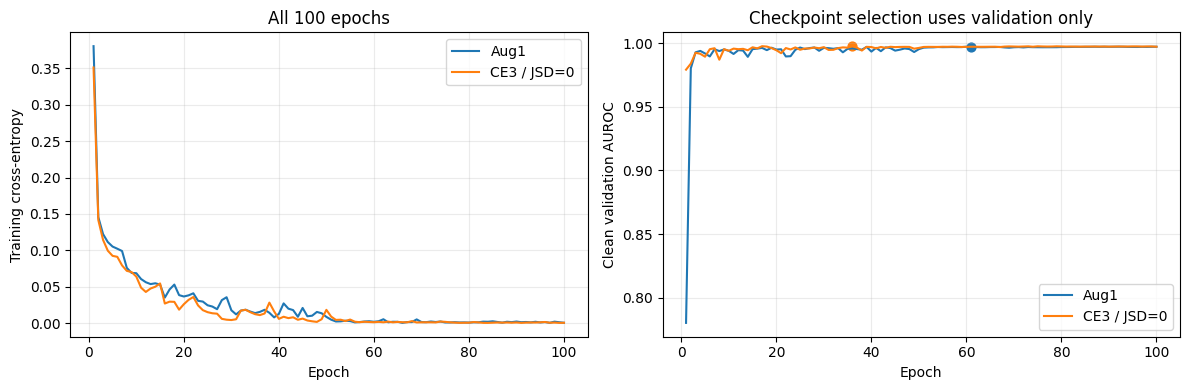

In [56]:
import matplotlib.pyplot as plt
import pandas as pd
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mode, label in [('b64_aug1', 'Aug1'), ('b64_ce3_jsd0_full', 'CE3 / JSD=0')]:
    if RUN_STEP18_MATCHED:
        curve = pd.read_csv(STEP18_ROOT / mode / 'learning_curve.csv')
    else:
        curve = pd.DataFrame(STEP18_RECORDED['models'][mode]['curve'])
    axes[0].plot(curve.epoch, curve.train_loss, label=label)
    axes[1].plot(curve.epoch, curve.val_auroc, label=label)
    best = curve.iloc[curve.val_auroc.argmax()]
    axes[1].scatter([best.epoch], [best.val_auroc], s=40)
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=.25); ax.legend()
axes[0].set_ylabel('Training cross-entropy'); axes[0].set_title('All 100 epochs')
axes[1].set_ylabel('Clean validation AUROC'); axes[1].set_title('Checkpoint selection uses validation only')
fig.tight_layout(); plt.show()


## 6. External evaluation and uncertainty

In [ ]:
# Reuse completed Step 19 artifacts when the project folder is mounted in Colab.
import shutil
for filename in ('MD6329_Step19_Frozen_Evaluation_Input.zip', 'MD6329_Step19_Results.zip'):
    destination = Path('/content') / filename
    if not destination.exists():
        matches = list(PROJECT_ROOT.rglob(filename))
        if matches:
            shutil.copy2(matches[0], destination)
            print('Prepared', destination)

In [ ]:
from pathlib import Path
import json, hashlib, shutil, sys, zipfile
ROOT19=Path('/content/md6329_acjsd_recovery')
OUT19=ROOT19/'step19_results'
RUN_STEP19_RECOVERY=False  # Historical recovery only; unnecessary with the frozen input package.
RUN_STEP19_EVALUATION=False  # Set True for a fresh four-model evaluation; costs GPU time.
INPUT19=Path('/content/MD6329_Step19_Frozen_Evaluation_Input.zip')
print('Input archive exists:',INPUT19.exists())

In [ ]:
%pip -q install pydicom==2.4.4

In [ ]:
assert INPUT19.exists(), 'Upload MD6329_Step19_Frozen_Evaluation_Input.zip using the Files panel.'
ROOT19.mkdir(exist_ok=True)
with zipfile.ZipFile(INPUT19) as z:
    for name in z.namelist():
        assert not Path(name).is_absolute() and '..' not in Path(name).parts
    z.extractall(ROOT19)
sys.path.insert(0,str(ROOT19/'source'))
import torch,numpy as np
print({'torch':torch.__version__,'numpy':np.__version__,'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None})

In [ ]:
%%writefile /content/md6329_acjsd_recovery/source/review_statistics.py
"""Paired fixed-model uncertainty; no training or threshold selection.

External resampling unit is the patient (all images retained with multiplicity).
Source resampling is stratified by image label because patient IDs are unavailable.
Intervals are pointwise percentile 95% CIs; no multiplicity-adjusted claims.
"""
from pathlib import Path
import csv, json
import numpy as np

NAMES = ['plain','augmix','aug1','ce3']
METRICS = ['accuracy','auroc','balanced_accuracy','sensitivity','specificity','brier']
CONTRASTS = [('augmix','plain'),('aug1','plain'),('ce3','plain'),('augmix','ce3'),('ce3','aug1')]

class WeightedMetrics:
    def __init__(self, y, score):
        self.y=np.asarray(y,dtype=np.int64); self.s=np.asarray(score,dtype=np.float64)
        assert set(np.unique(self.y))=={0,1}
        assert np.isfinite(self.s).all() and ((self.s>=0)&(self.s<=1)).all()
        self.pred=self.s>=.5
        self.order=np.argsort(self.s,kind='stable')
        ss=self.s[self.order]
        self.starts=np.r_[0,np.flatnonzero(ss[1:]!=ss[:-1])+1]
    def __call__(self,w):
        y=self.y; w=np.asarray(w,dtype=np.float64)
        pos=w*y; neg=w*(1-y); p=pos.sum(); n=neg.sum()
        if p==0 or n==0: return np.full(6,np.nan)
        tp=(pos*self.pred).sum(); tn=(neg*~self.pred).sum()
        gp=np.add.reduceat(pos[self.order],self.starts)
        gn=np.add.reduceat(neg[self.order],self.starts)
        auc=np.sum(gp*(np.cumsum(gn)-.5*gn))/(p*n)
        return np.array([(tp+tn)/(p+n),auc,.5*(tp/p+tn/n),tp/p,tn/n,
                         np.sum(w*(self.s-y)**2)/(p+n)])

def ci_rows(draws, points, names, metrics, contrasts, scope, n, clusters):
    rows=[]
    def add(label, values, point):
        low,high=np.nanquantile(values,[.025,.975],axis=0)
        for j,m in enumerate(metrics):
            rows.append(dict(scope=scope,comparison=label,metric=m,estimate=float(point[j]),
                ci_low=float(low[j]),ci_high=float(high[j]),n_images=n,n_clusters=clusters,
                bootstrap_draws=len(values),valid_draws=int(np.isfinite(values[:,j]).sum())))
    for i,name in enumerate(names): add(name,draws[:,i],points[i])
    for a,b in contrasts:
        ia,ib=names.index(a),names.index(b)
        add(a+' minus '+b,draws[:,ia]-draws[:,ib],points[ia]-points[ib])
    return rows

def prediction_bootstrap(y,scores,patient_ids=None,draws=5000,seed=632919,scope='external_primary',contrasts=None):
    y=np.asarray(y); names=list(scores); funcs=[WeightedMetrics(y,scores[k]) for k in names]
    point=np.array([f(np.ones(len(y))) for f in funcs]); rng=np.random.default_rng(seed)
    if patient_ids is None:
        groups=[np.flatnonzero(y==c) for c in (0,1)]; k=len(y); inv=None
    else:
        unique,inv=np.unique(np.asarray(patient_ids),return_inverse=True); k=len(unique)
    sampled=np.empty((draws,len(names),6))
    for b in range(draws):
        if inv is not None:
            w=np.bincount(rng.integers(0,k,size=k),minlength=k)[inv]
        else:
            ix=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups])
            w=np.bincount(ix,minlength=len(y))
        sampled[b]=[f(w) for f in funcs]
        if (b+1)%1000==0: print(scope,'bootstrap',b+1,flush=True)
    contrasts=[(a,b) for a,b in (CONTRASTS if contrasts is None else contrasts) if a in names and b in names]
    rows=ci_rows(sampled,point,names,METRICS,contrasts,scope,len(y),k)
    return rows,sampled

def mean_cluster_bootstrap(values,patient_ids,names,metrics,contrasts,draws=5000,seed=632920,scope='localization'):
    values=np.asarray(values,dtype=float) # image x model x metric
    _,inv=np.unique(np.asarray(patient_ids),return_inverse=True); k=inv.max()+1
    rng=np.random.default_rng(seed); sampled=np.empty((draws,len(names),len(metrics)))
    for b in range(draws):
        w=np.bincount(rng.integers(0,k,size=k),minlength=k)[inv]
        sampled[b]=np.einsum('i,imj->mj',w,values)/w.sum()
    return ci_rows(sampled,values.mean(0),names,metrics,contrasts,scope,len(values),int(k)),sampled

def save_rows(path,rows):
    with Path(path).open('w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)

def analyze(out,draws=5000):
    out=Path(out); data=np.load(out/'four_way_predictions.npz'); rows=[]; distributions={}
    names=[n for n in NAMES if n+'_scores' in data]
    for scope,sel in [('external_primary',data['primary_eligible']),('external_expanded',np.ones(len(data['labels']),bool))]:
        r,d=prediction_bootstrap(data['labels'][sel],{n:data[n+'_scores'][sel] for n in names},
            data['patient_ids'][sel],draws=draws,scope=scope)
        rows+=r;distributions[scope]=d
    with (out/'E_final_B64_localization_cases.csv').open(encoding='utf-8-sig') as f: loc=list(csv.DictReader(f))
    lm=['area_corrected_energy','pointing_hit']; ln=names+['center_prior']
    val=np.array([[[float(r[n+'_'+m]) for m in lm] for n in ln] for r in loc])
    contrasts=CONTRASTS+[('plain','center_prior'),('augmix','center_prior')]
    r,d=mean_cluster_bootstrap(val,[r['patient_id'] for r in loc],ln,lm,contrasts,draws,scope='localization')
    rows+=r;distributions['localization']=d
    with (out/'E_final_B64_occlusion_cases.csv').open(encoding='utf-8-sig') as f: occ=list(csv.DictReader(f))
    om=['mean_inside_minus_outside','blur_inside_minus_outside','both_positive_fraction']
    val=np.array([[[float(r[n+'_mean_inside_minus_outside']),float(r[n+'_blur_inside_minus_outside']),
                   float(float(r[n+'_mean_inside_minus_outside'])>0 and float(r[n+'_blur_inside_minus_outside'])>0)]
                  for n in names] for r in occ])
    r,d=mean_cluster_bootstrap(val,[r['patient_id'] for r in occ],names,om,CONTRASTS,draws,seed=632921,scope='occlusion')
    rows+=r;distributions['occlusion']=d
    save_rows(out/'paired_confidence_intervals.csv',rows)
    np.savez_compressed(out/'bootstrap_distributions.npz',**distributions)
    (out/'statistical_protocol.json').write_text(json.dumps(dict(draws=draws,interval='pointwise percentile 95%',
        external_unit='patient',paired=True,training_uncertainty_included=False,multiplicity_adjusted=False,
        limits='Conditional on these frozen models and this retrospectively reused external dataset. No medical causality.',
        prediction_seed=632919,localization_seed=632920,occlusion_seed=632921),indent=2))
    return rows

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('out');p.add_argument('--draws',type=int,default=5000)
    a=p.parse_args();analyze(a.out,a.draws)


In [ ]:
%%writefile /content/md6329_acjsd_recovery/source/review_explanations.py
"""Step 19: extend the frozen Step 16 explanation audit to four models.
The original sampling, Grad-CAM target, masks, occlusion, and seeds are retained.
Only four-model artifact export and a matched display are added.
"""
from b64_external_audit import *

def plot_four_way(out, selected, records, images, masks, cams, prediction):
    # Deterministic quantiles of AC-JSD minus plain localization, including failures.
    delta = [ext.energy_and_pointing(cams['augmix'][i], masks[i])[0] -
             ext.energy_and_pointing(cams['plain'][i], masks[i])[0] for i in range(len(selected))]
    order = np.argsort(delta)
    chosen = order[np.linspace(0,len(order)-1,6,dtype=int)]
    names = ['plain','aug1','ce3','augmix']
    fig, ax = plt.subplots(6,5,figsize=(12,13))
    for r,i in enumerate(chosen):
        for c,name in enumerate(['image']+names):
            ax[r,c].imshow(images[i],cmap='gray',vmin=0,vmax=1)
            if name!='image': ax[r,c].imshow(cams[name][i],cmap='jet',alpha=.42,vmin=0,vmax=1)
            ax[r,c].contour(masks[i].astype(float),levels=[.5],colors=['lime'],linewidths=.7)
            title = f'Case {i}; delta={delta[i]:+.3f}' if name=='image' else f'{name}: p={prediction[name]["scores"][selected[i]]:.3f}'
            ax[r,c].set_title(title,fontsize=8); ax[r,c].axis('off')
    fig.tight_layout(); fig.savefig(out/'four_way_gradcam.pdf',bbox_inches='tight'); plt.close(fig)

def paired_explain(models: dict[str, torch.nn.Module], zip_path: Path, members: dict[str, str], records: list[dict], prediction: dict, out: Path, device: torch.device) -> dict:
    positives = [i for i, row in enumerate(records) if row["class_name"] == "Lung Opacity"]
    selected = sorted(positives, key=lambda i: hashlib.sha256(f"{EXPLANATION_SEED}|{records[i]['subset_img_id']}".encode()).hexdigest())[:300]
    selected_records = [records[i] for i in selected]
    cams_parts = {name: [] for name in models}
    images_parts, masks_all = [], []
    with zipfile.ZipFile(zip_path) as archive:
        for start in range(0, len(selected_records), 24):
            x, masks, _ = load_batch64(archive, members, selected_records[start:start + 24])
            for name, model in models.items():
                cams, _ = baseline.gradcam(model, x, device)
                cams_parts[name].append(cams)
            images_parts.append((x[:, 0].numpy() * 0.5 + 0.5).clip(0, 1))
            masks_all.extend(masks)
    cams = {name: np.concatenate(parts) for name, parts in cams_parts.items()}
    images = np.concatenate(images_parts)
    center = center_prior64()
    localization_rows = []
    for local_i, global_i in enumerate(selected):
        row = {
            "subset_img_id": records[global_i]["subset_img_id"],
            "patient_id": records[global_i]["patient_id"],
            "box_area_fraction": float(masks_all[local_i].mean()),
        }
        for name in models:
            corrected, pointing, zero = ext.energy_and_pointing(cams[name][local_i], masks_all[local_i])
            row.update({
                f"{name}_score": float(prediction[name]["scores"][global_i]),
                f"{name}_area_corrected_energy": corrected,
                f"{name}_pointing_hit": pointing,
                f"{name}_zero_cam": zero,
            })
        center_corrected, center_pointing, _ = ext.energy_and_pointing(center, masks_all[local_i])
        row["center_prior_area_corrected_energy"] = center_corrected
        row["center_prior_pointing_hit"] = center_pointing
        row["difference_area_corrected_energy"] = row["augmix_area_corrected_energy"] - row["plain_area_corrected_energy"]
        row["difference_pointing_hit"] = row["augmix_pointing_hit"] - row["plain_pointing_hit"]
        localization_rows.append(row)
    save_csv(out / "E_final_B64_localization_cases.csv", localization_rows)

    rng = np.random.default_rng(EXPLANATION_SEED)
    occlusion_rows = []
    with zipfile.ZipFile(zip_path) as archive:
        for local_i, global_i in enumerate(selected[:120]):
            x, masks, _ = load_batch64(archive, members, [records[global_i]])
            outside = translated_masks64(masks[0], 20, rng)
            if not outside:
                continue
            row = {"subset_img_id": records[global_i]["subset_img_id"], "patient_id": records[global_i]["patient_id"]}
            for name, model in models.items():
                values = model_occlusion(model, x[0], masks[0], outside, device)
                for key, value in values.items():
                    row[f"{name}_{key}"] = value
            for mode in ("mean", "blur"):
                key = f"{mode}_inside_minus_outside"
                row[f"difference_{key}"] = row[f"augmix_{key}"] - row[f"plain_{key}"]
            occlusion_rows.append(row)
            if (local_i + 1) % 20 == 0:
                print(f"B64 E_final occlusion: {local_i + 1}/120", flush=True)
    save_csv(out / "E_final_B64_occlusion_cases.csv", occlusion_rows)

    localization = {name: summarize_localization(localization_rows, name) for name in models}
    localization["augmix_minus_plain"] = {
        key: localization["augmix"][key] - localization["plain"][key]
        for key in ("area_corrected_energy_mean", "area_corrected_energy_median", "pointing_hit_rate", "zero_cam_rate")
    }
    occlusion = {}
    for name in models:
        occlusion[name] = {
            "n": len(occlusion_rows),
            "mean_inside_minus_outside": float(np.mean([r[f"{name}_mean_inside_minus_outside"] for r in occlusion_rows])),
            "blur_inside_minus_outside": float(np.mean([r[f"{name}_blur_inside_minus_outside"] for r in occlusion_rows])),
            "both_positive_fraction": float(np.mean([
                r[f"{name}_mean_inside_minus_outside"] > 0 and r[f"{name}_blur_inside_minus_outside"] > 0
                for r in occlusion_rows
            ])),
        }
    occlusion["augmix_minus_plain"] = {
        key: occlusion["augmix"][key] - occlusion["plain"][key]
        for key in ("mean_inside_minus_outside", "blur_inside_minus_outside", "both_positive_fraction")
    }
    sanity = {}
    with zipfile.ZipFile(zip_path) as archive:
        x50, _, _ = load_batch64(archive, members, selected_records[:50])
    for offset, (name, model) in enumerate(models.items()):
        baseline.seed_all(EXPLANATION_SEED + 10 + offset)
        randomized = copy.deepcopy(model).cpu()
        randomized.apply(ext.reset_parameters)
        randomized.to(device).eval()
        random_cams, _ = baseline.gradcam(randomized, x50, device)
        similarity = baseline.cosine_rows(cams[name][:50], random_cams)
        sanity[name] = {
            "n": 50,
            "trained_vs_fully_randomized_cam_cosine_mean": float(similarity.mean()),
            "trained_vs_fully_randomized_cam_cosine_median": float(np.median(similarity)),
        }
    np.savez_compressed(
        out / "E_final_B64_explanations.npz",
        selected_indices=np.array(selected), images=images, masks=np.stack(masks_all),
        **{name+"_cams": value for name,value in cams.items()},
    )
    plot_examples(out, selected, records, images, masks_all, cams, prediction)
    plot_four_way(out, selected, records, images, masks_all, cams, prediction)
    summary = {
        "selection": {"seed": EXPLANATION_SEED, "n_localization": 300, "n_occlusion": len(occlusion_rows), "same_cases_and_settings": True},
        "localization": localization,
        "matched_occlusion": occlusion,
        "center_prior": {
            "area_corrected_energy_mean": float(np.mean([r["center_prior_area_corrected_energy"] for r in localization_rows])),
            "pointing_hit_rate": float(np.mean([r["center_prior_pointing_hit"] for r in localization_rows])),
        },
        "randomization_sanity": sanity,
        "limits": [
            "public bounding boxes are coarse rather than pixel masks",
            "Grad-CAM and occlusion provide region-dependence evidence, not medical causality",
            "the historical E_final was previously opened and cannot support candidate selection",
        ],
    }
    save_json(out / "E_final_B64_explainability_summary.json", summary)
    return summary


In [ ]:
%%writefile /content/md6329_acjsd_recovery/source/review_completion.py
"""Frozen four-way B64 external ablation and explanation artifact completion.

Inputs are the exact historical checkpoints. No optimization, fitting, threshold
selection or candidate selection occurs here. External data were previously seen.
"""
from pathlib import Path
import argparse, hashlib, json, platform, time, zipfile
import numpy as np
import torch
import b64_augmix as model_code
import b64_external_audit as audit
import external_diagnosis as ext
import baseline
from review_explanations import paired_explain
from review_statistics import analyze

HASHES = {
 'plain':'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f',
 'augmix':'cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873',
 'aug1':'54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c',
 'ce3':'f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97'}

def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1048576),b''):h.update(b)
    return h.hexdigest()

def geometry_audit(files,members,records,out):
    selected=sorted([r for r in records if r['target']==1],
        key=lambda r:hashlib.sha256(f"{audit.EXPLANATION_SEED}|{r['subset_img_id']}".encode()).hexdigest())[:300]
    rows=[]
    with zipfile.ZipFile(files['images']) as z:
        for r in selected:
            image,g=audit.read_dicom64(z,members[r['sop_instance_uid']])
            match=all(int(b['image_height'])==g['height'] and int(b['image_width'])==g['width'] for b in r['boxes'])
            mask=audit.mask_for_boxes64(r['boxes'],g)
            rows.append(dict(subset_img_id=r['subset_img_id'],height=g['height'],width=g['width'],
                annotation_dimensions_match=match,mask_pixels=int(mask.sum()),box_count=len(r['boxes'])))
    audit.save_csv(out/'box_geometry_audit.csv',rows)
    assert all(r['annotation_dimensions_match'] and r['mask_pixels']>0 for r in rows), 'Box geometry failed: stop rather than interpret misaligned CAMs.'
    return dict(n=len(rows),dimension_mismatches=0,empty_masks=0,
                preprocessing='same center-square crop, original x/y box coordinates, floor/ceil rasterization')

def run(root,checkpoints,out,draws=5000):
    root,checkpoints,out=map(Path,(root,checkpoints,out));out.mkdir(parents=True,exist_ok=True)
    weights={n:checkpoints/(n+'.pt') for n in HASHES}
    actual={n:sha(p) for n,p in weights.items()}
    assert actual==HASHES, actual
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    baseline.seed_all(632901)
    plan=dict(weights_sha256=actual,threshold=.5,external_role='retrospective audit, no tuning',
        n_localization=300,n_occlusion_candidates=120,occlusion_outside_positions=20,
        bootstrap_draws=draws,bootstrap_unit='patient',checkpoint_selection='already frozen source validation AUROC',
        device=str(device),gpu=torch.cuda.get_device_name(0) if device.type=='cuda' else None,
        torch=torch.__version__,numpy=np.__version__,python=platform.python_version(),started_utc=audit.utcnow())
    plan['evaluation_source_sha256']={p.name:sha(p) for p in Path(__file__).parent.glob('*.py')}
    planfile=out/'evaluation_plan.json'
    if planfile.exists():
        previous=json.loads(planfile.read_text());assert previous['weights_sha256']==actual
    else:audit.save_json(planfile,plan)
    models={}
    for n,p in weights.items():
        m=model_code.ResNet18().to(device)
        m.load_state_dict(torch.load(p,map_location=device,weights_only=False)['model_state']);m.eval();models[n]=m
    # Recover raw source predictions for AC-JSD and verify the archived controls.
    arrays=model_code.load_arrays(model_code.obtain_data(root/'md6329_step15_b64_augmix'),include_test=True)
    loader=model_code.make_loader(arrays['test_images'],arrays['test_labels'],128,False,model_code.SEED)
    cached=np.load(root/'source_statistics/source_predictions.npz')
    source_scores={'b28_scores':cached['b28_scores']}
    for n,m in models.items():
        _,scores,labels=model_code.predict(m,loader,device)
        assert np.array_equal(labels.reshape(-1),cached['labels'].reshape(-1))
        if n+'_scores' in cached:
            np.testing.assert_allclose(scores,cached[n+'_scores'],atol=2e-6,rtol=2e-6)
        source_scores[n+'_scores']=scores
    np.savez_compressed(out/'source_predictions.npz',labels=labels,**source_scores)
    from source_uncertainty import run as source_ci
    source_ci(out/'source_predictions.npz',out/'source_uncertainty')
    audit.save_json(out/'source_metrics.json',{n:model_code.metrics(labels,s) for n,s in source_scores.items()})
    files=ext.obtain_rsna(root/'md6329_step10_resnet_reproduction')
    records,opening=audit.verify_final_records(files);members=ext.zip_members(files['images'])
    audit.save_json(out/'external_opening_audit.json',opening)
    # Keep the complete patient/case/label correspondence needed for independent verification.
    audit.save_csv(out/'case_manifest.csv',[{k:r[k] for k in ('patient_id','subset_img_id','sop_instance_uid','class_name','target','primary_eligible')} for r in records])
    geometry=geometry_audit(files,members,records,out)
    predfile=out/'four_way_predictions.npz'
    if predfile.exists():
        data=np.load(predfile)
        assert np.array_equal(data['subset_img_ids'],np.array([r['subset_img_id'] for r in records]))
        pred={n:{'scores':data[n+'_scores'],'logits':data[n+'_logits']} for n in models}
    else:
        pred=audit.paired_predict(models,files['images'],members,records,device)
        np.savez_compressed(predfile,labels=np.array([r['target'] for r in records]),
            primary_eligible=np.array([r['primary_eligible'] for r in records],bool),
            patient_ids=np.array([r['patient_id'] for r in records]),subset_img_ids=np.array([r['subset_img_id'] for r in records]),
            **{n+'_'+k:v for n,d in pred.items() for k,v in d.items()})
    metrics={n:ext.prediction_metrics(records,pred[n]['scores'],.5) for n in models}
    audit.save_json(out/'four_way_metrics.json',metrics)
    print('FOUR_WAY_PREDICTION_METRICS',json.dumps(metrics),flush=True)
    xfile=out/'E_final_B64_explainability_summary.json'
    xai=json.loads(xfile.read_text()) if xfile.exists() else paired_explain(models,files['images'],members,records,pred,out,device)
    intervals=analyze(out,draws)
    summary=dict(status='complete',completed_utc=audit.utcnow(),weights_sha256=actual,
        prediction_metrics=metrics,explainability=xai,geometry_audit=geometry,interval_rows=len(intervals),
        external_tuning=False,causality_established=False)
    audit.save_json(out/'review_completion_summary.json',summary)
    archive=out.parent/'MD6329_Step19_Results.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
        for p in out.rglob('*'):
            if p.is_file():z.write(p,p.relative_to(out))
    print('STEP19_COMPLETE',str(archive),flush=True)
    return summary

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',required=True);p.add_argument('--checkpoints',required=True)
    p.add_argument('--out',required=True);p.add_argument('--draws',type=int,default=5000)
    a=p.parse_args();run(a.root,a.checkpoints,a.out,a.draws)


In [ ]:
%%writefile /content/md6329_acjsd_recovery/source/recover_frozen_checkpoint.py
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict
import hashlib, json, platform, sys, time, zipfile, subprocess
import numpy as np
import torch
import b64_augmix as s
import b64_external_audit as audit
from training_recovery import train_recovery, ORIGINAL_SHA256

ROOT=Path('/content/md6329_acjsd_recovery')
DATA=ROOT/'md6329_step15_b64_augmix'
OUT=ROOT/'acjsd'
PLAIN=ROOT/'plain'
OUT.mkdir(exist_ok=True)
assert torch.cuda.is_available()
assert torch.cuda.get_device_name(0)=='Tesla T4'
assert torch.__version__=='2.11.0+cu130'
assert np.__version__=='2.1.3'
assert s.sha256(PLAIN/'best_weights.pt')=='c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f'
assert s.md5(s.obtain_data(DATA))==s.DATA_MD5
env={'started_utc':datetime.now(timezone.utc).isoformat(),'torch':torch.__version__,'numpy':np.__version__,
     'python':sys.version,'cuda':torch.version.cuda,'gpu':torch.cuda.get_device_name(0),'cudnn':torch.backends.cudnn.version(),
     'source_sha256':{p.name:s.sha256(p) for p in (ROOT/'source').glob('*.py')},
     'original_expected_sha256':ORIGINAL_SHA256,
     'purpose':'Recover exact historical checkpoint if reproducible; otherwise archive a separate new 100-epoch fixed-protocol run. Never select or tune using external results.'}
s.save_json(ROOT/'execution_environment.json',env)
print(json.dumps(env,indent=2),flush=True)
config=asdict(s.TrainingConfig(mode='b64_augmix'))
if not (OUT/'protocol_before_training.json').exists():
    s.save_json(OUT/'protocol_before_training.json',{'config':config,'dataset_md5':s.DATA_MD5,'seed':s.SEED,
        'purpose':env['purpose'],'maximum_replay_epochs':100,
        'early_end_rule':'Only exact SHA256 equality to the already frozen historical weight binary; not metric-based early stopping.'})

# Dataset download is an independent process: no training RNG is touched.
download_log=(ROOT/'download_rsna.log').open('a')
downloader=subprocess.Popen([sys.executable,str(ROOT/'source/download_rsna.py')],stdout=download_log,stderr=subprocess.STDOUT)
summary=train_recovery(DATA,OUT,'b64_augmix')
print('RECONSTRUCTION_TRAINING',json.dumps(summary),flush=True)
with zipfile.ZipFile('/content/MD6329_ACJSD_frozen_model.zip','w',zipfile.ZIP_DEFLATED,compresslevel=1) as z:
    for p in OUT.iterdir():
        if p.is_file():z.write(p,'acjsd/'+p.name)
print('FROZEN_MODEL_ARCHIVED',flush=True)

assert s.sha256(OUT/'best_weights.pt') == ORIGINAL_SHA256, 'Recovered weights differ: do not merge with historical results.'
print('EXACT_CHECKPOINT_READY_FOR_DOWNLOAD',flush=True)


In [ ]:
%%writefile /content/md6329_acjsd_recovery/source/source_uncertainty.py
"""Recompute source-test intervals from aligned frozen prediction arrays."""
from pathlib import Path
import numpy as np
from review_statistics import prediction_bootstrap,save_rows

def run(source_archive,out):
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    data=np.load(source_archive);y=data['labels'].reshape(-1)
    assert len(y)==624 and int(y.sum())==390
    names=[n for n in ('b28','plain','aug1','ce3','augmix') if n+'_scores' in data]
    contrasts=[('plain','b28'),('aug1','plain'),('ce3','plain'),('ce3','aug1')]
    if 'augmix' in names:contrasts += [('augmix','plain'),('augmix','ce3')]
    rows,distributions=prediction_bootstrap(y,{n:data[n+'_scores'] for n in names},draws=5000,seed=632922,
        scope='source_test',contrasts=contrasts)
    save_rows(out/'source_paired_intervals.csv',rows)
    np.savez_compressed(out/'bootstrap_distributions.npz',draws=distributions)
    return rows


In [ ]:
# Optional CPU-only recomputation; frozen input contains the completed five-model predictions.
RUN_SOURCE_BOOTSTRAP=False
if RUN_SOURCE_BOOTSTRAP:
    from source_uncertainty import run as source_ci
    source_rows=source_ci(ROOT19/'source_statistics/source_predictions.npz',ROOT19/'source_statistics')
    for row in source_rows:
        if ' minus ' in row['comparison'] and row['metric'] in ('accuracy','auroc'): print(row)
else:
    print('Completed five-model intervals are recorded below and in results/source_uncertainty/.')

Completed locally on CPU using archived frozen predictions, 5000 paired class-stratified image draws.
B64 plain - B28: accuracy +4.33 pp, 95% CI [1.92,6.57]; AUROC +.0307, CI [.0149,.0481].
Aug1 - plain: accuracy +.80 pp, CI [-1.12,2.88]; AUROC +.0007, CI [-.0062,.0080].
AC-JSD is not included until its raw prediction artifact is recovered.


In [ ]:
from review_completion import HASHES,sha
if RUN_STEP19_RECOVERY:
    import subprocess
    subprocess.run([sys.executable,'-u',str(ROOT19/'source/recover_frozen_checkpoint.py')],check=True)
    shutil.copy2(ROOT19/'acjsd/best_weights.pt',ROOT19/'checkpoints/augmix.pt')
for name,expected in HASHES.items():
    assert sha(ROOT19/'checkpoints'/f'{name}.pt')==expected
print('All four frozen checkpoint identities verified.')

In [ ]:
# Run immediately after recovery, before the long external audit.
from google.colab import files
frozen_archive=Path('/content/MD6329_ACJSD_frozen_model.zip')
if frozen_archive.exists(): files.download(str(frozen_archive))

In [ ]:
if RUN_STEP19_EVALUATION:
    from review_completion import run
    result19=run(ROOT19,ROOT19/'checkpoints',OUT19,draws=5000)
else:
    print('Fresh inference not launched. Recorded results below come from the completed Colab execution.')

In [ ]:
# To inspect downloaded artifacts in a new session, upload MD6329_Step19_Results.zip first.
result_archive=Path('/content/MD6329_Step19_Results.zip')
if result_archive.exists() and not (OUT19/'review_completion_summary.json').exists():
    OUT19.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(result_archive) as z:
        assert all(not Path(n).is_absolute() and '..' not in Path(n).parts for n in z.namelist())
        z.extractall(OUT19)
summary19=OUT19/'review_completion_summary.json'
if summary19.exists():
    print(summary19.read_text())
    import pandas as pd
    display(pd.read_csv(OUT19/'paired_confidence_intervals.csv'))
else:
    print('Upload the completed result archive for interactive inspection, or use the recorded tables below.')

In [ ]:
artifact19=OUT19.parent/'MD6329_Step19_Results.zip'
if artifact19.exists():
    from google.colab import files
    files.download(str(artifact19))
else: print('No completed Step 19 result archive yet.')

In [ ]:
# Recorded artifact, imported from the completed run; this cell does not perform inference.
STEP19_RECORDED = {'summary': {'status': 'complete', 'completed_utc': '2026-10-23T16:10:08.285921+00:00', 'weights_sha256': {'plain': 'c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f', 'augmix': 'cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873', 'aug1': '54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c', 'ce3': 'f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97'}, 'prediction_metrics': {'plain': {'primary_normal_vs_lung_opacity_argmax': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.8056999934180215, 'balanced_accuracy': 0.7963593876060586, 'auroc': 0.8720383652574729, 'average_precision': 0.8273005962405511, 'sensitivity': 0.7369572008747266, 'specificity': 0.8557615743373905, 'brier': 0.17237954636188949, 'tn': 7523, 'fp': 1268, 'fn': 1684, 'tp': 4718}, 'primary_normal_vs_lung_opacity_source_youden': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.8056999934180215, 'balanced_accuracy': 0.7963593876060586, 'auroc': 0.8720383652574729, 'average_precision': 0.8273005962405511, 'sensitivity': 0.7369572008747266, 'specificity': 0.8557615743373905, 'brier': 0.17237954636188949, 'tn': 7523, 'fp': 1268, 'fn': 1684, 'tp': 4718}, 'all_with_abnormal_nonopacity_as_negative_argmax': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.696944797191305, 'balanced_accuracy': 0.710663952881895, 'auroc': 0.7700890889621733, 'average_precision': 0.47937208712760115, 'sensitivity': 0.7369572008747266, 'specificity': 0.6843707048890634, 'brier': 0.2740835992939299, 'tn': 13942, 'fp': 6430, 'fn': 1684, 'tp': 4718}, 'all_with_abnormal_nonopacity_as_negative_source_youden': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.696944797191305, 'balanced_accuracy': 0.710663952881895, 'auroc': 0.7700890889621733, 'average_precision': 0.47937208712760115, 'sensitivity': 0.7369572008747266, 'specificity': 0.6843707048890634, 'brier': 0.2740835992939299, 'tn': 13942, 'fp': 6430, 'fn': 1684, 'tp': 4718}, 'abnormal_nonopacity_n': 11581, 'abnormal_nonopacity_false_positive_rate_argmax': 0.44573007512304635, 'abnormal_nonopacity_false_positive_rate_source_youden': 0.44573007512304635, 'abnormal_nonopacity_mean_pneumonia_probability': 0.44909921288490295}, 'augmix': {'primary_normal_vs_lung_opacity_argmax': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.8093200816165339, 'balanced_accuracy': 0.8164033083734816, 'auroc': 0.9011850963278558, 'average_precision': 0.8701954149136358, 'sensitivity': 0.8614495470165573, 'specificity': 0.7713570697304061, 'brier': 0.16624484740944465, 'tn': 6781, 'fp': 2010, 'fn': 887, 'tp': 5515}, 'primary_normal_vs_lung_opacity_source_youden': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.8093200816165339, 'balanced_accuracy': 0.8164033083734816, 'auroc': 0.9011850963278558, 'average_precision': 0.8701954149136358, 'sensitivity': 0.8614495470165573, 'specificity': 0.7713570697304061, 'brier': 0.16624484740944465, 'tn': 6781, 'fp': 2010, 'fn': 887, 'tp': 5515}, 'all_with_abnormal_nonopacity_as_negative_argmax': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.6214984686636289, 'balanced_accuracy': 0.7037711116194116, 'auroc': 0.789921690391888, 'average_precision': 0.5142881330123242, 'sensitivity': 0.8614495470165573, 'specificity': 0.5460926762222659, 'brier': 0.34615845028860825, 'tn': 11125, 'fp': 9247, 'fn': 887, 'tp': 5515}, 'all_with_abnormal_nonopacity_as_negative_source_youden': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.6214984686636289, 'balanced_accuracy': 0.7037711116194116, 'auroc': 0.789921690391888, 'average_precision': 0.5142881330123242, 'sensitivity': 0.8614495470165573, 'specificity': 0.5460926762222659, 'brier': 0.34615845028860825, 'tn': 11125, 'fp': 9247, 'fn': 887, 'tp': 5515}, 'abnormal_nonopacity_n': 11581, 'abnormal_nonopacity_false_positive_rate_argmax': 0.6249028581296951, 'abnormal_nonopacity_false_positive_rate_source_youden': 0.6249028581296951, 'abnormal_nonopacity_mean_pneumonia_probability': 0.6233229041099548}, 'aug1': {'primary_normal_vs_lung_opacity_argmax': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.7917461989073915, 'balanced_accuracy': 0.8039764742639754, 'auroc': 0.8965214487808472, 'average_precision': 0.8566955908938185, 'sensitivity': 0.8817557013433303, 'specificity': 0.7261972471846206, 'brier': 0.1852263105086212, 'tn': 6384, 'fp': 2407, 'fn': 757, 'tp': 5645}, 'primary_normal_vs_lung_opacity_source_youden': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.7917461989073915, 'balanced_accuracy': 0.8039764742639754, 'auroc': 0.8965214487808472, 'average_precision': 0.8566955908938185, 'sensitivity': 0.8817557013433303, 'specificity': 0.7261972471846206, 'brier': 0.1852263105086212, 'tn': 6384, 'fp': 2407, 'fn': 757, 'tp': 5645}, 'all_with_abnormal_nonopacity_as_negative_argmax': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.5948681556734146, 'balanced_accuracy': 0.6932340258140174, 'auroc': 0.7819902630504052, 'average_precision': 0.4794709998468764, 'sensitivity': 0.8817557013433303, 'specificity': 0.5047123502847045, 'brier': 0.37839708240040093, 'tn': 10282, 'fp': 10090, 'fn': 757, 'tp': 5645}, 'all_with_abnormal_nonopacity_as_negative_source_youden': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.5948681556734146, 'balanced_accuracy': 0.6932340258140174, 'auroc': 0.7819902630504052, 'average_precision': 0.4794709998468764, 'sensitivity': 0.8817557013433303, 'specificity': 0.5047123502847045, 'brier': 0.37839708240040093, 'tn': 10282, 'fp': 10090, 'fn': 757, 'tp': 5645}, 'abnormal_nonopacity_n': 11581, 'abnormal_nonopacity_false_positive_rate_argmax': 0.6634142129349797, 'abnormal_nonopacity_false_positive_rate_source_youden': 0.6634142129349797, 'abnormal_nonopacity_mean_pneumonia_probability': 0.6625106334686279}, 'ce3': {'primary_normal_vs_lung_opacity_argmax': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.7804910155992891, 'balanced_accuracy': 0.788604969703082, 'auroc': 0.8619177152544222, 'average_precision': 0.78575580630742, 'sensitivity': 0.8402061855670103, 'specificity': 0.7370037538391537, 'brier': 0.197866268196045, 'tn': 6479, 'fp': 2312, 'fn': 1023, 'tp': 5379}, 'primary_normal_vs_lung_opacity_source_youden': {'n': 15193, 'normal': 8791, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.7804910155992891, 'balanced_accuracy': 0.788604969703082, 'auroc': 0.8619177152544222, 'average_precision': 0.78575580630742, 'sensitivity': 0.8402061855670103, 'specificity': 0.7370037538391537, 'brier': 0.197866268196045, 'tn': 6479, 'fp': 2312, 'fn': 1023, 'tp': 5379}, 'all_with_abnormal_nonopacity_as_negative_argmax': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.6183984462538283, 'balanced_accuracy': 0.6944502359211451, 'auroc': 0.7641151449640866, 'average_precision': 0.4518654197631735, 'sensitivity': 0.8402061855670103, 'specificity': 0.5486942862752798, 'brier': 0.35503883129547203, 'tn': 11178, 'fp': 9194, 'fn': 1023, 'tp': 5379}, 'all_with_abnormal_nonopacity_as_negative_source_youden': {'n': 26774, 'normal': 20372, 'pneumonia': 6402, 'threshold': 0.5, 'accuracy': 0.6183984462538283, 'balanced_accuracy': 0.6944502359211451, 'auroc': 0.7641151449640866, 'average_precision': 0.4518654197631735, 'sensitivity': 0.8402061855670103, 'specificity': 0.5486942862752798, 'brier': 0.35503883129547203, 'tn': 11178, 'fp': 9194, 'fn': 1023, 'tp': 5379}, 'abnormal_nonopacity_n': 11581, 'abnormal_nonopacity_false_positive_rate_argmax': 0.5942492012779552, 'abnormal_nonopacity_false_positive_rate_source_youden': 0.5942492012779552, 'abnormal_nonopacity_mean_pneumonia_probability': 0.5947322249412537}}, 'explainability': {'selection': {'seed': 632916, 'n_localization': 300, 'n_occlusion': 89, 'same_cases_and_settings': True}, 'localization': {'plain': {'n': 300, 'area_corrected_energy_mean': -0.03360300222248043, 'area_corrected_energy_median': -0.032801538705825806, 'pointing_hit_rate': 0.06666666666666667, 'zero_cam_rate': 0.0}, 'augmix': {'n': 300, 'area_corrected_energy_mean': -0.016158570475580517, 'area_corrected_energy_median': -0.014167309505864978, 'pointing_hit_rate': 0.08666666666666667, 'zero_cam_rate': 0.0}, 'aug1': {'n': 300, 'area_corrected_energy_mean': 0.00875009076335194, 'area_corrected_energy_median': 0.0036465488374233246, 'pointing_hit_rate': 0.12, 'zero_cam_rate': 0.0}, 'ce3': {'n': 300, 'area_corrected_energy_mean': -0.02569643114383022, 'area_corrected_energy_median': -0.021741187665611506, 'pointing_hit_rate': 0.056666666666666664, 'zero_cam_rate': 0.0}, 'augmix_minus_plain': {'area_corrected_energy_mean': 0.017444431746899913, 'area_corrected_energy_median': 0.018634229199960828, 'pointing_hit_rate': 0.020000000000000004, 'zero_cam_rate': 0.0}}, 'matched_occlusion': {'plain': {'n': 89, 'mean_inside_minus_outside': 0.03685295915398089, 'blur_inside_minus_outside': 0.0074901350489521, 'both_positive_fraction': 0.21348314606741572}, 'augmix': {'n': 89, 'mean_inside_minus_outside': 0.09126694306869058, 'blur_inside_minus_outside': 0.008184563389742957, 'both_positive_fraction': 0.14606741573033707}, 'aug1': {'n': 89, 'mean_inside_minus_outside': 0.08088479791914845, 'blur_inside_minus_outside': -0.004121794052153245, 'both_positive_fraction': 0.14606741573033707}, 'ce3': {'n': 89, 'mean_inside_minus_outside': 0.02149901759433336, 'blur_inside_minus_outside': -0.0047968840085917015, 'both_positive_fraction': 0.15730337078651685}, 'augmix_minus_plain': {'mean_inside_minus_outside': 0.054413983914709696, 'blur_inside_minus_outside': 0.0006944283407908569, 'both_positive_fraction': -0.06741573033707865}}, 'center_prior': {'area_corrected_energy_mean': 0.10111346822308083, 'pointing_hit_rate': 0.13}, 'randomization_sanity': {'plain': {'n': 50, 'trained_vs_fully_randomized_cam_cosine_mean': 0.5500256706774235, 'trained_vs_fully_randomized_cam_cosine_median': 0.5838892161846161}, 'augmix': {'n': 50, 'trained_vs_fully_randomized_cam_cosine_mean': 0.42787534698843954, 'trained_vs_fully_randomized_cam_cosine_median': 0.4372885227203369}, 'aug1': {'n': 50, 'trained_vs_fully_randomized_cam_cosine_mean': 0.720923313498497, 'trained_vs_fully_randomized_cam_cosine_median': 0.7297480702400208}, 'ce3': {'n': 50, 'trained_vs_fully_randomized_cam_cosine_mean': 0.7045995211601257, 'trained_vs_fully_randomized_cam_cosine_median': 0.711063414812088}}, 'limits': ['public bounding boxes are coarse rather than pixel masks', 'Grad-CAM and occlusion provide region-dependence evidence, not medical causality', 'the historical E_final was previously opened and cannot support candidate selection']}, 'geometry_audit': {'n': 300, 'dimension_mismatches': 0, 'empty_masks': 0, 'preprocessing': 'same center-square crop, original x/y box coordinates, floor/ceil rasterization'}, 'interval_rows': 159, 'external_tuning': False, 'causality_established': False}, 'source_metrics': {'b28_scores': {'n': 624, 'threshold': 0.5, 'accuracy': 0.8621794871794872, 'balanced_accuracy': 0.8170940170940171, 'auroc': 0.9444115713346481, 'brier': 0.1275953340642247, 'ece10': 0.12666406310521633, 'sensitivity': 0.9974358974358974, 'specificity': 0.6367521367521367, 'tn': 149, 'fp': 85, 'fn': 1, 'tp': 389}, 'plain_scores': {'n': 624, 'threshold': 0.5, 'accuracy': 0.905448717948718, 'balanced_accuracy': 0.8824786324786325, 'auroc': 0.9750876616261231, 'brier': 0.07512212896688655, 'ece10': 0.06907218560958517, 'sensitivity': 0.9743589743589743, 'specificity': 0.7905982905982906, 'tn': 185, 'fp': 49, 'fn': 10, 'tp': 380}, 'augmix_scores': {'n': 624, 'threshold': 0.5, 'accuracy': 0.8862179487179487, 'balanced_accuracy': 0.8491452991452991, 'auroc': 0.9780024106947183, 'brier': 0.09923021153395431, 'ece10': 0.0914307024616462, 'sensitivity': 0.9974358974358974, 'specificity': 0.7008547008547008, 'tn': 164, 'fp': 70, 'fn': 1, 'tp': 389}, 'aug1_scores': {'n': 624, 'threshold': 0.5, 'accuracy': 0.9134615384615384, 'balanced_accuracy': 0.8863247863247863, 'auroc': 0.9757999123383738, 'brier': 0.07995536691204015, 'ece10': 0.06993992569354868, 'sensitivity': 0.9948717948717949, 'specificity': 0.7777777777777778, 'tn': 182, 'fp': 52, 'fn': 2, 'tp': 388}, 'ce3_scores': {'n': 624, 'threshold': 0.5, 'accuracy': 0.8942307692307693, 'balanced_accuracy': 0.8623931623931624, 'auroc': 0.9717839140916065, 'brier': 0.09153589265915767, 'ece10': 0.08175491436551775, 'sensitivity': 0.9897435897435898, 'specificity': 0.7350427350427351, 'tn': 172, 'fp': 62, 'fn': 4, 'tp': 386}}, 'verification': {'status': 'passed', 'prediction_metric_checks': 56, 'localization_case_model_checks': 1200, 'independently_recomputed_bootstrap_metric_checks': 320, 'source_acjsd_matches_historical_metrics': True, 'files_sha256': {'bootstrap_distributions.npz': 'db6ce0a8e2bd692d61a5dd3183b03e5ab52aebb3346ef2231f00a14a48234aa7', 'box_geometry_audit.csv': 'f7af68eac76baee5ebe8a610c07f941748a2f2a2c0f1e5400891405daa496036', 'case_manifest.csv': '24a9bb14fc3b060af3a339560ff039ff8beaf1e05b7beac5be31bec8f2fb9eee', 'evaluation_plan.json': '787dcf94460a7eb78bb460dbc3793d1a1b6f0b6834bc67a75feb5dd52b2922c7', 'external_opening_audit.json': 'd797fe0b22c30847984de755ffa00b87322df198651528a7c3322c064bf79bd7', 'E_final_B64_explainability_summary.json': 'd53c6c0d65690e03851b743f0c3bcab39111e5a1452c4f719dfaea583b89d941', 'E_final_B64_explanations.npz': 'c88fa010d9080c9345bd596c9bfdc589c0457b33bbf582b3d91dc6b6a3a547bc', 'E_final_B64_gradcam_examples.png': '32c0f69f98f9cf5dadc6ccb7334620db212a21bf32b8ab867efe81bc46d2a2e3', 'E_final_B64_localization_cases.csv': 'a7fbc292ad8ea6cf326f89e5ad431931cb7ef6e725cfea1fabbaf7fba373819f', 'E_final_B64_occlusion_cases.csv': '6de3cffe62b45fad9eca3fda3a0d8cfa9a5079dbfc114ad607ae8b96786b9285', 'four_way_gradcam.pdf': 'b651b8d801493a91733593046903e24b43a4fdefb09bbacedfa316a5ba1c6752', 'four_way_metrics.json': 'fd3fcc4d92191130d8edf6d633a98e5980924e578d5594d75c4accb7271154d0', 'four_way_predictions.npz': 'e053e8db16112581387c0433db7924dc9445934d51e4b4caa3ba4eb7b9019562', 'paired_confidence_intervals.csv': 'd718ad908e846dd376395653de7bcddb29611c8e1b5ddbf9d62fa0c893f0d9d6', 'review_completion_summary.json': '2cbb4dc72d8d620237216264338dfffc96b647d1c30317c6e4f0540758a5802c', 'source_metrics.json': 'ba76db50e81779d4c444b538b698f86187467e78472d69b1f6b4533122f0a347', 'source_predictions.npz': 'e83f91b8213da326b80b0d0084918ad2f0be8167a9da83acaa8e0a67e22dad04', 'statistical_protocol.json': '1042d23bbe34b51120d867ebfa9d657b53b941c928fc2f1b4c9732d7bab8b1a9'}}}
print(STEP19_RECORDED["summary"]["status"])

In [ ]:
# Complete interval tables imported from the saved evaluation artifacts.
STEP19_INTERVALS = [{'scope': 'external_primary', 'comparison': 'plain', 'metric': 'accuracy', 'estimate': '0.8056999934180215', 'ci_low': '0.7974557267993385', 'ci_high': '0.813489644262673', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'plain', 'metric': 'auroc', 'estimate': '0.8720383652574729', 'ci_low': '0.86373704236215', 'ci_high': '0.8798486398001228', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'plain', 'metric': 'balanced_accuracy', 'estimate': '0.7963593876060586', 'ci_low': '0.7863774141882379', 'ci_high': '0.805618719615035', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'plain', 'metric': 'sensitivity', 'estimate': '0.7369572008747266', 'ci_low': '0.718041229540396', 'ci_high': '0.7539553685115972', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'plain', 'metric': 'specificity', 'estimate': '0.8557615743373905', 'ci_low': '0.8478374417838062', 'ci_high': '0.8635846145257252', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'plain', 'metric': 'brier', 'estimate': '0.17237954636188949', 'ci_low': '0.16530100655435867', 'ci_high': '0.17971240634910005', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'accuracy', 'estimate': '0.8093200816165339', 'ci_low': '0.8013621848076886', 'ci_high': '0.8173218202110015', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'auroc', 'estimate': '0.9011850963278559', 'ci_low': '0.8939225123023413', 'ci_high': '0.9078360897270611', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'balanced_accuracy', 'estimate': '0.8164033083734816', 'ci_low': '0.8087727026349244', 'ci_high': '0.8238754599636027', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'sensitivity', 'estimate': '0.8614495470165573', 'ci_low': '0.8481948281583892', 'ci_high': '0.8732322547894562', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'specificity', 'estimate': '0.7713570697304061', 'ci_low': '0.7618772741055184', 'ci_high': '0.7810309277609206', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix', 'metric': 'brier', 'estimate': '0.16624484740944465', 'ci_low': '0.15929091417942876', 'ci_high': '0.17309850496411916', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'accuracy', 'estimate': '0.7917461989073915', 'ci_low': '0.7832918079209567', 'ci_high': '0.7999210358429982', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'auroc', 'estimate': '0.8965214487808472', 'ci_low': '0.889390476575943', 'ci_high': '0.9031220324216906', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'balanced_accuracy', 'estimate': '0.8039764742639754', 'ci_low': '0.7965956584136528', 'ci_high': '0.8109481793832934', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'sensitivity', 'estimate': '0.8817557013433303', 'ci_low': '0.8705840353948201', 'ci_high': '0.8921198729050616', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'specificity', 'estimate': '0.7261972471846206', 'ci_low': '0.7160398437867248', 'ci_high': '0.7363150869245725', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1', 'metric': 'brier', 'estimate': '0.1852263105086212', 'ci_low': '0.1779928517420725', 'ci_high': '0.1927916090932829', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'accuracy', 'estimate': '0.7804910155992891', 'ci_low': '0.7716634650407418', 'ci_high': '0.7888019688084764', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'auroc', 'estimate': '0.8619177152544221', 'ci_low': '0.8536326518610713', 'ci_high': '0.8694186038655282', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'balanced_accuracy', 'estimate': '0.788604969703082', 'ci_low': '0.7801108381725393', 'ci_high': '0.7965103707305979', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'sensitivity', 'estimate': '0.8402061855670103', 'ci_low': '0.8260511545647198', 'ci_high': '0.8532749773775923', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'specificity', 'estimate': '0.7370037538391537', 'ci_low': '0.7268425670386126', 'ci_high': '0.7466786811313353', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3', 'metric': 'brier', 'estimate': '0.197866268196045', 'ci_low': '0.19016761437546087', 'ci_high': '0.20598182532839754', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'accuracy', 'estimate': '0.00362008819851245', 'ci_low': '-0.003102099052367268', 'ci_high': '0.010264529171468292', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'auroc', 'estimate': '0.029146731070383014', 'ci_low': '0.025456395732449573', 'ci_high': '0.03301226198405557', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'balanced_accuracy', 'estimate': '0.020043920767423007', 'ci_low': '0.013406839168057188', 'ci_high': '0.0269025183189269', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'sensitivity', 'estimate': '0.12449234614183069', 'ci_low': '0.11345844641218145', 'ci_high': '0.13604789327019357', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'specificity', 'estimate': '-0.08440450460698445', 'ci_low': '-0.09184632853294272', 'ci_high': '-0.0770828346315156', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus plain', 'metric': 'brier', 'estimate': '-0.006134698952444839', 'ci_low': '-0.011708184638462233', 'ci_high': '-0.00045031683730055314', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'accuracy', 'estimate': '-0.013953794510629947', 'ci_low': '-0.021792856702877304', 'ci_high': '-0.006402066613926829', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'auroc', 'estimate': '0.02448308352337425', 'ci_low': '0.020280825097156417', 'ci_high': '0.028653717148280484', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'balanced_accuracy', 'estimate': '0.007617086657916827', 'ci_low': '0.00022460220591453698', 'ci_high': '0.015104597049472937', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'sensitivity', 'estimate': '0.14479850046860365', 'ci_low': '0.13294679084169442', 'ci_high': '0.15758427830363145', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'specificity', 'estimate': '-0.1295643271527699', 'ci_low': '-0.13802893757825443', 'ci_high': '-0.12115886477269908', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'aug1 minus plain', 'metric': 'brier', 'estimate': '0.01284676414673172', 'ci_low': '0.006535380276751569', 'ci_high': '0.019357112399032962', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'accuracy', 'estimate': '-0.025208977818732325', 'ci_low': '-0.031974309460115605', 'ci_high': '-0.01834400506794659', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'auroc', 'estimate': '-0.010120650003050846', 'ci_low': '-0.013823944954143713', 'ci_high': '-0.006572461408596368', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.007754417902976596', 'ci_low': '-0.014415025644357019', 'ci_high': '-0.0010888458314736434', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'sensitivity', 'estimate': '0.10324898469228372', 'ci_low': '0.09255813784261309', 'ci_high': '0.11410791282492828', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'specificity', 'estimate': '-0.1187578204982368', 'ci_low': '-0.12644088485861465', 'ci_high': '-0.11103586230064533', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus plain', 'metric': 'brier', 'estimate': '0.025486721834155512', 'ci_low': '0.019684447475807932', 'ci_high': '0.031306760338541094', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'accuracy', 'estimate': '0.028829066017244775', 'ci_low': '0.024001573368911504', 'ci_high': '0.033786110045536916', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'auroc', 'estimate': '0.03926738107343386', 'ci_low': '0.035981189624992596', 'ci_high': '0.042613610077916086', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'balanced_accuracy', 'estimate': '0.027798338670399603', 'ci_low': '0.022945296598546314', 'ci_high': '0.03274354608088318', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'sensitivity', 'estimate': '0.02124336144954697', 'ci_low': '0.014208426063355064', 'ci_high': '0.02851590896209794', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'specificity', 'estimate': '0.034353315891252345', 'ci_low': '0.027604717004430603', 'ci_high': '0.041214028001201615', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'augmix minus ce3', 'metric': 'brier', 'estimate': '-0.03162142078660035', 'ci_low': '-0.03557745341349089', 'ci_high': '-0.027751285357059244', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'accuracy', 'estimate': '-0.011255183308102379', 'ci_low': '-0.016521728946447024', 'ci_high': '-0.005951968212774548', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'auroc', 'estimate': '-0.034603733526425096', 'ci_low': '-0.03813202284842071', 'ci_high': '-0.031029536400129266', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'balanced_accuracy', 'estimate': '-0.015371504560893423', 'ci_low': '-0.020752337231287343', 'ci_high': '-0.010113139320496312', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'sensitivity', 'estimate': '-0.041549515776319934', 'ci_low': '-0.04927734997183886', 'ci_high': '-0.033860837551514415', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'specificity', 'estimate': '0.010806506654533088', 'ci_low': '0.0034078807509577286', 'ci_high': '0.01839755557344313', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_primary', 'comparison': 'ce3 minus aug1', 'metric': 'brier', 'estimate': '0.012639957687423792', 'ci_low': '0.008300613351706034', 'ci_high': '0.016988188720594814', 'n_images': '15193', 'n_clusters': '8265', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'accuracy', 'estimate': '0.696944797191305', 'ci_low': '0.6893851069007734', 'ci_high': '0.7044038617184242', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'auroc', 'estimate': '0.7700890889621733', 'ci_low': '0.7609051615342675', 'ci_high': '0.7791204535993477', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'balanced_accuracy', 'estimate': '0.710663952881895', 'ci_low': '0.7021006427416019', 'ci_high': '0.7189109806207359', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'sensitivity', 'estimate': '0.7369572008747266', 'ci_low': '0.718818466531157', 'ci_high': '0.7544960539701848', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'specificity', 'estimate': '0.6843707048890634', 'ci_low': '0.6741508447219693', 'ci_high': '0.6946328054255373', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'plain', 'metric': 'brier', 'estimate': '0.2740835992939299', 'ci_low': '0.267215724334459', 'ci_high': '0.2810275426929926', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'accuracy', 'estimate': '0.6214984686636289', 'ci_low': '0.6135735821946993', 'ci_high': '0.6293214639741229', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'auroc', 'estimate': '0.789921690391888', 'ci_low': '0.7810780419945943', 'ci_high': '0.798697552812133', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'balanced_accuracy', 'estimate': '0.7037711116194116', 'ci_low': '0.6969744278637823', 'ci_high': '0.7104227573036728', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'sensitivity', 'estimate': '0.8614495470165573', 'ci_low': '0.8489881309475484', 'ci_high': '0.873633419485758', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'specificity', 'estimate': '0.5460926762222659', 'ci_low': '0.5353884576738812', 'ci_high': '0.5570825808834278', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix', 'metric': 'brier', 'estimate': '0.34615845028860825', 'ci_low': '0.3388444313383479', 'ci_high': '0.35364815887761486', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'accuracy', 'estimate': '0.5948681556734146', 'ci_low': '0.5868375775549239', 'ci_high': '0.6029585947482055', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'auroc', 'estimate': '0.7819902630504052', 'ci_low': '0.7735556110660357', 'ci_high': '0.7902106309448697', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'balanced_accuracy', 'estimate': '0.6932340258140174', 'ci_low': '0.6870059810453722', 'ci_high': '0.6996374488346309', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'sensitivity', 'estimate': '0.8817557013433303', 'ci_low': '0.8706682070434868', 'ci_high': '0.8923263818309184', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'specificity', 'estimate': '0.5047123502847045', 'ci_low': '0.49394805371090944', 'ci_high': '0.5153622589182639', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1', 'metric': 'brier', 'estimate': '0.37839708240040093', 'ci_low': '0.3706279114651305', 'ci_high': '0.3860531641589319', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'accuracy', 'estimate': '0.6183984462538283', 'ci_low': '0.6106497867577424', 'ci_high': '0.6261062804140924', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'auroc', 'estimate': '0.7641151449640866', 'ci_low': '0.7552816895592942', 'ci_high': '0.7729118849870903', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'balanced_accuracy', 'estimate': '0.6944502359211451', 'ci_low': '0.6873390570272678', 'ci_high': '0.7013280516591933', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'sensitivity', 'estimate': '0.8402061855670103', 'ci_low': '0.8261973154143759', 'ci_high': '0.8533430416154272', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'specificity', 'estimate': '0.5486942862752798', 'ci_low': '0.5382359940459561', 'ci_high': '0.5593635560508627', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3', 'metric': 'brier', 'estimate': '0.35503883129547203', 'ci_low': '0.34760423267304513', 'ci_high': '0.362397591329205', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'accuracy', 'estimate': '-0.07544632852767608', 'ci_low': '-0.08130923859810255', 'ci_high': '-0.06981179202787965', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'auroc', 'estimate': '0.019832601429714658', 'ci_low': '0.015966665507152384', 'ci_high': '0.02372780818226319', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.006892841262483351', 'ci_low': '-0.01276238077565082', 'ci_high': '-0.0009015177687784152', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'sensitivity', 'estimate': '0.12449234614183069', 'ci_low': '0.11356360932830013', 'ci_high': '0.13603541782402004', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'specificity', 'estimate': '-0.1382780286667975', 'ci_low': '-0.14490576382614687', 'ci_high': '-0.13177740540438443', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus plain', 'metric': 'brier', 'estimate': '0.07207485099467836', 'ci_low': '0.06726593538815526', 'ci_high': '0.07696236678121407', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'accuracy', 'estimate': '-0.10207664151789042', 'ci_low': '-0.10860593101694854', 'ci_high': '-0.0956198479976736', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'auroc', 'estimate': '0.01190117408823188', 'ci_low': '0.00765075880538372', 'ci_high': '0.016213739577273054', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.017429927067877604', 'ci_low': '-0.02376264010983412', 'ci_high': '-0.010841274680238355', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'sensitivity', 'estimate': '0.14479850046860365', 'ci_low': '0.13307306982068656', 'ci_high': '0.15710380108746205', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'specificity', 'estimate': '-0.17965835460435886', 'ci_low': '-0.18676720479340864', 'ci_high': '-0.17246918220864652', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'aug1 minus plain', 'metric': 'brier', 'estimate': '0.10431348310647104', 'ci_low': '0.09871089405265839', 'ci_high': '0.11015800814557616', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'accuracy', 'estimate': '-0.07854635093747664', 'ci_low': '-0.08412808264502213', 'ci_high': '-0.07315132668374377', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'auroc', 'estimate': '-0.005973943998086706', 'ci_low': '-0.009628510979081458', 'ci_high': '-0.0021274528668239856', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.016213716960749913', 'ci_low': '-0.021852207086671786', 'ci_high': '-0.010476031467119524', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'sensitivity', 'estimate': '0.10324898469228372', 'ci_low': '0.09303437799443327', 'ci_high': '0.11415571539697959', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'specificity', 'estimate': '-0.13567641861378354', 'ci_low': '-0.1418936885924491', 'ci_high': '-0.12965103407195314', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus plain', 'metric': 'brier', 'estimate': '0.08095523200154214', 'ci_low': '0.0764021318040683', 'ci_high': '0.08558857916932638', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'accuracy', 'estimate': '0.0031000224098005624', 'ci_low': '-0.001196276450414804', 'ci_high': '0.007255700197461133', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'auroc', 'estimate': '0.025806545427801364', 'ci_low': '0.022319933903218202', 'ci_high': '0.02921633934155894', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'balanced_accuracy', 'estimate': '0.009320875698266562', 'ci_low': '0.004980761452439006', 'ci_high': '0.013492202395927085', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'sensitivity', 'estimate': '0.02124336144954697', 'ci_low': '0.013964574060798415', 'ci_high': '0.028370009858177666', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'specificity', 'estimate': '-0.0026016100530139585', 'ci_low': '-0.008042571229507758', 'ci_high': '0.0026636701782230565', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'augmix minus ce3', 'metric': 'brier', 'estimate': '-0.00888038100686378', 'ci_low': '-0.012381064143873674', 'ci_high': '-0.0054531307962438075', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'accuracy', 'estimate': '0.023530290580413782', 'ci_low': '0.018899874777190163', 'ci_high': '0.027965693547733886', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'auroc', 'estimate': '-0.017875118086318587', 'ci_low': '-0.02173122168711529', 'ci_high': '-0.013958561362550767', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'balanced_accuracy', 'estimate': '0.001216210107127691', 'ci_low': '-0.0033148211814603284', 'ci_high': '0.005599495122370818', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'sensitivity', 'estimate': '-0.041549515776319934', 'ci_low': '-0.049513160839414413', 'ci_high': '-0.033889978029609476', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'specificity', 'estimate': '0.043981935990575316', 'ci_low': '0.03836051617650554', 'ci_high': '0.04964036439812584', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'external_expanded', 'comparison': 'ce3 minus aug1', 'metric': 'brier', 'estimate': '-0.023358251104928895', 'ci_low': '-0.027241195397100914', 'ci_high': '-0.01948580380347088', 'n_images': '26774', 'n_clusters': '11009', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'plain', 'metric': 'area_corrected_energy', 'estimate': '-0.03360300222248043', 'ci_low': '-0.04012044547737053', 'ci_high': '-0.026837696691000206', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'plain', 'metric': 'pointing_hit', 'estimate': '0.06666666666666667', 'ci_low': '0.039603960396039604', 'ci_high': '0.09764501694469119', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix', 'metric': 'area_corrected_energy', 'estimate': '-0.016158570475580517', 'ci_low': '-0.022231223552993538', 'ci_high': '-0.010027308058132288', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix', 'metric': 'pointing_hit', 'estimate': '0.08666666666666667', 'ci_low': '0.056105610561056105', 'ci_high': '0.11864826313139783', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'aug1', 'metric': 'area_corrected_energy', 'estimate': '0.00875009076335194', 'ci_low': '0.002463187412675016', 'ci_high': '0.01534309240625452', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'aug1', 'metric': 'pointing_hit', 'estimate': '0.12', 'ci_low': '0.08196721311475409', 'ci_high': '0.16382532311307554', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3', 'metric': 'area_corrected_energy', 'estimate': '-0.02569643114383022', 'ci_low': '-0.03182467400013881', 'ci_high': '-0.019714276263791186', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3', 'metric': 'pointing_hit', 'estimate': '0.056666666666666664', 'ci_low': '0.03322259136212625', 'ci_high': '0.08223684210526316', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'center_prior', 'metric': 'area_corrected_energy', 'estimate': '0.10111346822308079', 'ci_low': '0.09287016404230987', 'ci_high': '0.10919986632527276', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'center_prior', 'metric': 'pointing_hit', 'estimate': '0.13', 'ci_low': '0.09285359508041628', 'ci_high': '0.1678094422700587', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus plain', 'metric': 'area_corrected_energy', 'estimate': '0.017444431746899913', 'ci_low': '0.011822327093123648', 'ci_high': '0.023258945217549013', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus plain', 'metric': 'pointing_hit', 'estimate': '0.020000000000000004', 'ci_low': '-0.017008253813470785', 'ci_high': '0.05653710247349823', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'aug1 minus plain', 'metric': 'area_corrected_energy', 'estimate': '0.04235309298583237', 'ci_low': '0.03611048185872844', 'ci_high': '0.048787636902361375', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'aug1 minus plain', 'metric': 'pointing_hit', 'estimate': '0.05333333333333333', 'ci_low': '0.016393442622950824', 'ci_high': '0.09090909090909091', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3 minus plain', 'metric': 'area_corrected_energy', 'estimate': '0.007906571078650209', 'ci_low': '0.0020256276644591755', 'ci_high': '0.013466907253483762', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3 minus plain', 'metric': 'pointing_hit', 'estimate': '-0.010000000000000002', 'ci_low': '-0.046822742474916385', 'ci_high': '0.026492266396778912', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus ce3', 'metric': 'area_corrected_energy', 'estimate': '0.009537860668249704', 'ci_low': '0.00478502452168366', 'ci_high': '0.01451188423017623', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus ce3', 'metric': 'pointing_hit', 'estimate': '0.030000000000000006', 'ci_low': '-0.0033783783783783855', 'ci_high': '0.06397306397306396', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3 minus aug1', 'metric': 'area_corrected_energy', 'estimate': '-0.03444652190718216', 'ci_low': '-0.04045001170819335', 'ci_high': '-0.028857368245156934', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'ce3 minus aug1', 'metric': 'pointing_hit', 'estimate': '-0.06333333333333332', 'ci_low': '-0.10580204778156997', 'ci_high': '-0.02310041036998438', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'plain minus center_prior', 'metric': 'area_corrected_energy', 'estimate': '-0.13471647044556123', 'ci_low': '-0.14593622578430476', 'ci_high': '-0.12352008626935482', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'plain minus center_prior', 'metric': 'pointing_hit', 'estimate': '-0.06333333333333334', 'ci_low': '-0.10996649484536083', 'ci_high': '-0.016232452822258672', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus center_prior', 'metric': 'area_corrected_energy', 'estimate': '-0.1172720386986613', 'ci_low': '-0.12756229516675002', 'ci_high': '-0.10680337234741456', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'localization', 'comparison': 'augmix minus center_prior', 'metric': 'pointing_hit', 'estimate': '-0.043333333333333335', 'ci_low': '-0.09375252831715208', 'ci_high': '0.006580036598117788', 'n_images': '300', 'n_clusters': '251', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'plain', 'metric': 'mean_inside_minus_outside', 'estimate': '0.03685295915398089', 'ci_low': '-0.03328603201301285', 'ci_high': '0.10964248836351528', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'plain', 'metric': 'blur_inside_minus_outside', 'estimate': '0.0074901350489521', 'ci_low': '-0.005040325106095547', 'ci_high': '0.02116947492598369', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'plain', 'metric': 'both_positive_fraction', 'estimate': '0.21348314606741572', 'ci_low': '0.13186813186813187', 'ci_high': '0.3023255813953488', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix', 'metric': 'mean_inside_minus_outside', 'estimate': '0.09126694306869058', 'ci_low': '0.029332001163043266', 'ci_high': '0.15691815215645255', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix', 'metric': 'blur_inside_minus_outside', 'estimate': '0.008184563389742957', 'ci_low': '-0.005739980210926308', 'ci_high': '0.02782863017931394', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix', 'metric': 'both_positive_fraction', 'estimate': '0.14606741573033707', 'ci_low': '0.07692307692307693', 'ci_high': '0.22727272727272727', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1', 'metric': 'mean_inside_minus_outside', 'estimate': '0.08088479791914845', 'ci_low': '0.021148297773171017', 'ci_high': '0.145429820221904', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1', 'metric': 'blur_inside_minus_outside', 'estimate': '-0.004121794052153245', 'ci_low': '-0.010858372194659181', 'ci_high': '0.0001978524412938322', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1', 'metric': 'both_positive_fraction', 'estimate': '0.14606741573033707', 'ci_low': '0.07692307692307693', 'ci_high': '0.22988505747126436', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3', 'metric': 'mean_inside_minus_outside', 'estimate': '0.02149901759433336', 'ci_low': '-0.03928630513007022', 'ci_high': '0.08327495854561422', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3', 'metric': 'blur_inside_minus_outside', 'estimate': '-0.0047968840085917015', 'ci_low': '-0.02473394405463929', 'ci_high': '0.01407209105103822', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3', 'metric': 'both_positive_fraction', 'estimate': '0.15730337078651685', 'ci_low': '0.08791208791208792', 'ci_high': '0.23595505617977527', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus plain', 'metric': 'mean_inside_minus_outside', 'estimate': '0.054413983914709696', 'ci_low': '-0.014731680407546072', 'ci_high': '0.12405889271117598', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus plain', 'metric': 'blur_inside_minus_outside', 'estimate': '0.0006944283407908569', 'ci_low': '-0.017936578409175175', 'ci_high': '0.022242335603748237', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus plain', 'metric': 'both_positive_fraction', 'estimate': '-0.06741573033707865', 'ci_low': '-0.16091954022988503', 'ci_high': '0.022727272727272735', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1 minus plain', 'metric': 'mean_inside_minus_outside', 'estimate': '0.04403183876516756', 'ci_low': '-0.02999906086408036', 'ci_high': '0.11609646085483381', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1 minus plain', 'metric': 'blur_inside_minus_outside', 'estimate': '-0.011611929101105346', 'ci_low': '-0.026712764319359088', 'ci_high': '0.0021088583587468525', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'aug1 minus plain', 'metric': 'both_positive_fraction', 'estimate': '-0.06741573033707865', 'ci_low': '-0.17582417582417584', 'ci_high': '0.04445692883895114', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus plain', 'metric': 'mean_inside_minus_outside', 'estimate': '-0.015353941559647529', 'ci_low': '-0.0876916614447166', 'ci_high': '0.05077404307397604', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus plain', 'metric': 'blur_inside_minus_outside', 'estimate': '-0.012287019057543803', 'ci_low': '-0.03505107101055642', 'ci_high': '0.009304443968585511', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus plain', 'metric': 'both_positive_fraction', 'estimate': '-0.056179775280898875', 'ci_low': '-0.15909090909090906', 'ci_high': '0.04545454545454544', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus ce3', 'metric': 'mean_inside_minus_outside', 'estimate': '0.06976792547435723', 'ci_low': '0.017469092639684474', 'ci_high': '0.12462151084176792', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus ce3', 'metric': 'blur_inside_minus_outside', 'estimate': '0.012981447398334659', 'ci_low': '0.00046138902090137637', 'ci_high': '0.02733063632326417', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'augmix minus ce3', 'metric': 'both_positive_fraction', 'estimate': '-0.011235955056179775', 'ci_low': '-0.09999999999999999', 'ci_high': '0.06976744186046512', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus aug1', 'metric': 'mean_inside_minus_outside', 'estimate': '-0.05938578032481509', 'ci_low': '-0.11058760277866356', 'ci_high': '-0.014434130894577034', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus aug1', 'metric': 'blur_inside_minus_outside', 'estimate': '-0.0006750899564384565', 'ci_low': '-0.01846941888388887', 'ci_high': '0.01703380158570346', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'occlusion', 'comparison': 'ce3 minus aug1', 'metric': 'both_positive_fraction', 'estimate': '0.011235955056179775', 'ci_low': '-0.07954545454545454', 'ci_high': '0.10112359550561797', 'n_images': '89', 'n_clusters': '85', 'bootstrap_draws': '5000', 'valid_draws': '5000'}]
STEP19_SOURCE_INTERVALS = [{'scope': 'source_test', 'comparison': 'b28', 'metric': 'accuracy', 'estimate': '0.8621794871794872', 'ci_low': '0.8381410256410257', 'ci_high': '0.8862179487179487', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'b28', 'metric': 'auroc', 'estimate': '0.9444115713346483', 'ci_low': '0.9226927186061802', 'ci_high': '0.9640042187157571', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'b28', 'metric': 'balanced_accuracy', 'estimate': '0.8170940170940171', 'ci_low': '0.785042735042735', 'ci_high': '0.8482905982905983', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'b28', 'metric': 'sensitivity', 'estimate': '0.9974358974358974', 'ci_low': '0.9923076923076923', 'ci_high': '1.0', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'b28', 'metric': 'specificity', 'estimate': '0.6367521367521367', 'ci_low': '0.5726495726495726', 'ci_high': '0.7008547008547008', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'b28', 'metric': 'brier', 'estimate': '0.1275953340642247', 'ci_low': '0.10584807586511127', 'ci_high': '0.14963074541139615', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'accuracy', 'estimate': '0.905448717948718', 'ci_low': '0.8830128205128205', 'ci_high': '0.9262820512820513', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'auroc', 'estimate': '0.9750876616261231', 'ci_low': '0.96385053692746', 'ci_high': '0.9845721016874863', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'balanced_accuracy', 'estimate': '0.8824786324786325', 'ci_low': '0.8547008547008548', 'ci_high': '0.9085470085470085', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'sensitivity', 'estimate': '0.9743589743589743', 'ci_low': '0.9564102564102565', 'ci_high': '0.9897435897435898', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'specificity', 'estimate': '0.7905982905982906', 'ci_low': '0.7350427350427351', 'ci_high': '0.8418803418803419', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain', 'metric': 'brier', 'estimate': '0.07512212896688655', 'ci_low': '0.058115421309987376', 'ci_high': '0.09347585901815074', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'accuracy', 'estimate': '0.9134615384615384', 'ci_low': '0.8926282051282052', 'ci_high': '0.9327323717948712', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'auroc', 'estimate': '0.9757999123383739', 'ci_low': '0.9629733727810651', 'ci_high': '0.986313828621521', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'balanced_accuracy', 'estimate': '0.8863247863247863', 'ci_low': '0.858974358974359', 'ci_high': '0.912403846153846', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'sensitivity', 'estimate': '0.9948717948717949', 'ci_low': '0.9871794871794872', 'ci_high': '1.0', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'specificity', 'estimate': '0.7777777777777778', 'ci_low': '0.7222222222222222', 'ci_high': '0.8290598290598291', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1', 'metric': 'brier', 'estimate': '0.07995536691204015', 'ci_low': '0.061862483256411874', 'ci_high': '0.09873806405606579', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'accuracy', 'estimate': '0.8942307692307693', 'ci_low': '0.8717948717948718', 'ci_high': '0.9150641025641025', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'auroc', 'estimate': '0.9717839140916064', 'ci_low': '0.9586009752355906', 'ci_high': '0.9835527613412228', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'balanced_accuracy', 'estimate': '0.8623931623931624', 'ci_low': '0.8337606837606837', 'ci_high': '0.8905982905982905', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'sensitivity', 'estimate': '0.9897435897435898', 'ci_low': '0.9794871794871794', 'ci_high': '0.9974358974358974', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'specificity', 'estimate': '0.7350427350427351', 'ci_low': '0.6794871794871795', 'ci_high': '0.7905982905982906', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3', 'metric': 'brier', 'estimate': '0.09153589265915767', 'ci_low': '0.07293775753949966', 'ci_high': '0.11061638977731424', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'accuracy', 'estimate': '0.8862179487179487', 'ci_low': '0.8637820512820513', 'ci_high': '0.9086538461538461', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'auroc', 'estimate': '0.9780024106947184', 'ci_low': '0.9672633136094675', 'ci_high': '0.9872234549638397', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'balanced_accuracy', 'estimate': '0.8491452991452991', 'ci_low': '0.8192307692307692', 'ci_high': '0.8782051282051282', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'sensitivity', 'estimate': '0.9974358974358974', 'ci_low': '0.9923076923076923', 'ci_high': '1.0', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'specificity', 'estimate': '0.7008547008547008', 'ci_low': '0.6410256410256411', 'ci_high': '0.7564102564102564', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix', 'metric': 'brier', 'estimate': '0.09923021153395431', 'ci_low': '0.08037079635757362', 'ci_high': '0.11799984446629154', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'accuracy', 'estimate': '0.043269230769230727', 'ci_low': '0.019230769230769273', 'ci_high': '0.0657051282051282', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'auroc', 'estimate': '0.03067609029147489', 'ci_low': '0.014913160201621794', 'ci_high': '0.04809938636861713', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'balanced_accuracy', 'estimate': '0.06538461538461537', 'ci_low': '0.03504273504273514', 'ci_high': '0.09401709401709402', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'sensitivity', 'estimate': '-0.023076923076923106', 'ci_low': '-0.03846153846153855', 'ci_high': '-0.01025641025641022', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'specificity', 'estimate': '0.15384615384615385', 'ci_low': '0.09829059829059827', 'ci_high': '0.20940170940170943', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'plain minus b28', 'metric': 'brier', 'estimate': '-0.05247320509733816', 'ci_low': '-0.07129738555339296', 'ci_high': '-0.032683831828032146', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'accuracy', 'estimate': '0.008012820512820484', 'ci_low': '-0.011217948717948678', 'ci_high': '0.028846153846153855', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'auroc', 'estimate': '0.0007122507122507837', 'ci_low': '-0.006170008766162629', 'ci_high': '0.007999397326320391', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'balanced_accuracy', 'estimate': '0.0038461538461538325', 'ci_low': '-0.019230769230769166', 'ci_high': '0.029059829059828957', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'sensitivity', 'estimate': '0.02051282051282055', 'ci_low': '0.00512820512820511', 'ci_high': '0.038461538461538436', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'specificity', 'estimate': '-0.012820512820512775', 'ci_low': '-0.05555555555555558', 'ci_high': '0.03418803418803418', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'aug1 minus plain', 'metric': 'brier', 'estimate': '0.004833237945153598', 'ci_low': '-0.010563376571725189', 'ci_high': '0.01963370086544357', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'accuracy', 'estimate': '-0.011217948717948678', 'ci_low': '-0.028846153846153744', 'ci_high': '0.0064102564102563875', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'auroc', 'estimate': '-0.0033037475345167877', 'ci_low': '-0.011155078895463475', 'ci_high': '0.00442718606180149', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.020085470085470014', 'ci_low': '-0.04102564102564099', 'ci_high': '0.002136752136752129', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'sensitivity', 'estimate': '0.015384615384615441', 'ci_low': '0.0', 'ci_high': '0.033333333333333326', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'specificity', 'estimate': '-0.05555555555555547', 'ci_low': '-0.09401709401709402', 'ci_high': '-0.017094017094017033', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus plain', 'metric': 'brier', 'estimate': '0.016413763692271113', 'ci_low': '0.002741177071589099', 'ci_high': '0.02926671139048386', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'accuracy', 'estimate': '-0.019230769230769162', 'ci_low': '-0.038461538461538436', 'ci_high': '-0.0016025641025640969', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'auroc', 'estimate': '-0.0040159982467675714', 'ci_low': '-0.012913927240850293', 'ci_high': '0.0052546296296296004', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'balanced_accuracy', 'estimate': '-0.023931623931623847', 'ci_low': '-0.047863247863247804', 'ci_high': '-0.00042735042735042583', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'sensitivity', 'estimate': '-0.00512820512820511', 'ci_low': '-0.015384615384615441', 'ci_high': '0.00512820512820511', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'specificity', 'estimate': '-0.042735042735042694', 'ci_low': '-0.08974358974358976', 'ci_high': '0.004273504273504258', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'ce3 minus aug1', 'metric': 'brier', 'estimate': '0.011580525747117515', 'ci_low': '-0.003735539678436368', 'ci_high': '0.026838291933955465', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'accuracy', 'estimate': '-0.019230769230769273', 'ci_low': '-0.038461538461538436', 'ci_high': '0.0016025641025640969', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'auroc', 'estimate': '0.002914749068595235', 'ci_low': '-0.004432664913434206', 'ci_high': '0.010689513477975098', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'balanced_accuracy', 'estimate': '-0.033333333333333326', 'ci_low': '-0.05641025641025632', 'ci_high': '-0.008547008547008517', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'sensitivity', 'estimate': '0.023076923076923106', 'ci_low': '0.01025641025641022', 'ci_high': '0.04102564102564099', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'specificity', 'estimate': '-0.08974358974358976', 'ci_low': '-0.13247863247863256', 'ci_high': '-0.042735042735042805', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus plain', 'metric': 'brier', 'estimate': '0.024108082567067757', 'ci_low': '0.009279101304269524', 'ci_high': '0.037554669101088956', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'accuracy', 'estimate': '-0.008012820512820595', 'ci_low': '-0.024038461538461564', 'ci_high': '0.008012820512820484', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'auroc', 'estimate': '0.006218496603112023', 'ci_low': '-0.003095688143765102', 'ci_high': '0.015461319307473187', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'balanced_accuracy', 'estimate': '-0.013247863247863312', 'ci_low': '-0.03418803418803407', 'ci_high': '0.007264957264957239', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'sensitivity', 'estimate': '0.007692307692307665', 'ci_low': '0.0', 'ci_high': '0.017948717948717996', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'specificity', 'estimate': '-0.03418803418803429', 'ci_low': '-0.07264957264957272', 'ci_high': '0.004273504273504258', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}, {'scope': 'source_test', 'comparison': 'augmix minus ce3', 'metric': 'brier', 'estimate': '0.0076943188747966434', 'ci_low': '-0.003803538350635558', 'ci_high': '0.019315789535595606', 'n_images': '624', 'n_clusters': '624', 'bootstrap_draws': '5000', 'valid_draws': '5000'}]
import pandas as pd
display(pd.DataFrame(STEP19_INTERVALS))
display(pd.DataFrame(STEP19_SOURCE_INTERVALS))

## 7. Explanation checks

In [ ]:
%%writefile /content/md6329_xai_validity/xai_validity_audit.py
"""Matched explanation validity checks for the four frozen B64 models.

This module performs inference only. It does not train, select, or tune a model.
It adds (1) a shared-reference/cascading parameter-randomization check,
(2) margin-target Grad-CAM sensitivity, and (3) logit-margin occlusion to detect
softmax saturation. Existing probability and Grad-CAM results remain unchanged.
"""
from __future__ import annotations

import copy
import csv
import hashlib
import json
import os
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

import b64_augmix as model_code
import b64_external_audit as audit
import external_diagnosis as ext

SEED = 632930
N_CAM = 50
N_DRAWS = 5000
NAMES = ("plain", "aug1", "ce3", "augmix")
LABELS = {"plain": "Plain", "aug1": "Aug1", "ce3": "CE3", "augmix": "AC-JSD"}
HASHES = {
    "plain": "c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f",
    "aug1": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c",
    "ce3": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97",
    "augmix": "cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873",
}
STAGES = {
    "trained": (),
    "linear": ("linear",),
    "layer4_linear": ("layer4", "linear"),
    "layer3_to_linear": ("layer3", "layer4", "linear"),
    "layer2_to_linear": ("layer2", "layer3", "layer4", "linear"),
    "layer1_to_linear": ("layer1", "layer2", "layer3", "layer4", "linear"),
    "all": ("conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "linear"),
}


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def state_hash(model: torch.nn.Module, roots: tuple[str, ...]) -> str:
    h = hashlib.sha256()
    state = model.state_dict()
    for key in sorted(state):
        if any(key == root or key.startswith(root + ".") for root in roots):
            value = state[key].detach().cpu().contiguous().numpy()
            h.update(key.encode())
            h.update(value.tobytes())
    return h.hexdigest()


def reset_roots(model: torch.nn.Module, roots: tuple[str, ...], seed: int) -> None:
    torch.manual_seed(seed)
    for root in roots:
        getattr(model, root).apply(lambda module: module.reset_parameters()
                                  if hasattr(module, "reset_parameters") else None)


def gradcam(model: torch.nn.Module, images: torch.Tensor, target: str,
            device: torch.device, batch_size: int = 10) -> tuple[np.ndarray, np.ndarray]:
    """Grad-CAM for pneumonia logit z1 or binary margin z1-z0."""
    cams, logits_all = [], []
    model.eval()
    for start in range(0, len(images), batch_size):
        saved = {}

        def hook(_module, _inputs, output):
            output.retain_grad()
            saved["activation"] = output

        handle = model.layer4.register_forward_hook(hook)
        try:
            x = images[start:start + batch_size].to(device).requires_grad_(True)
            model.zero_grad(set_to_none=True)
            logits = model(x)
            score = logits[:, 1] if target == "pneumonia_logit" else logits[:, 1] - logits[:, 0]
            score.sum().backward()
            activation = saved["activation"]
            weights = activation.grad.mean((2, 3), keepdim=True)
            cam = F.relu((weights * activation).sum(1, keepdim=True))
            cam = F.interpolate(cam, images.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
            maximum = cam.flatten(1).amax(1).clamp_min(1e-12).view(-1, 1, 1)
            cams.append((cam / maximum).detach().cpu().numpy())
            logits_all.append(logits.detach().cpu().numpy())
        finally:
            handle.remove()
    return np.concatenate(cams), np.concatenate(logits_all)


def cosine_rows(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a, b = a.reshape(len(a), -1), b.reshape(len(b), -1)
    return (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12)


def energy_pointing(cam: np.ndarray, mask: np.ndarray) -> tuple[float, int]:
    total = float(cam.sum())
    if total <= 1e-12:
        return -float(mask.mean()), 0
    return float(cam[mask].sum() / total - mask.mean()), int(mask.flat[int(cam.argmax())])


def patient_bootstrap(values: np.ndarray, patient_ids: np.ndarray, seed: int,
                      draws: int = N_DRAWS) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return point, lower, upper for case x endpoint values."""
    _, inverse = np.unique(patient_ids, return_inverse=True)
    n_patients = int(inverse.max()) + 1
    rng = np.random.default_rng(seed)
    sampled = np.empty((draws, values.shape[1]), float)
    for draw in range(draws):
        weights = np.bincount(rng.integers(0, n_patients, n_patients), minlength=n_patients)[inverse]
        sampled[draw] = (values * weights[:, None]).sum(0) / weights.sum()
    lo, hi = np.quantile(sampled, [.025, .975], axis=0)
    return values.mean(0), lo, hi


def save_csv(path: Path, rows: list[dict]) -> None:
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)


def load_models(checkpoints: Path, device: torch.device) -> dict[str, torch.nn.Module]:
    models = {}
    for name in NAMES:
        path = checkpoints / f"{name}.pt"
        assert sha256(path) == HASHES[name]
        model = model_code.ResNet18().to(device)
        model.load_state_dict(torch.load(path, map_location=device, weights_only=False)["model_state"])
        model.eval(); models[name] = model
    return models


def run_randomization(models, images, masks, patient_ids, out, device):
    original = {}
    fresh_logits = {}
    for name, model in models.items():
        original[name], fresh_logits[name] = gradcam(model, images, "pneumonia_logit", device)

    # One identical fully randomized network is the reference for every trained model.
    torch.manual_seed(SEED)
    shared_random = model_code.ResNet18().to(device).eval()
    shared_cam, _ = gradcam(shared_random, images, "pneumonia_logit", device)

    case_rows, stage_hashes = [], {}
    progressive = {name: {} for name in NAMES}
    for name in NAMES:
        progressive[name]["trained"] = np.ones(len(images))
        progressive[name]["shared_fully_random"] = cosine_rows(original[name], shared_cam)

    for stage_index, (stage, roots) in enumerate(STAGES.items()):
        if stage == "trained":
            continue
        hashes = []
        for name in NAMES:
            candidate = copy.deepcopy(models[name]).cpu()
            reset_roots(candidate, roots, SEED + 100 + stage_index)
            hashes.append(state_hash(candidate, roots))
            candidate.to(device).eval()
            randomized_cam, _ = gradcam(candidate, images, "pneumonia_logit", device)
            progressive[name][stage] = cosine_rows(original[name], randomized_cam)
            del candidate
        assert len(set(hashes)) == 1, f"Randomized parameters differ across models at {stage}"
        stage_hashes[stage] = hashes[0]

    for i in range(len(images)):
        row = {"case_index": i, "patient_id": str(patient_ids[i])}
        for name in NAMES:
            for stage, values in progressive[name].items():
                row[f"{name}_{stage}_cosine"] = float(values[i])
        case_rows.append(row)
    save_csv(out / "matched_parameter_randomization_cases.csv", case_rows)

    interval_rows = []
    for name in NAMES:
        stages = list(progressive[name])
        values = np.column_stack([progressive[name][stage] for stage in stages])
        point, lo, hi = patient_bootstrap(values, patient_ids, SEED + 1)
        for j, stage in enumerate(stages):
            interval_rows.append({"model": name, "stage": stage, "mean_cosine": point[j],
                                  "ci_low": lo[j], "ci_high": hi[j], "n_images": len(images),
                                  "n_patients": len(np.unique(patient_ids)), "draws": N_DRAWS})
    save_csv(out / "matched_parameter_randomization_intervals.csv", interval_rows)

    fig, ax = plt.subplots(figsize=(7.2, 3.3))
    display_stages = [s for s in STAGES if s != "trained"]
    for name in NAMES:
        mean = [np.mean(progressive[name][s]) for s in display_stages]
        ax.plot(range(len(display_stages)), mean, marker="o", label=LABELS[name])
    ax.set_xticks(range(len(display_stages)), ["Head", "L4+", "L3+", "L2+", "L1+", "All"])
    ax.set_ylabel("CAM cosine vs trained model"); ax.set_xlabel("Cumulative randomized modules")
    ax.set_ylim(-.05, 1.02); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(out / "matched_parameter_randomization.pdf"); plt.close(fig)
    return original, fresh_logits, stage_hashes, interval_rows


def verify_stage_hashes(models) -> dict[str, str]:
    """Cheaply reproduce the matched-random-parameter identity assertion."""
    stage_hashes = {}
    for stage_index, (stage, roots) in enumerate(STAGES.items()):
        if stage == "trained":
            continue
        hashes = []
        for name in NAMES:
            candidate = copy.deepcopy(models[name]).cpu()
            reset_roots(candidate, roots, SEED + 100 + stage_index)
            hashes.append(state_hash(candidate, roots))
        assert len(set(hashes)) == 1, f"Randomized parameters differ across models at {stage}"
        stage_hashes[stage] = hashes[0]
    return stage_hashes


def run_target_sensitivity(models, images, masks, patient_ids, original, fresh_logits, out, device):
    rows = []
    for name in NAMES:
        margin_cam, margin_logits = gradcam(models[name], images, "logit_margin", device)
        np.testing.assert_allclose(margin_logits, fresh_logits[name], atol=2e-6, rtol=2e-6)
        cos = cosine_rows(original[name], margin_cam)
        for i in range(len(images)):
            z_energy, z_hit = energy_pointing(original[name][i], masks[i])
            m_energy, m_hit = energy_pointing(margin_cam[i], masks[i])
            rows.append({"case_index": i, "patient_id": str(patient_ids[i]), "model": name,
                         "target_cam_cosine": float(cos[i]), "pneumonia_logit_energy": z_energy,
                         "margin_energy": m_energy, "margin_minus_logit_energy": m_energy - z_energy,
                         "pneumonia_logit_pointing": z_hit, "margin_pointing": m_hit,
                         "margin_minus_logit_pointing": m_hit - z_hit})
    save_csv(out / "gradcam_target_sensitivity_cases.csv", rows)
    interval_rows = []
    for name in NAMES:
        model_rows = [r for r in rows if r["model"] == name]
        endpoints = ["target_cam_cosine", "margin_minus_logit_energy", "margin_minus_logit_pointing"]
        values = np.array([[r[k] for k in endpoints] for r in model_rows], float)
        point, lo, hi = patient_bootstrap(values, patient_ids, SEED + 2)
        for j, endpoint in enumerate(endpoints):
            interval_rows.append({"model": name, "endpoint": endpoint, "estimate": point[j],
                                  "ci_low": lo[j], "ci_high": hi[j], "n_images": len(images),
                                  "n_patients": len(np.unique(patient_ids)), "draws": N_DRAWS})
    save_csv(out / "gradcam_target_sensitivity_intervals.csv", interval_rows)
    return rows, interval_rows


def run_margin_occlusion(models, images, masks, patient_ids, selected_indices,
                         predictions, old_csv: Path, out: Path, device: torch.device):
    with old_csv.open(encoding="utf-8-sig") as f:
        old_rows = {r["subset_img_id"]: r for r in csv.DictReader(f)}
    rng = np.random.default_rng(audit.EXPLANATION_SEED)
    outside_by_case = {}
    for local_i in range(120):
        outside = audit.translated_masks64(masks[local_i], 20, rng)
        if outside:
            outside_by_case[local_i] = outside
    assert len(outside_by_case) == len(old_rows) == 89

    rows = []
    for local_i, outside in outside_by_case.items():
        uid = str(predictions["subset_img_ids"][selected_indices[local_i]])
        row = {"case_index": local_i, "subset_img_id": uid, "patient_id": str(patient_ids[local_i]),
               "box_area_fraction": float(masks[local_i].mean()), "outside_locations": len(outside)}
        x = images[local_i]
        for name in NAMES:
            model = models[name]
            with torch.no_grad():
                clean_logits = model(x[None].to(device)).cpu().numpy()[0]
            global_i = int(selected_indices[local_i])
            np.testing.assert_allclose(clean_logits, predictions[f"{name}_logits"][global_i], atol=2e-5, rtol=2e-5)
            clean_probability = float(torch.softmax(torch.from_numpy(clean_logits), 0)[1])
            clean_margin = float(clean_logits[1] - clean_logits[0])
            row[f"{name}_clean_probability"] = clean_probability
            row[f"{name}_clean_margin"] = clean_margin
            for mode in ("mean", "blur"):
                variants = [ext.occluded(x, masks[local_i], mode)] + [ext.occluded(x, m, mode) for m in outside]
                with torch.no_grad():
                    logits = model(torch.stack(variants).to(device)).cpu()
                probability = torch.softmax(logits, 1)[:, 1].numpy()
                margin = (logits[:, 1] - logits[:, 0]).numpy()
                for kind, values, clean in (("probability", probability, clean_probability),
                                             ("margin", margin, clean_margin)):
                    inside = clean - float(values[0]); outside_drop = clean - float(values[1:].mean())
                    row[f"{name}_{mode}_{kind}_inside_drop"] = inside
                    row[f"{name}_{mode}_{kind}_outside_drop"] = outside_drop
                    row[f"{name}_{mode}_{kind}_inside_minus_outside"] = inside - outside_drop
                old = old_rows[uid]
                # The archived values were produced on CUDA; CPU re-inference differs only at
                # single-precision rounding scale. This tolerance is far below any reported digit.
                np.testing.assert_allclose(row[f"{name}_{mode}_probability_inside_drop"],
                                           float(old[f"{name}_{mode}_inside_drop"]), atol=1e-5, rtol=1e-5)
                np.testing.assert_allclose(row[f"{name}_{mode}_probability_outside_drop"],
                                           float(old[f"{name}_{mode}_outside_drop"]), atol=1e-5, rtol=1e-5)
        rows.append(row)
    save_csv(out / "margin_occlusion_cases.csv", rows)

    endpoints = [f"{mode}_{kind}_inside_minus_outside" for mode in ("mean", "blur")
                 for kind in ("probability", "margin")]
    interval_rows = []
    ids = np.array([r["patient_id"] for r in rows])
    for name in NAMES:
        values = np.array([[r[f"{name}_{endpoint}"] for endpoint in endpoints] for r in rows])
        point, lo, hi = patient_bootstrap(values, ids, SEED + 3)
        for j, endpoint in enumerate(endpoints):
            interval_rows.append({"comparison": name, "endpoint": endpoint, "estimate": point[j],
                                  "ci_low": lo[j], "ci_high": hi[j], "n_images": len(rows),
                                  "n_patients": len(np.unique(ids)), "draws": N_DRAWS})
    for a, b in (("augmix", "plain"), ("aug1", "plain"), ("ce3", "plain"),
                 ("augmix", "ce3"), ("ce3", "aug1")):
        values = np.array([[r[f"{a}_{endpoint}"] - r[f"{b}_{endpoint}"] for endpoint in endpoints]
                           for r in rows])
        point, lo, hi = patient_bootstrap(values, ids, SEED + 3)
        for j, endpoint in enumerate(endpoints):
            interval_rows.append({"comparison": f"{a} minus {b}", "endpoint": endpoint,
                                  "estimate": point[j], "ci_low": lo[j], "ci_high": hi[j],
                                  "n_images": len(rows), "n_patients": len(np.unique(ids)), "draws": N_DRAWS})
    save_csv(out / "margin_occlusion_intervals.csv", interval_rows)
    return rows, interval_rows


def run(root: Path, out: Path) -> dict:
    root, out = Path(root), Path(out); out.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(min(8, os.cpu_count() or 1))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    models = load_models(root / "checkpoints", device)
    saved = np.load(root / "results/E_final_B64_explanations.npz")
    predictions = np.load(root / "results/four_way_predictions.npz")
    images_all = torch.from_numpy(saved["images"]).float().unsqueeze(1).mul(2).sub(1)
    masks_all = saved["masks"].astype(bool)
    selected_indices = saved["selected_indices"].astype(int)
    selected_patients = predictions["patient_ids"][selected_indices].astype(str)
    images, masks, patient_ids = images_all[:N_CAM], masks_all[:N_CAM], selected_patients[:N_CAM]

    random_file = out / "matched_parameter_randomization_intervals.csv"
    target_file = out / "gradcam_target_sensitivity_intervals.csv"
    if random_file.exists() and target_file.exists():
        print("Reusing completed matched randomization and target-sensitivity artifacts.", flush=True)
        stage_hashes = verify_stage_hashes(models)
    else:
        original, logits, stage_hashes, random_intervals = run_randomization(
            models, images, masks, patient_ids, out, device)
        target_rows, target_intervals = run_target_sensitivity(
            models, images, masks, patient_ids, original, logits, out, device)
    occlusion_rows, occlusion_intervals = run_margin_occlusion(
        models, images_all[:120], masks_all[:120], selected_patients[:120], selected_indices,
        predictions, root / "results/E_final_B64_occlusion_cases.csv", out, device)

    summary = {
        "status": "complete", "training_performed": False, "models_selected": False,
        "device": str(device), "seed": SEED, "cam_cases": N_CAM, "occlusion_cases": len(occlusion_rows),
        "shared_random_reference": True, "identical_randomized_parameter_hashes_by_stage": stage_hashes,
        "probability_occlusion_reproduced": True,
        "limits": [
            "Randomization is a necessary sensitivity check, not proof of clinical correctness.",
            "Margin-target sensitivity uses 50 prespecified cases, not all 300 localization cases.",
            "Occlusion is limited to 89 cases permitting matched translated masks and favors smaller boxes.",
            "Intervals are conditional on frozen single-seed models and do not include training uncertainty.",
        ],
        "files": ["matched_parameter_randomization_cases.csv", "matched_parameter_randomization_intervals.csv",
                  "matched_parameter_randomization.pdf", "gradcam_target_sensitivity_cases.csv",
                  "gradcam_target_sensitivity_intervals.csv", "margin_occlusion_cases.csv",
                  "margin_occlusion_intervals.csv"],
    }
    (out / "xai_validity_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf8")
    print("XAI_VALIDITY_COMPLETE", json.dumps(summary, indent=2), flush=True)
    return summary


if __name__ == "__main__":
    import argparse
    parser = argparse.ArgumentParser()
    parser.add_argument("--root", required=True); parser.add_argument("--out", required=True)
    args = parser.parse_args(); run(Path(args.root), Path(args.out))


In [ ]:
%%writefile /content/md6329_xai_validity/analyze_step20.py
from pathlib import Path
import csv
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

from xai_validity_audit import patient_bootstrap, save_csv, NAMES, LABELS, SEED, N_DRAWS

P = Path(__file__).resolve().parent
O = P / "results"
S19 = P.parent / "md6329_step19_review_completion/results"

def load(name, root=O):
    with (root / name).open(encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

random_cases = load("matched_parameter_randomization_cases.csv")
occlusion = load("margin_occlusion_cases.csv")

# Paired patient-cluster contrasts use identical cases and one common random reference.
patient_ids = np.array([r["patient_id"] for r in random_cases])
contrast_rows = []
for stage in ["shared_fully_random", "linear", "layer4_linear", "layer3_to_linear",
              "layer2_to_linear", "layer1_to_linear", "all"]:
    for a, b in (("augmix", "plain"), ("aug1", "plain"), ("ce3", "plain"),
                 ("augmix", "ce3"), ("ce3", "aug1")):
        values = np.array([[float(r[f"{a}_{stage}_cosine"]) - float(r[f"{b}_{stage}_cosine"])]
                           for r in random_cases])
        point, lo, hi = patient_bootstrap(values, patient_ids, SEED + 4, N_DRAWS)
        contrast_rows.append({"stage": stage, "comparison": f"{a} minus {b}",
                              "estimate": point[0], "ci_low": lo[0], "ci_high": hi[0],
                              "n_images": len(values), "n_patients": len(np.unique(patient_ids)),
                              "draws": N_DRAWS})
save_csv(O / "matched_parameter_randomization_contrasts.csv", contrast_rows)

# Diagnose probability saturation and how closely probability- and margin-drop
# case effects agree. Numerical scales are not compared directly.
saturation = {}
correlation = {}
for name in NAMES:
    clean_p = np.array([float(r[f"{name}_clean_probability"]) for r in occlusion])
    clean_m = np.array([float(r[f"{name}_clean_margin"]) for r in occlusion])
    saturation[name] = {
        "n": len(occlusion), "clean_probability_ge_0p99": int((clean_p >= .99).sum()),
        "clean_probability_equal_1_float32": int((clean_p == 1).sum()),
        "clean_probability_median": float(np.median(clean_p)),
        "clean_margin_median": float(np.median(clean_m)),
    }
    correlation[name] = {}
    for mode in ("mean", "blur"):
        p = np.array([float(r[f"{name}_{mode}_probability_inside_minus_outside"]) for r in occlusion])
        m = np.array([float(r[f"{name}_{mode}_margin_inside_minus_outside"]) for r in occlusion])
        saturation[name][f"{mode}_inside_probability_ge_0p99"] = int(np.sum([
            float(r[f"{name}_clean_probability"]) - float(r[f"{name}_{mode}_probability_inside_drop"]) >= .99
            for r in occlusion]))
        saturation[name][f"clean_and_{mode}_inside_probability_ge_0p99"] = int(np.sum([
            float(r[f"{name}_clean_probability"]) >= .99 and
            float(r[f"{name}_clean_probability"]) - float(r[f"{name}_{mode}_probability_inside_drop"]) >= .99
            for r in occlusion]))
        correlation[name][mode] = {
            "spearman_probability_vs_margin_case_effect": float(spearmanr(p, m).statistic),
            "same_sign_fraction": float(np.mean(np.sign(p) == np.sign(m))),
            "probability_near_zero_abs_le_1e-4": int((np.abs(p) <= 1e-4).sum()),
            "margin_near_zero_abs_le_1e-3": int((np.abs(m) <= 1e-3).sum()),
        }

# Selection bias of matched translated masks: excluded boxes are much larger.
saved = np.load(S19 / "E_final_B64_explanations.npz")
selected = saved["selected_indices"].astype(int)
prediction = np.load(S19 / "four_way_predictions.npz")
included = {r["subset_img_id"] for r in occlusion}
area = saved["masks"][:120].mean((1, 2))
ids = prediction["subset_img_ids"][selected[:120]].astype(str)
in_area = area[np.isin(ids, list(included))]
out_area = area[~np.isin(ids, list(included))]
eligibility = {
    "included_n": len(in_area), "excluded_n": len(out_area),
    "included_box_area_median": float(np.median(in_area)),
    "excluded_box_area_median": float(np.median(out_area)),
    "included_box_area_iqr": np.quantile(in_area, [.25, .75]).tolist(),
    "excluded_box_area_iqr": np.quantile(out_area, [.25, .75]).tolist(),
}

diagnostics = {"saturation": saturation, "probability_margin_association": correlation,
               "occlusion_eligibility": eligibility,
               "interpretation": "Margin analysis diagnoses softmax compression; it does not replace probability effects or prove causality."}
(O / "supplementary_diagnostics.json").write_text(json.dumps(diagnostics, indent=2), encoding="utf8")

fig, axes = plt.subplots(2, 4, figsize=(9, 4.5), sharex="row")
for col, name in enumerate(NAMES):
    for row_i, mode in enumerate(("mean", "blur")):
        p = np.array([float(r[f"{name}_{mode}_probability_inside_minus_outside"]) for r in occlusion])
        m = np.array([float(r[f"{name}_{mode}_margin_inside_minus_outside"]) for r in occlusion])
        axes[row_i, col].scatter(p, m, s=9, alpha=.55)
        axes[row_i, col].axhline(0, color=".7", lw=.7); axes[row_i, col].axvline(0, color=".7", lw=.7)
        axes[row_i, col].set_title(LABELS[name] + ("; mean" if row_i == 0 else "; blur"), fontsize=8)
        if col == 0: axes[row_i, col].set_ylabel("Margin effect")
        if row_i == 1: axes[row_i, col].set_xlabel("Probability effect")
        axes[row_i, col].spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(O / "probability_vs_margin_occlusion.pdf")
fig.savefig(O / "probability_vs_margin_occlusion.png", dpi=180)
plt.close(fig)

random_intervals = load("matched_parameter_randomization_intervals.csv")
stages = ["linear", "layer4_linear", "layer3_to_linear", "layer2_to_linear", "layer1_to_linear", "all"]
fig, ax = plt.subplots(figsize=(7.2, 3.3))
for name in NAMES:
    model_rows = {r["stage"]: r for r in random_intervals if r["model"] == name}
    ax.plot(range(len(stages)), [float(model_rows[s]["mean_cosine"]) for s in stages],
            marker="o", label=LABELS[name])
ax.set_xticks(range(len(stages)), ["Head", "L4+", "L3+", "L2+", "L1+", "All"])
ax.set_ylabel("CAM cosine vs trained model"); ax.set_xlabel("Cumulative randomized modules")
ax.set_ylim(-.05, 1.02); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(O / "matched_parameter_randomization.png", dpi=180); plt.close(fig)
print(json.dumps(diagnostics, indent=2))


In [ ]:
from pathlib import Path
RUN_STEP20_XAI_VALIDITY = False
ROOT20_INPUT = Path('/content/md6329_step19_review_completion')
OUT20 = Path('/content/md6329_step20_xai_validity/results')
if RUN_STEP20_XAI_VALIDITY:
    import subprocess, sys
    subprocess.run([sys.executable, '/content/md6329_xai_validity/xai_validity_audit.py',
                    '--root', str(ROOT20_INPUT), '--out', str(OUT20)], check=True)
else:
    print('No inference launched. The verified recorded artifact is displayed below.')

In [ ]:
# Imported from the completed CPU inference; this cell does not run a model.
STEP20_RECORDED = {'summary': {'status': 'complete', 'training_performed': False, 'models_selected': False, 'device': 'cpu', 'seed': 632930, 'cam_cases': 50, 'occlusion_cases': 89, 'shared_random_reference': True, 'identical_randomized_parameter_hashes_by_stage': {'linear': '6613e37843789ec7a8bf24e0c6304d62a6fc75131cd6a05af76a74ed8d918739', 'layer4_linear': 'fea81466a014191c414744b3f2f80b8b085701aa2eaa05e3125e74952a0d36d6', 'layer3_to_linear': '08a479e8730c33ea262c9cf56fd4de444ec511b9f11b054cb411e6455978ed1f', 'layer2_to_linear': 'f60e929b62a56451b7557c478c0cfc8a65a9088d9c0df2ef98e7a20f1b50ffdf', 'layer1_to_linear': 'a6cf6bd90e571ab263bfa375b3c693c7fa1c5cbd1cc1326a18d126f29eaaaaed', 'all': '786c798d24edada0cd6ab2559ba358acbdb807276c6d433aa0a629d78bbe07ea'}, 'probability_occlusion_reproduced': True, 'limits': ['Randomization is a necessary sensitivity check, not proof of clinical correctness.', 'Margin-target sensitivity uses 50 prespecified cases, not all 300 localization cases.', 'Occlusion is limited to 89 cases permitting matched translated masks and favors smaller boxes.', 'Intervals are conditional on frozen single-seed models and do not include training uncertainty.'], 'files': ['matched_parameter_randomization_cases.csv', 'matched_parameter_randomization_intervals.csv', 'matched_parameter_randomization.pdf', 'gradcam_target_sensitivity_cases.csv', 'gradcam_target_sensitivity_intervals.csv', 'margin_occlusion_cases.csv', 'margin_occlusion_intervals.csv']}, 'randomization': [{'model': 'plain', 'stage': 'trained', 'mean_cosine': '1.0', 'ci_low': '1.0', 'ci_high': '1.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'shared_fully_random', 'mean_cosine': '0.16969063409836962', 'ci_low': '0.1359338019690656', 'ci_high': '0.2025975841477741', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'linear', 'mean_cosine': '0.6366263172030449', 'ci_low': '0.5763168787512244', 'ci_high': '0.6947360899373889', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'layer4_linear', 'mean_cosine': '0.19495398312923498', 'ci_low': '0.16243334089162909', 'ci_high': '0.23197423837890457', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'layer3_to_linear', 'mean_cosine': '0.15582887075375765', 'ci_low': '0.12278765762759856', 'ci_high': '0.191006277094857', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'layer2_to_linear', 'mean_cosine': '0.31547773648053407', 'ci_low': '0.27815887723973365', 'ci_high': '0.3515440612189417', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'layer1_to_linear', 'mean_cosine': '0.37576128616929055', 'ci_low': '0.3387693163956243', 'ci_high': '0.41396930610272725', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'stage': 'all', 'mean_cosine': '0.11913758907699958', 'ci_low': '0.0947968035330953', 'ci_high': '0.1454059691786048', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'trained', 'mean_cosine': '1.0', 'ci_low': '1.0', 'ci_high': '1.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'shared_fully_random', 'mean_cosine': '0.2636666423454881', 'ci_low': '0.22286729671746652', 'ci_high': '0.3022099320145401', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'linear', 'mean_cosine': '0.5623376941680909', 'ci_low': '0.5266414084297661', 'ci_high': '0.5961635427761908', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'layer4_linear', 'mean_cosine': '0.33575127393007276', 'ci_low': '0.302926545764379', 'ci_high': '0.36684897969333596', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'layer3_to_linear', 'mean_cosine': '0.44030870916321874', 'ci_low': '0.40060762726198124', 'ci_high': '0.4770984212611326', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'layer2_to_linear', 'mean_cosine': '0.3536548328399658', 'ci_low': '0.3261948860131521', 'ci_high': '0.3797485278258627', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'layer1_to_linear', 'mean_cosine': '0.4103183650970459', 'ci_low': '0.3768850149266853', 'ci_high': '0.44325755132734773', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'stage': 'all', 'mean_cosine': '0.16761905379826203', 'ci_low': '0.14031219809739587', 'ci_high': '0.19574979502789938', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'trained', 'mean_cosine': '1.0', 'ci_low': '1.0', 'ci_high': '1.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'shared_fully_random', 'mean_cosine': '0.19806281394325198', 'ci_low': '0.1646481341764958', 'ci_high': '0.2294051482670047', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'linear', 'mean_cosine': '0.5788281106948853', 'ci_low': '0.5365276295393705', 'ci_high': '0.6187747950404883', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'layer4_linear', 'mean_cosine': '0.6089930127561093', 'ci_low': '0.563323624089826', 'ci_high': '0.6510935350286172', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'layer3_to_linear', 'mean_cosine': '0.2783547778706998', 'ci_low': '0.2352735240685755', 'ci_high': '0.3220947831178303', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'layer2_to_linear', 'mean_cosine': '0.5377082425355911', 'ci_low': '0.5034769267805306', 'ci_high': '0.5707990966757861', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'layer1_to_linear', 'mean_cosine': '0.5249088099598884', 'ci_low': '0.4830662845450764', 'ci_high': '0.5631439597010612', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'stage': 'all', 'mean_cosine': '0.19332375273108482', 'ci_low': '0.1618213557848766', 'ci_high': '0.22661783060180257', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'trained', 'mean_cosine': '1.0', 'ci_low': '1.0', 'ci_high': '1.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'shared_fully_random', 'mean_cosine': '0.24366703108884394', 'ci_low': '0.20793263436979417', 'ci_high': '0.27647332402736546', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'linear', 'mean_cosine': '0.5339424037933349', 'ci_low': '0.4950912077288453', 'ci_high': '0.5726495394592775', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'layer4_linear', 'mean_cosine': '0.4114987320825458', 'ci_low': '0.373084111396997', 'ci_high': '0.4462062565481818', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'layer3_to_linear', 'mean_cosine': '0.32088708110153674', 'ci_low': '0.27646561501921707', 'ci_high': '0.362693912943049', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'layer2_to_linear', 'mean_cosine': '0.41519434362649915', 'ci_low': '0.3858630778599869', 'ci_high': '0.44591531735293716', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'layer1_to_linear', 'mean_cosine': '0.5018195095658302', 'ci_low': '0.4610799961884943', 'ci_high': '0.5397911349881669', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'stage': 'all', 'mean_cosine': '0.17136067191138862', 'ci_low': '0.14423218514990746', 'ci_high': '0.1997226955669854', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}], 'randomization_contrasts': [{'stage': 'shared_fully_random', 'comparison': 'augmix minus plain', 'estimate': '0.07397639699047431', 'ci_low': '0.04902422600557935', 'ci_high': '0.09940845217001817', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'shared_fully_random', 'comparison': 'aug1 minus plain', 'estimate': '0.09397600824711844', 'ci_low': '0.0633003810933173', 'ci_high': '0.12550954163322767', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'shared_fully_random', 'comparison': 'ce3 minus plain', 'estimate': '0.02837217984488234', 'ci_low': '0.0004321995182144006', 'ci_high': '0.05460719932999927', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'shared_fully_random', 'comparison': 'augmix minus ce3', 'estimate': '0.04560421714559197', 'ci_low': '0.022772701027775732', 'ci_high': '0.0701406160093029', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'shared_fully_random', 'comparison': 'ce3 minus aug1', 'estimate': '-0.06560382840223611', 'ci_low': '-0.09539321711680923', 'ci_high': '-0.0357677229275566', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'linear', 'comparison': 'augmix minus plain', 'estimate': '-0.10268391340970993', 'ci_low': '-0.14921846036233152', 'ci_high': '-0.05496979782502263', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'linear', 'comparison': 'aug1 minus plain', 'estimate': '-0.07428862303495407', 'ci_low': '-0.11634784219962245', 'ci_high': '-0.030569957351312054', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'linear', 'comparison': 'ce3 minus plain', 'estimate': '-0.05779820650815964', 'ci_low': '-0.09541642549020403', 'ci_high': '-0.019259901665151125', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'linear', 'comparison': 'augmix minus ce3', 'estimate': '-0.04488570690155029', 'ci_low': '-0.0806658768978238', 'ci_high': '-0.009368344432782057', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'linear', 'comparison': 'ce3 minus aug1', 'estimate': '0.016490416526794435', 'ci_low': '-0.011263720806699394', 'ci_high': '0.04310996735723395', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer4_linear', 'comparison': 'augmix minus plain', 'estimate': '0.21654474895331077', 'ci_low': '0.16532255456225015', 'ci_high': '0.2631458062136808', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer4_linear', 'comparison': 'aug1 minus plain', 'estimate': '0.1407972908008378', 'ci_low': '0.09212341197862585', 'ci_high': '0.18609008919960987', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer4_linear', 'comparison': 'ce3 minus plain', 'estimate': '0.4140390296268743', 'ci_low': '0.3591571196845422', 'ci_high': '0.46465284764819', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer4_linear', 'comparison': 'augmix minus ce3', 'estimate': '-0.19749428067356348', 'ci_low': '-0.23778321261052043', 'ci_high': '-0.15525858790746758', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer4_linear', 'comparison': 'ce3 minus aug1', 'estimate': '0.2732417388260365', 'ci_low': '0.22534742486111972', 'ci_high': '0.31893523433783016', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer3_to_linear', 'comparison': 'augmix minus plain', 'estimate': '0.1650582103477791', 'ci_low': '0.11024164243026462', 'ci_high': '0.2173444906573924', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer3_to_linear', 'comparison': 'aug1 minus plain', 'estimate': '0.28447983840946106', 'ci_low': '0.2274484988693148', 'ci_high': '0.33682908054632943', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer3_to_linear', 'comparison': 'ce3 minus plain', 'estimate': '0.12252590711694211', 'ci_low': '0.06804866029485128', 'ci_high': '0.1765675531993209', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer3_to_linear', 'comparison': 'augmix minus ce3', 'estimate': '0.04253230323083699', 'ci_low': '0.0025449209625509634', 'ci_high': '0.08207024564009044', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer3_to_linear', 'comparison': 'ce3 minus aug1', 'estimate': '-0.16195393129251898', 'ci_low': '-0.21537559460185743', 'ci_high': '-0.10776048022400428', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer2_to_linear', 'comparison': 'augmix minus plain', 'estimate': '0.0997166071459651', 'ci_low': '0.05302776573499774', 'ci_high': '0.15071677819867932', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer2_to_linear', 'comparison': 'aug1 minus plain', 'estimate': '0.03817709635943174', 'ci_low': '-0.0018668763729154454', 'ci_high': '0.07681142585278258', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer2_to_linear', 'comparison': 'ce3 minus plain', 'estimate': '0.22223050605505704', 'ci_low': '0.17964608431815546', 'ci_high': '0.26349417836004296', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer2_to_linear', 'comparison': 'augmix minus ce3', 'estimate': '-0.12251389890909195', 'ci_low': '-0.16773371400395218', 'ci_high': '-0.0754346311227588', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer2_to_linear', 'comparison': 'ce3 minus aug1', 'estimate': '0.1840534096956253', 'ci_low': '0.14300424522848107', 'ci_high': '0.22404717496324042', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer1_to_linear', 'comparison': 'augmix minus plain', 'estimate': '0.1260582233965397', 'ci_low': '0.09743299719934562', 'ci_high': '0.15267013853379321', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer1_to_linear', 'comparison': 'aug1 minus plain', 'estimate': '0.03455707892775536', 'ci_low': '0.0014497423411480022', 'ci_high': '0.06429302220053056', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer1_to_linear', 'comparison': 'ce3 minus plain', 'estimate': '0.14914752379059792', 'ci_low': '0.11227021535144181', 'ci_high': '0.18360415593907237', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer1_to_linear', 'comparison': 'augmix minus ce3', 'estimate': '-0.023089300394058227', 'ci_low': '-0.05307249651134622', 'ci_high': '0.0060559841038094735', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'layer1_to_linear', 'comparison': 'ce3 minus aug1', 'estimate': '0.11459044486284256', 'ci_low': '0.08571477487013618', 'ci_high': '0.14314611030642088', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'all', 'comparison': 'augmix minus plain', 'estimate': '0.05222308283438906', 'ci_low': '0.021424844960111898', 'ci_high': '0.08285667192073752', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'all', 'comparison': 'aug1 minus plain', 'estimate': '0.048481464721262454', 'ci_low': '0.02525492411393817', 'ci_high': '0.071264142285488', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'all', 'comparison': 'ce3 minus plain', 'estimate': '0.07418616365408524', 'ci_low': '0.04778868807630213', 'ci_high': '0.10059374166780259', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'all', 'comparison': 'augmix minus ce3', 'estimate': '-0.02196308081969619', 'ci_low': '-0.057604006199062696', 'ci_high': '0.008924561110294826', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'stage': 'all', 'comparison': 'ce3 minus aug1', 'estimate': '0.025704698932822793', 'ci_low': '0.002209026580870462', 'ci_high': '0.04882221098989945', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}], 'target_sensitivity': [{'model': 'plain', 'endpoint': 'target_cam_cosine', 'estimate': '0.9994381034374237', 'ci_low': '0.9991483820179266', 'ci_high': '0.9996555049200447', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'endpoint': 'margin_minus_logit_energy', 'estimate': '0.0008665289031341672', 'ci_low': '0.0002317884849035181', 'ci_high': '0.0016609213698556766', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'plain', 'endpoint': 'margin_minus_logit_pointing', 'estimate': '0.0', 'ci_low': '0.0', 'ci_high': '0.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'endpoint': 'target_cam_cosine', 'estimate': '0.9996788275241851', 'ci_low': '0.9995830993080627', 'ci_high': '0.9997574846975419', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'endpoint': 'margin_minus_logit_energy', 'estimate': '-0.0002459147951185514', 'ci_low': '-0.0006513348186331592', 'ci_high': '0.00017551391207263004', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'aug1', 'endpoint': 'margin_minus_logit_pointing', 'estimate': '0.0', 'ci_low': '0.0', 'ci_high': '0.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'endpoint': 'target_cam_cosine', 'estimate': '0.9994853508472442', 'ci_low': '0.9993461437523364', 'ci_high': '0.9995846074915187', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'endpoint': 'margin_minus_logit_energy', 'estimate': '0.0008575892439330345', 'ci_low': '0.000433601662986018', 'ci_high': '0.001354871637342637', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'ce3', 'endpoint': 'margin_minus_logit_pointing', 'estimate': '0.02', 'ci_low': '0.0', 'ci_high': '0.0625', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'endpoint': 'target_cam_cosine', 'estimate': '0.9994899904727936', 'ci_low': '0.9993415058532643', 'ci_high': '0.9996126807425536', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'endpoint': 'margin_minus_logit_energy', 'estimate': '0.0008442167965404223', 'ci_low': '0.00025779453829744415', 'ci_high': '0.0014816834159272442', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}, {'model': 'augmix', 'endpoint': 'margin_minus_logit_pointing', 'estimate': '0.0', 'ci_low': '0.0', 'ci_high': '0.0', 'n_images': '50', 'n_patients': '47', 'draws': '5000'}], 'margin_occlusion': [{'comparison': 'plain', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.03685306365954784', 'ci_low': '-0.03517130435820895', 'ci_high': '0.10835815471329588', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'plain', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '0.6360032447938169', 'ci_low': '-0.3192681875466796', 'ci_high': '1.6130756455133988', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'plain', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '0.007490085567314197', 'ci_low': '-0.005174112421976768', 'ci_high': '0.020994724956782923', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'plain', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.04565640597530965', 'ci_low': '-0.20370356995082192', 'ci_high': '0.119665923563224', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.08088469962349029', 'ci_low': '0.02046010497780227', 'ci_high': '0.14611944150067624', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '1.6570894205838107', 'ci_low': '0.4239636105795701', 'ci_high': '2.9137218002501255', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '-0.004121760583238734', 'ci_low': '-0.010620478522695313', 'ci_high': '0.00022453964241280467', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.21428716107365792', 'ci_low': '-0.40516187802280734', 'ci_high': '-0.027227213739896197', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.021498976454382868', 'ci_low': '-0.03745998486191951', 'ci_high': '0.08327441510936916', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '0.8845959421707673', 'ci_low': '-0.03140729395443287', 'ci_high': '1.847762835556256', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '-0.004796898267036494', 'ci_low': '-0.02520663004528643', 'ci_high': '0.014335780832791257', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.2492097681492902', 'ci_low': '-0.4540416679891019', 'ci_high': '-0.04382347021725095', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.0912669387215716', 'ci_low': '0.030296488192814785', 'ci_high': '0.15954357919895995', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '1.274335196011522', 'ci_low': '0.32718298794236034', 'ci_high': '2.2766315168219386', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '0.008184582556081746', 'ci_low': '-0.00551273849544398', 'ci_high': '0.027129761669745327', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.13360439391618364', 'ci_low': '-0.2687290380043782', 'ci_high': '0.009755407310584625', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus plain', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.05441387506202377', 'ci_low': '-0.015589396617325304', 'ci_high': '0.12429341416810716', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus plain', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '0.6383319512177049', 'ci_low': '0.000843871364830646', 'ci_high': '1.2703180098652163', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus plain', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '0.0006944969887675479', 'ci_low': '-0.018065787489820382', 'ci_high': '0.020981145868598727', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus plain', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.087947987940874', 'ci_low': '-0.2497813774011911', 'ci_high': '0.06254799760700681', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1 minus plain', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.04403163596394246', 'ci_low': '-0.028011552462154855', 'ci_high': '0.11925909500801504', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1 minus plain', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '1.0210861757899938', 'ci_low': '0.08210556788349546', 'ci_high': '1.9819873394135947', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1 minus plain', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '-0.011611846150552932', 'ci_low': '-0.02575671706609592', 'ci_high': '0.0020385850572164953', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'aug1 minus plain', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.16863075509834824', 'ci_low': '-0.36698975892536784', 'ci_high': '0.026279412526486787', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus plain', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '-0.015354087205164969', 'ci_low': '-0.08297444791172384', 'ci_high': '0.05052463264283832', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus plain', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '0.24859269737695042', 'ci_low': '-0.5212077184397413', 'ci_high': '1.0025503750529596', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus plain', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '-0.01228698383435069', 'ci_low': '-0.03473972652549667', 'ci_high': '0.00950976568112755', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus plain', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.20355336217398054', 'ci_low': '-0.42497967856975244', 'ci_high': '0.0004756703807247131', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus ce3', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '0.06976796226718873', 'ci_low': '0.018966980518391355', 'ci_high': '0.12467022197083408', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus ce3', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '0.38973925384075453', 'ci_low': '-0.17993391883731052', 'ci_high': '0.9597097713123545', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus ce3', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '0.012981480823118239', 'ci_low': '0.0008066703720507779', 'ci_high': '0.0274193251289016', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'augmix minus ce3', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '0.11560537423310654', 'ci_low': '-0.06538829524975749', 'ci_high': '0.3030704716422194', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus aug1', 'endpoint': 'mean_probability_inside_minus_outside', 'estimate': '-0.059385723169107424', 'ci_low': '-0.1099323704940863', 'ci_high': '-0.013739198948722362', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus aug1', 'endpoint': 'mean_margin_inside_minus_outside', 'estimate': '-0.7724934784130434', 'ci_low': '-1.432370165143407', 'ci_high': '-0.12263524831731719', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus aug1', 'endpoint': 'blur_probability_inside_minus_outside', 'estimate': '-0.0006751376837977598', 'ci_low': '-0.01817222602526444', 'ci_high': '0.017073859140106295', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}, {'comparison': 'ce3 minus aug1', 'endpoint': 'blur_margin_inside_minus_outside', 'estimate': '-0.034922607075632286', 'ci_low': '-0.2541741811407128', 'ci_high': '0.18422243927433318', 'n_images': '89', 'n_patients': '85', 'draws': '5000'}], 'diagnostics': {'saturation': {'plain': {'n': 89, 'clean_probability_ge_0p99': 49, 'clean_probability_equal_1_float32': 4, 'clean_probability_median': 0.9963504076004028, 'clean_margin_median': 5.609487533569336, 'mean_inside_probability_ge_0p99': 29, 'clean_and_mean_inside_probability_ge_0p99': 29, 'blur_inside_probability_ge_0p99': 51, 'clean_and_blur_inside_probability_ge_0p99': 49}, 'aug1': {'n': 89, 'clean_probability_ge_0p99': 71, 'clean_probability_equal_1_float32': 28, 'clean_probability_median': 0.999996542930603, 'clean_margin_median': 12.577357292175293, 'mean_inside_probability_ge_0p99': 49, 'clean_and_mean_inside_probability_ge_0p99': 49, 'blur_inside_probability_ge_0p99': 72, 'clean_and_blur_inside_probability_ge_0p99': 71}, 'ce3': {'n': 89, 'clean_probability_ge_0p99': 61, 'clean_probability_equal_1_float32': 11, 'clean_probability_median': 0.9999366998672485, 'clean_margin_median': 9.666728973388672, 'mean_inside_probability_ge_0p99': 51, 'clean_and_mean_inside_probability_ge_0p99': 49, 'blur_inside_probability_ge_0p99': 67, 'clean_and_blur_inside_probability_ge_0p99': 61}, 'augmix': {'n': 89, 'clean_probability_ge_0p99': 63, 'clean_probability_equal_1_float32': 11, 'clean_probability_median': 0.9996715784072876, 'clean_margin_median': 8.020893096923828, 'mean_inside_probability_ge_0p99': 44, 'clean_and_mean_inside_probability_ge_0p99': 44, 'blur_inside_probability_ge_0p99': 64, 'clean_and_blur_inside_probability_ge_0p99': 63}}, 'probability_margin_association': {'plain': {'mean': {'spearman_probability_vs_margin_case_effect': 0.8235274089206674, 'same_sign_fraction': 0.7865168539325843, 'probability_near_zero_abs_le_1e-4': 13, 'margin_near_zero_abs_le_1e-3': 0}, 'blur': {'spearman_probability_vs_margin_case_effect': 0.803811908364101, 'same_sign_fraction': 0.9213483146067416, 'probability_near_zero_abs_le_1e-4': 38, 'margin_near_zero_abs_le_1e-3': 0}}, 'aug1': {'mean': {'spearman_probability_vs_margin_case_effect': 0.7815057744499438, 'same_sign_fraction': 0.7640449438202247, 'probability_near_zero_abs_le_1e-4': 20, 'margin_near_zero_abs_le_1e-3': 0}, 'blur': {'spearman_probability_vs_margin_case_effect': 0.6328232787172184, 'same_sign_fraction': 0.6067415730337079, 'probability_near_zero_abs_le_1e-4': 62, 'margin_near_zero_abs_le_1e-3': 0}}, 'ce3': {'mean': {'spearman_probability_vs_margin_case_effect': 0.7764553734047056, 'same_sign_fraction': 0.7415730337078652, 'probability_near_zero_abs_le_1e-4': 21, 'margin_near_zero_abs_le_1e-3': 0}, 'blur': {'spearman_probability_vs_margin_case_effect': 0.7881871378891732, 'same_sign_fraction': 0.7752808988764045, 'probability_near_zero_abs_le_1e-4': 53, 'margin_near_zero_abs_le_1e-3': 0}}, 'augmix': {'mean': {'spearman_probability_vs_margin_case_effect': 0.8091233327100478, 'same_sign_fraction': 0.8089887640449438, 'probability_near_zero_abs_le_1e-4': 19, 'margin_near_zero_abs_le_1e-3': 0}, 'blur': {'spearman_probability_vs_margin_case_effect': 0.7338084367794789, 'same_sign_fraction': 0.7528089887640449, 'probability_near_zero_abs_le_1e-4': 50, 'margin_near_zero_abs_le_1e-3': 0}}}, 'occlusion_eligibility': {'included_n': 89, 'excluded_n': 31, 'included_box_area_median': 0.06640625, 'excluded_box_area_median': 0.237548828125, 'included_box_area_iqr': [0.041015625, 0.103759765625], 'excluded_box_area_iqr': [0.2105712890625, 0.2916259765625]}, 'interpretation': 'Margin analysis diagnoses softmax compression; it does not replace probability effects or prove causality.'}}
print(STEP20_RECORDED['summary']['status'])

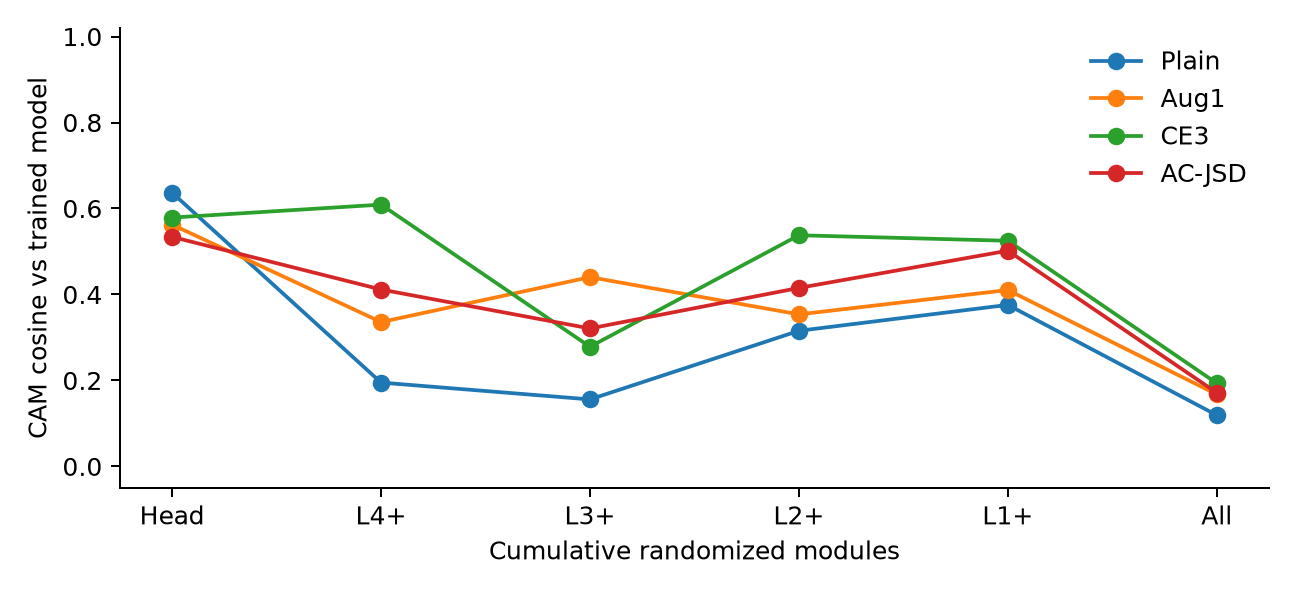

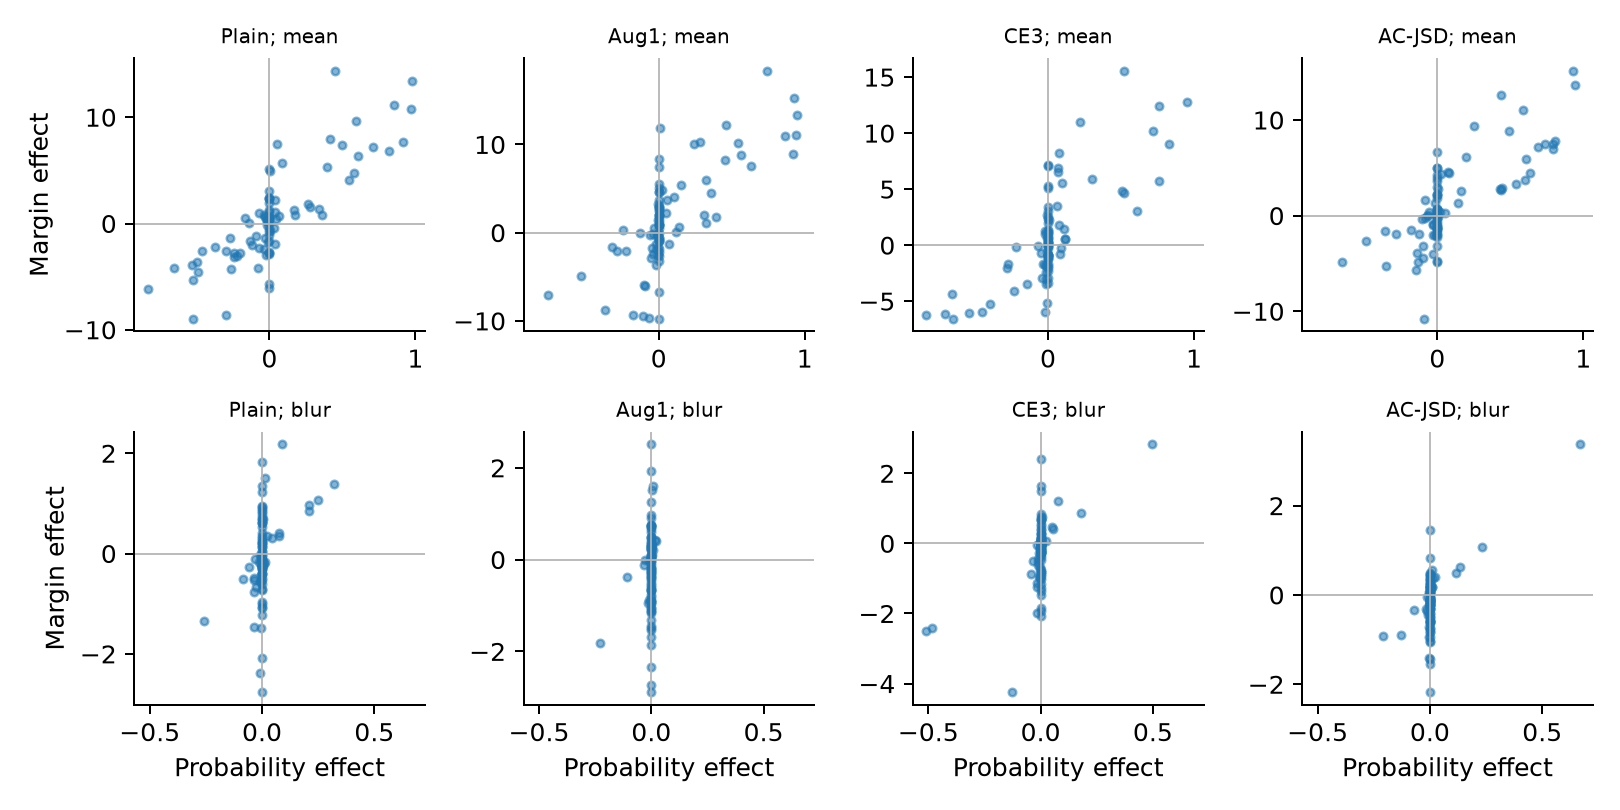

## 8. Final source selection and CheXpert evaluation

In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/ANALYSIS_PLAN.md
# MD6329 confirmatory analysis plan

Status: preregistered locally on 24 October 2026; no CheXpert outcome has been opened.

## Why this plan is needed

The RSNA diagnostic and audit cohorts have already influenced model development and interpretation. All RSNA results are therefore retrospective, hypothesis-generating evidence. They remain useful for describing failure modes, but they cannot confirm that AC-JSD generalizes better than plain training. Confirmation will use one fresh external cohort and one locked analysis.

## Fresh cohort and eligibility

The confirmatory cohort is the official CheXpert validation release. It contains radiologist-adjudicated labels and is independent of the RSNA collection. Only frontal AP/PA images are eligible because the source model was trained on frontal radiographs. The primary binary task is:

- positive: `Lung Opacity == 1`;
- negative: `No Finding == 1` and `Lung Opacity == 0`;
- exclude lateral images, uncertain or missing Lung Opacity labels, and rows satisfying neither definition.

No CheXpert image or label may be used for model selection, threshold fitting, preprocessing tuning, or method changes. Before inference, the script records cohort counts, patient identifiers parsed from paths, duplicate image hashes, label conflicts and exact CSV/image manifests. The run aborts if a patient appears in both classes or if a required file is missing. The official CheXpert split is patient-disjoint from its training split; this project does not use CheXpert training images.

## Frozen models and one primary endpoint

The two confirmatory models are B64 plain and the source-selected AC-JSD candidate. Their exact checkpoint SHA-256 values must be written into `confirmatory_config.json` before the outcome run.

The only primary endpoint is the paired difference in patient-clustered AUROC:

`AUROC(AC-JSD) - AUROC(B64 plain)`.

The alternative of interest is positive, but the report will show a two-sided paired patient-permutation p-value and a 95% patient-bootstrap interval. Confirmation requires a positive point estimate and a two-sided p-value below 0.05. No multiplicity correction is applied to this single primary endpoint.

Secondary classification endpoints are accuracy at the frozen threshold 0.5, balanced accuracy, average precision, Brier score, sensitivity and specificity. They are exploratory and their two-sided paired patient-permutation p-values are adjusted together by Holm's method. Localization is not a primary endpoint. If matching CheXlocalize masks are supplied before the lock, area-corrected CAM energy and pointing hit may be included as a separate secondary family; otherwise they are marked unavailable rather than inferred from image labels.

## Source-only development before the external lock

The original validation set is expanded before any confirmatory retraining. Exact image hashes are used to remove within-training duplicates and training images duplicated in the original validation set. From the remaining unique training images, 10% of each class is moved deterministically to validation by SHA-256 rank using seed 632901. The source test remains untouched.

Every new training run saves four prespecified checkpoints: best validation AUROC, best validation Brier, epoch 40, and last epoch. Validation Brier is the tie-break when AUROC values are equal to the precision recorded in the training log. This enables selection-rule sensitivity and an epoch-40 comparison without reconstructing missing historical weights.

AC-JSD's consistency coefficient is screened only on the expanded source validation set over `lambda in {1, 3, 12, 36}`. Lambda 12 is the inherited AugMix reference coefficient, not a value previously optimized for this dataset. The selected lambda minimizes validation Brier subject to validation AUROC being no more than 0.005 below the best candidate; exact ties choose the smaller lambda. Only the selected lambda may enter the fresh external evaluation.

The four confirmatory source runs are plain, Aug1, CE3 and selected-lambda AC-JSD, all with seed 632901 and the same expanded split. Their primary source selection checkpoint is best validation Brier. Sensitivity tables also report best validation AUROC, last epoch and epoch 40. These source comparisons do not substitute for fresh external confirmation.

## CutMix decision tree

CutMix is supporting exploration only. Candidate probabilities are screened on source validation. If the prespecified internal guardrail fails, the candidate is reported and the branch stops. A fallback probability may be explored and labeled exploratory, but it cannot replace the failed candidate or enter the main confirmatory comparison. Accordingly, historical `p=0.5` results remain exploratory and B64 plain versus AC-JSD remains the only fresh external primary comparison.

## One-shot execution and locking

The outcome command creates an exclusive lock before reading labels. It refuses to run if the lock, outcome directory or completed ledger entry already exists. A successful run writes predictions, metrics, resampling results, environment information, a complete manifest and one append-only JSONL ledger row containing UTC time, analysis-plan hash, configuration hash, code hash, dataset-manifest hash and checkpoint hashes. This project directory is not a Git repository, so the ledger records `git_commit: null` and `repository_state: repository_not_initialized`; the code-bundle hash is the version identifier.

After the one-shot run, no parameter, threshold, endpoint, inclusion rule or model may be changed in response to CheXpert results. Any later work requires a new dataset and a new dated plan.


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/confirmatory_config.json
{
  "status": "preregistered_not_run",
  "created_date": "2026-10-24",
  "seed": 632901,
  "fresh_dataset": "CheXpert official validation release",
  "eligibility": {
    "frontal_only": true,
    "positive": "Lung Opacity == 1",
    "negative": "No Finding == 1 and Lung Opacity == 0",
    "exclude_uncertain_missing_conflicting": true
  },
  "primary_endpoint": "paired patient-cluster AUROC difference: AC-JSD minus B64 plain",
  "threshold": 0.5,
  "secondary_endpoints": [
    "accuracy",
    "balanced_accuracy",
    "average_precision",
    "brier",
    "sensitivity",
    "specificity"
  ],
  "secondary_multiplicity": "Holm adjustment across the six classification endpoints",
  "bootstrap_draws": 5000,
  "permutation_draws": 10000,
  "lambda_candidates": [1, 3, 12, 36],
  "lambda_selection": "lowest expanded-validation Brier among candidates within 0.005 AUROC of the best; ties choose smaller lambda",
  "training_seed_count": 1,
  "checkpoint_policy": [
    "best_validation_brier",
    "best_validation_auroc",
    "epoch_40",
    "last_epoch"
  ],
  "models": {
    "plain": {
      "checkpoint": "TO_BE_LOCKED_AFTER_CONFIRMATORY_SOURCE_TRAINING",
      "sha256": "TO_BE_LOCKED"
    },
    "acjsd": {
      "checkpoint": "TO_BE_LOCKED_AFTER_LAMBDA_SELECTION",
      "sha256": "TO_BE_LOCKED"
    }
  },
  "external_run_count": 0
}


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/one_shot_external_audit.py
from __future__ import annotations

import argparse
import hashlib
import json
import os
import platform
import re
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    roc_auc_score,
)


def file_hash(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def canonical_hash(value: object) -> str:
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def load_project_model(checkpoint_path: Path, project_root: Path, device: torch.device) -> torch.nn.Module:
    source = project_root / "03_实验代码与数据" / "md6329_step15_b64_augmix"
    sys.path.insert(0, str(source))
    import b64_augmix as step15  # type: ignore

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model = step15.ResNet18().to(device)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def patient_from_path(path: str) -> str:
    match = re.search(r"patient(\d+)", path.replace("\\", "/"), flags=re.I)
    if not match:
        raise ValueError(f"Cannot parse patient ID from {path}")
    return f"patient{match.group(1)}"


def prepare_image(path: Path) -> torch.Tensor:
    image = np.asarray(Image.open(path).convert("L"), dtype=np.float32)
    lo, hi = float(image.min()), float(image.max())
    image = np.zeros_like(image) if hi <= lo else (image - lo) / (hi - lo)
    height, width = image.shape
    side = min(height, width)
    top, left = (height - side) // 2, (width - side) // 2
    image = image[top : top + side, left : left + side]
    resized = Image.fromarray(np.uint8(np.clip(image * 255.0, 0, 255))).resize((64, 64), Image.Resampling.BILINEAR)
    array = np.asarray(resized, dtype=np.float32) / 255.0
    return torch.from_numpy(array[None, :, :] * 2.0 - 1.0)


def build_cohort(csv_path: Path, image_root: Path) -> pd.DataFrame:
    frame = pd.read_csv(csv_path)
    required = {"Path", "Frontal/Lateral", "AP/PA", "No Finding", "Lung Opacity"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Missing CheXpert columns: {sorted(missing)}")
    frontal = frame[frame["Frontal/Lateral"].astype(str).str.lower().eq("frontal")].copy()
    positive = frontal["Lung Opacity"].eq(1)
    negative = frontal["No Finding"].eq(1) & frontal["Lung Opacity"].eq(0)
    cohort = frontal[positive | negative].copy()
    cohort["label"] = positive.loc[cohort.index].astype(int)
    cohort["patient_id"] = cohort["Path"].map(patient_from_path)
    cohort["image_path"] = cohort["Path"].map(lambda value: str((image_root / str(value)).resolve()))
    absent = [path for path in cohort["image_path"] if not Path(path).is_file()]
    if absent:
        raise FileNotFoundError(f"{len(absent)} eligible images are missing; first={absent[0]}")
    conflict = cohort.groupby("patient_id")["label"].nunique()
    if int((conflict > 1).sum()):
        raise ValueError("At least one patient contributes both positive and negative eligible images")
    if cohort["label"].nunique() != 2:
        raise ValueError("Eligible cohort must contain both classes")
    return cohort.reset_index(drop=True)


@torch.inference_mode()
def predict(model: torch.nn.Module, cohort: pd.DataFrame, device: torch.device) -> np.ndarray:
    scores: list[np.ndarray] = []
    for start in range(0, len(cohort), 64):
        images = torch.stack([prepare_image(Path(path)) for path in cohort.loc[start : start + 63, "image_path"]]).to(device)
        scores.append(torch.softmax(model(images), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(scores)


def metric_vector(labels: np.ndarray, scores: np.ndarray, threshold: float) -> dict[str, float]:
    predictions = (scores >= threshold).astype(int)
    negative = labels == 0
    positive = labels == 1
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "auroc": float(roc_auc_score(labels, scores)),
        "average_precision": float(average_precision_score(labels, scores)),
        "brier": float(brier_score_loss(labels, scores)),
        "sensitivity": float(predictions[positive].mean()),
        "specificity": float((predictions[negative] == 0).mean()),
    }


def patient_groups(patient_ids: np.ndarray) -> list[np.ndarray]:
    return [np.flatnonzero(patient_ids == patient) for patient in np.unique(patient_ids)]


def resampling(
    labels: np.ndarray,
    plain: np.ndarray,
    acjsd: np.ndarray,
    patient_ids: np.ndarray,
    threshold: float,
    bootstrap_draws: int,
    permutation_draws: int,
    seed: int,
) -> tuple[dict[str, list[float]], dict[str, float]]:
    groups = patient_groups(patient_ids)
    rng = np.random.default_rng(seed)
    metric_names = list(metric_vector(labels, plain, threshold))
    observed_plain = metric_vector(labels, plain, threshold)
    observed_acjsd = metric_vector(labels, acjsd, threshold)
    observed = {name: observed_acjsd[name] - observed_plain[name] for name in metric_names}
    bootstrap = {name: [] for name in metric_names}
    for _ in range(bootstrap_draws):
        sampled = rng.integers(0, len(groups), size=len(groups))
        index = np.concatenate([groups[i] for i in sampled])
        left = metric_vector(labels[index], plain[index], threshold)
        right = metric_vector(labels[index], acjsd[index], threshold)
        for name in metric_names:
            bootstrap[name].append(right[name] - left[name])

    extreme = {name: 0 for name in metric_names}
    for _ in range(permutation_draws):
        swap_groups = rng.random(len(groups)) < 0.5
        p = plain.copy()
        a = acjsd.copy()
        for group_index, swap in enumerate(swap_groups):
            if swap:
                idx = groups[group_index]
                p[idx], a[idx] = acjsd[idx], plain[idx]
        left = metric_vector(labels, p, threshold)
        right = metric_vector(labels, a, threshold)
        for name in metric_names:
            if abs(right[name] - left[name]) >= abs(observed[name]) - 1e-15:
                extreme[name] += 1
    p_values = {name: (extreme[name] + 1) / (permutation_draws + 1) for name in metric_names}
    return bootstrap, p_values


def holm(p_values: dict[str, float]) -> dict[str, float]:
    ordered = sorted(p_values, key=p_values.get)
    adjusted: dict[str, float] = {}
    running = 0.0
    count = len(ordered)
    for rank, name in enumerate(ordered):
        running = max(running, min(1.0, (count - rank) * p_values[name]))
        adjusted[name] = running
    return adjusted


def main() -> None:
    parser = argparse.ArgumentParser(description="Locked one-shot CheXpert confirmation")
    parser.add_argument("--config", type=Path, required=True)
    parser.add_argument("--plan", type=Path, required=True)
    parser.add_argument("--chexpert-csv", type=Path, required=True)
    parser.add_argument("--image-root", type=Path, required=True)
    parser.add_argument("--project-root", type=Path, required=True)
    parser.add_argument("--output-dir", type=Path, required=True)
    parser.add_argument("--ledger", type=Path, required=True)
    parser.add_argument("--execute", action="store_true")
    parser.add_argument("--acknowledge-locked-plan", default="")
    args = parser.parse_args()

    config = json.loads(args.config.read_text(encoding="utf-8"))
    checkpoints = {name: Path(record["checkpoint"]) for name, record in config["models"].items()}
    if not args.execute:
        print(json.dumps({"status": "preflight_only", "config_status": config["status"], "output_exists": args.output_dir.exists()}, indent=2))
        return
    if args.acknowledge_locked_plan != "RUN_ONCE_NO_RETUNING":
        raise RuntimeError("Execution requires --acknowledge-locked-plan RUN_ONCE_NO_RETUNING")
    if config["status"] != "locked_ready" or int(config["external_run_count"]) != 0:
        raise RuntimeError("Configuration is not locked_ready with external_run_count=0")
    for name, path in checkpoints.items():
        if not path.is_file() or file_hash(path) != config["models"][name]["sha256"]:
            raise RuntimeError(f"Checkpoint hash mismatch for {name}")
    if args.output_dir.exists() or args.ledger.exists():
        raise FileExistsError("Outcome directory or ledger already exists; one-shot execution refused")

    lock = args.output_dir.with_suffix(".LOCK")
    descriptor = os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    os.write(descriptor, datetime.now(timezone.utc).isoformat().encode())
    os.close(descriptor)
    args.output_dir.mkdir(parents=True)

    cohort = build_cohort(args.chexpert_csv, args.image_root)
    cohort["image_sha256"] = [file_hash(Path(path)) for path in cohort["image_path"]]
    dataset_manifest = {
        "csv_sha256": file_hash(args.chexpert_csv),
        "eligible_images": len(cohort),
        "patients": int(cohort["patient_id"].nunique()),
        "class_counts": {str(k): int(v) for k, v in cohort["label"].value_counts().sort_index().items()},
        "image_manifest_sha256": canonical_hash(cohort[["Path", "patient_id", "label", "image_sha256"]].to_dict("records")),
    }
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    scores = {}
    for name, checkpoint in checkpoints.items():
        scores[name] = predict(load_project_model(checkpoint, args.project_root, device), cohort, device)
    labels = cohort["label"].to_numpy(dtype=int)
    patients = cohort["patient_id"].to_numpy()
    metrics = {name: metric_vector(labels, values, float(config["threshold"])) for name, values in scores.items()}
    bootstrap, p_values = resampling(
        labels,
        scores["plain"],
        scores["acjsd"],
        patients,
        float(config["threshold"]),
        int(config["bootstrap_draws"]),
        int(config["permutation_draws"]),
        int(config["seed"]) + 21,
    )
    contrasts = {}
    for name, draws in bootstrap.items():
        difference = metrics["acjsd"][name] - metrics["plain"][name]
        contrasts[name] = {
            "difference_acjsd_minus_plain": difference,
            "ci95": [float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))],
            "permutation_p_two_sided": p_values[name],
        }
    secondary = {name: p_values[name] for name in config["secondary_endpoints"]}
    adjusted = holm(secondary)
    for name, value in adjusted.items():
        contrasts[name]["holm_adjusted_p"] = value

    predictions = cohort[["Path", "patient_id", "label", "image_sha256"]].copy()
    predictions["plain_score"] = scores["plain"]
    predictions["acjsd_score"] = scores["acjsd"]
    predictions.to_csv(args.output_dir / "predictions.csv", index=False)
    np.savez_compressed(args.output_dir / "resampling_distributions.npz", **{f"delta_{key}": np.asarray(value) for key, value in bootstrap.items()})
    results = {
        "status": "one_shot_complete_locked",
        "completed_utc": datetime.now(timezone.utc).isoformat(),
        "primary_endpoint": config["primary_endpoint"],
        "primary_result": contrasts["auroc"],
        "metrics": metrics,
        "contrasts": contrasts,
        "dataset_manifest": dataset_manifest,
        "interpretation_rule": "confirmation requires a positive AUROC point difference and two-sided p<0.05",
    }
    (args.output_dir / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")

    code_files = [Path(__file__), args.plan, args.config]
    ledger_row = {
        "completed_utc": results["completed_utc"],
        "status": results["status"],
        "analysis_plan_sha256": file_hash(args.plan),
        "config_sha256": file_hash(args.config),
        "code_bundle_sha256": canonical_hash({path.name: file_hash(path) for path in code_files}),
        "dataset_manifest_sha256": canonical_hash(dataset_manifest),
        "checkpoint_sha256": {name: file_hash(path) for name, path in checkpoints.items()},
        "git_commit": None,
        "repository_state": "repository_not_initialized",
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "device": str(device),
    }
    args.ledger.parent.mkdir(parents=True, exist_ok=True)
    with args.ledger.open("x", encoding="utf-8") as stream:
        stream.write(json.dumps(ledger_row, sort_keys=True) + "\n")
    (args.output_dir / "ledger_row.json").write_text(json.dumps(ledger_row, indent=2), encoding="utf-8")
    print(json.dumps(results, indent=2))


if __name__ == "__main__":
    main()


In [ ]:
# Safe preflight only: it does not read CheXpert outcomes or run inference.
from pathlib import Path
STEP21 = Path('/content/md6329_project/md6329_step21_confirmatory_protocol')
print('Plan:', STEP21 / 'ANALYSIS_PLAN.md')
print('Config status:', __import__('json').loads((STEP21 / 'confirmatory_config.json').read_text())['status'])
print('One-shot execution remains blocked until status=locked_ready and exact checkpoint hashes are filled.')


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/prepare_expanded_validation.py
from __future__ import annotations

import argparse
import hashlib
import json
import math
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

SEED = 632901


def digest(image: np.ndarray) -> str:
    return hashlib.sha256(np.ascontiguousarray(image).tobytes()).hexdigest()


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--dataset", type=Path, required=True)
    parser.add_argument("--output-dir", type=Path, required=True)
    args = parser.parse_args()
    args.output_dir.mkdir(parents=True, exist_ok=True)

    data = np.load(args.dataset)
    train_x = data["train_images"]
    train_y = data["train_labels"].reshape(-1).astype(int)
    val_x = data["val_images"]
    val_y = data["val_labels"].reshape(-1).astype(int)
    test_x = data["test_images"]

    val_hashes = {digest(x) for x in val_x}
    test_hashes = {digest(x) for x in test_x}
    seen: set[str] = set()
    eligible: list[tuple[int, int, str]] = []
    excluded_within_train = 0
    excluded_train_val = 0
    excluded_train_test = 0
    for index, (image, label) in enumerate(zip(train_x, train_y)):
        image_hash = digest(image)
        if image_hash in seen:
            excluded_within_train += 1
            continue
        seen.add(image_hash)
        if image_hash in val_hashes:
            excluded_train_val += 1
            continue
        if image_hash in test_hashes:
            excluded_train_test += 1
            continue
        eligible.append((index, int(label), image_hash))

    moved: list[int] = []
    retained: list[int] = []
    per_class: dict[str, dict[str, int]] = {}
    for label in sorted(set(train_y.tolist())):
        group = [row for row in eligible if row[1] == label]
        group.sort(key=lambda row: hashlib.sha256(f"{SEED}|{label}|{row[2]}".encode()).hexdigest())
        n_move = math.ceil(0.10 * len(group))
        moved.extend(row[0] for row in group[:n_move])
        retained.extend(row[0] for row in group[n_move:])
        per_class[str(label)] = {"eligible": len(group), "moved": n_move, "retained": len(group) - n_move}

    moved = sorted(moved)
    retained = sorted(retained)
    expanded_val_labels = np.concatenate([val_y, train_y[moved]])
    np.savez_compressed(
        args.output_dir / "expanded_validation_indices.npz",
        train_indices=np.asarray(retained, dtype=np.int64),
        original_val_indices=np.arange(len(val_y), dtype=np.int64),
        moved_train_indices=np.asarray(moved, dtype=np.int64),
    )
    manifest = {
        "status": "prepared_source_only_no_training",
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "dataset": str(args.dataset),
        "dataset_sha256": hashlib.sha256(args.dataset.read_bytes()).hexdigest(),
        "seed": SEED,
        "method": "exact-image SHA-256 deduplication followed by class-stratified deterministic 10% SHA-rank transfer",
        "excluded": {
            "within_train_duplicate_images": excluded_within_train,
            "train_images_duplicated_in_original_validation": excluded_train_val,
            "train_images_duplicated_in_test": excluded_train_test,
        },
        "original": {"train": len(train_y), "validation": len(val_y), "test": len(test_x)},
        "new": {
            "train": len(retained),
            "validation": len(expanded_val_labels),
            "moved_from_train": len(moved),
            "validation_class_counts": {str(k): int(v) for k, v in Counter(expanded_val_labels.tolist()).items()},
        },
        "per_class_train_split": per_class,
        "limitations": [
            "PneumoniaMNIST does not expose patient identifiers, so exact-image groups rather than patients define the deduplication unit.",
            "The official source test is unchanged and is not used for selection."
        ],
    }
    (args.output_dir / "expanded_validation_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(json.dumps(manifest, indent=2))


if __name__ == "__main__":
    main()


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/audit_historical_checkpoints.py
from __future__ import annotations

import argparse
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import torch


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--checkpoint-dir", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    args = parser.parse_args()

    records = []
    for name in ("plain", "aug1", "ce3", "augmix"):
        path = args.checkpoint_dir / f"{name}.pt"
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
        records.append({
            "model": "acjsd" if name == "augmix" else name,
            "path": str(path),
            "sha256": sha256(path),
            "stored_epoch": int(checkpoint["epoch"]),
            "stored_validation_auroc": float(checkpoint["validation_auroc"]),
            "available_selection_rule": "best_validation_auroc",
            "contains_optimizer_state": "optimizer_state" in checkpoint,
            "contains_validation_predictions": "validation_predictions" in checkpoint,
        })

    result = {
        "status": "historical_artifact_audit_complete",
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "records": records,
        "requested_checks": {
            "best_validation_auroc": "available",
            "last_epoch": "not recoverable from the archived four-model bundle",
            "best_validation_brier": "not recoverable because per-epoch weights and per-epoch probabilities were not archived",
            "epoch_40_alignment": "not recoverable for plain, Aug1 or CE3; AC-JSD epoch 40 is available",
        },
        "interpretation": "The historical four-way comparison cannot support a post-hoc selection-rule or epoch-40 sensitivity analysis. New confirmatory runs must save all four prespecified checkpoint types.",
    }
    args.output.parent.mkdir(parents=True, exist_ok=True)
    args.output.write_text(json.dumps(result, indent=2), encoding="utf-8")
    print(json.dumps(result, indent=2))


if __name__ == "__main__":
    main()


In [ ]:
# Recorded zero-training-cost audit outputs from the local project archive.
EXPANDED_VALIDATION = {
  "status": "prepared_source_only_no_training",
  "created_utc": "2026-10-24T05:26:51.544306+00:00",
  "dataset": "D:\\小白\\OneDrive\\桌面\\MD6329_深度学习期末项目\\03_实验代码与数据\\md6329_step1\\data\\pneumoniamnist_64.npz",
  "dataset_sha256": "97c5a52c65a74f6c5b77a3d8b3bb8aba58276d5a1aaa3b0340d079e54f8e9756",
  "seed": 632901,
  "method": "exact-image SHA-256 deduplication followed by class-stratified deterministic 10% SHA-rank transfer",
  "excluded": {
    "within_train_duplicate_images": 18,
    "train_images_duplicated_in_original_validation": 8,
    "train_images_duplicated_in_test": 0
  },
  "original": {
    "train": 4708,
    "validation": 524,
    "test": 624
  },
  "new": {
    "train": 4213,
    "validation": 993,
    "moved_from_train": 469,
    "validation_class_counts": {
      "1": 736,
      "0": 257
    }
  },
  "per_class_train_split": {
    "0": {
      "eligible": 1213,
      "moved": 122,
      "retained": 1091
    },
    "1": {
      "eligible": 3469,
      "moved": 347,
      "retained": 3122
    }
  },
  "limitations": [
    "PneumoniaMNIST does not expose patient identifiers, so exact-image groups rather than patients define the deduplication unit.",
    "The official source test is unchanged and is not used for selection."
  ]
}
HISTORICAL_CHECKPOINT_AUDIT = {
  "status": "historical_artifact_audit_complete",
  "created_utc": "2026-10-24T05:26:54.793431+00:00",
  "records": [
    {
      "model": "plain",
      "path": "D:\\小白\\OneDrive\\桌面\\MD6329_深度学习期末项目\\03_实验代码与数据\\md6329_step19_review_completion\\checkpoints\\plain.pt",
      "sha256": "c51030d6e2646dbd4b5b1b4132528590dc85a609f79eb61ed29c4acfd90fdd2f",
      "stored_epoch": 18,
      "stored_validation_auroc": 0.9979244025516519,
      "available_selection_rule": "best_validation_auroc",
      "contains_optimizer_state": false,
      "contains_validation_predictions": false
    },
    {
      "model": "aug1",
      "path": "D:\\小白\\OneDrive\\桌面\\MD6329_深度学习期末项目\\03_实验代码与数据\\md6329_step19_review_completion\\checkpoints\\aug1.pt",
      "sha256": "54c18d60e948b90153c6767046b03ffa4916d8be9603401bb9787fcd2a3b985c",
      "stored_epoch": 61,
      "stored_validation_auroc": 0.9971627154146434,
      "available_selection_rule": "best_validation_auroc",
      "contains_optimizer_state": false,
      "contains_validation_predictions": false
    },
    {
      "model": "ce3",
      "path": "D:\\小白\\OneDrive\\桌面\\MD6329_深度学习期末项目\\03_实验代码与数据\\md6329_step19_review_completion\\checkpoints\\ce3.pt",
      "sha256": "f3a7650136ac9d379dc0d3824c6871d038b632f4a82526b9080b00a01f36ef97",
      "stored_epoch": 36,
      "stored_validation_auroc": 0.9975435589831476,
      "available_selection_rule": "best_validation_auroc",
      "contains_optimizer_state": false,
      "contains_validation_predictions": false
    },
    {
      "model": "acjsd",
      "path": "D:\\小白\\OneDrive\\桌面\\MD6329_深度学习期末项目\\03_实验代码与数据\\md6329_step19_review_completion\\checkpoints\\augmix.pt",
      "sha256": "cf3a97804e8614b719367a8cdef4b23d9da5adbb2d48201a4dd6da238a4cf873",
      "stored_epoch": 40,
      "stored_validation_auroc": 0.9983242882985814,
      "available_selection_rule": "best_validation_auroc",
      "contains_optimizer_state": false,
      "contains_validation_predictions": false
    }
  ],
  "requested_checks": {
    "best_validation_auroc": "available",
    "last_epoch": "not recoverable from the archived four-model bundle",
    "best_validation_brier": "not recoverable because per-epoch weights and per-epoch probabilities were not archived",
    "epoch_40_alignment": "not recoverable for plain, Aug1 or CE3; AC-JSD epoch 40 is available"
  },
  "interpretation": "The historical four-way comparison cannot support a post-hoc selection-rule or epoch-40 sensitivity analysis. New confirmatory runs must save all four prespecified checkpoint types."
}
print('Expanded validation:', EXPANDED_VALIDATION['new'])
print('Recoverable historical rule:', HISTORICAL_CHECKPOINT_AUDIT['requested_checks']['best_validation_auroc'])
print('Best-Brier sensitivity:', HISTORICAL_CHECKPOINT_AUDIT['requested_checks']['best_validation_brier'])


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/confirmatory_training.py
from __future__ import annotations

import argparse
import csv
import hashlib
import json
import sys
import time
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 632901


@dataclass(frozen=True)
class Config:
    mode: str
    jsd_weight: float
    epochs: int = 100
    batch_size: int = 128
    learning_rate: float = 0.001
    milestones: tuple[int, int] = (50, 75)
    gamma: float = 0.1
    seed: int = SEED


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def save_csv(path: Path, rows: list[dict]) -> None:
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def load_split(dataset: Path, indices: Path) -> dict[str, np.ndarray]:
    data = np.load(dataset)
    split = np.load(indices)
    moved = split["moved_train_indices"]
    return {
        "train_images": data["train_images"][split["train_indices"]],
        "train_labels": data["train_labels"][split["train_indices"]].reshape(-1),
        "val_images": np.concatenate([data["val_images"], data["train_images"][moved]], axis=0),
        "val_labels": np.concatenate([data["val_labels"].reshape(-1), data["train_labels"][moved].reshape(-1)], axis=0),
    }


def training_logits(model, x, y, mode: str, generator, step15, jsd_weight: float):
    if mode == "plain":
        logits = model(x)
        return logits, F.cross_entropy(logits, y), logits.new_tensor(0.0)
    if mode == "aug1":
        logits = model(step15.acquisition_view(x, generator))
        return logits, F.cross_entropy(logits, y), logits.new_tensor(0.0)
    view1 = step15.acquisition_view(x, generator)
    view2 = step15.acquisition_view(x, generator)
    outputs = [model(x), model(view1), model(view2)]
    ce = sum(F.cross_entropy(output, y) for output in outputs) / 3.0
    jsd = step15.jsd_loss(outputs)
    if mode == "ce3":
        return outputs[0], ce, jsd.detach()
    if mode == "acjsd":
        return outputs[0], ce + jsd_weight * jsd, jsd
    raise ValueError(mode)


def save_checkpoint(path: Path, model, epoch: int, config: Config, validation: dict) -> None:
    torch.save({
        "model_state": model.state_dict(),
        "epoch": epoch,
        "validation": validation,
        "config": asdict(config),
    }, path)


def run(dataset: Path, indices: Path, project_root: Path, output: Path, config: Config) -> dict:
    source = project_root / "03_实验代码与数据" / "md6329_step15_b64_augmix"
    sys.path.insert(0, str(source))
    import b64_augmix as step15  # type: ignore

    output.mkdir(parents=True, exist_ok=False)
    protocol = {
        "status": "source_only_protocol_frozen_before_training",
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "config": asdict(config),
        "dataset_sha256": sha256(dataset),
        "split_indices_sha256": sha256(indices),
        "checkpoint_policy": ["best_validation_brier", "best_validation_auroc", "epoch_40", "last_epoch"],
        "external_data_loaded": False,
    }
    (output / "protocol_before_training.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
    arrays = load_split(dataset, indices)
    step15.seed_all(config.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = step15.ResNet18().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, list(config.milestones), gamma=config.gamma)
    shuffle_generator = torch.Generator().manual_seed(config.seed)
    augmentation_generator = torch.Generator().manual_seed(config.seed + 1)
    train_loader = DataLoader(
        TensorDataset(step15.normalized_tensor(arrays["train_images"]), torch.from_numpy(arrays["train_labels"]).long()),
        batch_size=config.batch_size,
        shuffle=True,
        generator=shuffle_generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    val_loader = step15.make_loader(arrays["val_images"], arrays["val_labels"], config.batch_size, False, config.seed)
    best_auc = -np.inf
    best_brier = np.inf
    best_auc_epoch = None
    best_brier_epoch = None
    rows: list[dict] = []
    started = time.time()
    for epoch in range(1, config.epochs + 1):
        model.train()
        count = correct = 0
        total_loss = total_jsd = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits, loss, jsd = training_logits(model, x, y, config.mode, augmentation_generator, step15, config.jsd_weight)
            loss.backward()
            optimizer.step()
            count += len(y)
            correct += int((logits.argmax(1) == y).sum())
            total_loss += float(loss.detach()) * len(y)
            total_jsd += float(jsd.detach()) * len(y)
        _, val_scores, val_labels = step15.predict(model, val_loader, device)
        val = step15.metrics(val_labels, val_scores)
        row = {
            "epoch": epoch,
            "learning_rate": float(optimizer.param_groups[0]["lr"]),
            "train_loss": total_loss / count,
            "train_jsd": total_jsd / count,
            "train_accuracy": correct / count,
            "val_accuracy": val["accuracy"],
            "val_balanced_accuracy": val["balanced_accuracy"],
            "val_auroc": val["auroc"],
            "val_brier": val["brier"],
            "elapsed_seconds": time.time() - started,
        }
        rows.append(row)
        if val["auroc"] > best_auc:
            best_auc = float(val["auroc"])
            best_auc_epoch = epoch
            save_checkpoint(output / "best_validation_auroc.pt", model, epoch, config, val)
        if val["brier"] < best_brier:
            best_brier = float(val["brier"])
            best_brier_epoch = epoch
            save_checkpoint(output / "best_validation_brier.pt", model, epoch, config, val)
        if epoch == 40:
            save_checkpoint(output / "epoch_40.pt", model, epoch, config, val)
        scheduler.step()
        save_csv(output / "learning_curve.csv", rows)
        if epoch == 1 or epoch % 10 == 0:
            print(f"{config.mode} lambda={config.jsd_weight:g} epoch={epoch:03d} val_auc={val['auroc']:.6f} val_brier={val['brier']:.6f}", flush=True)
    save_checkpoint(output / "last_epoch.pt", model, config.epochs, config, val)
    summary = {
        "status": "source_training_complete_external_unopened",
        "config": asdict(config),
        "best_validation_auroc": best_auc,
        "best_validation_auroc_epoch": best_auc_epoch,
        "best_validation_brier": best_brier,
        "best_validation_brier_epoch": best_brier_epoch,
        "checkpoint_sha256": {path.stem: sha256(path) for path in output.glob("*.pt")},
        "training_seconds": time.time() - started,
    }
    (output / "training_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return summary


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--dataset", type=Path, required=True)
    parser.add_argument("--indices", type=Path, required=True)
    parser.add_argument("--project-root", type=Path, required=True)
    parser.add_argument("--output-root", type=Path, required=True)
    parser.add_argument("--mode", choices=["plain", "aug1", "ce3", "acjsd"], required=True)
    parser.add_argument("--jsd-weight", type=float, default=12.0)
    args = parser.parse_args()
    if args.mode != "acjsd" and args.jsd_weight != 12.0:
        raise ValueError("JSD weight only applies to acjsd")
    tag = f"{args.mode}_lambda_{args.jsd_weight:g}" if args.mode == "acjsd" else args.mode
    run(args.dataset, args.indices, args.project_root, args.output_root / tag, Config(args.mode, args.jsd_weight))


if __name__ == "__main__":
    main()


In [ ]:
# Optional complete source-only training sequence. Leave False to display saved results.
RUN_FINAL_SOURCE_TRAINING = False
if RUN_FINAL_SOURCE_TRAINING:
    import subprocess
    dataset_candidates = [
        PROJECT_ROOT / 'data/pneumoniamnist_64.npz',
        PROJECT_ROOT / 'md6329_step1/data/pneumoniamnist_64.npz',
    ]
    dataset64 = next(path for path in dataset_candidates if path.exists())
    indices = STEP21 / 'results/expanded_validation_indices.npz'
    jobs = [('plain', 0), ('aug1', 0), ('ce3', 0), ('acjsd', 1), ('acjsd', 3), ('acjsd', 12), ('acjsd', 36)]
    for mode, weight in jobs:
        command = [sys.executable, str(STEP21/'confirmatory_training.py'), '--dataset', str(dataset64),
                   '--indices', str(indices), '--project-root', str(PROJECT_ROOT),
                   '--output-root', str(STEP21/'confirmatory_runs'), '--mode', mode]
        if mode == 'acjsd':
            command += ['--jsd-weight', str(weight)]
        subprocess.run(command, check=True)

In [ ]:
# GPU commands to run only after reviewing the frozen plan. They use source train/validation only.
LAMBDA_COMMANDS = [
    f"python {STEP21/'confirmatory_training.py'} --dataset /content/md6329_project/data/pneumoniamnist_64.npz --indices {STEP21/'results/expanded_validation_indices.npz'} --project-root /content/md6329_project --output-root {STEP21/'confirmatory_runs'} --mode acjsd --jsd-weight {weight}"
    for weight in (1, 3, 12, 36)
]
print('\n'.join(LAMBDA_COMMANDS))


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/CUTMIX_DECISION_TREE.md
# CutMix source-only decision tree

1. Freeze candidate probabilities and the internal guardrail before training.
2. Screen candidate probabilities using source validation only.
3. Evaluate the selected candidate once on the internal test.
4. If the guardrail passes, it may be reported as a prespecified supporting comparison.
5. If the guardrail fails, report the failure and stop the main branch.
6. Any alternative probability tested after the failure is exploratory. It cannot replace the failed setting, cannot enter the main comparison, and cannot influence the fresh external primary endpoint.

Historical application: `p=1.0` was the selected source candidate and failed its internal accuracy guardrail. The subsequent `p=0.5` run is therefore retained as exploratory evidence only.


In [ ]:
%%writefile /content/md6329_project/md6329_step21_confirmatory_protocol/plot_four_model_curves.py
from __future__ import annotations

import argparse
import ast
import csv
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt


def read_csv(path: Path) -> list[dict]:
    with path.open(encoding="utf-8-sig") as stream:
        return [{key: float(value) for key, value in row.items()} for row in csv.DictReader(stream)]


def embedded_step18(notebook: Path) -> dict:
    value = None
    data = json.loads(notebook.read_text(encoding="utf-8"))
    for cell in data["cells"]:
        source = "".join(cell.get("source", []))
        if "STEP18_RECORDED" not in source or cell.get("cell_type") != "code":
            continue
        tree = ast.parse(source)
        for node in tree.body:
            if isinstance(node, ast.Assign) and any(isinstance(target, ast.Name) and target.id == "STEP18_RECORDED" for target in node.targets):
                try:
                    value = ast.literal_eval(node.value)
                except (ValueError, TypeError):
                    if isinstance(node.value, ast.Call) and node.value.args:
                        value = json.loads(ast.literal_eval(node.value.args[0]))
                    else:
                        raise
    if value is None:
        raise RuntimeError("STEP18_RECORDED was not found")
    return value


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--notebook", type=Path, required=True)
    parser.add_argument("--plain-curve", type=Path, required=True)
    parser.add_argument("--acjsd-curve", type=Path, required=True)
    parser.add_argument("--output-prefix", type=Path, required=True)
    args = parser.parse_args()
    recorded = embedded_step18(args.notebook)
    curves = {
        "Plain": read_csv(args.plain_curve),
        "Aug1": recorded["models"]["b64_aug1"]["curve"],
        "CE3": recorded["models"]["b64_ce3_jsd0_full"]["curve"],
        "AC-JSD": read_csv(args.acjsd_curve),
    }
    selected = {"Plain": 18, "Aug1": 61, "CE3": 36, "AC-JSD": 40}
    colors = {"Plain": "#666666", "Aug1": "#b17b28", "CE3": "#925a80", "AC-JSD": "#24738b"}
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), layout="constrained")
    for name, rows in curves.items():
        epochs = [int(row["epoch"]) for row in rows]
        axes[0].plot(epochs, [float(row["train_loss"]) for row in rows], label=name, color=colors[name], linewidth=1.2)
        axes[1].plot(epochs, [float(row["val_auroc"]) for row in rows], label=name, color=colors[name], linewidth=1.2)
        point = next(row for row in rows if int(row["epoch"]) == selected[name])
        axes[1].scatter(selected[name], float(point["val_auroc"]), color=colors[name], s=24, zorder=3)
    axes[0].set_yscale("log")
    axes[0].set_ylabel("Training objective (log scale)")
    axes[1].set_ylabel("Clean validation AUROC")
    axes[1].set_ylim(0.975, 1.001)
    for axis in axes:
        axis.set_xlabel("Epoch")
        axis.grid(alpha=0.2)
        axis.legend(frameon=False, fontsize=7, ncol=2)
    args.output_prefix.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(args.output_prefix.with_suffix(".pdf"))
    fig.savefig(args.output_prefix.with_suffix(".png"), dpi=180)
    plt.close(fig)
    manifest = {
        "curves": {name: len(rows) for name, rows in curves.items()},
        "selected_epochs": selected,
        "note": "AC-JSD's archived curve ends at its selected epoch 40; no later AC-JSD rows were available locally.",
    }
    args.output_prefix.with_suffix(".json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(json.dumps(manifest, indent=2))


if __name__ == "__main__":
    main()


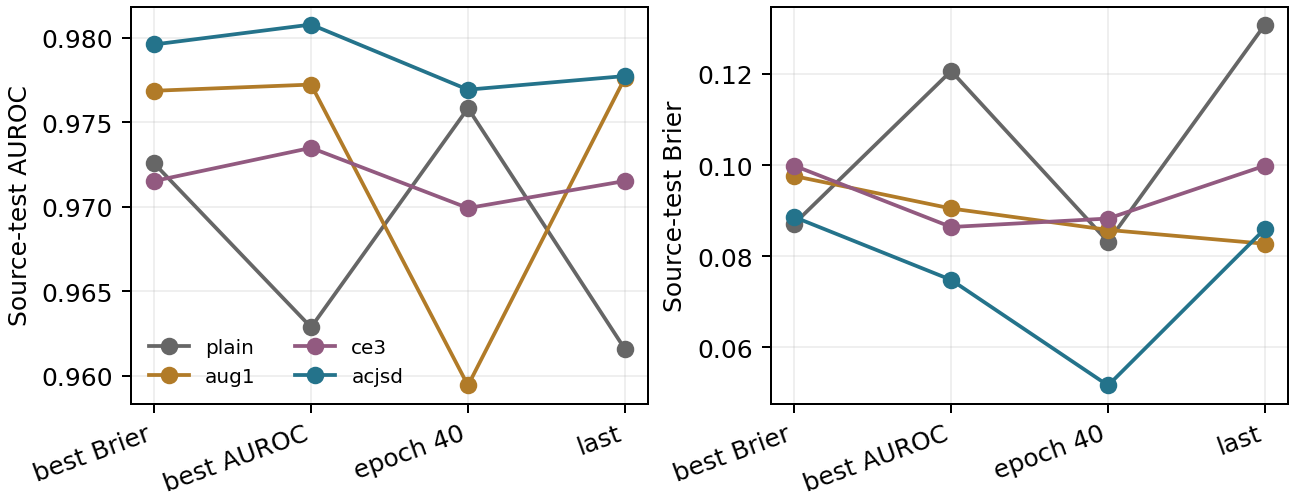

## 9. Final recorded results

In [ ]:
# Display final source-selection results.
from pathlib import Path
import pandas as pd

local_results = Path(r"/content/md6329_project/03_实验代码与数据/md6329_step21_confirmatory_protocol/results/confirmatory_source")
colab_results = Path('/content/md6329_project/md6329_step21_confirmatory_protocol/results/confirmatory_source')
SOURCE_RESULTS = local_results if local_results.exists() else colab_results
display(pd.read_csv(SOURCE_RESULTS / "lambda_sweep.csv"))
display(pd.read_csv(SOURCE_RESULTS / "checkpoint_sensitivity.csv"))

In [ ]:
# Display the completed CheXpert evaluation.
chexpert_result = PROJECT_ROOT / 'md6329_step21_confirmatory_protocol/results/chexpert_one_shot/results.json'
if chexpert_result.exists():
    result = json.loads(chexpert_result.read_text(encoding='utf-8'))
    display(pd.DataFrame([
        {'model': name, **metrics}
        for name, metrics in result['model_metrics'].items()
    ]))
    display(pd.DataFrame(result['contrasts']))
else:
    print('CheXpert result file is not mounted in this session.')